# Exploratory comparison between semantic embeddings and TF-IDF
## Alignment profiles with the Smart City dimensions — Municipality of Águeda

**Author:** Fatima Zahra Rbaibi

This notebook implements an exploratory and reproducible analysis of the alignment between the metadata of the municipal datasets and six Smart City dimensions defined *a priori* by anchor texts. It compares a semantic representation based on *sentence embeddings* with a lexical TF-IDF representation, assesses the sensitivity to four versions of the anchors and explores the structure of the corpus through clustering. Each dataset is described by six scores; the dimension with the highest score is a summary, not an exclusive or validated class.

> **Scope of the conclusions.** In the absence of a reference set annotated by human experts (gold standard), the metrics in this notebook assess coverage, separation of the scores, agreement between methods and stability across versions. They do not, by themselves, measure accuracy, substantive validity or the probability of a classification being correct. The terms “confidence” and “robustness” are used only as internal and relative descriptors.

### Structure of the notebook and correspondence with the dissertation

| Notebook section | Content | Dissertation |
|---|---|---|
| 1. Configuration (1.1 spaCy; 1.2 recording the environment) | Libraries, paths, parameters, versions used | 3.1, 3.6 |
| 2. Helper functions | Text pipelines, classification, relative delta bands | 3.3, 3.4 |
| 3. Validation of the input files | Existence and structure of the files | 3.3 |
| 4. Pre-processing (4.2 anchors) | Texts of the datasets and of the four anchor versions | 3.2, 3.3.1 |
| 5. Embedding model (5.1–5.3) | Loading the model; diagnostic of the token limit; full-text encoding by segmentation; validations | 3.3.2 |
| 6. Classification | Scores, top-1, top-2, delta, bands, agreement between methods | 3.4, 3.4.1 · 4.2, 4.3 (RQ1, RQ2) |
| 7.1–7.9 Analysis by version | Results by version, stability across versions, distributions, delta bands, agreement matrices, score profiles, entropy, extreme cases, TF-IDF without classification | 3.4.2, 3.4.3 · 4.3, 4.4, 4.5 (RQ2–RQ4) |
| 7.10 Post-argmax rule (four versions) | States, automatic triage for future review, sensitivity to the parameters, candidate dimensions and global review | 3.5.1 · 4.5 (RQ4) |
| 8. Instability across versions | Datasets that change dimension | 3.4.2 · 4.4 (RQ3) |
| 9. Semantic clustering | Most similar pairs, choice of k, clusters, terms, PCA | 3.5.2 · 4.6 (RQ5) |
| 10. Clusters × dimensions (four versions) | Contingency tables and modal dimensions | 3.5.2 · 4.6 (RQ5) |
| 11. Export (11.1 impact of the truncation correction; 11.5 variation relative to the 512-token limit) | Results Excel file; comparison with the two alternative configurations | 3.6 · 4.4 · Appendix B |
| 12–13. Conclusion and references | — | — |

All the analyses that depend on the anchors are carried out for the four versions (original, 50, 100 and 150 words). The comparison between Águeda and Porto (RQ6, Section 4.7) is based on the files exported by the notebooks of the two municipalities (`outputs/porto/03_chunksAllText/` and `outputs/agueda/03_chunksAllText/`), which have the same structure.

> **Note on the encoding of the texts.** All embeddings (datasets and anchors of the four versions) are computed with a single full-text function: sentence-based segmentation within the model limit, average weighted by the number of content tokens and L2 normalisation (Sections 5.2–5.3). The results obtained previously with direct encoding, in which long texts were truncated, are kept in `outputs/agueda/01_pre_chunking/` and are compared with the current ones in Section 11.1. The results of the exploratory test with the 512-token limit (notebook 02, in `outputs/agueda/02_test_512/`) are compared with the current ones in Section 11.5. For this reason, this notebook runs after notebooks 01 and 02. The analysis texts in this notebook refer to the final run.

> **Terminology.** The matrices cross the results of two methods without reference labels. The review lists are produced automatically as candidates for future work; no human validation was carried out in this dissertation.


## 1. Imports, general configuration and thread control

This section loads the libraries and defines the global parameters. On Windows with Conda/Miniforge environments, NumPy/scikit-learn and PyTorch may load different OpenMP runtimes. To avoid the KMeans memory leak warning with MKL and reduce the risk of conflict, the notebook limits the numerical libraries to one thread **before any scientific import**.

> After changing or updating this cell, it is mandatory to run **Kernel → Restart & Run All**. Running it in a kernel where NumPy, scikit-learn or PyTorch have already been imported does not unload the OpenMP libraries loaded previously.

In [1]:
# ── Imports and parallelism control ─────────────────────────────────────────
import os

# Mitigation for Windows + MKL/OpenMP. These variables must be set
# BEFORE importing NumPy, scikit-learn, PyTorch or Sentence Transformers.
# They avoid the known KMeans memory problem with MKL and reduce the risk
# of conflict when libiomp and libomp coexist in the same Conda environment.
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "1"

import re
import unicodedata
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    cohen_kappa_score,
    confusion_matrix,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.stats import entropy as scipy_entropy

from sentence_transformers import SentenceTransformer

import spacy

warnings.filterwarnings("default")
# The warning about duplicate OpenMP runtimes is environmental. The filter is limited
# to the RuntimeWarning issued by threadpoolctl; all other warnings are kept.
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module=r"threadpoolctl(?:\..*)?",
)
warnings.filterwarnings(
    "ignore",
    message=r".*KMeans is known to have a memory leak on Windows with MKL.*",
    category=UserWarning,
    module=r"sklearn\.cluster\._kmeans",
)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 200)

print("Libraries imported successfully.")

C:\Users\paulo\.conda\envs\dissertacao_fr\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully.


> **Single editing point.** Change only this cell to adapt the notebook to new data or to a new municipality.

In [2]:
# ── General settings ─────────────────────────────────────────────────────────

# Reprodutibilidade 
SEED = 42
np.random.seed(SEED)

# ── Paths ───────────────────────────────────────────────────────────────────
PROJECT_DIR = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "environment.yaml").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open the project from the repository root or from the notebooks/agueda/ folder.")
import sys
sys.path.insert(0, str(PROJECT_DIR))
from scripts.reproducibility import save_manifest, validate_comparison
# Looks first for a data/ subfolder; if the files have been placed
# next to the notebook, the current working folder is used.
DATA_DIR = PROJECT_DIR / "data"
if not DATA_DIR.exists():
    DATA_DIR = PROJECT_DIR

def resolve_input(filename: str) -> Path:
    """Resolves the canonical name or the variant with the suffix (1)."""
    canonical = DATA_DIR / filename
    duplicate = DATA_DIR / f"{Path(filename).stem}(1){Path(filename).suffix}"
    if canonical.exists():
        return canonical
    if duplicate.exists():
        return duplicate
    return canonical  # the validation cell will show the missing path

OUTPUT_DIR  = PROJECT_DIR / "outputs/agueda/03_chunksAllText"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Input files ──────────────────────────────────────────────────────────────
DATASETS_CSV = resolve_input("agueda_tabela_mae_datasets.csv")

ANCHOR_FILES = {
    "original"    : resolve_input("texto_base.csv"),
    "50_words" : resolve_input("ancoras_v1_50_palavras.csv"),
    "100_words": resolve_input("ancoras_v2_100_palavras.csv"),
    "150_words": resolve_input("ancoras_v3_150_palavras.csv"),
}

# ── Outputs ───────────────────────────────────────────────────────────────────
OUT_EXCEL = OUTPUT_DIR / "results_smart_cities_agueda.xlsx"

# Previous results (direct encoding, with truncation), kept in order to
# quantify the impact of the correction (Section 11.1). They are NOT final results.
OUTPUT_DIR_BASELINE = PROJECT_DIR / "outputs/agueda/01_pre_chunking"
EXCEL_BASELINE = OUTPUT_DIR_BASELINE / OUT_EXCEL.name

# ── Embedding model ───────────────────────────────────────────────────────────
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODEL_REVISION = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"
MODEL_DEVICE = "cpu"

# ── Full-text encoding (truncation correction; Section 5.2) ──────────────────
# The model reads at most model.max_seq_length tokens per sequence. ALL
# texts (datasets and anchors of the four versions) go through the same function:
# sentence-based segmentation into chunks within the tokenizer limit, embedding of
# each chunk, average weighted by the number of content tokens and L2 normalisation.
EMBEDDING_ENCODING_MODE = "sentence_aware_token_limited_weighted_v1"
CHUNK_OVERLAP = 0
CHUNK_WEIGHTING = "content_token_count"
FINAL_NORMALIZATION = "L2"

# ── spaCy model for lemmatisation (TF-IDF pipeline) ───────────────────────────
# Change here if you have another model installed (e.g. "pt_core_news_md", "pt_core_news_lg").
# Larger models (md/lg) have richer word vectors and slightly better
# morphological disambiguation, but lemmatisation itself — which is what
# matters for TF-IDF — is similar across the three sizes.
SPACY_MODEL_NAME = "pt_core_news_sm"

# ── Dimension labels ─────────────────────────────────────────────────────────
# The anchor files name the six dimensions in Portuguese; the names are mapped to
# English labels when the anchors are loaded (Section 3). DIMENSION_SORT_ORDER keeps
# the column order of the original analysis (alphabetical order of the Portuguese
# names), so that the results, including any ties in the argmax, are identical.
DIM_EN = {
    "Governança Inteligente"       : "Smart Governance",
    "Sociedade Inteligente"        : "Smart Society",
    "Mobilidade Inteligente"       : "Smart Mobility",
    "Ambiente Inteligente"         : "Smart Environment",
    "Qualidade De Vida Inteligente": "Smart Quality of Life",
    "Economia Inteligente"         : "Smart Economy",
}
DIMENSION_SORT_ORDER = ["Smart Environment", "Smart Economy", "Smart Governance",
                        "Smart Mobility", "Smart Quality of Life", "Smart Society"]

def dim_sort_key(dim):
    """Position of a dimension label in DIMENSION_SORT_ORDER."""
    return DIMENSION_SORT_ORDER.index(dim) if dim in DIMENSION_SORT_ORDER else len(DIMENSION_SORT_ORDER)

def dim_col_key(col):
    """Sort key for score columns such as 'score_emb_Smart Economy'."""
    pos = next((i for i, d in enumerate(DIMENSION_SORT_ORDER) if col.endswith(d)), len(DIMENSION_SORT_ORDER))
    return (pos, col)

# ── Relative delta bands (percentiles; they are not probabilities) ────────────
# Computed automatically after classification — see cell 10 (confidence_label)
# Percentile 66 → "high" threshold; Percentile 33 → "medium" threshold
DELTA_PERCENTILE_HIGH  = 66   # delta percentile for the "high" confidence level
DELTA_PERCENTILE_MEDIUM = 33   # delta percentile for the "medium" confidence level

# ── TF-IDF parameters for classification ─────────────────────────────────────
TFIDF_VECTORIZER_PARAMS = {
    "max_features" : 5000,
    "min_df"       : 1,
    "max_df"       : 0.90,
    "ngram_range"  : (1, 2),
    "sublinear_tf" : True,
    "token_pattern": r"(?u)\b[a-zA-ZÀ-ÿ]{3,}\b",
}

# ── TF-IDF parameters for interpreting the clusters ──────────────────────────
TFIDF_CLUSTER_PARAMS = {
    "max_features" : 1000,
    "min_df"       : 1,
    "max_df"       : 0.80,
    "ngram_range"  : (1, 2),
    "sublinear_tf" : True,
    "token_pattern": r"(?u)\b[a-zA-ZÀ-ÿ]{3,}\b",
}

# ── Clustering ────────────────────────────────────────────────────────────────
MAX_K_CLUSTERS = 10          # maximum value to explore
K_CLUSTERS     = None        # None → automatic choice by silhouette

# ── Anchor versions ──────────────────────────────────────────────────────────
# All analyses that depend on the anchors (classification, score profiles,
# post-argmax rule and cluster-dimension relationship) are carried out for the FOUR versions
# defined in ANCHOR_FILES. There is no reference version: the versions are
# alternative operationalisations used to assess the sensitivity of the
# results, not candidates for a "better" version.

# ── Technical checks (environment and truncation) ────────────────────────────
VERIF_DIR = OUTPUT_DIR / "checks"
VERIF_DIR.mkdir(parents=True, exist_ok=True)
SUFFIX = OUT_EXCEL.stem.replace("results_smart_cities_", "")   # "agueda" / "porto"

# ── Exploratory post-argmax rule ─────────────────────────────────────────────
MIN_WORDS = 8
PERCENTILE_WEAK_SCORE = 5
PERCENTILE_CLOSE_MARGIN = 25
PERCENTILE_DIFFUSE_RANGE = 25

# ── Plot style (uniform across all plots) ────────────────────────────────────
# Sober palette, checked for readability by people with colour blindness (fixed order:
# the colour follows the category, never the position). The methods always have the same colour;
# the anchor versions use grey (original) + a ramp of blues (50→150).
from cycler import cycler
import textwrap

EMB_COLOUR      = "#2F6DB0"   # Embeddings (blue)
TFIDF_COLOUR    = "#2A9A7E"   # TF-IDF (blue-green)
REF_COLOUR      = "#3D3D3D"   # reference lines: thresholds, percentiles, means
NEUTRAL_COLOUR   = "#8A8F98"   # grey: neutral categories / unclassified
HIGHLIGHT_COLOUR = "#C0714F"   # soft terracotta: flagged cases / outlines
CMAP_EMB, CMAP_TFIDF = "Blues", "Greens"
CATEGORICAL_PALETTE = ["#2F6DB0", "#C0714F", "#2A9A7E", "#7C5CB8", "#C2577F", "#7D8A3C"]
VERSION_COLOURS = {
    "original"    : "#8A8F98",
    "50_words" : "#86B6EF",
    "100_words": "#3987E5",
    "150_words": "#184F95",
}
CONFIDENCE_COLOURS = {"Null": "#C9CCD1", "Low": "#86B6EF", "Medium": "#3987E5", "High": "#184F95"}
MARKERS = ["o", "s", "^", "D", "v", "P"]
LABEL_WIDTH = 14   # maximum number of characters per line in the horizontal-axis labels

def format_x_labels(ax, width_chars=LABEL_WIDTH):
    """Categorical labels of the horizontal axis set horizontally (0°), centred;
    long labels are split over several lines so that they do not overlap."""
    tick_labels = [textwrap.fill(t.get_text(), width_chars) for t in ax.get_xticklabels()]
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(tick_labels, rotation=0, ha="center")

def horizontal_y_labels(ax):
    for tick_label in ax.get_yticklabels():
        tick_label.set_rotation(0)

plt.rcParams.update({
    "axes.prop_cycle"   : cycler(color=CATEGORICAL_PALETTE),
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "axes.titleweight"  : "bold",
    "axes.edgecolor"    : "#6B6B6B",
    "grid.color"        : "#D9D9D9",
    "legend.frameon"    : False,
})

print("Configuration loaded.")
print(f"  Model  : {MODEL_NAME}")
print(f"  Encoding: {EMBEDDING_ENCODING_MODE} (overlap={CHUNK_OVERLAP}, weights={CHUNK_WEIGHTING}, {FINAL_NORMALIZATION})")
print(f"  Dataset: {DATASETS_CSV}")
print(f"  Anchors: {list(ANCHOR_FILES.keys())}")
print(f"  Outputs: {OUTPUT_DIR}")

Configuration loaded.
  Model  : sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
  Encoding: sentence_aware_token_limited_weighted_v1 (overlap=0, weights=content_token_count, L2)
  Dataset: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\agueda_tabela_mae_datasets.csv
  Anchors: ['original', '50_words', '100_words', '150_words']
  Outputs: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText


### 1.1 Loading the spaCy model (lemmatisation for TF-IDF)

The TF-IDF pre-processing pipeline includes **lemmatisation** with spaCy, as a complement
to (not a replacement for) the domain stopwords defined in section 2.2.

**Why lemmatisation and not just stopwords?** The manual stopwords solve the problem of
generic terms with no discriminative value (articles, prepositions, technical terms such as "csv",
"shapefile", etc.), but they do not solve a different problem: morphological variation of the same
word. Without lemmatisation, `"transportes"`, `"transporte"` and `"transportar"` are three distinct tokens
for TF-IDF - even though they carry the same core meaning, they do not count as the
same "evidence" of lexical overlap between a dataset and an anchor. Lemmatisation reduces
each word to its base form (lemma), increasing the probability of the exact match
required by TF-IDF. This is precisely the limitation identified in section 7.9 as one of the
causes of TF-IDF scores equal to zero - vocabulary that is present but in an inflected form
different from the one used in the anchors.

The spaCy pipeline is loaded with the `parser` and `ner` components disabled
(`disable=["parser", "ner"]`) because the notebook only uses lemmatisation and PoS tagging - syntactic
analysis (parser) and named entity recognition (ner) are not needed for this task, and
disabling them speeds up processing substantially, without any loss of quality in the
final result.

In [3]:
# ── Loading the spaCy model ───────────────────────────────────────────────────
# disable=["parser","ner"]: we disable pipeline components that are not
# used (syntactic parsing and named entities), which speeds up
# processing. We keep the tagger (needed for accurate lemmatisation,
# since the lemma of a word may depend on its part of speech —
# e.g. "como" may be the verb "comer" or a conjunction, depending on the context).
try:
    nlp_pt = spacy.load(SPACY_MODEL_NAME, disable=["parser", "ner"])
    print(f"spaCy model loaded: {SPACY_MODEL_NAME}")
    print(f"  Active pipeline: {nlp_pt.pipe_names}")
except OSError:
    raise OSError(
        f"spaCy model '{SPACY_MODEL_NAME}' not found. Install it with:\n"
        f"    python -m spacy download {SPACY_MODEL_NAME}\n"
        f"Or change SPACY_MODEL_NAME in the configuration cell (section 1)\n"
        f"to the model you have installed (check with: python -m spacy validate)."
    )


spaCy model loaded: pt_core_news_sm
  Active pipeline: ['tok2vec', 'morphologizer', 'lemmatizer', 'attribute_ruler']


### 1.2 Recording the execution environment

Records the date of the run, the Python version and the versions of the libraries and models used (Section 3.6 of the dissertation). The file `outputs/agueda/03_chunksAllText/checks/execution_environment_<municipality>.csv` accompanies the exported results and makes it possible to identify the origin of any differences in a new run.

In [4]:
# ── 1.2 Recording the execution environment ─────────────────────────────────
import sys, platform, importlib, datetime

packages = ["pandas", "numpy", "scipy", "sklearn", "spacy", "sentence_transformers",
           "torch", "transformers", "matplotlib", "seaborn", "openpyxl"]
env = [("run_date", datetime.datetime.now().isoformat(timespec="seconds")),
       ("python", sys.version.split()[0]),
       ("system", platform.platform()),
       ("embedding_model", MODEL_NAME),
       ("spacy_model", SPACY_MODEL_NAME),
       ("spacy_model_version", nlp_pt.meta.get("version", "?"))]
for p in packages:
    try:
        env.append((p, getattr(importlib.import_module(p), "__version__", "?")))
    except ImportError:
        env.append((p, "not installed"))
env_df = pd.DataFrame(env, columns=["component", "version"])
display(env_df)
env_df.to_csv(VERIF_DIR / f"execution_environment_{SUFFIX}.csv", index=False, encoding="utf-8-sig")
print(f"Saved: {VERIF_DIR / f'execution_environment_{SUFFIX}.csv'}")

,component,version
0,run_date,2026-10-30T01:13:32
1,python,3.13.16
2,system,Windows-11-10.0.26300-SP0
3,embedding_model,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
4,spacy_model,pt_core_news_sm
5,spacy_model_version,3.8.0
6,pandas,2.3.3
7,numpy,2.3.5
8,scipy,1.16.3
9,sklearn,1.7.2


Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\checks\execution_environment_agueda.csv


## 2. Helper functions, text pipelines and classification

All the reusable functions are defined here, before any data is loaded. This organisation is intentional: it ensures that the functions can be called at any point in the notebook without the risk of errors caused by dependence on the order of execution.

The functions are divided into three groups:

1. **General helper functions** (2.1): reading CSV files with automatic detection of encoding and separator; text normalisation; column detection.
2. **Pre-processing pipelines** (2.2): two distinct functions to prepare the text for embeddings and for TF-IDF.
3. **Classification functions** (2.3): similarity computation, assignment of the dimension and confidence level.

### 2.1 General helper functions

This block defines utilities that are used at several points in the notebook:

- `safe_text`: converts any value (including `NaN`, numbers, `None`) into a safe string before any text operation. It avoids silent errors when the metadata of the datasets have empty fields.
- `normalize_spaces`: removes multiple spaces and leading/trailing spaces — a common problem in data exported from portals.
- `strip_accents_lower`: removes accents and converts to lower case. Used internally by TF-IDF to normalise the vocabulary (e.g. "município" and "municipio" become the same token).
- `read_csv_auto`: reads a CSV file automatically trying different encodings (`utf-8-sig`, `utf-8`, `latin-1`) and separators (`;`, `,`). Data from Portuguese municipal portals often use `latin-1` with the `;` separator, but the function adapts.
- `pick_col`: automatic detection of columns by normalised name. It allows the notebook to work even if the CSV file uses "Título" instead of "titulo", or "Descrição" instead of "descricao".


In [5]:
# ── Safe text and normalisation ───────────────────────────────────────────────

def safe_text(value) -> str:
    """Converts missing and non-text values into a safe string."""
    return "" if pd.isna(value) else str(value)


def normalize_spaces(text: str) -> str:
    """Removes excess whitespace."""
    return re.sub(r"\s+", " ", safe_text(text)).strip()


def strip_accents_lower(text: str) -> str:
    """Removes accents and converts to lower case (useful for comparisons)."""
    text = safe_text(text).lower()
    text = unicodedata.normalize("NFKD", text)
    return "".join(ch for ch in text if not unicodedata.combining(ch))


def word_count(text: str) -> int:
    """Counts the words in a string."""
    return len(safe_text(text).split())


# ── Reading CSV files ─────────────────────────────────────────────────────────

def read_csv_auto(path) -> pd.DataFrame:
    """Reads a CSV file, automatically trying different encodings and separators."""
    path = Path(path)
    last_err = None
    for enc in ["utf-8-sig", "utf-8", "cp1252", "latin-1"]:
        for sep in [";", ","]:
            try:
                df = pd.read_csv(path, encoding=enc, sep=sep)
                if df.shape[1] <= 1:
                    continue
                df.columns = [str(c).strip() for c in df.columns]
                if df.columns.duplicated().any():
                    raise ValueError(f"Duplicate columns in {path}: {df.columns[df.columns.duplicated()].tolist()}")
                return df
            except Exception as e:
                last_err = e
    raise ValueError(f"Could not read {path}. Last error: {last_err}")


# ── Automatic column detection ────────────────────────────────────────────────

def normalize_colname(col: str) -> str:
    """Normalises a column name for comparison without accents or special characters."""
    col = strip_accents_lower(col)
    col = re.sub(r"[^a-z0-9]+", "_", col)
    return col.strip("_")


def pick_col(df: pd.DataFrame, candidates: list[str]) -> str | None:
    """Returns the original name of the first column that matches one of the candidates."""
    normalized_map = {normalize_colname(c): c for c in df.columns}
    for candidate in candidates:
        key = normalize_colname(candidate)
        if key in normalized_map:
            return normalized_map[key]
    for candidate in candidates:
        key = normalize_colname(candidate)
        for norm_col, original_col in normalized_map.items():
            if key in norm_col:
                return original_col
    return None

print("Helper functions defined.")

Helper functions defined.


### 2.2 Separate text pipelines

This is the most important methodological decision in the notebook: the two text representation methods
require different pre-processing and **must not share the same pipeline**.

| Field created | Used in | Function applied | Objective |
|---|---|---|---|
| `doc_text_embeddings` | Embeddings | `clean_text_embeddings` | Light cleaning - preserves the semantic context |
| `doc_text_tfidf` | TF-IDF | `clean_text_tfidf` | Rich cleaning - spaCy lemmatisation + removal of stopwords, short tokens, accents |

Embeddings benefit from text close to natural language - the model takes care of the semantics.
TF-IDF depends on direct lexical overlap between datasets and anchors, and therefore requires
explicit removal of terms with no discriminative value (stopwords, generic technical terms, domain terms).

**Why does this matter methodologically?** If we used the same pipeline for both
methods, two problematic scenarios could occur:

1. **Light pipeline for both**: TF-IDF would be flooded with stopwords and metadata
   terms (`"csv"`, `"shapefile"`, `"águeda"`) that appear in almost all datasets
   regardless of the Smart City dimension. This dilutes the relevant lexical signal and produces
   artificially low or undifferentiated similarity scores across dimensions.

2. **Rich pipeline for both**: removing stopwords and punctuation and normalising accents before
   passing the text to an embedding model would be counterproductive: these models were
   trained on natural text with its full grammatical structure, and the aggressive removal
   of function words (which seem "worthless" for TF-IDF but carry syntactic
   information) may degrade the quality of the learned semantic representation.

The decision to keep **two completely independent pipelines**, with their own cleaning functions
and their own text fields (`doc_text_embeddings` vs `doc_text_tfidf`), ensures that
each method is assessed under the conditions for which it was designed - a fair comparison between
the two methods requires that both receive the best possible pre-processing for their own
operation, not the same pre-processing applied indiscriminately.

#### `clean_text_embeddings` - light cleaning

Applies only: safe conversion to string, removal of URLs (they carry no useful semantic
meaning and introduce noise such as "http"/"www" tokens), removal of e-mail addresses (same reason),
and replacement of line breaks with spaces (prevents the model's tokeniser from interpreting
`\n` as part of a word). It deliberately does **not** remove stopwords, accents or punctuation,
nor does it apply lowercasing — the multilingual model was trained on complete natural text, and these
transformations would destroy information that the model uses to capture semantic nuance (e.g.
capital letters in proper names, punctuation that delimits ideas).

#### Stopwords for TF-IDF - three categories with distinct purposes

The stopwords used in TF-IDF are divided into three sets, each solving a
different problem. This separation facilitates auditing and maintenance: if a domain term
is no longer relevant to exclude (for example, when adapting the notebook to another municipality),
it is enough to edit the corresponding set without touching the others.

- **`_SW_PT_BASE`** - generic Portuguese linguistic stopwords (articles, prepositions,
  conjunctions). Removing them is standard practice in TF-IDF because they occur with very high and
  uniform frequency in any text, carrying no discriminative power between documents.

- **`_SW_TECHNICAL`** - terms related to the format and metadata of open data (csv,
  shapefile, pdf, "portal", "metadados"). They appear in almost all datasets regardless
  of their Smart City dimension - a mobility dataset and an environment dataset both refer to
  "ficheiros" (files) in "formato csv" (csv format). Without removing them, TF-IDF would give weight to words that do not
  distinguish between dimensions, going against the very principle of TF-IDF (penalising terms that are very
  frequent in the corpus).

- **`_SW_DOMAIN`** - geographic/administrative terms specific to the municipality (águeda,
  aveiro, concelho). Like the technical terms, they appear transversally and do not help to
  distinguish "Mobility" from "Environment" within the same municipality.

#### `clean_text_tfidf` - rich cleaning, with spaCy lemmatisation

This pipeline includes lemmatisation with spaCy (see section 1.1) before stopword filtering. The processing order is: removal of URLs/e-mails →
lemmatisation with `lemmatise_pt` (reduces each word to its base form and filters by relevant
part of speech: nouns, proper nouns, adjectives and verbs) → normalisation of
accents and lowercasing of the lemmatised result → removal of punctuation and numbers → removal of
domain stopwords and tokens with 2 or fewer characters.

**Why combine spaCy with the manual stopwords instead of using only one of the two?**
Lemmatisation solves morphological variation (`"mobilidade"`/`"móvel"`/`"mobilidades"` → same
root), while the manual stopwords deal with domain vocabulary that is grammatically
"normal" but semantically irrelevant to the task. These are distinct problems that call for
distinct solutions: using only spaCy would let `"csv"`, `"shapefile"` and `"águeda"` through as
valid nouns; using only the manual stopwords would not solve the morphological
fragmentation that lies behind many TF-IDF scores equal to zero (see section 7.9).

Lowercasing and accent removal are necessary because TF-IDF counts exact occurrences of
tokens - without normalisation, `"Águeda"`, `"águeda"` and `"AGUEDA"` would be three different tokens,
artificially fragmenting the frequency count of a single real term. Numbers and
punctuation are removed because codes, dates and IDs have no generalisable semantic value
across datasets. Tokens with 2 or fewer characters are filtered out because they are typically residual
artefacts of the previous cleaning (isolated prepositions, initials) with no useful lexical meaning.

**Known risk:** this aggressive cleaning may, in extreme cases, reduce a text to zero
valid tokens if the original dataset is very short and consists mainly of
metadata/stopwords. This scenario is explicitly detected and analysed in section 7.9; lemmatisation
should reduce (but not eliminate) the incidence of this problem, by increasing the rate of exact
matches between datasets and anchors.

> **Implementation note.** spaCy lemmatisation is done in **batch** (`nlp_pt.pipe()`) rather than text by text, which takes advantage of spaCy's internal batch processing and is considerably faster. Likewise, the embeddings of the datasets are computed **only once** (Section 6) and reused in the 4 anchor versions.


In [6]:
# ── Pipeline for embeddings ───────────────────────────────────────────────────

def clean_text_embeddings(text: str) -> str:
    """LIGHT cleaning for semantic embeddings — preserves as much context as possible."""
    text = safe_text(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+",               " ", text)
    text = text.replace("\n", " ").replace("\r", " ")
    return normalize_spaces(text)


# ── Stopwords for TF-IDF (three categories — see markdown above) ──────────────

_SW_PT_BASE = {
    "a","o","as","os","de","do","da","dos","das","em","no","na","nos","nas",
    "por","para","com","sem","um","uma","uns","umas","ao","aos","à","às",
    "e","ou","mas","que","se","sua","seu","suas","seus",
    "este","esta","estes","estas","esse","essa","esses","essas",
    "aquele","aquela","aqueles","aquelas","sobre","entre","desde",
    "ate","até","tambem","também","mais","menos","como","outros","outras",
    "apenas","referem","através","partir","recorrendo","após",
    "pode","ser","sendo","foi","são","está","estão","the","pages","page",
}

_SW_TECHNICAL = {
    "dados","informacao","informação","dataset","datasets","ods",
    "ficheiro","ficheiros","formato","shapefile","kml","csv","xls","xlsx",
    "pdf","zip","html","htm","www","http","https","pt",
    "coordenadas","serie","série","pagina","página","recurso","recursos",
    "portal","aberto","abertos","metadados","tabela","registo","registos",
}

_SW_DOMAIN = {
    "agueda","águeda","municipio","município","municipal","cidade",
    "concelho","localizacao","localização","geografica","geográfica",
    "aveiro","vouga","principal","bairro","estrada","centro",
}

STOPWORDS_TFIDF = {
    strip_accents_lower(w)
    for w in (_SW_PT_BASE | _SW_TECHNICAL | _SW_DOMAIN)
}

print(f"TF-IDF stopwords: {len(STOPWORDS_TFIDF)} terms")


# ── Pipeline for TF-IDF (with spaCy lemmatisation) ────────────────────────────

_POS_KEEP = {"NOUN", "PROPN", "ADJ", "VERB"}


def lemmatise_pt_batch(texts: list[str], batch_size: int = 200, n_process: int = 1) -> list[str]:
    """
    Lemmatises a LIST of Portuguese texts with spaCy, in batch.

    Processing one text at a time (`nlp_pt(text)` inside a `.map()`) would ignore
    spaCy's batch processing mechanism and be considerably slower.

    `nlp_pt.pipe(texts, batch_size=...)` processes the texts in optimised internal
    batches (spaCy's internal vectorisation), which is the documented and
    recommended way of processing several strings. `n_process > 1` parallelises across
    multiple processes if CPUs are available (kept at 1 by default
    to avoid parallelism problems in notebooks/Windows).
    """
    lemmatised_texts = []
    for doc in nlp_pt.pipe(texts, batch_size=batch_size, n_process=n_process):
        lemmas = [
            tok.lemma_.lower()
            for tok in doc
            if tok.is_alpha and tok.pos_ in _POS_KEEP
        ]
        lemmatised_texts.append(" ".join(lemmas))
    return lemmatised_texts


def clean_text_tfidf_batch(texts: pd.Series) -> pd.Series:
    """
    RICH pre-processing for TF-IDF, with spaCy lemmatisation — BATCH VERSION.

    Replaces the former `clean_text_tfidf` (applied text by text via `.map()`)
    with a function that receives the whole series and lemmatises everything at once with
    `nlp_pt.pipe()`. The cleaning logic is identical to the previous one; only the
    way spaCy is invoked changes (batch instead of loop) — see the
    performance note in `lemmatise_pt_batch`.
    """
    # 1. Initial cleaning (URLs, e-mails) — light, can be vectorised with .map()
    pre_cleaned = texts.fillna("").map(lambda t: safe_text(t)) \
                       .str.replace(r"https?://\S+|www\.\S+", " ", regex=True) \
                       .str.replace(r"\S+@\S+", " ", regex=True)

    # 2. Batch lemmatisation — ONE call to spaCy.pipe() for the whole series
    lemmatised = lemmatise_pt_batch(pre_cleaned.tolist())

    # 3. Post-processing (accents, punctuation, stopwords) — vectorisable
    result = []
    for lemma_text in lemmatised:
        t = strip_accents_lower(lemma_text)
        t = re.sub(r"[^a-zà-ÿ\s]", " ", t)
        t = normalize_spaces(t)
        tokens = [tok for tok in t.split() if len(tok) > 2 and tok not in STOPWORDS_TFIDF]
        result.append(" ".join(tokens))

    return pd.Series(result, index=texts.index)


def preprocess_series(series: pd.Series, fn) -> pd.Series:
    """Applies a text-by-text pre-processing function to a whole series (used for clean_text_embeddings, which is cheap and does not go through spaCy)."""
    return series.fillna("").map(fn)

print("Text pipelines defined.")


TF-IDF stopwords: 116 terms
Text pipelines defined.


### 2.3 Classification and similarity functions

This block defines the functions that form the core of the classification system. They are functions that do not depend on global state; they receive the data as arguments and return results. This makes it easier to test each component in isolation and to reuse it in different contexts.

#### `confidence_label(delta, high, mid)`
Converts the numerical value of the delta into a qualitative label. The `high` and `mid` thresholds are passed as parameters (they are not fixed) because they are computed adaptively for each version and each method.

#### `get_classification(scores)`
The central classification function. It receives a `scores` matrix with shape `(n_datasets × n_dimensions)` and, for each dataset (row), determines:
- the **top-1 dimension** (column with the highest score);
- the **top-1 score** and the **top-2 score**;
- the **delta** = top-1 − top-2, used as a measure of confidence.

An important point: if the top-1 score is exactly 0, the dataset receives `dimension = None`. Without this treatment, `argmax` would return index 0 by default (because the max of zeros is zero, and `argmax` returns the first index in case of a tie), which would generate a spurious classification: the dataset would be assigned to the first dimension in the list because of a numerical artefact, not because of real similarity.

#### `compute_similarity_embeddings` and `compute_similarity_tfidf`
Functions that encapsulate, respectively, the encoding with the embedding model and the TF-IDF vectorisation, returning the cosine similarity matrix. They are kept separate for clarity and to make it possible to use only one of the methods if necessary.

#### `process_anchor_version(version_name, anchors, datasets)`
Orchestrating function that receives one anchor version and runs the two complete pipelines:
1. Aggregates the anchors by dimension (in case the CSV file has multiple rows per dimension);
2. Computes the similarities with embeddings and with TF-IDF;
3. Classifies each dataset in the two approaches;
4. Computes adaptive confidence thresholds;
5. Returns a dictionary with results, scores and thresholds.

The function prints automatic warnings if any dataset is not classified by TF-IDF, making it possible to diagnose problems without running additional code.


In [7]:
def confidence_label(delta: float, high: float, mid: float) -> str:
    """Classifies the delta into bands relative to the method×version distribution."""
    if delta >= high: return "high"
    if delta >= mid:  return "medium"
    return "low"


def get_classification(scores: pd.DataFrame, treat_zero_score_as_invalid: bool = True):
    """
    Returns top-1 dimension, top-1 score, top-2 dimension, top-2 score and delta.

    treat_zero_score_as_invalid: controls whether top1_score == 0 implies
    dimension=None ("no valid classification").

    Note: this function is shared by the two pipelines, but the meaning
    of "score == 0" differs in each:
      - TF-IDF : score == 0 means a TOTAL absence of lexical overlap
                 — there is no information to decide on, None is the correct reading.
      - Embeddings: the cosine similarity may be 0, close to 0, or
                 even negative (vectors pointing in different/opposite directions) without
                 this meaning "no information" — it is just low
                 semantic similarity. Treating that case as None
                 would hide a low-confidence classification as if it
                 were an absence of classification, which are two distinct
                 concepts.
    That is why process_anchor_version calls this function with
    treat_zero_score_as_invalid=False for the embeddings and =True
    (default) for TF-IDF.
    """
    if scores.columns.duplicated().any():
        scores = scores.T.groupby(level=0).mean().T

    dims   = list(scores.columns)
    values = scores.to_numpy()

    top1_idx    = values.argmax(axis=1)
    top1_scores = values[np.arange(len(values)), top1_idx]
    sorted_idx = np.argsort(-values, axis=1)
    top2_idx = sorted_idx[:, 1] if values.shape[1] > 1 else sorted_idx[:, 0]
    top2_scores = values[np.arange(len(values)), top2_idx] if values.shape[1] > 1 else np.zeros(len(values))
    top2_labels = [dims[i] for i in top2_idx]
    deltas      = top1_scores - top2_scores

    if treat_zero_score_as_invalid:
        labels = [dims[i] if top1_scores[idx] > 0 else None
                  for idx, i in enumerate(top1_idx)]
    else:
        # Always assigns the highest-scoring dimension, even if <= 0 — the
        # resulting low confidence is already captured by confidence_embeddings
        # through the delta; there is no need for an additional "None" state.
        labels = [dims[i] for i in top1_idx]

    return labels, top1_scores, top2_labels, top2_scores, deltas


def compute_similarity_embeddings(dataset_texts, anchor_texts, X_data_cache=None,
                                     version="?", anchor_ids=None):
    """
    Encodes texts with the full-text function (encode_full_texts, Section 5.2)
    and computes the cosine similarity. No text is truncated.

    Accepts X_data_cache (embeddings of the datasets already computed) so that
    the SAME set of datasets is not re-encoded for each of the 4 anchor versions:
    only the anchors change between versions; the datasets are always the same.
    """
    if X_data_cache is not None:
        X_data = X_data_cache
    else:
        X_data = encode_full_texts(dataset_texts, list(range(len(dataset_texts))), SUFFIX, "dataset")
    ids = anchor_ids if anchor_ids is not None else list(range(len(anchor_texts)))
    X_anc = encode_full_texts(anchor_texts, ids, "anchor", version)
    return cosine_similarity(X_data, X_anc), X_data, X_anc


def compute_similarity_tfidf(dataset_texts, anchor_texts):
    """Vectorises with TF-IDF (vocabulary = datasets + anchors) and computes the cosine similarity."""
    corpus     = list(dataset_texts) + list(anchor_texts)
    vectorizer = TfidfVectorizer(**TFIDF_VECTORIZER_PARAMS)
    vectorizer.fit(corpus)
    X_data = vectorizer.transform(dataset_texts)
    X_anc  = vectorizer.transform(anchor_texts)
    return cosine_similarity(X_data, X_anc), X_data, X_anc, vectorizer


def process_anchor_version(version_name: str, anchors: pd.DataFrame, datasets: pd.DataFrame,
                              X_data_emb_cache=None) -> dict:
    """
    Processes one anchor version with the two independent pipelines (see markdown above).

    X_data_emb_cache: embeddings of the datasets already computed (384-d), reused
    across the 4 anchor versions to avoid redundant re-encoding — see the
    performance note in compute_similarity_embeddings.
    """
    print(f"\n{'='*70}")
    print(f"  Processing version: {version_name}")
    print(f"{'='*70}")

    # Aggregate anchors by dimension
    anchors_agg = (
        anchors
        .groupby("dimension", sort=False)
        .agg(
            text_embeddings=("text_embeddings", lambda x: " ".join(x)),
            text_tfidf=("text_tfidf",      lambda x: " ".join(x)),
        )
        .reset_index()
    )
    dims = anchors_agg["dimension"].tolist()
    print(f"  Dimensions ({len(dims)}): {dims}")

    # Embeddings
    print("  → Embeddings..." + ("" if X_data_emb_cache is None else " (datasets cached)"))
    S_emb, X_data_emb, X_anc_emb = compute_similarity_embeddings(
        datasets["doc_text_embeddings"].tolist(),
        anchors_agg["text_embeddings"].tolist(),
        X_data_cache=X_data_emb_cache,
        version=version_name,
        anchor_ids=dims,
    )
    scores_emb = pd.DataFrame(S_emb, columns=dims)

    # TF-IDF
    print("  → TF-IDF...")
    S_tfidf, X_data_tfidf, X_anc_tfidf, tfidf_vectorizer = compute_similarity_tfidf(
        datasets["doc_text_tfidf"].tolist(),
        anchors_agg["text_tfidf"].tolist(),
    )
    scores_tfidf = pd.DataFrame(S_tfidf, columns=dims)

    # Classification — see the get_classification docstring for the justification
    # for using different flags per method.
    dim_emb, top1_emb, dim2_emb, top2_emb, delta_emb = get_classification(
        scores_emb, treat_zero_score_as_invalid=False)
    dim_tfidf, top1_tfidf, dim2_tfidf, top2_tfidf, delta_tfidf = get_classification(
        scores_tfidf, treat_zero_score_as_invalid=True)

    # Adaptive thresholds — see markdown above for the full justification
    # All embeddings enter the distribution: score <= 0 does not mean an absence
    # of representation. In TF-IDF, score 0 means an absence of lexical overlap.
    deltas_emb_v = delta_emb[np.isfinite(delta_emb)]
    deltas_tfidf_v = delta_tfidf[np.array(top1_tfidf) > 0]

    high_emb   = float(np.percentile(deltas_emb_v,   DELTA_PERCENTILE_HIGH))  if len(deltas_emb_v)   > 1 else 0.20
    mid_emb    = float(np.percentile(deltas_emb_v,   DELTA_PERCENTILE_MEDIUM)) if len(deltas_emb_v)   > 1 else 0.10
    high_tfidf = float(np.percentile(deltas_tfidf_v, DELTA_PERCENTILE_HIGH))  if len(deltas_tfidf_v) > 1 else 0.08
    mid_tfidf  = float(np.percentile(deltas_tfidf_v, DELTA_PERCENTILE_MEDIUM)) if len(deltas_tfidf_v) > 1 else 0.04

    print(f"  Adaptive thresholds ({version_name}):")
    print(f"    Embeddings → high: ≥{high_emb:.3f}  medium: ≥{mid_emb:.3f}")
    print(f"    TF-IDF     → high: ≥{high_tfidf:.3f}  medium: ≥{mid_tfidf:.3f}")

    # Confidence — "null" for score=0
    def apply_confidence(labels, top1_scores, deltas, high, mid):
        return [
            "null" if lbl is None
            else confidence_label(float(d), high, mid)
            for lbl, s, d in zip(labels, top1_scores, deltas)
        ]

    conf_emb   = apply_confidence(dim_emb,   top1_emb,   delta_emb,   high_emb,   mid_emb)
    conf_tfidf = apply_confidence(dim_tfidf, top1_tfidf, delta_tfidf, high_tfidf, mid_tfidf)

    n_nc_emb   = sum(1 for d in dim_emb   if d is None)
    n_nc_tfidf = sum(1 for d in dim_tfidf if d is None)
    if n_nc_emb   > 0: print(f"  ⚠️  Embeddings: {n_nc_emb} datasets unclassified (score=0)")
    if n_nc_tfidf > 0: print(f"  ⚠️  TF-IDF    : {n_nc_tfidf}/{len(datasets)} datasets unclassified ({n_nc_tfidf/len(datasets)*100:.1f}%)")


    results = pd.DataFrame({
        "anchor_version"       : version_name,
        "dataset_id"           : datasets["dataset_id"].values,
        "dataset_title"         : datasets["title"].values,
        "dataset_description"    : datasets["description"].values,
        "n_words_embeddings": datasets["n_words_embeddings"].values,
        "n_words_tfidf"     : datasets["n_words_tfidf"].values,
        "dimension_embeddings"  : dim_emb,
        "score_top1_embeddings": top1_emb,
        "dimension_top2_embeddings": dim2_emb,
        "score_top2_embeddings": top2_emb,
        "delta_embeddings"     : delta_emb,
        "confidence_embeddings" : conf_emb,
        "dimension_tfidf"       : dim_tfidf,
        "score_top1_tfidf"     : top1_tfidf,
        "dimension_top2_tfidf"  : dim2_tfidf,
        "score_top2_tfidf"     : top2_tfidf,
        "delta_tfidf"          : delta_tfidf,
        "confidence_tfidf"      : conf_tfidf,
        "methods_agree"    : [
            (e == t) if (e is not None and t is not None) else False
            for e, t in zip(dim_emb, dim_tfidf)
        ],
    })
    for dim in dims:
        results[f"score_emb_{dim}"]   = scores_emb[dim].values
        results[f"score_tfidf_{dim}"] = scores_tfidf[dim].values

    # Agreement computed only on the datasets with a valid classification in both
    # methods (datasets without a TF-IDF classification are not counted as disagreement).
    mask_valid_print = results["dimension_embeddings"].notna() & results["dimension_tfidf"].notna()
    n_valid_print     = mask_valid_print.sum()
    rate = results.loc[mask_valid_print, "methods_agree"].mean() * 100 if n_valid_print > 0 else float("nan")
    print(f"  Done. Agreement over {n_valid_print}/{len(results)} valid datasets: {rate:.1f}%")

    return {
        "version_name"         : version_name,
        "thresholds"            : {"emb_high": high_emb, "emb_medium": mid_emb,
                                 "tfidf_high": high_tfidf, "tfidf_medium": mid_tfidf},
        "anchors"             : anchors,
        "anchors_agg"         : anchors_agg,
        "results"          : results,
        "scores_embeddings"   : scores_emb,
        "scores_tfidf"        : scores_tfidf,
        "embeddings_datasets" : X_data_emb,
        "embeddings_anchors"  : X_anc_emb,
        "tfidf_vectorizer"    : tfidf_vectorizer,
        "tfidf_datasets"      : X_data_tfidf,
        "tfidf_anchors"       : X_anc_tfidf,
    }

print("Classification functions defined.")

Classification functions defined.


## 3. Validation of the input files

Before loading any data, the notebook checks whether all the configured files exist.
If any file is not found, execution is stopped with a clear message.

In [8]:
print("Checking the configured files:\n")
all_ok = True

print(f"  Dataset : {DATASETS_CSV}")
if not DATASETS_CSV.exists():
    print("    ✗ NOT FOUND")
    all_ok = False
else:
    print("    ✓ OK")

for version, path in ANCHOR_FILES.items():
    print(f"  Anchors ({version}): {path}")
    if not path.exists():
        print("    ✗ NOT FOUND")
        all_ok = False
    else:
        print("    ✓ OK")

if not all_ok:
    raise FileNotFoundError(
        "One or more input files were not found. "
        "Check the paths in 1 — Configuration."
    )
else:
    print("\nAll files found.")

Checking the configured files:

  Dataset : C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\agueda_tabela_mae_datasets.csv
    ✓ OK
  Anchors (original): C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\texto_base.csv
    ✓ OK
  Anchors (50_words): C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\ancoras_v1_50_palavras.csv
    ✓ OK
  Anchors (100_words): C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\ancoras_v2_100_palavras.csv
    ✓ OK
  Anchors (150_words): C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\data\ancoras_v3_150_palavras.csv
    ✓ OK

All files found.


## 4. Pre-processing

### 4.1 Loading and pre-processing the table of datasets

The notebook automatically detects the title and description columns through normalised
matching (without accents, case-insensitive). The text of each dataset is built by
concatenating the title with the description and is processed by the two independent pipelines.

**Why concatenate title + description instead of using only one of the two?** The title is
often short and may be ambiguous on its own (e.g. "Mapa 2024"), whereas the description
contains the context needed to identify the correct Smart City dimension. Concatenating both
maximises the information available to both classification methods, at the cost of assuming
that the title does not introduce enough noise to distort the result, a reasonable assumption
given that the titles of open datasets are typically descriptive, not creative.

In [9]:
datasets_raw = read_csv_auto(DATASETS_CSV)
datasets_raw = datasets_raw.loc[:, ~datasets_raw.columns.astype(str).str.contains("^Unnamed")]

print(f"Master table loaded: {datasets_raw.shape[0]} datasets × {datasets_raw.shape[1]} columns")
display(datasets_raw.head(3))

Master table loaded: 176 datasets × 14 columns


,id,name,title,description,tags,theme_category,publisher_owner,update_frequency,resources_formats,resources_urls,metadata_created,metadata_modified,license_id,resources_json
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,areas-de-reabilitacao-urbana-aru-2023,Áreas de Reabilitação Urbana - ARU 2023,Revisão de Delimitação das Áreas de Reabilitação Urbana de 22 Aglomerados Urbanos e Delimitação de Novas Áreas de Reabilitação Urbana de \r\n15 Aglomerados ...,Reabilitação; Uso do Solo,NaN,Câmara Municipal de Águeda,Pontual,GPKG; KML; WMS,https://dadosabertos.cm-agueda.pt/dataset/5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122/resource/8e95182b-1089-4e52-b328-25b60c521ef5/download/aru2023v2.gpkg; https:...,2023-11-03T15:49:17.217820,2025-12-18T13:01:43.219454,cc-zero,"[{""resource_id"": ""8e95182b-1089-4e52-b328-25b60c521ef5"", ""name"": ""ARU 2023 v2, gpkg"", ""format"": ""GPKG"", ""url"": ""https://dadosabertos.cm-agueda.pt/dataset/5d..."
1,8b52ea71-024c-4691-9964-93e9067dec0a,contentores-rsu,Contentores RSU,Localização dos pontos de recolha de resíduos sólidos urbanos.,contentores; resíduos; serviços de utilidade pública,Serviços de utilidade pública e do estado,Câmara Municipal de Águeda,Anual,geopackage; KMZ; GeoJSON; CSV; GPKG; KML; WMS,https://dadosabertos.cm-agueda.pt/dataset/8b52ea71-024c-4691-9964-93e9067dec0a/resource/1fb8f4fe-4d0f-4bdb-960d-5edd01ac0d50/download/contentores_rsu24_10_2...,2020-10-22T08:53:34.793534,2025-10-26T11:32:55.916810,cc-zero,"[{""resource_id"": ""1fb8f4fe-4d0f-4bdb-960d-5edd01ac0d50"", ""name"": ""contentores rsu 2025, gpkg"", ""format"": ""geopackage"", ""url"": ""https://dadosabertos.cm-agued..."
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,rua-dos-industriais-2,Rua dos Industriais 2,Contagem de tráfego na Rua dos Industriais. Direcção Rotunda de Assequins - IC2 Águeda Centro,Contagem de Tráfego; Rede Viária; Tráfego; Trânsito,Redes de Transporte,Câmara Municipal de Águeda,Pontual,CSV; ODS,https://dadosabertos.cm-agueda.pt/dataset/0400393f-5c83-4cd3-84ee-85bf6be15b1c/resource/d55332dc-33e5-47e0-8a32-a2097788178d/download/rua-dos-industriais.cs...,2015-04-07T08:26:43.004387,2025-10-10T08:29:41.997576,cc-by,"[{""resource_id"": ""d55332dc-33e5-47e0-8a32-a2097788178d"", ""name"": ""Rua dos Industriais 2 - Junho - Agosto de 2024, csv"", ""format"": ""CSV"", ""url"": ""https://dad..."


**Methodological observation — native categorisation of the portal not used (`theme_category`).**

The imported master table has 14 columns, including `theme_category` — a thematic categorisation
already assigned by Águeda City Council itself in the open data portal (e.g. "Reabilitação;
Uso do Solo", "Redes de Transporte", "Serviços de utilidade pública e do estado"). This column **is not
used at any point in this notebook** as a form of cross-validation of the automatic
classifications obtained by Embeddings or TF-IDF.

This is a limitation of the analysis, not an execution error: the native
categories of the portal do not map unambiguously onto the 6 dimensions of the Smart City taxonomy used
(they are distinct vocabularies, with different granularity and purpose — one is a free tagging system
oriented towards search in the portal, the other is a theoretical taxonomy of 6 mutually
exclusive classes). Cross-referencing `theme_category` with the assigned dimensions would first require a validated
conceptual mapping between the two vocabularies; without that mapping, the comparison would be circular.
This is recorded as future work. The clustering of Section 9 is a complementary exploratory analysis
and not a cross-validation.

In [10]:
# ── Automatic column detection ────────────────────────────────────────────────
title_col = pick_col(datasets_raw, ["titulo", "título", "title", "nome", "name"])
desc_col  = pick_col(datasets_raw, ["descricao", "descrição", "description", "conteudo", "conteúdo"])

if title_col is None or desc_col is None:
    raise ValueError(
        f"Could not identify the title and description columns. "
        f"Available columns: {list(datasets_raw.columns)}"
    )

print(f"Title column       : {title_col}")
print(f"Description column : {desc_col}")

# ── Building the working DataFrame ───────────────────────────────────────────
datasets = datasets_raw.copy()
id_col = pick_col(datasets_raw, ["dataset_id", "id", "identifier", "identificador"])
if id_col is None:
    datasets["dataset_id"] = np.arange(len(datasets)).astype(str)
    print("Warning: identifier missing; sequential IDs were generated.")
else:
    source_ids = datasets_raw[id_col].map(safe_text).str.strip()
    if (source_ids == "").any():
        raise ValueError(f"Column {id_col!r} contains empty identifiers.")
    if source_ids.duplicated().any():
        duplicated = source_ids[source_ids.duplicated(keep=False)].unique()[:5].tolist()
        raise ValueError(f"Column {id_col!r} contains duplicate identifiers: {duplicated}")
    datasets["dataset_id"] = source_ids
    print(f"Original identifier kept: {id_col}")
datasets["title"]       = datasets_raw[title_col].map(safe_text)
datasets["description"]  = datasets_raw[desc_col].map(safe_text)

base_text = datasets["title"] + " " + datasets["description"]

datasets["doc_text_embeddings"] = preprocess_series(base_text, clean_text_embeddings)

# PERFORMANCE NOTE: clean_text_tfidf_batch is used (spaCy in batch via .pipe())
# instead of applying lemmatisation text by text. For a corpus of several
# hundred datasets, this is the difference between a few seconds and several
# minutes of execution. See cell 10 for the full explanation.
print(f"Lemmatising {len(base_text)} texts with spaCy (in batch)...")
datasets["doc_text_tfidf"] = clean_text_tfidf_batch(base_text)
print("Lemmatisation completed.")

datasets["n_words_embeddings"] = datasets["doc_text_embeddings"].apply(lambda x: len(x.split()))
datasets["n_words_tfidf"]      = datasets["doc_text_tfidf"].apply(lambda x: len(x.split()))

# ── Quality control ───────────────────────────────────────────────────────────
empty_emb   = (datasets["doc_text_embeddings"].str.len() == 0).sum()
empty_tfidf = (datasets["doc_text_tfidf"].str.len()      == 0).sum()
print(f"\nEmpty texts — Embeddings: {empty_emb} | TF-IDF: {empty_tfidf}")
print(f"Mean number of words — Embeddings: {datasets['n_words_embeddings'].mean():.1f} | "
      f"TF-IDF: {datasets['n_words_tfidf'].mean():.1f}")
display(datasets[["dataset_id", "title", "doc_text_embeddings", "doc_text_tfidf",
                   "n_words_embeddings", "n_words_tfidf"]].head())

Title column       : title
Description column : description
Original identifier kept: id
Lemmatising 176 texts with spaCy (in batch)...


Lemmatisation completed.

Empty texts — Embeddings: 0 | TF-IDF: 0
Mean number of words — Embeddings: 53.1 | TF-IDF: 22.4


,dataset_id,title,doc_text_embeddings,doc_text_tfidf,n_words_embeddings,n_words_tfidf
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,Áreas de Reabilitação Urbana - ARU 2023 Revisão de Delimitação das Áreas de Reabilitação Urbana de 22 Aglomerados Urbanos e Delimitação de Novas Áreas de Re...,areas reabilitacao urbana aru revisao delimitacao areas reabilitacao urbana aglomerados urbanos delimitacao novas areas reabilitacao urbana aglomerados urba...,82,37
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,Contentores RSU Localização dos pontos de recolha de resíduos sólidos urbanos.,contentores rsu ponto recolha residuo solir urbano,11,7
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,Rua dos Industriais 2 Contagem de tráfego na Rua dos Industriais. Direcção Rotunda de Assequins - IC2 Águeda Centro,rua industriais contagem trafego rua industriais direccao rotunda assequins,19,9
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,Ponto de carregamento de veículos elétricos Localização dos pontos de carregamento de veículos elétricos na cidade de Águeda.,ponto carregamento veiculo eletrico ponto carregamento veiculo eletrico,18,8
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,"Estação hidrométrica de Alhandra Dados em bruto da estação hidrométrica de Alhandra, sobre o Rio Águeda.",estacao hidrometrica alhandra dado bruto estacao hidrometrico alhandra rio,16,9


,total_datasets,mean_words_embeddings,mean_words_tfidf
0,176,53.073864,22.426136


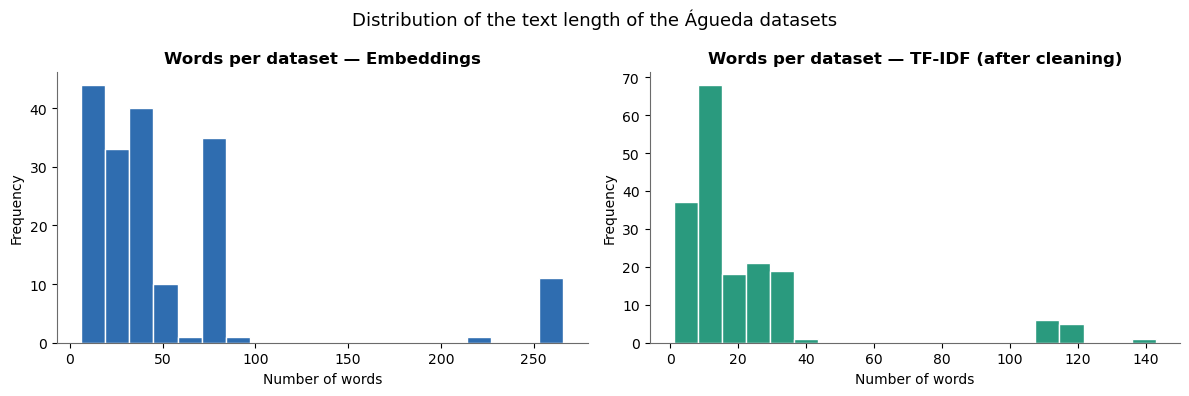

In [11]:
# ── Histogram of the text length of the datasets ────────────────────────────
qc = pd.DataFrame({
    "total_datasets"            : [len(datasets)],
    "mean_words_embeddings" : [datasets["n_words_embeddings"].mean()],
    "mean_words_tfidf"      : [datasets["n_words_tfidf"].mean()],
})
display(qc)

# Comparative histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(datasets["n_words_embeddings"], bins=20, color=EMB_COLOUR, edgecolor="white")
axes[0].set_title("Words per dataset — Embeddings")
axes[0].set_xlabel("Number of words"); axes[0].set_ylabel("Frequency")

axes[1].hist(datasets["n_words_tfidf"], bins=20, color=TFIDF_COLOUR, edgecolor="white")
axes[1].set_title("Words per dataset — TF-IDF (after cleaning)")
axes[1].set_xlabel("Number of words")
axes[1].set_ylabel("Frequency")

plt.suptitle("Distribution of the text length of the Águeda datasets", fontsize=13)
plt.tight_layout(); plt.show()

### Dissertation figures (print format)

The **Figure 4.x (dissertation)** cells repeat the design of the original charts of this notebook used in Chapter 4 (same data, same type of chart, same colours and markers), but adjusted for printing:

- width equal to the usable width of the dissertation's A4 page: 21 cm − 3 cm − 2.5 cm of margins = **15.5 cm** (the height depends on the content);
- no background grid;
- larger font, at actual size on the page: 9 pt on the axes, 8.5 pt on the tick marks, legends and values, 9.5 pt in the panel titles;
- legends and labels rearranged, when necessary, to fit that width; the overall title moves to the figure caption in Word.
- decimal separator defined in a single variable, `DECIMAL_SEPARATOR` (full stop in this English version of the notebook; comma in the Portuguese version of the dissertation).

Each figure is exported at 300 dpi to `outputs/<municipality>/03_chunksAllText/dissertation_figures/`. The other charts in the notebook remain visible for inspection, but are not exported.

In [12]:
# ── Dissertation figures: page size, font and export ─────────────────────────
FIG_WIDTH = 15.5 / 2.54          # usable width of the dissertation's A4 page (15.5 cm), in inches
DISS_FONT = {"font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9, "xtick.labelsize": 8.5,
              "ytick.labelsize": 8.5, "legend.fontsize": 8.5, "legend.title_fontsize": 8.5}
FIG_DISS_DIR = OUTPUT_DIR / "dissertation_figures"
FIG_DISS_DIR.mkdir(parents=True, exist_ok=True)
# Number and panel of each figure in the dissertation (they depend on the municipality)
FIG_DISS = {
    "agueda": {"4.1": "4_1_a", "4.2a": "4_2_a", "4.2b": "4_2_b", "4.4": "4_4_a", "4.5": "4_5_a",
               "4.6e": "4_6_a", "4.6m": "4_6_b", "4.7": "4_7_a", "4.8k": "4_8_a", "4.8p": "4_8_b"},
    "porto":  {"4.1": "4_1_b", "4.2a": "4_3_a", "4.2b": "4_3_b", "4.4": "4_4_b", "4.5": "4_5_b",
               "4.6e": "4_6_c", "4.6m": "4_6_d", "4.7": "4_7_b", "4.8k": "4_8_c", "4.8p": "4_8_d"},
}[SUFFIX]

# Decimal separator of the figures: "." for the English version of the dissertation ("," in the Portuguese version).
DECIMAL_SEPARATOR = "."

def num(text_value):
    """Writes numbers (or text with numbers) with the decimal separator defined above."""
    return str(text_value).replace(".", DECIMAL_SEPARATOR)

from matplotlib.ticker import MaxNLocator, ScalarFormatter

class DecimalFormatter(ScalarFormatter):
    """Same as matplotlib's usual formatter, but with DECIMAL_SEPARATOR."""
    def __call__(self, x, pos=None):
        return num(super().__call__(x, pos))

def apply_decimal_separator(fig):
    """Applies DECIMAL_SEPARATOR to the numeric tick labels of the axes (categorical axes are not changed)."""
    for ax in fig.axes:
        for axis_name in (ax.xaxis, ax.yaxis):
            if type(axis_name.get_major_formatter()) is ScalarFormatter:
                axis_name.set_major_formatter(DecimalFormatter())

def export_diss_figure(fig, key_name, name_):
    """Saves the figure at 300 dpi with the exact width of 15.5 cm and shows it."""
    apply_decimal_separator(fig)
    file_path = FIG_DISS_DIR / f"figure_{FIG_DISS[key_name]}_{name_}.png"
    fig.savefig(file_path, dpi=300, facecolor="white")
    print(f"Exported: {file_path.relative_to(PROJECT_DIR)}")
    plt.show()


#### Figure 4.1 (dissertation) — Text length of the datasets

Section 4.1. Print version of the histogram above: number of words per dataset in the text used by the embeddings and in the TF-IDF text after cleaning. Panel a) Águeda, b) Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_1_a_text_length.png


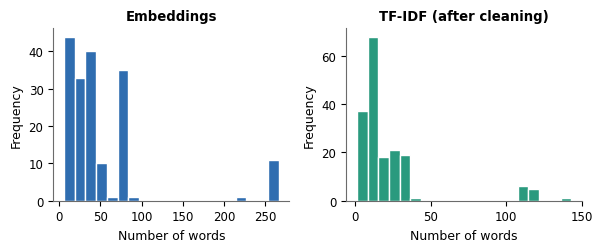

In [13]:
# ── Figure 4.1 (dissertation): text length ───────────────────────────────────
with plt.rc_context(DISS_FONT):
    fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, 2.6))
    axes[0].hist(datasets["n_words_embeddings"], bins=20, color=EMB_COLOUR, edgecolor="white")
    axes[0].set_title("Embeddings")
    axes[0].set_xlabel("Number of words"); axes[0].set_ylabel("Frequency")
    axes[1].hist(datasets["n_words_tfidf"], bins=20, color=TFIDF_COLOUR, edgecolor="white")
    axes[1].set_title("TF-IDF (after cleaning)")
    axes[1].set_xlabel("Number of words"); axes[1].set_ylabel("Frequency")
    plt.tight_layout()
    export_diss_figure(fig, "4.1", "text_length")


**Analysis of the results (4.1 — Text length of the datasets).**

On average, each Águeda dataset has 53.1 words in the text used by the embeddings and 22.4 terms after the lexical cleaning of TF-IDF. The mean hides, however, a very skewed distribution. The vast majority of the texts lie below 90 words, but a small isolated group stands out on the right, with about 260 words, which corresponds to the standard descriptions of the PDM 2024 records. The same group reappears in the TF-IDF histogram, between 105 and 125 terms.

This skewness has direct consequences. On the one hand, it pulls the mean upwards, which is why the median (34 words) better describes the typical text of the catalogue. On the other, it is precisely these long records that exceed the token limit of the embedding model (Section 5.1).

#### 4.1.1 Document series

Identification of the sets of records with standardised descriptions referred to in Section 4.1 and in Table 4.1 of the dissertation. The masks defined here (`DOC_SERIES` and `SERIES_BY_ID`) are reused in the counts of sections 7.4.1, 7.9.1, 9.3.2 and 11.3.

In [14]:
# ── 4.1.1 Document series (Section 4.1 and Table 4.1 of the dissertation) ─────
DISSERTATION_COUNTS = {}          # tables exported at the end (section 11.3)

_name = datasets["title"].fillna("").astype(str)
_desc = datasets["description"].fillna("").astype(str).str.strip()

if SUFFIX == "agueda":
    DOC_SERIES = {
        "Traffic counts": _name.str.contains("contagem", case=False) | _desc.str.contains("contagem", case=False),
        "PDM": _name.str.contains("PDM|plano diretor", case=False) | _desc.str.contains("PDM|plano diretor", case=False),
    }
    SERIES_DETAIL = {
        "Descriptions starting with 'Contagem de tráfego'": _desc.str.startswith("Contagem de tráfego"),
        "  … of which 'Contagem de tráfego sobre a Rua'": _desc.str.startswith("Contagem de tráfego sobre a Rua"),
    }
else:
    DOC_SERIES = {
        "Points of interest": _desc.str.lower().str.startswith("pontos de interesse"),
        "'Layer de geometria tipo…' layers": _desc.str.startswith("Layer de geometria tipo"),
        "Records with 'PDM' in the name": _name.str.contains("PDM"),
    }
    _maps = _desc.str.startswith("Esta Carta pertence")
    SERIES_DETAIL = {
        "Maps ('Esta Carta pertence à Planta de…')": _maps,
        "Maps that also have 'PDM' in the name": _maps & _name.str.contains("PDM"),
    }

_mat = pd.concat(DOC_SERIES.values(), axis=1)
assert (_mat.sum(axis=1) <= 1).all(), "There are records in more than one series."
SERIES_BY_ID = pd.Series("Outside the series", index=datasets["dataset_id"].values, name="series")
for _k, _m in DOC_SERIES.items():
    SERIES_BY_ID[_m.to_numpy()] = _k

series_tab = pd.DataFrame(
    [{"set": k, "n": int(m.sum()), "% of corpus": round(100 * m.mean(), 1)} for k, m in DOC_SERIES.items()]
    + [{"set": "Outside the series", "n": int((SERIES_BY_ID == "Outside the series").sum()),
        "% of corpus": round(100 * (SERIES_BY_ID == "Outside the series").mean(), 1)}]
    + [{"set": "  detail: " + k, "n": int(m.sum()), "% of corpus": round(100 * m.mean(), 1)} for k, m in SERIES_DETAIL.items()]
)
DISSERTATION_COUNTS["Document series"] = series_tab
print(f"Document series — {SUFFIX} (n = {len(datasets)})")
display(series_tab)

Document series — agueda (n = 176)


,set,n,% of corpus
0,Traffic counts,79,44.9
1,PDM,46,26.1
2,Outside the series,51,29.0
3,detail: Descriptions starting with 'Contagem de tráfego',74,42.0
4,detail: … of which 'Contagem de tráfego sobre a Rua',54,30.7


### 4.2 Loading and pre-processing the anchor texts

The anchor texts are the central element of the classification system: they define, in natural language, what characterises each Smart City dimension. The quality and detail of these texts have a direct impact on the quality of the classification - which is precisely why four versions of increasing length are tested (original, 50, 100, 150 words).

#### Expected structure of the anchor files

Each anchor CSV file must have at least two columns:
- A column with the name of the dimension (detected automatically among variants such as `"dimensao"`, `"dimensão"`, `"dimension"`, `"categoria"`);
- A column with the descriptive text (detected among `"texto"`, `"text"`, `"descricao"`, `"descrição"`, `"anchor"`, `"ancoras"`).

The file may have multiple rows per dimension (for example, if the anchor consists of several paragraphs). In that case, the texts are concatenated before classification.

#### Application of the pipelines

The same two pre-processing pipelines are applied to the anchor texts:
- `text_embeddings`: light cleaning, to be encoded by the model;
- `text_tfidf`: rich cleaning, to be vectorised by TF-IDF in the same space as the datasets.

It is essential that **anchors and datasets use exactly the same pipeline** for each method. If the anchor text is cleaned differently from the dataset text, the comparison by cosine similarity becomes biased.

#### Consistency check across versions

The notebook automatically checks that the dimensions present in each anchor version are the same. If a version introduces or removes a dimension (for example, because of a typing error), execution is stopped to avoid inconsistent comparisons between versions.

#### Visualisation of the length of the anchors by version

A bar chart is produced with the number of words of each anchor by version and dimension. This chart serves to confirm that the versions do have increasing lengths and that no dimension was left out of any version.


In [15]:
def prepare_anchors(path, version_name: str) -> pd.DataFrame:
    """Loads, validates and pre-processes an anchor text file."""
    anchors = read_csv_auto(path)
    anchors = anchors.loc[:, ~anchors.columns.astype(str).str.contains("^Unnamed")]

    dim_col  = pick_col(anchors, ["dimensao","dimensão","dimension","categoria","classe","label"])
    text_col = pick_col(anchors, ["texto","text","anchor","ancora","âncora","descricao","descrição","description"])

    if dim_col is None or text_col is None:
        raise ValueError(
            f"Could not identify the dimension and text columns in file '{path}'. "
            f"Available columns: {list(anchors.columns)}"
        )

    anchors = anchors[[dim_col, text_col]].copy()
    anchors.columns = ["dimension", "original_text"]
    anchors["anchor_version"] = version_name

    anchors["dimension"]         = anchors["dimension"].map(lambda x: normalize_spaces(safe_text(x)).title()).replace(DIM_EN)
    anchors["text_embeddings"] = anchors["original_text"].map(clean_text_embeddings)
    # The anchors are only a few rows (one per dimension), so the cost of spaCy
    # here is irrelevant — but the same batch function is used for consistency
    # with the pre-processing of the datasets (cell 17) and to reuse the
    # same tested code.
    anchors["text_tfidf"] = clean_text_tfidf_batch(anchors["original_text"])

    anchors["n_words_embeddings"] = anchors["text_embeddings"].map(word_count)
    anchors["n_words_tfidf"]      = anchors["text_tfidf"].map(word_count)

    duplicated_cols = anchors.loc[anchors["dimension"].duplicated(), "dimension"].tolist()
    if duplicated_cols:
        print(f"  ⚠️  Duplicate dimensions in '{path}': {duplicated_cols}")
        print(f"     They will be aggregated by concatenation in process_anchor_version.")

    return anchors


anchors_by_version = {}
for version_name, path in ANCHOR_FILES.items():
    anchors_by_version[version_name] = prepare_anchors(path, version_name)
    print(f"  {version_name}: {len(anchors_by_version[version_name])} dimensions loaded")

# Consistency check across versions
dimensions_by_version = {v: set(df["dimension"].tolist()) for v, df in anchors_by_version.items()}
reference = next(iter(dimensions_by_version.values()))
for version, dims in dimensions_by_version.items():
    if set(dims) != set(reference):
        raise ValueError(
            f"The dimensions of version '{version}' do not match the reference version.\n"
            f"Missing: {reference - dims}  |  Extra: {dims - reference}"
        )

DIMENSIONS = sorted(reference, key=dim_sort_key)
print(f"\nSmart City dimensions identified ({len(DIMENSIONS)}):")
for d in DIMENSIONS:
    print(f"  — {d}")

first_version = next(iter(anchors_by_version))
display(anchors_by_version[first_version][["dimension","n_words_embeddings","n_words_tfidf"]])

  original: 6 dimensions loaded
  50_words: 6 dimensions loaded


  100_words: 6 dimensions loaded
  150_words: 6 dimensions loaded

Smart City dimensions identified (6):
  — Smart Environment
  — Smart Economy
  — Smart Governance
  — Smart Mobility
  — Smart Quality of Life
  — Smart Society


,dimension,n_words_embeddings,n_words_tfidf
0,Smart Governance,106,62
1,Smart Society,163,90
2,Smart Mobility,147,85
3,Smart Environment,363,212
4,Smart Quality of Life,312,167
5,Smart Economy,148,82


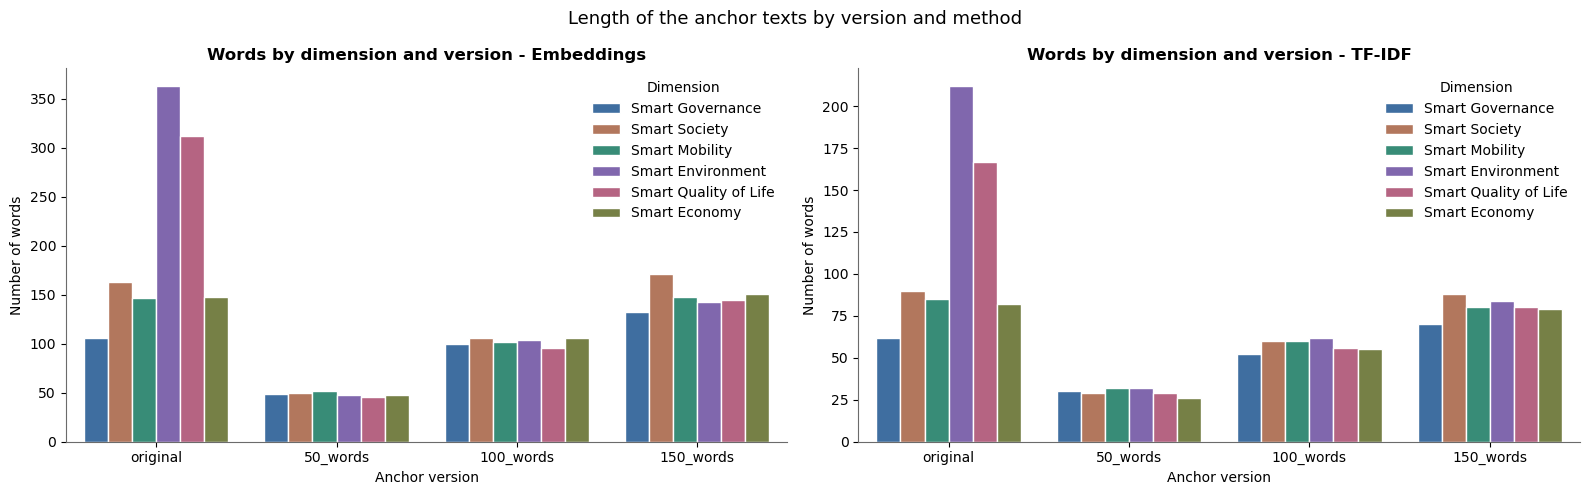

In [16]:
# ── Plot of the number of words by version and dimension ─────────────────────
# Aggregate by dimension — guarantees one row per (version, dimension)
# even if the original CSV has several rows per dimension
comparison_anchors = pd.concat(
    [
        a.groupby("dimension", sort=False)
         .agg(n_words_embeddings=("n_words_embeddings", "sum"),
              n_words_tfidf=("n_words_tfidf", "sum"))
         .reset_index()
         .assign(version=version)
        for version, a in anchors_by_version.items()
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=comparison_anchors, x="version", y="n_words_embeddings",
            hue="dimension", ax=axes[0], palette=CATEGORICAL_PALETTE, edgecolor="white")
axes[0].set_title("Words by dimension and version - Embeddings")
axes[0].set_xlabel("Anchor version")
axes[0].set_ylabel("Number of words")
axes[0].legend(title="Dimension")

sns.barplot(data=comparison_anchors, x="version", y="n_words_tfidf",
            hue="dimension", ax=axes[1], palette=CATEGORICAL_PALETTE, edgecolor="white")
axes[1].set_title("Words by dimension and version - TF-IDF")
axes[1].set_xlabel("Anchor version")
axes[1].set_ylabel("Number of words")
axes[1].legend(title="Dimension")
format_x_labels(axes[0]); format_x_labels(axes[1])

plt.suptitle("Length of the anchor texts by version and method", fontsize=13)
plt.tight_layout()
plt.show()

**Analysis of the results (4.2 — Length of the anchor texts by version).**

In the original version, the anchors are very unequal: Environment and Quality of Life have more than 300 words, whereas Governance stays at 106. The three rewritten versions drastically reduce this asymmetry, bringing the six dimensions close to the requested length, although in the 150-word version Governance (132) and Society (171) fall outside the expected range. The number of terms in TF-IDF follows the same pattern, with the original Environment anchor exceeding 200 terms.

For TF-IDF, this difference is not neutral: an anchor with more vocabulary offers more opportunities for lexical overlap. This is one of the reasons why the rewritten versions were built, but also a reminder that the versions differ in more than length.

**Methodological note — length imbalance between dimensions ("original" version).**

The next cell explicitly quantifies something visible in the previous chart: in the "original" version,
some dimensions have considerably longer anchor texts than others. This is relevant because longer
anchors tend to have a richer vocabulary, which may give them a structural advantage in the
classification (more chances of lexical overlap in TF-IDF, and a semantically more "covered" centroid in the
embeddings) — regardless of the actual content of the dataset being classified. This asymmetry does not invalidate
the results, but it is a limitation of the original version.


In [17]:
# ── Quantifying the length imbalance between dimensions ─────────────────────
# (see note above) — computed for the "original" version, the most asymmetric one.

if "original" in anchors_by_version:
    words_original = (
        comparison_anchors[comparison_anchors["version"] == "original"]
        [["dimension", "n_words_embeddings"]]
        .sort_values("n_words_embeddings", ascending=False)
        .reset_index(drop=True)
    )
    print("Words by dimension — 'original' version (sorted, largest → smallest):")
    display(words_original)

    largest = words_original["n_words_embeddings"].max()
    smallest = words_original["n_words_embeddings"].min()
    ratio = largest / smallest if smallest > 0 else float("inf")

    print(f"\nLongest dimension  : {words_original.iloc[0]['dimension']} "
          f"({largest} words)")
    print(f"Shortest dimension : {words_original.iloc[-1]['dimension']} "
          f"({smallest} words)")
    print(f"Largest/smallest ratio: {ratio:.1f}x")
    if ratio >= 2:
        print(f"\n⚠️  Relevant imbalance (≥2x) — to be taken into account when interpreting the results: "
              f"dimensions with longer anchors have a richer vocabulary, which may "
              f"favour their assignment regardless of the actual content of the dataset.")
else:
    print("'original' version not available — check skipped.")


Words by dimension — 'original' version (sorted, largest → smallest):


,dimension,n_words_embeddings
0,Smart Environment,363
1,Smart Quality of Life,312
2,Smart Society,163
3,Smart Economy,148
4,Smart Mobility,147
5,Smart Governance,106



Longest dimension  : Smart Environment (363 words)
Shortest dimension : Smart Governance (106 words)
Largest/smallest ratio: 3.4x

⚠️  Relevant imbalance (≥2x) — to be taken into account when interpreting the results: dimensions with longer anchors have a richer vocabulary, which may favour their assignment regardless of the actual content of the dataset.


**Analysis of the results (4.2 — Length imbalance between dimensions).**

The longest anchor of the original version (Environment, 363 words) is 3.4 times longer than the shortest (Governance, 106). The imbalance is enough to justify caution in reading the original version, especially in TF-IDF, since the dimensions with longer texts have a richer vocabulary. This does not mean that the original version is wrong, only that it should not be compared with the others as if it differed from them only in length.

## 5. Loading the embedding model

### The chosen model: `paraphrase-multilingual-MiniLM-L12-v2`

The selected model is a *Sentence Transformer*, a BERT-based architecture that was specifically trained to generate vector representations of whole sentences (instead of individual words), so that sentences with similar meaning are close together in the vector space.

The `paraphrase-multilingual-MiniLM-L12-v2` variant was trained on more than 50 languages, including Portuguese, which makes it suitable for this corpus. It has 12 *layers* and produces embeddings of **384 dimensions**, an efficient compromise between semantic capacity and inference speed.

### Why this model and not another?

There are more powerful models available (such as `multilingual-e5-large` or `paraphrase-multilingual-mpnet-base-v2`), but `MiniLM-L12-v2` offers sufficient semantic quality for classification into broad thematic categories, with a much shorter inference time. For a corpus of tens to a few hundred datasets, the difference in quality between models is marginal, but the difference in speed is relevant when testing multiple anchor versions.

In [18]:
print(f"Loading model: {MODEL_NAME}")
model = SentenceTransformer(MODEL_NAME, revision=MODEL_REVISION, device=MODEL_DEVICE)
print("Model loaded successfully.")

Loading model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


Model loaded successfully.


### 5.1 Diagnostic of the model's token limit

The embedding model processes at most `max_seq_length` tokens per sequence (including the special tokens). With direct encoding (`model.encode(text)`), the text that exceeds this limit would be ignored when computing the vector: `model.encode` does **not** automatically process the full text. This check counts the tokens of each text exactly as it is sent to the model — metadata of the datasets (`doc_text_embeddings`) and text of each dimension in each anchor version — and indicates how many exceed the limit and what proportion would be lost.

The check only measures. The correction is made in Section 5.2: all texts are encoded by a full-text function, which splits long texts into segments within the limit. The cases above the limit are recorded in `outputs/agueda/03_chunksAllText/checks/ML-001_truncation_<municipality>.xlsx`.


In [19]:
# ── 5.1 Checking the token limit (truncation) ────────────────────────────────
# Read-only: uses the `model`, the `datasets` and the `anchors_by_version` already loaded.
tokeniser = model.tokenizer
TOKEN_LIMIT = int(model.max_seq_length)

def n_tokens(texts):
    """Number of tokens WITHOUT truncation, including the special tokens."""
    return np.array([len(tokeniser(str(t), add_special_tokens=True, truncation=False)["input_ids"])
                     for t in texts])

# Datasets: the exact text sent to the model
tok_ds = datasets[["dataset_id", "title"]].copy()
tok_ds["words"] = datasets["doc_text_embeddings"].fillna("").astype(str).str.split().str.len()
tok_ds["tokens"] = n_tokens(datasets["doc_text_embeddings"].fillna(""))
tok_ds["above_limit"] = tok_ds["tokens"] > TOKEN_LIMIT
tok_ds["pct_tokens_ignored"] = ((tok_ds["tokens"] - TOKEN_LIMIT).clip(lower=0) / tok_ds["tokens"] * 100).round(1)

# Anchors: text aggregated by dimension, as in the classification
rows_tok = []
for version, anc in anchors_by_version.items():
    agg = anc.groupby("dimension", sort=False)["text_embeddings"].apply(lambda s: " ".join(s.astype(str)))
    for dim, text_value in agg.items():
        n = int(n_tokens([text_value])[0])
        rows_tok.append({"version": version, "dimension": dim, "words": len(text_value.split()),
                           "tokens": n, "above_limit": n > TOKEN_LIMIT,
                           "pct_tokens_ignored": round(max(n - TOKEN_LIMIT, 0) / n * 100, 1)})
tok_anc = pd.DataFrame(rows_tok)

n_ds_above = int(tok_ds["above_limit"].sum())
n_anc_above = int(tok_anc["above_limit"].sum())
print(f"Model:              {MODEL_NAME}")
print(f"max_seq_length:     {TOKEN_LIMIT}")
print(f"N datasets:         {len(tok_ds)}")
print(f"N anchors:          {len(tok_anc)} ({tok_anc['version'].nunique()} versions x {tok_anc['dimension'].nunique()} dimensions)")
print(f"Max datasets:       {tok_ds['tokens'].max()} tokens | P95: {np.percentile(tok_ds['tokens'], 95):.0f}")
print(f"Max anchors:        {tok_anc['tokens'].max()} tokens")
print(f"N datasets above:   {n_ds_above} ({n_ds_above / len(tok_ds) * 100:.1f}%)")
print(f"N anchors above:    {n_anc_above} of {len(tok_anc)}")
print("\nTokens per anchor (dimension x version):")
display(tok_anc.pivot(index="dimension", columns="version", values="tokens")
        .reindex(columns=list(anchors_by_version.keys())))
if n_anc_above:
    print("Anchors above the limit (they would be truncated with direct encoding; see Section 5.2):")
    display(tok_anc.loc[tok_anc["above_limit"]].sort_values("pct_tokens_ignored", ascending=False))
if n_ds_above:
    print("Datasets above the limit (10 longest):")
    display(tok_ds.loc[tok_ds["above_limit"]].sort_values("tokens", ascending=False).head(10))

print("\nConclusion:", "no text exceeds the model limit." if (n_ds_above + n_anc_above) == 0 else
      "there are texts above the limit — direct encoding would truncate them; all texts are encoded with the full-text function of Section 5.2.")

with pd.ExcelWriter(VERIF_DIR / f"ML-001_truncation_{SUFFIX}.xlsx") as w:
    tok_anc.to_excel(w, sheet_name="Anchors", index=False)
    tok_ds.to_excel(w, sheet_name="Datasets", index=False)
print(f"\nSaved: {VERIF_DIR / f'ML-001_truncation_{SUFFIX}.xlsx'}")

Token indices sequence length is longer than the specified maximum sequence length for this model (138 > 128). Running this sequence through the model will result in indexing errors


Model:              sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
max_seq_length:     128
N datasets:         176
N anchors:          24 (4 versions x 6 dimensions)
Max datasets:       442 tokens | P95: 431
Max anchors:        625 tokens
N datasets above:   14 (8.0%)
N anchors above:    18 of 24

Tokens per anchor (dimension x version):


version,original,50_words,100_words,150_words
dimension,,,,
Smart Economy,221,70,155,212
Smart Environment,625,80,164,222
Smart Governance,165,76,146,188
Smart Mobility,263,88,164,228
Smart Quality of Life,503,79,157,223
Smart Society,238,75,155,239


Anchors above the limit (they would be truncated with direct encoding; see Section 5.2):


,version,dimension,words,tokens,above_limit,pct_tokens_ignored
3,original,Smart Environment,363,625,True,79.5
4,original,Smart Quality of Life,312,503,True,74.6
2,original,Smart Mobility,147,263,True,51.3
19,150_words,Smart Society,171,239,True,46.4
1,original,Smart Society,163,238,True,46.2
20,150_words,Smart Mobility,148,228,True,43.9
22,150_words,Smart Quality of Life,145,223,True,42.6
21,150_words,Smart Environment,143,222,True,42.3
5,original,Smart Economy,148,221,True,42.1
23,150_words,Smart Economy,151,212,True,39.6


Datasets above the limit (10 longest):


,dataset_id,title,words,tokens,above_limit,pct_tokens_ignored
9,35ef0ccc-ffcf-4bec-86ea-f390b52d69bc,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,266,442,True,71.0
56,ef84ae09-3dac-4289-8f8c-e1ca41ae89ee,PDM 2024 - Planta de Condicionantes – Perigosidade de Incêndio Florestal,263,440,True,70.9
52,4dbe6042-3825-495d-8e04-562c01084d7a,PDM 2024 - Planta de Ordenamento - Risco de Cheias e Inundações,264,438,True,70.8
49,0ba62001-e58a-4f4a-b529-c4dac6a82243,PDM 2024 - Planta de Ordenamento - Superfícies de Desobstrução,262,438,True,70.8
8,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,262,437,True,70.7
54,bd31938f-15ea-4066-8a1d-36fd15688311,PDM 2024 - Planta de Condicionantes – Reserva Agrícola Nacional,262,436,True,70.6
53,04636627-733c-487a-bbb0-4314d6f0a923,PDM 2024 - Planta de Condicionantes – Condicionantes Gerais,261,435,True,70.6
7,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,261,435,True,70.6
48,406f9c1d-4f59-42a9-af1c-dcd585483e74,PDM 2024 - Planta de Ordenamento - Património,259,432,True,70.4
47,f9c7002c-77c3-40a3-97f9-90dc18b15a8f,PDM 2024 - Planta de Ordenamento - Ordenamento,259,431,True,70.3



Conclusion: there are texts above the limit — direct encoding would truncate them; all texts are encoded with the full-text function of Section 5.2.



Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\checks\ML-001_truncation_agueda.xlsx


**Analysis of the results (5.1 — Diagnostic of the token limit).**

The diagnostic confirms that direct encoding would lose a considerable part of the text. Fourteen datasets (8.0%) exceed the model's 128 tokens, and the ten longest are all PDM 2024 records, with up to 442 tokens, of which direct encoding would ignore nearly 70%. Among the anchors, the situation is more serious: 18 of the 24 exceed the limit, and only the six of the 50-word version (70 to 88 tokens) fit entirely. The original Environment anchor, with 625 tokens, would lose almost 80% of its text, and the Quality of Life anchor, with 503, nearly 75%.

It was this diagnostic that led to the adoption of the full-text encoding described in Section 5.2.

### 5.2 Full-text encoding (sentence-based segmentation)

So that no text is truncated, **all** texts — datasets and anchors of the four versions — go through the same function, even when they fit in a single segment:

1. the content limit is computed with the model's own tokenizer: `max_seq_length` minus the special tokens;
2. the text (already with the light embeddings pre-processing, unchanged) is split into sentences (spaCy `sentencizer`);
3. consecutive sentences are grouped into segments (*chunks*) that do not exceed the limit; a sentence that on its own exceeds it is split by words;
4. there is no overlap between segments (`overlap = 0`);
5. each segment is encoded **without** prior normalisation;
6. the vector of the text is the average of the vectors of the segments, weighted by the number of content tokens of each segment (without special tokens);
7. the final vector is normalised by the L2 norm.

A text that fits within the limit forms a single segment equal to the text itself, so its vector coincides with that of direct encoding (checked in Section 5.3). The segments are encoded in batch and regrouped by text; the result is the same as encoding text by text.

Averaging the segments is an operational approximation of the representation of long texts: it avoids the loss of content through truncation, but it is not equivalent to a model that reads the full text at once.


In [20]:
# ── 5.2 Full-text encoding: sentences → chunks → weighted average → L2 ───────
import spacy

tokenizer = model.tokenizer
MAX_SEQ_LENGTH = int(model.max_seq_length)
N_SPECIAL_TOKENS = tokenizer.num_special_tokens_to_add(pair=False)
MAX_CONTENT_TOKENS = MAX_SEQ_LENGTH - N_SPECIAL_TOKENS
print("Model:", MODEL_NAME)
print("max_seq_length:", MAX_SEQ_LENGTH)
print("special tokens:", N_SPECIAL_TOKENS)
print("content token limit:", MAX_CONTENT_TOKENS)
print("encoding mode:", EMBEDDING_ENCODING_MODE, "| overlap:", CHUNK_OVERLAP,
      "| weights:", CHUNK_WEIGHTING, "| final normalisation:", FINAL_NORMALIZATION)

nlp_sent = spacy.blank("pt")
nlp_sent.add_pipe("sentencizer")


def count_content_tokens(text, tokenizer=tokenizer):
    """Number of content tokens (without special tokens), with the model's tokenizer."""
    return len(tokenizer(text, add_special_tokens=False, truncation=False)["input_ids"])


def count_total_tokens(text, tokenizer=tokenizer):
    """Number of tokens of the sequence that enters the model (with special tokens)."""
    return len(tokenizer(text, add_special_tokens=True, truncation=False)["input_ids"])


def split_sentences(text):
    return [sent.text.strip() for sent in nlp_sent(text).sents if sent.text.strip()]


def split_long_unit_by_words(text, max_content_tokens=MAX_CONTENT_TOKENS):
    """Safety rule: splits by words a sentence that, on its own, exceeds the limit."""
    words, chunks, current = text.split(), [], []
    for word in words:
        candidate = " ".join(current + [word]).strip()
        if current and count_content_tokens(candidate) > max_content_tokens:
            chunks.append(" ".join(current).strip())
            current = [word]
            if count_content_tokens(word) > max_content_tokens:
                raise ValueError("Found an individual element that exceeds the token limit.")
        else:
            current.append(word)
    if current:
        chunks.append(" ".join(current).strip())
    return chunks


def build_token_limited_chunks(text, max_content_tokens=MAX_CONTENT_TOKENS, max_seq_length=MAX_SEQ_LENGTH):
    """Sentence-based chunks, without overlap, each within the model limit."""
    text = text.strip()
    if not text:
        raise ValueError("Empty text after preprocessing.")
    if count_content_tokens(text) <= max_content_tokens:
        chunks = [text]                       # fits within the limit: a single chunk, equal to the text
    else:
        units = []
        for sent in split_sentences(text):
            if count_content_tokens(sent) <= max_content_tokens:
                units.append(sent)
            else:
                units.extend(split_long_unit_by_words(sent, max_content_tokens))
        chunks, current = [], []
        for unit in units:
            candidate = " ".join(current + [unit]).strip()
            if current and count_content_tokens(candidate) > max_content_tokens:
                chunks.append(" ".join(current).strip())
                current = [unit]
            else:
                current.append(unit)
        if current:
            chunks.append(" ".join(current).strip())
    for chunk in chunks:
        n_total = count_total_tokens(chunk)
        if n_total > max_seq_length:
            raise AssertionError(f"Chunk with {n_total} tokens; limit={max_seq_length}")
    # The split may change whitespace, but it cannot lose characters of the content.
    assert "".join(text.split()) == "".join("".join(chunks).split()), "Text lost in segmentation"
    return chunks


def aggregate_chunk_embeddings(chunks, chunk_embeddings):
    """Average weighted by the number of content tokens of each chunk, followed by L2 normalisation."""
    weights = np.array([count_content_tokens(c) for c in chunks], dtype=float)
    doc_embedding = np.average(chunk_embeddings, axis=0, weights=weights)
    norm = np.linalg.norm(doc_embedding)
    if norm == 0:
        raise ValueError("Aggregated embedding with zero norm.")
    return doc_embedding / norm


QA_TEXTS, QA_CHUNKS, EMB_CACHE = [], [], {}


def encode_full_texts(texts, text_ids, source, version):
    """SINGLE full-text encoding function (datasets and anchors of all versions).

    The chunks of all texts are encoded in batch (without prior normalisation) and
    regrouped by text; each text receives the weighted average of its chunks, normalised.
    Records one QA row per text and per chunk."""
    texts = [str(t) for t in texts]
    chunks_per_text = [build_token_limited_chunks(t) for t in texts]
    flat_chunks = [c for cs in chunks_per_text for c in cs]
    E = model.encode(flat_chunks, normalize_embeddings=False, convert_to_numpy=True, show_progress_bar=False)
    out, k = [], 0
    for text_value, tid, cs in zip(texts, text_ids, chunks_per_text):
        n = len(cs)
        emb = aggregate_chunk_embeddings(cs, E[k:k + n]); k += n
        out.append(emb)
        QA_TEXTS.append({"source": source, "text_id": str(tid), "version": version,
                          "tokens_original": count_total_tokens(text_value), "n_chunks": n,
                          "max_chunk_tokens": max(count_total_tokens(c) for c in cs),
                          "was_split": n > 1, "embedding_norm": float(np.linalg.norm(emb)),
                          "coverage_ok": "".join(text_value.split()) == "".join("".join(cs).split())})
        for j, c in enumerate(cs):
            QA_CHUNKS.append({"source": source, "text_id": str(tid), "version": version, "chunk_id": j,
                              "n_tokens": count_content_tokens(c), "chunk_text": c})
        EMB_CACHE[(source, str(tid), version)] = (text_value, emb)
    return np.vstack(out)

print("Full-text encoding function ready.")


Model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
max_seq_length: 128
special tokens: 2
content token limit: 126
encoding mode: sentence_aware_token_limited_weighted_v1 | overlap: 0 | weights: content_token_count | final normalisation: L2
Full-text encoding function ready.


## 6. Classification by anchor version

This section is the computational core of the notebook: for each of the four anchor versions, the two classification pipelines (Embeddings and TF-IDF) are run and the results are stored in a data structure indexed by version.

### What happens in each iteration

**For the Embeddings:**
1. The `doc_text_embeddings` texts of the datasets are encoded by the model, producing an `X_data` matrix with shape `(n_datasets × 384)`.
2. The `text_embeddings` texts of the anchors are likewise encoded, producing an `X_anc` matrix with shape `(n_dimensions × 384)`.
3. The cosine similarity between each dataset and each anchor is computed: `S = X_data @ X_anc.T`, producing a matrix with shape `(n_datasets × n_dimensions)`.
4. For each dataset, the dimension with the highest score is assigned, and the delta (top-1 minus top-2) is computed.

**For TF-IDF:**
1. The `doc_text_tfidf` texts of the datasets and the `text_tfidf` texts of the anchors are used to fit a single TF-IDF vectoriser on the full corpus (datasets + anchors). This decision is crucial: if the vectoriser were fitted only on the datasets, the tokens that appear exclusively in the anchors would be ignored, and vice versa.
2. The texts are transformed into the TF-IDF space and the cosine similarity is computed in the same way.

### Why test four anchor versions?

The quality of the classification depends critically on the detail and specificity of the anchor texts. A very short anchor (e.g. just the name of the dimension) may not capture the various sub-themes that the dimension encompasses. A longer anchor may be more discriminative, but it may also introduce noise if it includes very specific examples.

The original text of each ENTI dimension is the normative reference for the content. The versions of approximately 50, 100 and 150 words are alternative operationalisations, obtained by rewriting with the support of a language model, and serve to assess the sensitivity of the results to the textual representation of the dimensions. They are not progressive reductions of the same text: they differ simultaneously in length, wording, lexical selection and level of detail. By testing the four versions it is possible to:
- describe the extent to which the assigned dimension changes when the textual representation of the dimensions changes;
- identify stable datasets (same dimension in the four versions) and unstable ones (variable dimension).

The comparison does not make it possible to attribute the differences only to the length of the anchors or to choose a “better” version.

### Adaptive confidence thresholds

After classifying with each version and method, the confidence thresholds are computed adaptively from the 33rd and 66th percentiles of the observed distribution of deltas. The scales of the delta differ between Embeddings and TF-IDF (the observed values are given in the tables of Section 6), so a fixed threshold common to both methods would not be comparable. The percentile thresholds adjust to the distribution of each method and version; by construction, about one third of the valid cases falls into each band, and the bands are not probabilities or levels of accuracy.

### Structure of the results

The results of each version are stored in the dictionary `results_by_version`, in which each entry contains:
- `"results"`: DataFrame with the assigned dimension, scores, delta and confidence level for each dataset and method;
- `"scores_emb"` and `"scores_tfidf"`: full score matrices (datasets × dimensions)
- `"thresholds"`: dictionary with the values of the adaptive thresholds used.

After the main run, descriptive statistics of the distribution of the deltas are computed, together with a diagnostic of the datasets with TF-IDF score = 0, information that is important for calibrating thresholds and understanding the limitations of the lexical method.


In [21]:
# ── Running all anchor versions ──────────────────────────────────────────────
#
# The embeddings of the datasets (doc_text_embeddings) are computed ONLY ONCE
# here, before the loop, and reused in the 4 anchor versions: only the anchor
# text changes between versions; the datasets are always the same.
#
# All embeddings (datasets and anchors) are computed with encode_full_texts
# (Section 5.2): no text is truncated.

print("Computing the embeddings of the datasets (1x, reused in the 4 anchor versions)...")
X_data_emb_global = encode_full_texts(
    datasets["doc_text_embeddings"].tolist(),
    datasets["dataset_id"].astype(str).tolist(),
    SUFFIX, "dataset",
)
print(f"Embeddings computed: {X_data_emb_global.shape}")

results_by_version = {}

for version, anchors in anchors_by_version.items():
    results_by_version[version] = process_anchor_version(
        version, anchors, datasets, X_data_emb_cache=X_data_emb_global
    )

# Aggregated table with the results of all versions (used in the plots)
results_all_versions = pd.concat(
    [obj["results"] for obj in results_by_version.values()],
    ignore_index=True,
)
print(f"\nAggregated table: {results_all_versions.shape[0]} rows × {results_all_versions.shape[1]} columns")
display(results_all_versions.head())

Computing the embeddings of the datasets (1x, reused in the 4 anchor versions)...


Embeddings computed: (176, 384)

  Processing version: original
  Dimensions (6): ['Smart Governance', 'Smart Society', 'Smart Mobility', 'Smart Environment', 'Smart Quality of Life', 'Smart Economy']
  → Embeddings... (datasets cached)


  → TF-IDF...
  Adaptive thresholds (original):
    Embeddings → high: ≥0.067  medium: ≥0.025
    TF-IDF     → high: ≥0.006  medium: ≥0.003
  ⚠️  TF-IDF    : 7/176 datasets unclassified (4.0%)
  Done. Agreement over 169/176 valid datasets: 39.1%

  Processing version: 50_words
  Dimensions (6): ['Smart Governance', 'Smart Society', 'Smart Mobility', 'Smart Environment', 'Smart Quality of Life', 'Smart Economy']
  → Embeddings... (datasets cached)


  → TF-IDF...
  Adaptive thresholds (50_words):
    Embeddings → high: ≥0.065  medium: ≥0.028
    TF-IDF     → high: ≥0.009  medium: ≥0.003
  ⚠️  TF-IDF    : 18/176 datasets unclassified (10.2%)
  Done. Agreement over 158/176 valid datasets: 25.9%

  Processing version: 100_words
  Dimensions (6): ['Smart Governance', 'Smart Society', 'Smart Mobility', 'Smart Environment', 'Smart Quality of Life', 'Smart Economy']
  → Embeddings... (datasets cached)


  → TF-IDF...
  Adaptive thresholds (100_words):
    Embeddings → high: ≥0.069  medium: ≥0.030
    TF-IDF     → high: ≥0.005  medium: ≥0.002
  ⚠️  TF-IDF    : 15/176 datasets unclassified (8.5%)
  Done. Agreement over 161/176 valid datasets: 45.3%

  Processing version: 150_words
  Dimensions (6): ['Smart Governance', 'Smart Society', 'Smart Mobility', 'Smart Environment', 'Smart Quality of Life', 'Smart Economy']
  → Embeddings... (datasets cached)


  → TF-IDF...
  Adaptive thresholds (150_words):
    Embeddings → high: ≥0.087  medium: ≥0.044
    TF-IDF     → high: ≥0.009  medium: ≥0.002
  ⚠️  TF-IDF    : 14/176 datasets unclassified (8.0%)
  Done. Agreement over 162/176 valid datasets: 45.7%

Aggregated table: 704 rows × 31 columns


,anchor_version,dataset_id,dataset_title,dataset_description,n_words_embeddings,n_words_tfidf,dimension_embeddings,score_top1_embeddings,dimension_top2_embeddings,score_top2_embeddings,delta_embeddings,confidence_embeddings,dimension_tfidf,score_top1_tfidf,dimension_top2_tfidf,score_top2_tfidf,delta_tfidf,confidence_tfidf,methods_agree,score_emb_Smart Governance,score_tfidf_Smart Governance,score_emb_Smart Society,score_tfidf_Smart Society,score_emb_Smart Mobility,score_tfidf_Smart Mobility,score_emb_Smart Environment,score_tfidf_Smart Environment,score_emb_Smart Quality of Life,score_tfidf_Smart Quality of Life,score_emb_Smart Economy,score_tfidf_Smart Economy
0,original,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,Revisão de Delimitação das Áreas de Reabilitação Urbana de 22 Aglomerados Urbanos e Delimitação de Novas Áreas de Reabilitação Urbana de \r\n15 Aglomerados ...,82,37,Smart Quality of Life,0.555290,Smart Environment,0.554278,0.001012,low,Smart Quality of Life,0.017308,Smart Governance,0.013404,0.003904,medium,True,0.293435,0.013404,0.479236,0.013217,0.358415,0.005604,0.554278,0.007268,0.555290,0.017308,0.422627,0.010842
1,original,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,Localização dos pontos de recolha de resíduos sólidos urbanos.,11,7,Smart Environment,0.595478,Smart Quality of Life,0.358796,0.236682,high,Smart Environment,0.065345,Smart Quality of Life,0.008892,0.056452,high,True,0.275817,0.000000,0.248962,0.000000,0.309526,0.000000,0.595478,0.065345,0.358796,0.008892,0.314599,0.000000
2,original,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,Contagem de tráfego na Rua dos Industriais. Direcção Rotunda de Assequins - IC2 Águeda Centro,19,9,Smart Mobility,0.448827,Smart Environment,0.329656,0.119171,high,Smart Mobility,0.002511,Smart Governance,0.000000,0.002511,low,True,0.240703,0.000000,0.289420,0.000000,0.448827,0.002511,0.329656,0.000000,0.302263,0.000000,0.300815,0.000000
3,original,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,Localização dos pontos de carregamento de veículos elétricos na cidade de Águeda.,18,8,Smart Mobility,0.551731,Smart Environment,0.379903,0.171829,high,Smart Mobility,0.231787,Smart Environment,0.026683,0.205104,high,True,0.217903,0.000000,0.205605,0.000000,0.551731,0.231787,0.379903,0.026683,0.319427,0.000000,0.245896,0.000000
4,original,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,"Dados em bruto da estação hidrométrica de Alhandra, sobre o Rio Águeda.",16,9,Smart Environment,0.272136,Smart Quality of Life,0.145229,0.126908,high,Smart Governance,0.006790,Smart Society,0.000000,0.006790,high,False,0.082797,0.006790,0.107475,0.000000,0.123687,0.000000,0.272136,0.000000,0.145229,0.000000,0.067247,0.000000


### 5.3 Mandatory checks of the encoding

Run after the encoding of all texts (datasets and anchors of the four versions), which takes place in the first cell of Section 6; that is why this subsection appears after it:

1. **no segment exceeds the model limit** (`max_seq_length`, with special tokens);
2. **equivalence for short texts:** for the texts that fit in a single segment, the vector obtained by the full-text function is compared with the normalised direct encoding (`model.encode(..., normalize_embeddings=True)`); criterion: cosine ≥ 0.99999;
3. **same function for all texts:** all vectors were produced by `encode_full_texts`, with the same encoding mode; the QA table has one row per text.

It is also checked that all final vectors have norm 1. The QA table (text by text and segment by segment) and the summary are saved in `outputs/agueda/03_chunksAllText/checks/QA_embeddings_<municipality>.xlsx`. If any check fails, execution stops here.


In [22]:
# ── 5.3 Mandatory checks and QA table ────────────────────────────────────────
qa = pd.DataFrame(QA_TEXTS).drop_duplicates(["source", "text_id", "version"]).reset_index(drop=True)
qa_chunks = pd.DataFrame(QA_CHUNKS).drop_duplicates(["source", "text_id", "version", "chunk_id"]).reset_index(drop=True)

# 1) No chunk above the limit
n_chunks_above = int((qa["max_chunk_tokens"] > MAX_SEQ_LENGTH).sum())
assert n_chunks_above == 0, f"{n_chunks_above} texts with chunks above the limit"
assert qa["coverage_ok"].all(), "There are texts whose content was not fully preserved"
assert np.allclose(qa["embedding_norm"], 1.0, atol=1e-5), "There are final vectors without unit norm"

# 2) Equivalence with direct encoding for short texts (a single chunk)
short_texts = [(k, v) for k, v in EMB_CACHE.items()
          if qa.loc[(qa["source"] == k[0]) & (qa["text_id"] == k[1]) & (qa["version"] == k[2]), "n_chunks"].iloc[0] == 1]
direct = model.encode([v[0] for _, v in short_texts], normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
chunked = np.vstack([v[1] for _, v in short_texts])
cos_short = np.sum(direct * chunked, axis=1)
cos_min = float(cos_short.min())
equivalence = pd.DataFrame({"source": [k[0] for k, _ in short_texts], "text_id": [k[1] for k, _ in short_texts],
                             "version": [k[2] for k, _ in short_texts], "cosine_direct_vs_chunked": cos_short})
assert cos_min >= 0.99999, f"Equivalence failed for short texts: minimum cosine = {cos_min:.7f}"
assert np.allclose(direct, chunked, atol=1e-5)

# 3) Same function for all texts: all encoded texts are in the QA table,
#    produced by encode_full_texts with the same encoding mode
n_expected = len(datasets) + sum(a["dimension"].nunique() for a in anchors_by_version.values())
assert len(qa) == n_expected, f"QA with {len(qa)} texts; expected {n_expected}"

# Summary by group (datasets and each anchor version)
qa["group"] = np.where(qa["source"] == "anchor", "anchors " + qa["version"], qa["source"])
qa_summary = (qa.groupby("group", sort=False)
               .agg(n_texts=("text_id", "size"), n_segmented=("was_split", "sum"),
                    max_chunks=("n_chunks", "max"), max_tokens_original=("tokens_original", "max"))
               .reset_index())
qa_summary["pct_segmented"] = (qa_summary["n_segmented"] / qa_summary["n_texts"] * 100).round(1)
config_qa = pd.DataFrame({"parameter": ["MODEL", "MAX_SEQ_LENGTH", "SPECIAL TOKENS", "CONTENT LIMIT",
                                        "MODE", "OVERLAP", "WEIGHTS", "FINAL NORMALISATION",
                                        "N CHUNKS ABOVE THE LIMIT", "N TEXTS WITH INCOMPLETE COVERAGE", "N SHORT TEXTS VALIDATED",
                                        "SHORT-TEXT VALIDATION: minimum cosine direct vs chunked"],
                          "value": [MODEL_NAME, MAX_SEQ_LENGTH, N_SPECIAL_TOKENS, MAX_CONTENT_TOKENS,
                                    EMBEDDING_ENCODING_MODE, CHUNK_OVERLAP, CHUNK_WEIGHTING, FINAL_NORMALIZATION,
                                    n_chunks_above, int((~qa["coverage_ok"]).sum()), len(short_texts), round(cos_min, 7)]})
print("Checks: limit ✓  full coverage ✓  equivalence for short texts ✓  same function ✓")
display(config_qa)
display(qa_summary)

with pd.ExcelWriter(VERIF_DIR / f"QA_embeddings_{SUFFIX}.xlsx") as w:
    config_qa.to_excel(w, sheet_name="Summary", index=False)
    qa_summary.to_excel(w, sheet_name="By group", index=False)
    qa.drop(columns="group").to_excel(w, sheet_name="Texts", index=False)
    qa_chunks.to_excel(w, sheet_name="Chunks", index=False)
    equivalence.to_excel(w, sheet_name="Short-text equivalence", index=False)
print(f"Saved: {VERIF_DIR / f'QA_embeddings_{SUFFIX}.xlsx'}")


Checks: limit ✓  full coverage ✓  equivalence for short texts ✓  same function ✓


,parameter,value
0,MODEL,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
1,MAX_SEQ_LENGTH,128
2,SPECIAL TOKENS,2
3,CONTENT LIMIT,126
4,MODE,sentence_aware_token_limited_weighted_v1
5,OVERLAP,0
6,WEIGHTS,content_token_count
7,FINAL NORMALISATION,L2
8,N CHUNKS ABOVE THE LIMIT,0
9,N TEXTS WITH INCOMPLETE COVERAGE,0


,group,n_texts,n_segmented,max_chunks,max_tokens_original,pct_segmented
0,agueda,176,14,4,442,8.0
1,anchors original,6,6,7,625,100.0
2,anchors 50_words,6,0,1,88,0.0
3,anchors 100_words,6,6,2,164,100.0
4,anchors 150_words,6,6,3,239,100.0


Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\checks\QA_embeddings_agueda.xlsx


**Analysis of the results (5.3 — Checks of the full-text encoding).**

The checks passed. No segment exceeds the model limit and all texts have full coverage; for the 168 texts that fit in a single segment, the vector obtained is identical to that of direct encoding (minimum cosine of 1.0); and all texts, datasets and anchors, were encoded by the same function.

The control table also shows the extent of the segmentation. 14 datasets were split, with a maximum of 4 segments, as well as all the anchors of the original (up to 7 segments), 100-word (2) and 150-word (3) versions. The 50-word anchors did not need to be split, which makes this version a useful point of comparison: its differences from the results with truncation result only from the long datasets.

In [23]:
# ── Diagnostic of the distribution of the deltas by method ───────────────────
# Run this cell after the execution (previous cell).
# Shows: descriptive statistics, histograms and percentiles of the deltas
# of Embeddings and TF-IDF across all anchor versions combined.

deltas_emb_all   = []
deltas_tfidf_all = []

for version, obj in results_by_version.items():
    res = obj["results"]
    deltas_emb_all.extend(res["delta_embeddings"].tolist())
    deltas_tfidf_all.extend(res["delta_tfidf"].tolist())

deltas_emb_all   = np.array(deltas_emb_all)
deltas_tfidf_all = np.array(deltas_tfidf_all)

In [24]:
# ── Descriptive statistics ────────────────────────────────────────────────────
print("=" * 60)
print("DISTRIBUTION OF THE DELTAS (all versions combined)")
print("=" * 60)

for name_, arr in [("Embeddings", deltas_emb_all), ("TF-IDF", deltas_tfidf_all)]:
    print(f"\n{name_}:")
    print(f"  min    : {arr.min():.4f}")
    print(f"  p10    : {np.percentile(arr, 10):.4f}")
    print(f"  p25    : {np.percentile(arr, 25):.4f}")
    print(f"  median : {np.percentile(arr, 50):.4f}")
    print(f"  p75    : {np.percentile(arr, 75):.4f}")
    print(f"  p90    : {np.percentile(arr, 90):.4f}")
    print(f"  max    : {arr.max():.4f}")
    print(f"  mean   : {arr.mean():.4f}  |  standard deviation: {arr.std():.4f}")
    print(f"\n  Suggested fixed thresholds based on the 66/33 percentiles:")
    print(f"    high   ≥ {np.percentile(arr, 66):.4f}  (p66)")
    print(f"    medium ≥ {np.percentile(arr, 33):.4f}  (p33)")


DISTRIBUTION OF THE DELTAS (all versions combined)

Embeddings:
  min    : 0.0002
  p10    : 0.0089
  p25    : 0.0222
  median : 0.0516
  p75    : 0.0930
  p90    : 0.1462
  max    : 0.3160
  mean   : 0.0654  |  standard deviation: 0.0556

  Suggested fixed thresholds based on the 66/33 percentiles:
    high   ≥ 0.0751  (p66)
    medium ≥ 0.0292  (p33)

TF-IDF:
  min    : 0.0000
  p10    : 0.0003
  p25    : 0.0018
  median : 0.0034
  p75    : 0.0103
  p90    : 0.0246
  max    : 0.3095
  mean   : 0.0099  |  standard deviation: 0.0215

  Suggested fixed thresholds based on the 66/33 percentiles:
    high   ≥ 0.0056  (p66)
    medium ≥ 0.0022  (p33)


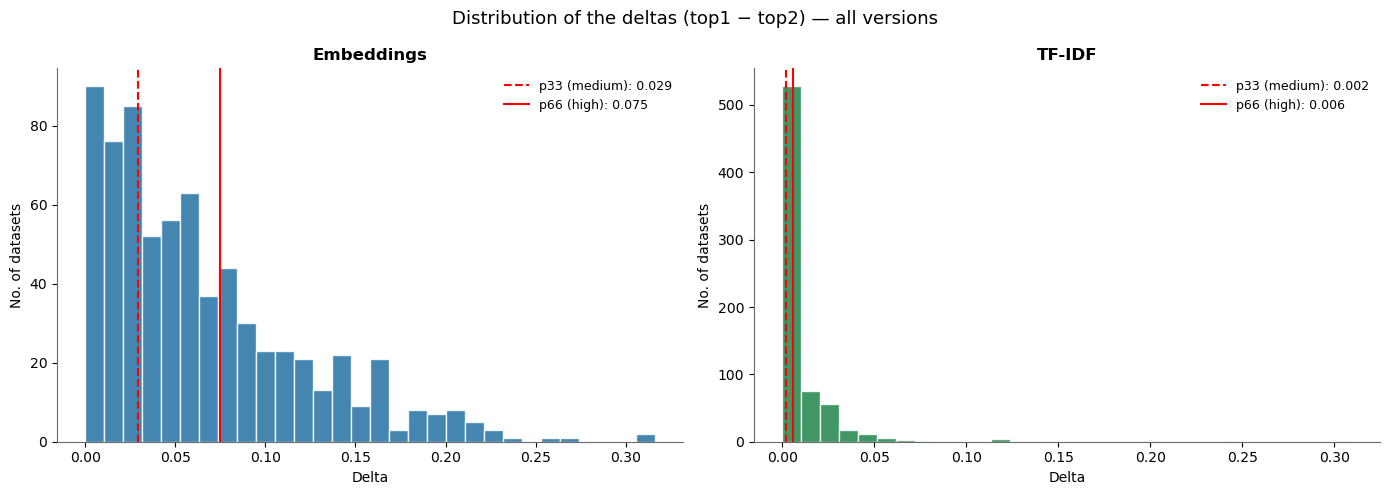

In [25]:
# ── Histogramas ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Distribution of the deltas (top1 − top2) — all versions", fontsize=13)

for ax, name_, arr, color in [
    (axes[0], "Embeddings", deltas_emb_all, "#2471A3"),
    (axes[1], "TF-IDF",     deltas_tfidf_all, "#1E8449"),
]:
    ax.hist(arr, bins=30, color=color, alpha=0.85, edgecolor="white")
    for p, label, ls in [
        (np.percentile(arr, 33), "p33 (medium)", "--"),
        (np.percentile(arr, 66), "p66 (high)",  "-"),
    ]:
        ax.axvline(p, color="red", linestyle=ls, linewidth=1.5, label=f"{label}: {p:.3f}")
    ax.set_title(name_)
    ax.set_xlabel("Delta")
    ax.set_ylabel("No. of datasets")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


**Analysis of the results (6 — Distribution of the deltas).**

The deltas of the two methods live on completely different scales. In the Embeddings, the median is 0.052 and 90% of the values lie below 0.146, with a long tail that reaches 0.316. In TF-IDF, the median is only 0.0034 and the distribution is concentrated near zero, with few clearly separated cases.

The histograms make the skewness of the two distributions visible and show that the 33rd and 66th percentiles fall in very different zones of each one. Hence the need to compute the thresholds separately for each method: an absolute value that was «high» for TF-IDF would be irrelevant in the Embeddings.

In [26]:
# ── Table by version ──────────────────────────────────────────────────────────
print("\nDetail by anchor version:")
rows = []
for version, obj in results_by_version.items():
    res = obj["results"]
    lim = obj["thresholds"]
    for method, col_delta in [("Embeddings", "delta_embeddings"), ("TF-IDF", "delta_tfidf")]:
        if method == "TF-IDF":
            # The classification defines the TF-IDF percentiles only among cases
            # with lexical overlap and a valid dimension. The diagnostic uses
            # exactly the same population so as to be directly comparable.
            mask = res["dimension_tfidf"].notna() & np.isfinite(res[col_delta])
        else:
            mask = np.isfinite(res[col_delta])
        arr = res.loc[mask, col_delta].to_numpy(dtype=float)
        if arr.size == 0:
            raise ValueError(f"No valid deltas for {method} — {version}.")
        rows.append({
            "version"            : version,
            "method"            : method,
            "n_valid_percentiles": int(arr.size),
            "min"               : round(float(arr.min()), 4),
            "p33"               : round(float(np.percentile(arr, 33)), 4),
            "median"           : round(float(np.percentile(arr, 50)), 4),
            "p66"               : round(float(np.percentile(arr, 66)), 4),
            "max"               : round(float(arr.max()), 4),
            "high_threshold_used" : round(lim["emb_high" if method == "Embeddings" else "tfidf_high"], 4),
            "medium_threshold_used"  : round(lim["emb_medium" if method == "Embeddings" else "tfidf_medium"], 4),
        })

percentile_detail_df = pd.DataFrame(rows).set_index(["version", "method"])
display(percentile_detail_df)
print("\nThe thresholds are computed automatically by method and version.")
print("In TF-IDF, the percentiles exclude cases without lexical overlap, as in the classification.")



Detail by anchor version:


n_valid_percentiles     min     p33  median     p66  \
version   method                                                            
original  Embeddings                  176  0.0002  0.0247  0.0414  0.0669   
          TF-IDF                      169  0.0003  0.0033  0.0047  0.0057   
50_words  Embeddings                  176  0.0007  0.0282  0.0461  0.0652   
          TF-IDF                      158  0.0000  0.0027  0.0041  0.0087   
100_words Embeddings                  176  0.0006  0.0297  0.0523  0.0689   
          TF-IDF                      161  0.0001  0.0021  0.0029  0.0047   
150_words Embeddings                  176  0.0002  0.0443  0.0679  0.0872   
          TF-IDF                      162  0.0001  0.0023  0.0038  0.0091   

                         max  high_threshold_used  medium_threshold_used  
version   method                                                          
original  Embeddings  0.2708               0.0669                 0.0247  
          TF-IDF      0.2051               0.0057                 0.0033  
50_words  Embeddings  0.2020               0.0652                 0.0282  
          TF-IDF      0.2467               0.0087                 0.0027  
100_words Embeddings  0.2619               0.0689                 0.0297  
          TF-IDF      0.1194               0.0047                 0.0021  
150_words Embeddings  0.3160               0.0872                 0.0443  
          TF-IDF      0.3095               0.0091                 0.0023


The thresholds are computed automatically by method and version.
In TF-IDF, the percentiles exclude cases without lexical overlap, as in the classification.


**Analysis of the results (6 — Variation of the adaptive thresholds across versions).**

This table reveals an additional layer of instability that is not immediately visible in the analyses
of agreement and stability in Section 7: **the very thresholds that define "high confidence" and
"medium confidence" vary substantially across anchor versions**, because they are computed
adaptively (33rd/66th percentiles) over the distribution of deltas observed in each version
individually (see Section 2.3).

Specifically, for TF-IDF, the "high" confidence threshold (`high_threshold_used`) varies between **0.0047**
("100_words") and **0.0091** ("150_words") — almost double; in the "original" version it is **0.0057**. This means that a dataset with
delta=0.007 would be classified as "high confidence" in the "original" version, but only "medium confidence"
in the "150_words" version, WITHOUT the dataset or its absolute score having changed
— only because the yardstick (the reference distribution) is different in each version.

This observation has two methodological implications:
1. **It justifies and reinforces the choice of adaptive percentile thresholds** instead of arbitrary fixed
   thresholds — using a fixed absolute value (e.g. "delta > 0.01 = high confidence") would be even more
   unstable and dependent on the score scale of each specific version, which, as seen in Section 7.7,
   can vary considerably.
2. **It adds an extra layer to the instability limitation already identified** (Section 8): it is not only the
   assigned dimension that can change between versions — the qualitative interpretation itself of "how
   confident" a classification is is also relative to the version used, not an absolute property of the
   dataset-dimension pair. Direct comparisons of "% high confidence" between versions should therefore be
   avoided, as if they were measured on the same absolute scale — which, in practice, they are not.

In [27]:
# ── 1. Collect zeros by version ───────────────────────────────────────────────

print("=" * 70)
print("DIAGNOSTIC: Datasets with maximum TF-IDF score = 0")
print("=" * 70)

zeros_summary = []

for version, obj in results_by_version.items():
    res        = obj["results"].copy()
    scores_tf  = obj["scores_tfidf"]          # DataFrame: datasets × dimensions

    # Maximum TF-IDF score for each dataset (row)
    max_score = scores_tf.max(axis=1).values
    res["max_score_tfidf"] = max_score

    n_total = len(res)
    n_zeros = (max_score == 0).sum()
    pct     = n_zeros / n_total * 100

    dims_spurious = res.loc[max_score == 0, "dimension_tfidf"].dropna()

    zeros_summary.append({
        "version": version,
        "total datasets": n_total,
        "scores = 0": n_zeros,
        "% affected": round(pct, 1),
        "TF-IDF dimension in the zero cases": (
            dims_spurious.value_counts().idxmax() if not dims_spurious.empty else "—"
        ),
    })

    print(f"\n  Version: {version}")
    print(f"    → {n_zeros}/{n_total} datasets ({pct:.1f}%) with max TF-IDF score = 0")

    if n_zeros > 0:
        # Which datasets are these?
        zeros_df = res.loc[max_score == 0,
                           ["dataset_id", "dataset_title",
                            "n_words_tfidf", "dimension_tfidf",
                            "dimension_embeddings"]].copy()
        zeros_df.columns = ["ID", "Name", "tokens (tfidf)", "TF-IDF dimension", "Emb dim"]
        print(zeros_df.to_string(index=False))

print("\n" + "=" * 70)
summary_df = pd.DataFrame(zeros_summary)
print("\nSummary by anchor version:")
print(summary_df.to_string(index=False))

DIAGNOSTIC: Datasets with maximum TF-IDF score = 0

  Version: original
    → 7/176 datasets (4.0%) with max TF-IDF score = 0
                                  ID                  Name  tokens (tfidf) TF-IDF dimension               Emb dim
0dde552a-675e-457d-abd2-0102221852ba               Coretos               3             None Smart Quality of Life
d0756937-25aa-4378-8719-7a9b9a400c86   Caminho de Santiago              14             None         Smart Economy
2be93726-75ce-42cc-92bb-32aadf7ed082      Cidade de Águeda               1             None         Smart Economy
dd7b4835-9b20-49c4-bc1b-b2155aabc073                Ramsar              12             None     Smart Environment
85e5d96c-340d-409d-b3b1-7ded8faec3d5            Papeleiras               3             None Smart Quality of Life
8b738bab-ea94-4a11-b3a3-c88c26d640a4 Paragens de autocarro               5             None        Smart Mobility
404ac1e9-4f13-492a-833a-81fbcf9bcf2d    Sinais de trânsito               5  

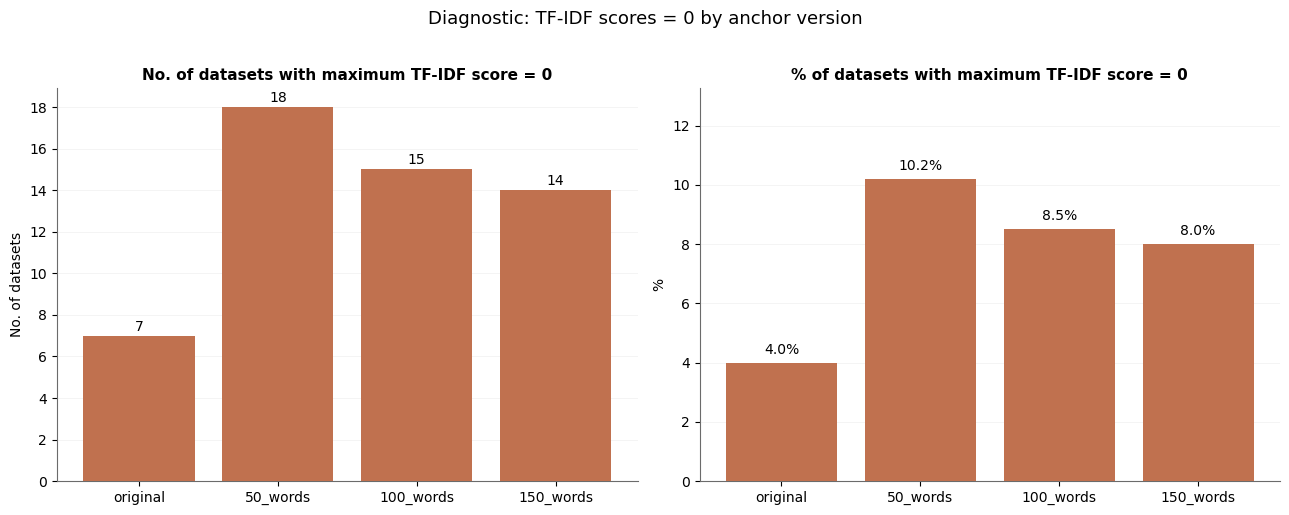

In [28]:
from matplotlib import ticker as mticker

# ── 4. Visualisation: zeros by version ────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Diagnostic: TF-IDF scores = 0 by anchor version", fontsize=13, y=1.02)

# 4a — Absolute count
ax1 = axes[0]
bars = ax1.bar(
    summary_df["version"],
    summary_df["scores = 0"],
    color=[HIGHLIGHT_COLOUR if v > 0 else NEUTRAL_COLOUR for v in summary_df["scores = 0"]],
    edgecolor="none",
    zorder=3,
)
ax1.set_title("No. of datasets with maximum TF-IDF score = 0", fontsize=11)
ax1.set_ylabel("No. of datasets")
ax1.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax1.grid(axis="y", linewidth=0.4, alpha=0.5, zorder=0)
ax1.set_axisbelow(True)
for bar, val in zip(bars, summary_df["scores = 0"]):
    if val > 0:
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
                 str(val), ha="center", va="bottom", fontsize=10)

# 4b — Percentage
ax2 = axes[1]
bars2 = ax2.bar(
    summary_df["version"],
    summary_df["% affected"],
    color=[HIGHLIGHT_COLOUR if v > 0 else NEUTRAL_COLOUR for v in summary_df["% affected"]],
    edgecolor="none",
    zorder=3,
)
ax2.set_title("% of datasets with maximum TF-IDF score = 0", fontsize=11)
ax2.set_ylabel("%")
ax2.set_ylim(0, max(summary_df["% affected"].max() * 1.3, 5))
ax2.grid(axis="y", linewidth=0.4, alpha=0.5, zorder=0)
ax2.set_axisbelow(True)
for bar, val in zip(bars2, summary_df["% affected"]):
    if val > 0:
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
                 f"{val:.1f}%", ha="center", va="bottom", fontsize=10)

format_x_labels(ax1); format_x_labels(ax2)
plt.tight_layout()
plt.show()


**Analysis of the results (6 — Datasets without a TF-IDF classification by version).**

The number of datasets without any lexical overlap with the anchors is small in the original version (7, or 4.0%) and rises in the rewritten versions, to 18 (10.2%) in the 50-word version, 15 (8.5%) in the 100-word version and 14 (8.0%) in the 150-word version. The cases of the original version are almost all very short texts after cleaning, such as «Coretos», «Papeleiras» or «Cidade de Águeda». In the rewritten versions they are joined by records such as «Farmácias», «Pistas Cicláveis» or «Percursos pedestres», whose vocabulary found an echo in the longer original anchors, but no longer finds one when these are condensed.

In Águeda, even so, TF-IDF coverage always remains above 89%, unlike what happens in Porto.

## 7. Analysis of the results

This section analyses the results produced by the classification from multiple angles. Each subsection answers a specific question:

- **7.1**: Which dimensions are assigned to each dataset, version by version?
- **7.2**: How much do the two methods agree? Is the agreement stable across versions?
- **7.3**: Does the classification change when the anchor version is changed?
- **7.4**: How are the classifications distributed across the 6 dimensions?
- **7.5**: How confident is the classification? How many datasets have a clear vs. uncertain classification?
- **7.6**: When the two methods disagree, which dimensions are confused?

### 7.1 Detailed results by version

For each anchor version, a table is presented with, for each dataset:
- The dimension assigned by Embeddings and by TF-IDF;
- The confidence level of each method;
- Whether the two methods agree.

This table is the most direct output of the analysis and serves as a reference for the manual review of doubtful cases.


In [29]:
for version_name, obj in results_by_version.items():
    print("=" * 100)
    print(f"Results: {version_name}")
    print("=" * 100)
    display(
        obj["results"][[
            "dataset_id","dataset_title",
            "dimension_embeddings","confidence_embeddings",
            "dimension_tfidf","confidence_tfidf",
            "methods_agree"
        ]].head(10)
    )

Results: original


,dataset_id,dataset_title,dimension_embeddings,confidence_embeddings,dimension_tfidf,confidence_tfidf,methods_agree
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,Smart Quality of Life,low,Smart Quality of Life,medium,True
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,Smart Environment,high,Smart Environment,high,True
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,Smart Mobility,high,Smart Mobility,low,True
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,Smart Mobility,high,Smart Mobility,high,True
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,Smart Environment,high,Smart Governance,high,False
5,f5350303-a076-4726-acc8-014af2d44f0d,CAOP - Troço 7539,Smart Society,medium,Smart Economy,low,False
6,0769801f-9d0f-462d-97e1-e6d8a7e8f87c,Antendimentos no Posto de Turismo de Águeda,Smart Quality of Life,low,Smart Economy,high,False
7,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,Smart Environment,medium,Smart Quality of Life,low,False
8,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,Smart Environment,low,Smart Quality of Life,medium,False
9,35ef0ccc-ffcf-4bec-86ea-f390b52d69bc,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,Smart Environment,low,Smart Quality of Life,medium,False


Results: 50_words


,dataset_id,dataset_title,dimension_embeddings,confidence_embeddings,dimension_tfidf,confidence_tfidf,methods_agree
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,Smart Environment,high,Smart Society,medium,False
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,Smart Environment,high,Smart Environment,high,True
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,Smart Environment,low,Smart Mobility,medium,False
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,Smart Mobility,high,Smart Mobility,high,True
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,Smart Environment,medium,Smart Governance,medium,False
5,f5350303-a076-4726-acc8-014af2d44f0d,CAOP - Troço 7539,Smart Governance,high,Smart Economy,high,False
6,0769801f-9d0f-462d-97e1-e6d8a7e8f87c,Antendimentos no Posto de Turismo de Águeda,Smart Governance,low,Smart Governance,medium,True
7,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,Smart Governance,medium,Smart Quality of Life,high,False
8,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,Smart Governance,medium,Smart Quality of Life,high,False
9,35ef0ccc-ffcf-4bec-86ea-f390b52d69bc,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,Smart Governance,medium,Smart Quality of Life,high,False


Results: 100_words


,dataset_id,dataset_title,dimension_embeddings,confidence_embeddings,dimension_tfidf,confidence_tfidf,methods_agree
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,Smart Quality of Life,medium,Smart Economy,high,False
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,Smart Environment,high,Smart Environment,high,True
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,Smart Mobility,high,Smart Mobility,medium,True
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,Smart Mobility,high,Smart Mobility,high,True
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,Smart Society,low,Smart Governance,medium,False
5,f5350303-a076-4726-acc8-014af2d44f0d,CAOP - Troço 7539,Smart Quality of Life,low,Smart Governance,medium,False
6,0769801f-9d0f-462d-97e1-e6d8a7e8f87c,Antendimentos no Posto de Turismo de Águeda,Smart Economy,low,Smart Governance,medium,False
7,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,Smart Quality of Life,medium,Smart Environment,medium,False
8,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,Smart Quality of Life,medium,Smart Environment,low,False
9,35ef0ccc-ffcf-4bec-86ea-f390b52d69bc,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,Smart Quality of Life,high,Smart Mobility,low,False


Results: 150_words


,dataset_id,dataset_title,dimension_embeddings,confidence_embeddings,dimension_tfidf,confidence_tfidf,methods_agree
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,Smart Environment,low,Smart Society,low,False
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,Smart Environment,medium,Smart Environment,high,True
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,Smart Mobility,high,Smart Mobility,medium,True
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,Smart Mobility,high,Smart Mobility,high,True
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,Smart Environment,low,Smart Governance,medium,False
5,f5350303-a076-4726-acc8-014af2d44f0d,CAOP - Troço 7539,Smart Governance,high,Smart Economy,medium,False
6,0769801f-9d0f-462d-97e1-e6d8a7e8f87c,Antendimentos no Posto de Turismo de Águeda,Smart Society,medium,Smart Economy,high,False
7,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,Smart Environment,medium,Smart Quality of Life,medium,False
8,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,Smart Environment,medium,Smart Quality of Life,medium,False
9,35ef0ccc-ffcf-4bec-86ea-f390b52d69bc,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,Smart Environment,medium,Smart Quality of Life,medium,False


**Analysis of the results (7.1 — Detailed results by version).**

The first rows already show that the disagreement between methods is not random. In «Estação hidrométrica de Alhandra», for example, the Embeddings indicate Smart Environment and TF-IDF Smart Governance, both with the «high» band in the original version, which shows that the methods can diverge even when each one has a relatively high margin on its own scale. «Ponto de carregamento de veículos elétricos» illustrates the opposite situation: the vocabulary and the meaning clearly point to the same dimension, and the two methods converge on Smart Mobility, with the «high» band, in all four versions. These examples are only illustrative; agreement and disagreement are quantified in aggregate form in the following cells.

**Illustrative case of instability: «Áreas de Reabilitação Urbana - ARU 2023».**

This dataset clearly shows the type of record that feeds instability between versions. In the Embeddings, the predominant dimension alternates between Quality of Life (original and 100-word versions) and Environment (50 and 150 words), always with scores close to 0.5. In TF-IDF, it receives a different dimension in almost every version: Quality of Life (original), Society (50 words), Economy (100 words) and Society again (150 words). The two methods only coincide in the original version. The description («Revisão de Delimitação das Áreas de Reabilitação Urbana...») is thematically broad, touching at the same time on land use, social regeneration and economic impact, and it has no dominant vocabulary that ties it to a single dimension. It is therefore an example for consulting the score profile and the candidate dimensions before interpreting the single label; it also helps to understand the instability rate of TF-IDF (40.5% of the 158 datasets valid in all four versions, Section 8).

### 7.2 Quantitative summary by version

The following metrics describe internal properties of the classification. Agreement and Kappa are computed only on the datasets classified by both methods; TF-IDF coverage is reported separately to make the denominator explicit. The correlation of the top-1 scores is presented as a diagnostic of the association between scales, not as a measure of agreement on the dimensions.

,anchor_version,n_datasets,n_valid_both_methods,n_zero_tfidf,tfidf_coverage_%,agreement_valid_%,cohen_kappa_valid,pearson_scores_top1,p_pearson,spearman_scores_top1,p_spearman,mean_delta_embeddings,mean_delta_tfidf_valid,pct_high_band_emb_total,pct_high_band_tfidf_total,pct_high_band_tfidf_valid
0,original,176,169,7,96.022727,39.053254,0.215866,0.472879,8.474510e-11,0.490739,1.258605e-11,0.062830,0.010707,34.090909,32.954545,34.319527
1,50_words,176,158,18,89.772727,25.949367,0.044404,0.367137,2.085402e-06,0.626432,1.333134e-18,0.053367,0.012059,34.090909,30.681818,34.177215
2,100_words,176,161,15,91.477273,45.341615,0.279202,0.423023,2.264821e-08,0.460717,7.763610e-10,0.066449,0.008922,34.090909,31.250000,34.161491
3,150_words,176,162,14,92.045455,45.679012,0.270382,0.380278,5.991557e-07,0.523835,8.488149e-13,0.078967,0.011296,34.090909,31.250000,33.950617


Note: the delta bands are percentile-based and relative; the proportion in the high band
is not an estimate of accuracy. Agreement and Kappa use only valid cases.


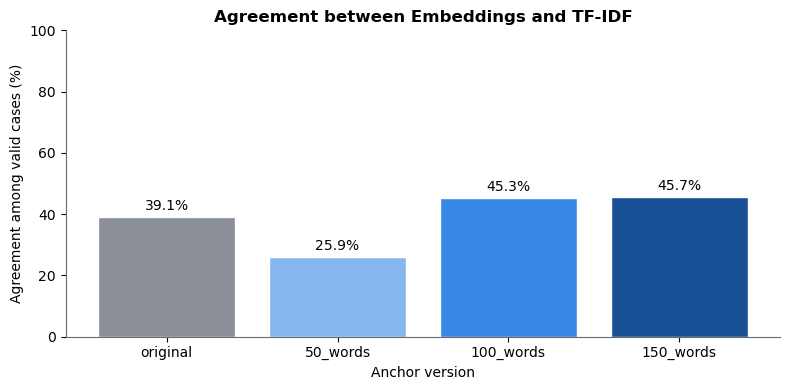

In [30]:
version_summary = []

for version_name, obj in results_by_version.items():
    res = obj["results"]
    mask_valid = res["dimension_embeddings"].notna() & res["dimension_tfidf"].notna()
    rv = res.loc[mask_valid].copy()
    n_valid = len(rv)

    agreement = rv["methods_agree"].mean() if n_valid else np.nan
    kappa = (cohen_kappa_score(rv["dimension_embeddings"], rv["dimension_tfidf"])
             if n_valid > 1 else np.nan)
    if n_valid > 2:
        pearson_r, pearson_p = pearsonr(rv["score_top1_embeddings"], rv["score_top1_tfidf"])
        spearman_r, spearman_p = spearmanr(rv["score_top1_embeddings"], rv["score_top1_tfidf"])
    else:
        pearson_r = pearson_p = spearman_r = spearman_p = np.nan

    n_tfidf_valid = int(res["dimension_tfidf"].notna().sum())
    version_summary.append({
        "anchor_version": version_name,
        "n_datasets": len(res),
        "n_valid_both_methods": n_valid,
        "n_zero_tfidf": len(res) - n_tfidf_valid,
        "tfidf_coverage_%": n_tfidf_valid / len(res) * 100,
        "agreement_valid_%": agreement * 100 if pd.notna(agreement) else np.nan,
        "cohen_kappa_valid": kappa,
        "pearson_scores_top1": pearson_r,
        "p_pearson": pearson_p,
        "spearman_scores_top1": spearman_r,
        "p_spearman": spearman_p,
        "mean_delta_embeddings": res["delta_embeddings"].mean(),
        "mean_delta_tfidf_valid": res.loc[res["dimension_tfidf"].notna(), "delta_tfidf"].mean(),
        "pct_high_band_emb_total": (res["confidence_embeddings"] == "high").mean() * 100,
        "pct_high_band_tfidf_total": (res["confidence_tfidf"] == "high").mean() * 100,
        "pct_high_band_tfidf_valid": (
            (res.loc[res["dimension_tfidf"].notna(), "confidence_tfidf"] == "high").mean() * 100
            if n_tfidf_valid else np.nan
        ),
    })

version_summary = pd.DataFrame(version_summary)
display(version_summary)
print("Note: the delta bands are percentile-based and relative; the proportion in the high band")
print("is not an estimate of accuracy. Agreement and Kappa use only valid cases.")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(version_summary["anchor_version"], version_summary["agreement_valid_%"],
              color=[VERSION_COLOURS.get(v, NEUTRAL_COLOUR) for v in version_summary["anchor_version"]], edgecolor="white")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, 100)
ax.set_xlabel("Anchor version")
ax.set_ylabel("Agreement among valid cases (%)")
ax.set_title("Agreement between Embeddings and TF-IDF")
format_x_labels(ax)
plt.tight_layout(); plt.show()

**Analysis of the results (7.2 — Summary by version).**

Agreement between methods on the valid cases is 39.1% in the original version, falls to 25.9% in the 50-word version and rises to about 45% in the 100-word and 150-word versions. Kappa follows this pattern: it is «fair» in the original, 100-word and 150-word versions (0.216 to 0.279) and only «slight» in the 50-word version (0.044). The 50-word version is thus the one in which the two methods diverge most, which is noteworthy, as it is also the only one whose anchors fit entirely within the model limit.

The Spearman correlation between the maximum scores is moderate (0.46 to 0.63), which indicates that the methods only partly rank the datasets in the same way. The percentages in the «high» band (about 34%) are practically constant by construction and say nothing about the quality of each version.

**Rigorous interpretation of the summary by version.**

The table compares agreement, Kappa, lexical coverage and deltas. The metrics do not establish which method is correct: they only measure the relationship between two automatic classifications without *ground truth*. Agreement and Kappa should be read together with `n_valid_both_methods`, while TF-IDF coverage should be analysed separately. Pearson and Spearman compare the top-1 scores on different scales and do not measure categorical agreement. The percentages in the high band are largely determined by the percentiles used to build the bands.

### 7.3 Stability across anchor versions

This analysis answers the question: **does the dimension assigned to a dataset change when the anchor version changes?**

#### Pairwise comparison

For each pair of anchor versions (e.g. "original" vs "50 words", "50 words" vs "100 words"), the percentage of datasets with the same dimension and Cohen's kappa are computed. This makes it possible to see:
- Whether the longer versions produce results more similar to each other than the shorter ones (indicating a stabilisation of the classifications as the detail of the anchors increases);
- Which pairs of versions are the most and the least similar.

#### Stability matrices

The stability matrices show, for each pair of versions, the percentage of agreement. They are computed separately for Embeddings and TF-IDF, which makes it possible to check which of the two methods is more sensitive to variations in the anchors.

High stability indicates that the assigned dimension is not very sensitive to the wording of the anchors tested. It does not, by itself, show that the assigned dimension is the adequate one: two versions may coincide because they share the same lexical bias.


In [31]:
# ── Pairwise comparison with explicit alignment by dataset_id ────────────────
pairwise_comparison = []
for v1, v2 in combinations(ANCHOR_FILES.keys(), 2):
    cols = ["dataset_id", "dimension_embeddings", "dimension_tfidf"]
    r1 = results_by_version[v1]["results"][cols]
    r2 = results_by_version[v2]["results"][cols]
    pair_ = r1.merge(r2, on="dataset_id", how="inner", suffixes=("_v1", "_v2"), validate="one_to_one")
    if len(pair_) != len(datasets):
        raise ValueError(f"Incomplete alignment between {v1} and {v2}: {len(pair_)}/{len(datasets)}")

    mask_emb = pair_["dimension_embeddings_v1"].notna() & pair_["dimension_embeddings_v2"].notna()
    mask_tf = pair_["dimension_tfidf_v1"].notna() & pair_["dimension_tfidf_v2"].notna()
    e1, e2 = pair_.loc[mask_emb, "dimension_embeddings_v1"], pair_.loc[mask_emb, "dimension_embeddings_v2"]
    t1, t2 = pair_.loc[mask_tf, "dimension_tfidf_v1"], pair_.loc[mask_tf, "dimension_tfidf_v2"]

    pairwise_comparison.append({
        "version_1": v1, "version_2": v2,
        "n_valid_emb": int(mask_emb.sum()),
        "agreement_emb_%": (e1.to_numpy() == e2.to_numpy()).mean() * 100 if len(e1) else np.nan,
        "kappa_emb": cohen_kappa_score(e1, e2) if len(e1) > 1 else np.nan,
        "n_valid_tfidf_both": int(mask_tf.sum()),
        "agreement_tfidf_valid_%": (t1.to_numpy() == t2.to_numpy()).mean() * 100 if len(t1) else np.nan,
        "kappa_tfidf_valid": cohen_kappa_score(t1, t2) if len(t1) > 1 else np.nan,
        "agreement_tfidf_coverage_%": (
            pair_["dimension_tfidf_v1"].notna().to_numpy() == pair_["dimension_tfidf_v2"].notna().to_numpy()
        ).mean() * 100,
        "agreement_tfidf_incl_zero_%": (
            pair_["dimension_tfidf_v1"].fillna("Unclassified").to_numpy()
            == pair_["dimension_tfidf_v2"].fillna("Unclassified").to_numpy()
        ).mean() * 100,
    })

pairwise_comparison_df = pd.DataFrame(pairwise_comparison)
display(pairwise_comparison_df)

,version_1,version_2,n_valid_emb,agreement_emb_%,kappa_emb,n_valid_tfidf_both,agreement_tfidf_valid_%,kappa_tfidf_valid,agreement_tfidf_coverage_%,agreement_tfidf_incl_zero_%
0,original,50_words,176,44.886364,0.291207,158,68.987342,0.597337,93.750000,65.909091
1,original,100_words,176,67.045455,0.539017,161,78.260870,0.710937,95.454545,75.568182
2,original,150_words,176,67.045455,0.541255,162,85.185185,0.804770,96.022727,82.386364
3,50_words,100_words,176,47.727273,0.324911,158,67.721519,0.583264,98.295455,69.318182
4,50_words,150_words,176,62.500000,0.479640,158,72.151899,0.638030,97.727273,72.727273
5,100_words,150_words,176,65.340909,0.513416,159,83.018868,0.771879,97.159091,81.818182


**Analysis of the results (7.3 — Pairwise comparison between versions).**

In the Embeddings, no pair of versions reaches 70% agreement. The most stable pairs are original-150 (67.0%, κ = 0.541) and original-100 (67.0%, κ = 0.539), and the least stable always involve the 50-word version, with the minimum at original-50 (44.9%, κ = 0.291). Changing the anchor version therefore changes the predominant dimension of between a third and more than half of the datasets.

TF-IDF is more stable across versions, with agreement between 67.7% and 85.2% on the valid cases and kappas between 0.58 and 0.80. Its coverage is also maintained: in more than 93% of the datasets, the state (classified or null) is the same in the two versions compared.

**Rigorous interpretation of the comparison between versions.**

The agreement and Kappa of the TF-IDF labels are computed on the cases classified in both versions. The stability of coverage (`classified` versus `Unclassified`) and the agreement including the null category are presented separately. This prevents a persistent absence of lexical overlap from being mistaken for dimensional stability. The four versions are related conditions — they share the same datasets, methods and conceptual framework — and do not constitute independent replications.

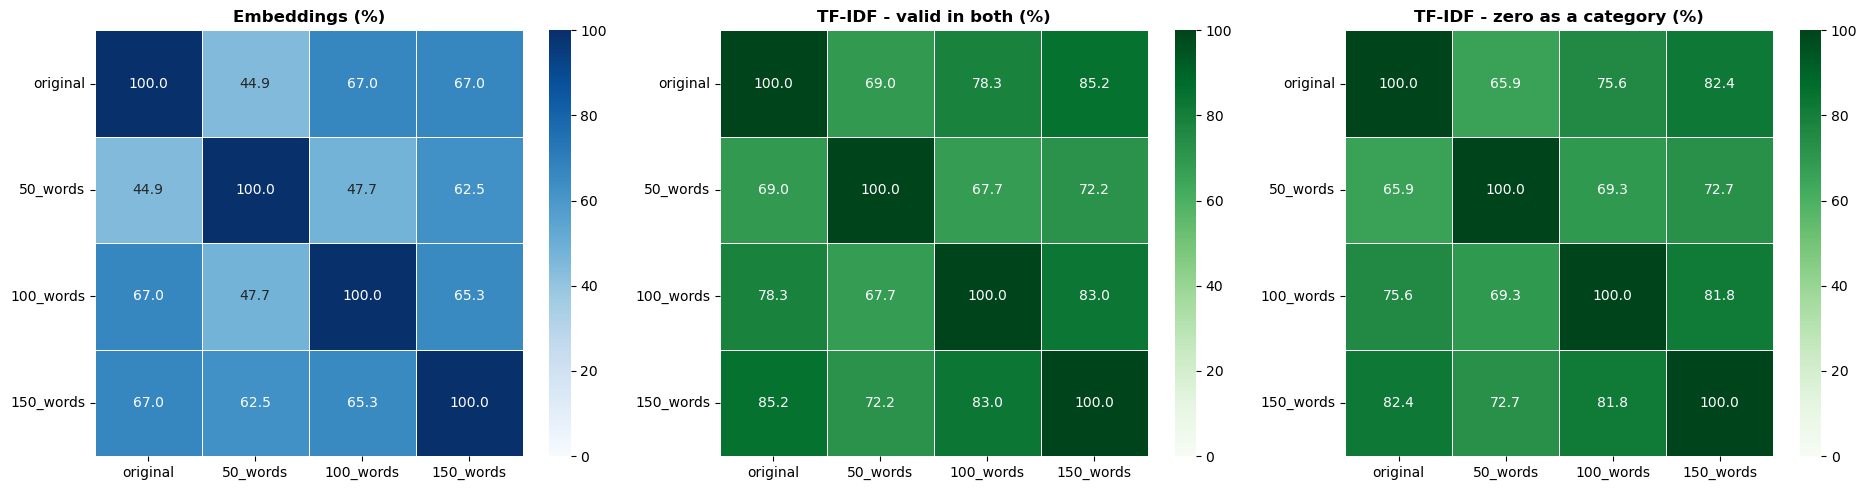

In [32]:
# ── Stability matrices between versions ──────────────────────────────────────
def stability_matrix(method: str, include_zero: bool = False) -> pd.DataFrame:
    """Percentage agreement between versions, with alignment by dataset_id."""
    mapping = {"embeddings": "dimension_embeddings", "tfidf": "dimension_tfidf"}
    if method not in mapping:
        raise ValueError(f"Invalid method: {method!r}. Use 'embeddings' or 'tfidf'.")
    col = mapping[method]
    versions = list(results_by_version)
    matrix = pd.DataFrame(index=versions, columns=versions, dtype=float)
    for v1 in versions:
        for v2 in versions:
            a = results_by_version[v1]["results"][["dataset_id", col]]
            b = results_by_version[v2]["results"][["dataset_id", col]]
            pair_ = a.merge(b, on="dataset_id", suffixes=("_1", "_2"), validate="one_to_one")
            x, y = pair_[f"{col}_1"], pair_[f"{col}_2"]
            if include_zero:
                x, y = x.fillna("Unclassified"), y.fillna("Unclassified")
                mask = pd.Series(True, index=pair_.index)
            else:
                mask = x.notna() & y.notna()
            matrix.loc[v1, v2] = (x[mask].to_numpy() == y[mask].to_numpy()).mean() * 100 if mask.any() else np.nan
    return matrix

stability_embeddings = stability_matrix("embeddings")
stability_tfidf_valid = stability_matrix("tfidf", include_zero=False)
stability_tfidf_with_zero = stability_matrix("tfidf", include_zero=True)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, mat, title_text, cmap in [
    (axes[0], stability_embeddings, "Embeddings", CMAP_EMB),
    (axes[1], stability_tfidf_valid, "TF-IDF - valid in both", CMAP_TFIDF),
    (axes[2], stability_tfidf_with_zero, "TF-IDF - zero as a category", CMAP_TFIDF),
]:
    sns.heatmap(mat, annot=True, fmt=".1f", cmap=cmap, vmin=0, vmax=100, ax=ax, linewidths=.5)
    ax.set_title(title_text + " (%)")
    format_x_labels(ax); horizontal_y_labels(ax)
plt.tight_layout(); plt.show()

#### Figure 4.5 (dissertation) — Agreement between anchor versions, by method

Section 4.4 (RQ3). Print version of the three matrices above (embeddings; TF-IDF with cases valid in both versions; TF-IDF with zero as a category). The versions appear abbreviated (Orig., 50, 100, 150 words) and the titles take up two lines. Panel a) Águeda, b) Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_5_a_version_agreement.png


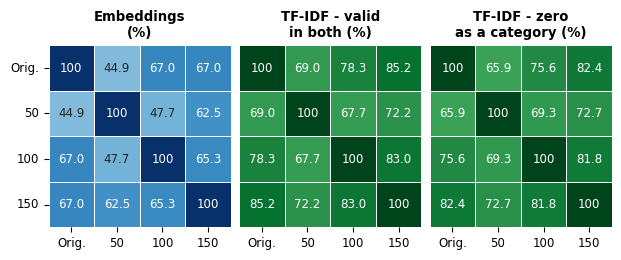

In [33]:
# ── Figure 4.5 (dissertation): agreement between versions ────────────────────
abbrev = {"original": "Orig.", "50_words": "50", "100_words": "100", "150_words": "150"}
with plt.rc_context(DISS_FONT):
    # square cells and version labels only on the first panel (the three matrices have the same rows)
    fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, 2.6), sharey=True, layout="constrained")
    for ax, mat, title_text, cmap in [
        (axes[0], stability_embeddings, "Embeddings\n(%)", CMAP_EMB),
        (axes[1], stability_tfidf_valid, "TF-IDF - valid\nin both (%)", CMAP_TFIDF),
        (axes[2], stability_tfidf_with_zero, "TF-IDF - zero\nas a category (%)", CMAP_TFIDF),
    ]:
        m = mat.rename(index=abbrev, columns=abbrev)
        labels_list = np.array([[num(f"{v:.1f}") for v in row_data] for row_data in m.values], dtype=object)
        np.fill_diagonal(labels_list, "100")                 # "100.0" did not fit in the cell
        sns.heatmap(m, annot=labels_list, fmt="", cmap=cmap, vmin=0, vmax=100, ax=ax, linewidths=.5,
                    cbar=False, square=True, annot_kws={"fontsize": 8.5})
        ax.set_title(title_text)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=0); horizontal_y_labels(ax)
        ax.set_xlabel(""); ax.set_ylabel("")
    for ax in axes[1:]:
        ax.tick_params(axis="y", left=False, labelleft=False)
    export_diss_figure(fig, "4.5", "version_agreement")


**Analysis of the results (7.3 — Stability matrices between versions).**

The matrices visually translate the previous table. In the Embeddings, the off-diagonal cells are clearly lighter than in TF-IDF, especially in the row and column of the 50-word version, which stands out as the furthest from the others. In TF-IDF, the reading that treats «unclassified» as a category gives slightly lower values than the one that considers only the valid cases, because it also counts the transitions between classified and null.

**Rigorous interpretation of the matrices.**

The matrices quantify sensitivity to the versions tested, not accuracy. For TF-IDF, two readings are presented: dimensional agreement only on the cases valid in both versions, and overall agreement treating `Unclassified` as a category. The comparison should also consider the denominators and coverage. No universal 80% threshold is assumed, nor a monotonic relationship between the length of the anchors and stability.

### 7.4 Distribution of the classifications by method and version

This analysis shows how many datasets were assigned to each Smart City dimension, separately for each method and anchor version.

#### What we are trying to identify

**Balanced distributions** (each dimension receives a similar number of datasets) are compatible with anchors distinct enough to distribute the datasets across the 6 dimensions; balance is not, however, an objective in itself, because the portal may genuinely have more datasets in some dimensions.

**Excessive concentration** in one or two dimensions may indicate:
- Poorly discriminative anchors: one dimension is worded in a very generic way and "attracts" datasets from other dimensions;
- A real imbalance in the data: the municipality does have more datasets in a given dimension (e.g. much more Environment data than Governance data);
- Problems in the pre-processing: terms specific to one dimension dominate the TF-IDF vocabulary.

The comparison between Embeddings and TF-IDF in this distribution is revealing: if TF-IDF concentrates much more than the Embeddings, this suggests that the lexical representation is being dominated by terms from one or two dimensions, while the semantic representation distributes them in a more balanced way.


Distribution — Embeddings (each column sums to the total n):


anchor_version,original,50_words,100_words,150_words
dimension_embeddings,,,,
Smart Governance,11,66,22,36
Smart Society,7,1,6,12
Smart Mobility,79,55,89,85
Smart Environment,38,42,9,37
Smart Quality of Life,28,4,35,3
Smart Economy,13,8,15,3


Distribution — TF-IDF, including unclassified:


anchor_version,original,50_words,100_words,150_words
dimension_tfidf,,,,
Smart Governance,48,36,56,54
Smart Society,6,5,4,8
Smart Mobility,53,52,55,51
Smart Environment,24,17,28,19
Smart Quality of Life,27,40,7,22
Smart Economy,11,8,11,8
Unclassified,7,18,15,14


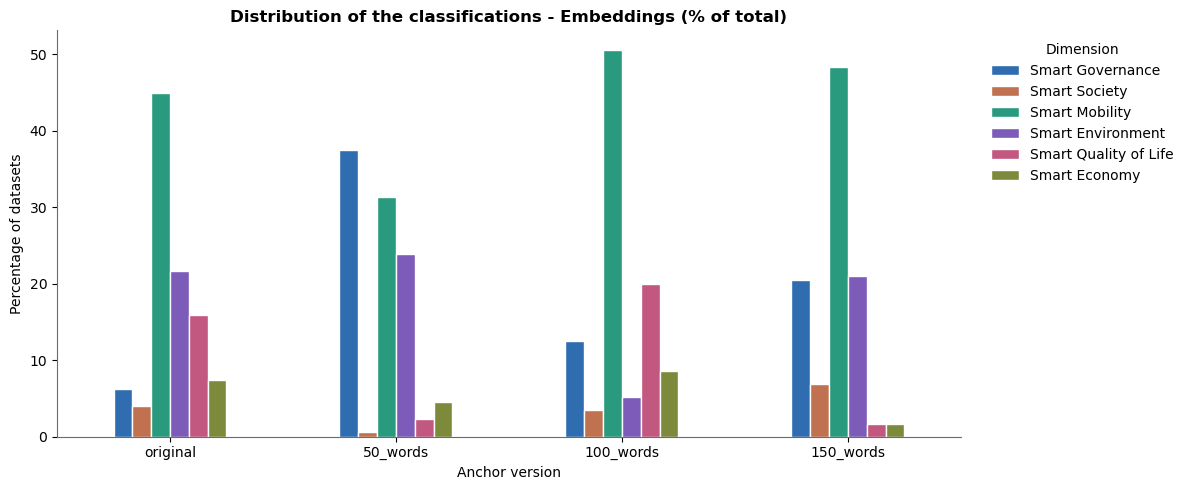

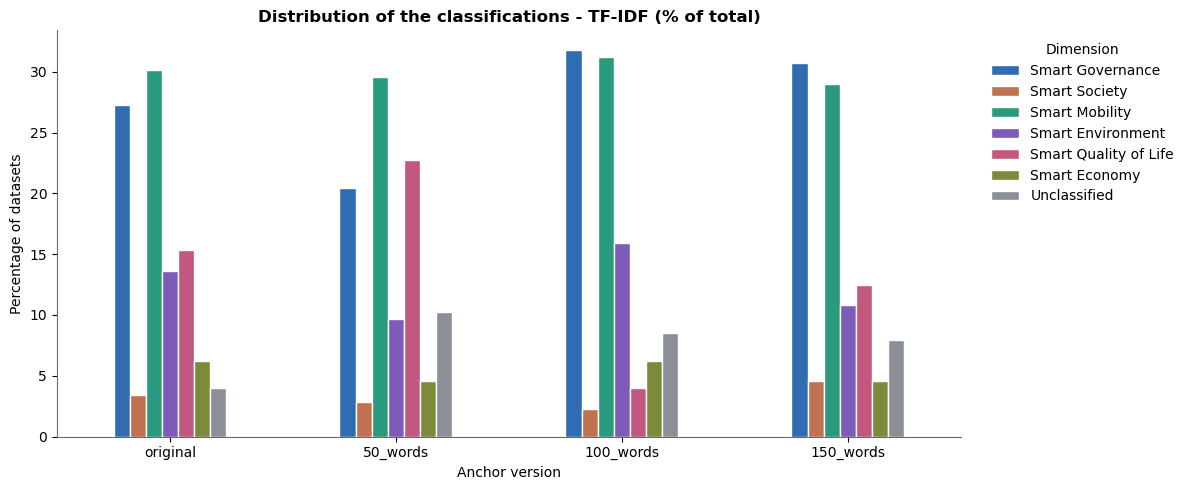

In [34]:
# ── Full distributions, including the absence of a TF-IDF classification ─────
VERSION_ORDER = list(ANCHOR_FILES.keys())
DIMENSION_ORDER = list(next(iter(results_by_version.values()))["scores_embeddings"].columns)

def distribution_table(column_name, include_zero=False):
    df = results_all_versions[["anchor_version", column_name]].copy()
    if include_zero:
        df[column_name] = df[column_name].fillna("Unclassified")
        order = DIMENSION_ORDER + ["Unclassified"]
    else:
        order = DIMENSION_ORDER
    tab = pd.crosstab(df[column_name], df["anchor_version"]).reindex(index=order, columns=VERSION_ORDER, fill_value=0)
    return tab.astype(int)

distribution_emb = distribution_table("dimension_embeddings")
distribution_tfidf = distribution_table("dimension_tfidf", include_zero=True)
print("Distribution — Embeddings (each column sums to the total n):"); display(distribution_emb)
print("Distribution — TF-IDF, including unclassified:"); display(distribution_tfidf)

for table, title_text in [(distribution_emb, "Embeddings"), (distribution_tfidf, "TF-IDF")]:
    dist_pct = table.div(table.sum(axis=0), axis=1).T * 100
    dist_colours = [NEUTRAL_COLOUR if c == "Unclassified" else CATEGORICAL_PALETTE[DIMENSION_ORDER.index(c) % len(CATEGORICAL_PALETTE)]
                  for c in dist_pct.columns]
    ax = dist_pct.plot(kind="bar", figsize=(12, 5), edgecolor="white", color=dist_colours)
    ax.set_title(f"Distribution of the classifications - {title_text} (% of total)")
    ax.set_xlabel("Anchor version"); ax.set_ylabel("Percentage of datasets")
    ax.legend(title="Dimension", bbox_to_anchor=(1.02, 1), loc="upper left")
    format_x_labels(ax)
    plt.tight_layout(); plt.show()

#### Figures 4.2 and 4.3 (dissertation) — Distribution of the classifications by dimension and anchor version

Section 4.2 (RQ1). Print version of the two bar charts above (a) embeddings; b) TF-IDF, including the unclassified records). The legend of the dimensions moves below the chart, in three columns, so that the chart takes up the full width (the “constrained” layout reserves the space needed for the legend). Figure 4.2 in Águeda, Figure 4.3 in Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_2_a_distribution_embeddings.png


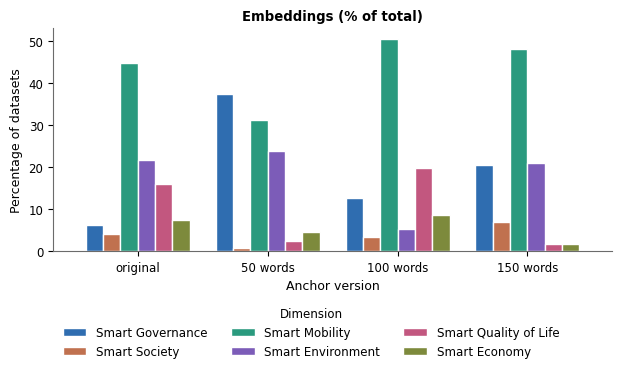

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_2_b_distribution_tfidf.png


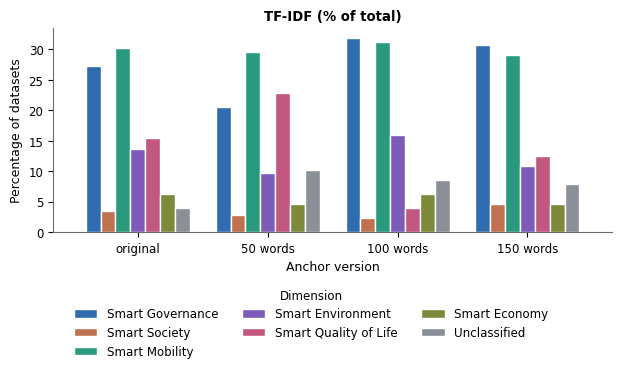

In [35]:
# ── Figures 4.2/4.3 (dissertation): distribution of the classifications ──────
for key_name, table, title_text, name_ in [("4.2a", distribution_emb, "Embeddings", "distribution_embeddings"),
                                    ("4.2b", distribution_tfidf, "TF-IDF", "distribution_tfidf")]:
    dist_pct = table.div(table.sum(axis=0), axis=1).T * 100
    dist_colours = [NEUTRAL_COLOUR if c == "Unclassified" else CATEGORICAL_PALETTE[DIMENSION_ORDER.index(c) % len(CATEGORICAL_PALETTE)]
                  for c in dist_pct.columns]
    with plt.rc_context(DISS_FONT):
        # the "constrained" layout reserves space for the legend below, without cropping or leaving extra white space
        fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.6), layout="constrained")
        dist_pct.plot(kind="bar", ax=ax, edgecolor="white", color=dist_colours, width=0.8, legend=False)
        ax.set_title(f"{title_text} (% of total)")
        ax.set_xlabel("Anchor version"); ax.set_ylabel("Percentage of datasets")
        ax.set_xticklabels([v.replace("_", " ") for v in dist_pct.index], rotation=0)
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, title="Dimension", ncol=3, loc="outside lower center")
        export_diss_figure(fig, key_name, name_)


**Analysis of the results (7.4 — Distribution across the dimensions).**

In the Embeddings, Mobility is the most frequent predominant dimension in the original (79 datasets), 100-word (89) and 150-word (85) versions, but it is overtaken by Governance in the 50-word version (66 against 55). The other dimensions oscillate a great deal: Environment goes from 38 datasets in the original version to only 9 in the 100-word version, and Quality of Life varies between 3 and 35. Society is residual in all versions, although it reaches 12 datasets in the 150-word version.

In TF-IDF, Mobility and Governance are the two most frequent dimensions in all versions except the 50-word version, in which Quality of Life (40) overtakes Governance (36); Quality of Life is again the most unstable dimension (from 7 to 40). The «unclassified» column follows the values already seen in Section 6. The weight of Mobility is largely explained by the 79 traffic counts in the catalogue.

**Rigorous interpretation of the distribution.**

The frequencies describe the output of the classifier and not, on their own, the real thematic composition of the portal. The concentration in Mobility and Governance may reflect the corpus, the anchors, the model or the quality of the metadata. A balanced distribution is not a methodological objective. In TF-IDF, `Unclassified` is kept as a category and all percentages use the total number of datasets, making it possible to compare versions without hidden denominators.

#### 7.4.1 Weight of the document series in the assignments

Cross-tabulation, in the original version of the anchors, of the dimension assigned by each method with the series identified in 4.1.1. It supports the counts in Sections 4.8 and 5.1 of the dissertation (for example, the share of the Mobility assignments that belongs to each series).

In [36]:
# ── 7.4.1 Assigned dimension × document series (original version) ────────────
_r0 = results_by_version["original"]["results"].set_index("dataset_id")
_series = SERIES_BY_ID.reindex(_r0.index)
for _met, _lbl in [("embeddings", "Embeddings"), ("tfidf", "TF-IDF")]:
    _dim = _r0[f"dimension_{_met}"].fillna("Unclassified").str.replace("Smart ", "", regex=False)
    _ct = pd.crosstab(_dim, _series, margins=True, margins_name="Total")
    DISSERTATION_COUNTS[f"Dimension×series {_lbl}"] = _ct.reset_index()
    print(f"\n{_lbl} — original version: assigned dimension × document series")
    display(_ct)
_mob = _r0["dimension_embeddings"] == "Smart Mobility"
print("\nMobility assignments in the embeddings (original version), by series:")
display(_series[_mob].value_counts().rename("n").to_frame())
_mob_t = _r0["dimension_tfidf"] == "Smart Mobility"
print("Mobility assignments in TF-IDF (original version), by series:")
display(_series[_mob_t].value_counts().rename("n").to_frame())


Embeddings — original version: assigned dimension × document series


series,Outside the series,PDM,Traffic counts,Total
dimension_embeddings,,,,
Economy,7,4,2,13
Environment,10,28,0,38
Governance,5,6,0,11
Mobility,16,0,63,79
Quality of Life,11,7,10,28
Society,2,1,4,7
Total,51,46,79,176



TF-IDF — original version: assigned dimension × document series


series,Outside the series,PDM,Traffic counts,Total
dimension_tfidf,,,,
Economy,10,0,1,11
Environment,10,13,1,24
Governance,6,14,28,48
Mobility,10,1,42,53
Quality of Life,5,18,4,27
Society,3,0,3,6
Unclassified,7,0,0,7
Total,51,46,79,176



Mobility assignments in the embeddings (original version), by series:


,n
series,
Traffic counts,63
Outside the series,16


Mobility assignments in TF-IDF (original version), by series:


,n
series,
Traffic counts,42
Outside the series,10
PDM,1


### 7.5 Relative delta bands by version and method

The delta is the difference between the two highest scores. The labels “low”, “medium” and “high” correspond to the empirical tertiles of each method×version combination. They are relative ordinal bands, not probabilities or levels of accuracy. In TF-IDF, “null” means an absence of lexical overlap with all the anchors.

Confidence — Embeddings:


anchor_version,original,50_words,100_words,150_words
confidence_level,,,,
Null,0,0,0,0
Low,58,58,58,58
Medium,58,58,58,58
High,60,60,60,60


Confidence — TF-IDF:


anchor_version,original,50_words,100_words,150_words
confidence_level,,,,
Null,7,18,15,14
Low,56,52,53,54
Medium,55,52,53,53
High,58,54,55,55


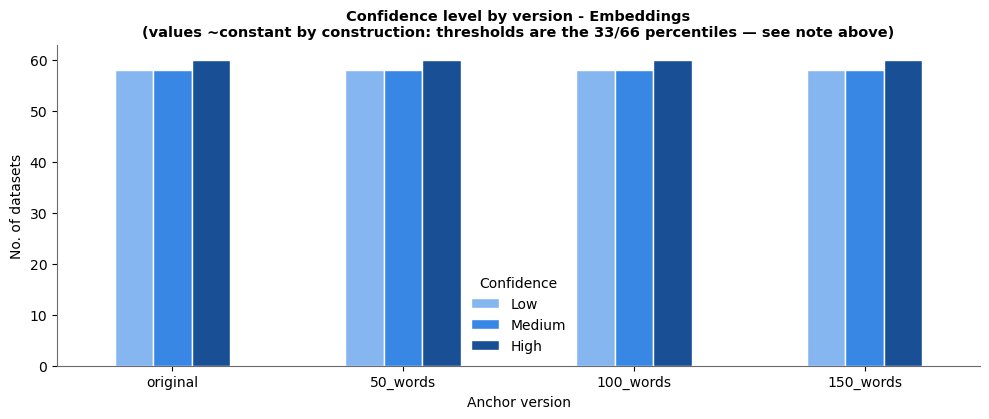

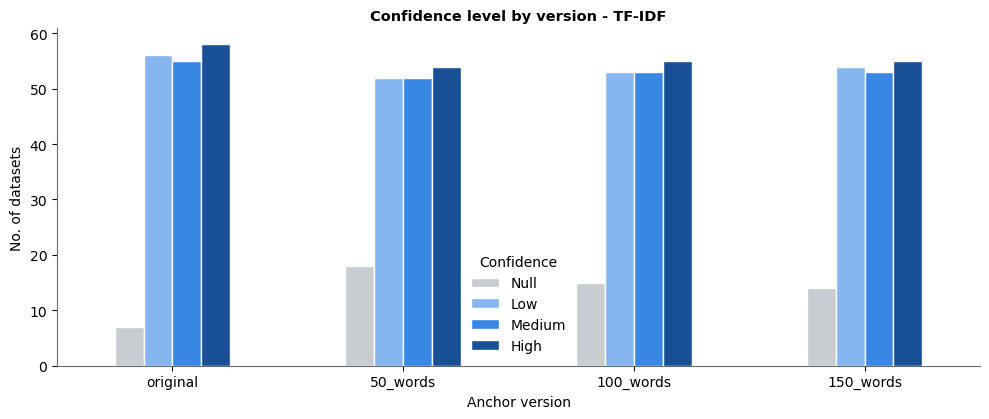

In [37]:
# ── Distribution of the confidence levels ─────────────────────────────────────
confidence_by_version = []

for version_name, obj in results_by_version.items():
    res = obj["results"]
    for col_real, method_name in [
        ("confidence_embeddings", "Embeddings"),
        ("confidence_tfidf",      "TF-IDF"),
    ]:
        counts = res[col_real].astype(str).str.strip().str.lower().value_counts()
        for level in ["null", "low", "medium", "high"]:
            confidence_by_version.append({
                "anchor_version" : version_name,
                "method"         : method_name,
                "confidence_level": level.capitalize(),
                "n_datasets"     : int(counts.get(level, 0)),
            })

confidence_by_version = pd.DataFrame(confidence_by_version)

# Pivot tables
for method_name in ["Embeddings", "TF-IDF"]:
    pivot = (
        confidence_by_version[confidence_by_version["method"] == method_name]
        .pivot_table(index="confidence_level", columns="anchor_version",
                     values="n_datasets", fill_value=0)
        .reindex(["Null", "Low", "Medium", "High"])
        .reindex(columns=VERSION_ORDER)   # logical order of the versions
        .fillna(0).astype(int)
    )
    print(f"Confidence — {method_name}:")
    display(pivot)

# ── Confidence charts ─────────────────────────────────────────────────────────
# NOTE: the Embeddings chart shows practically the SAME values in the 4
# versions — this is expected, not an error. The confidence thresholds are
# adaptive by percentile (33/66 — see Section 2.3), which guarantees, by
# mathematical construction, that ~33% of the datasets fall into "low", ~33% into
# "medium" and ~34% into "high" in ANY version. The TF-IDF chart does vary
# informatively between versions because it has a 4th category, "Null"
# (datasets without a classification), whose proportion is not fixed by percentile —
# it is this "Null" bar that carries the real information in this chart.
for col_real, method_name in [
    ("confidence_embeddings", "Embeddings"),
    ("confidence_tfidf",      "TF-IDF"),
]:
    conf_df = (
        results_all_versions
        .groupby(["anchor_version", col_real])
        .size()
        .reset_index(name="n")
        .pivot(index="anchor_version", columns=col_real, values="n")
        .reindex(index=VERSION_ORDER)     # logical order of the versions
        .reindex(columns=["null", "low", "medium", "high"], fill_value=0)
        .rename(columns={"null": "Null", "low": "Low", "medium": "Medium", "high": "High"})
        .fillna(0)
    )
    # Keep only columns that exist (avoids empty columns if there is no "null")
    conf_df = conf_df[[c for c in conf_df.columns if conf_df[c].sum() > 0]]
    colour_map = CONFIDENCE_COLOURS
    colours = [colour_map[c] for c in conf_df.columns]

    title_text = f"Confidence level by version - {method_name}"
    if method_name == "Embeddings":
        title_text += "\n(values ~constant by construction: thresholds are the 33/66 percentiles — see note above)"

    fig, ax = plt.subplots(figsize=(10, 4.3))
    conf_df.plot(kind="bar", ax=ax, color=colours, edgecolor="white")
    ax.set_title(title_text, fontsize=10.5)
    ax.set_xlabel("Anchor version")
    ax.set_ylabel("No. of datasets")
    format_x_labels(ax)
    ax.legend(title="Confidence")
    plt.tight_layout()
    plt.show()


**Analysis of the results (7.5 — Confidence levels).**

In the Embeddings, the breakdown by the low, medium and high levels is exactly the same in the four versions (58, 58 and 60 datasets), which confirms that these bands result from the 33rd and 66th percentiles and say nothing about the quality of each version. In TF-IDF, the three levels are split equally among the valid cases, and what varies from version to version is only the number of null cases, between 7 and 18.

**Rigorous interpretation of the delta bands.**

The almost constant distribution of the low, medium and high bands is a consequence of the percentiles used. The substantively variable information in TF-IDF is above all the number of null cases. To compare real separation between versions, the continuous deltas, the top-1/top-2 scores and the transitions of the same datasets between bands should be used.

### 7.6 Agreement matrices between Embeddings and TF-IDF

The agreement matrices cross the classifications of the two methods: the rows represent the dimension assigned by the Embeddings, and the columns represent the dimension assigned by TF-IDF. The values on the diagonal correspond to datasets on which the two methods agree.

#### How should the off-diagonal values be interpreted?

Each off-diagonal cell `(i, j)` represents datasets that the Embeddings classified in dimension `i` but TF-IDF classified in dimension `j`. These are the cases of disagreement. Systematic patterns of disagreement (e.g. the Embeddings systematically classify as "Mobility" what TF-IDF classifies as "Environment") may indicate:

1. **Semantic overlap between dimensions**: the two dimensions share vocabulary or concepts, and the two methods "choose different sides";
2. **Insufficiently distinct anchors**: the anchor texts of the two dimensions are similar enough for small differences in the text of the dataset or in the representation method to lead to different classifications;
3. **Real ambiguity of the dataset**: the dataset genuinely cuts across the two dimensions.

Off-diagonal datasets deserve priority in the manual review, because the two methods do not converge on the same dimension. Agreement on the diagonal is not equivalent to accuracy either.

Note: datasets without a TF-IDF classification (`score = 0`) are shown in a separate `Unclassified` column; the Embeddings always assign a dimension.


original: total n=176; TF-IDF valid=169; zero=7


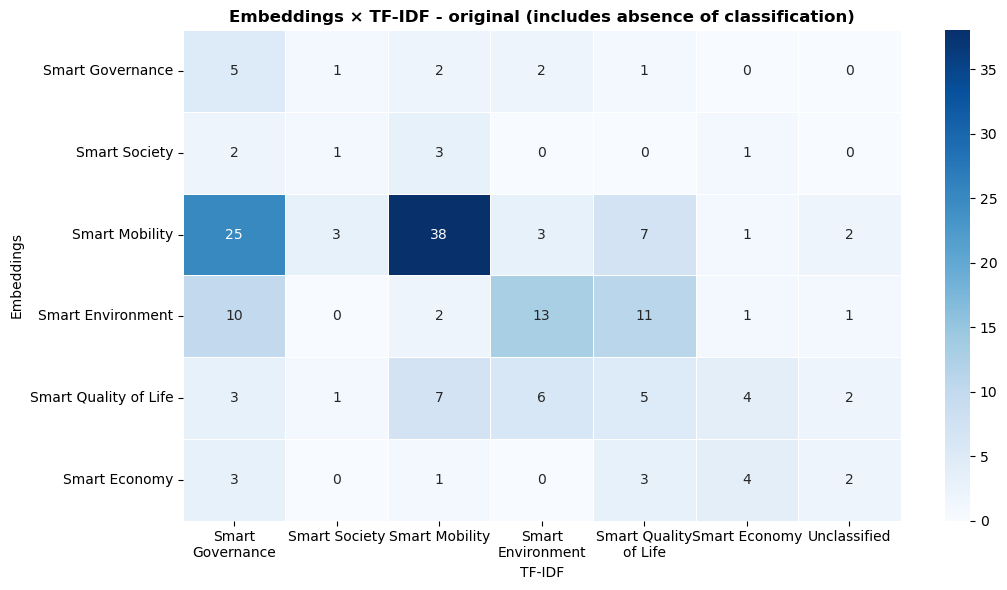

50_words: total n=176; TF-IDF valid=158; zero=18


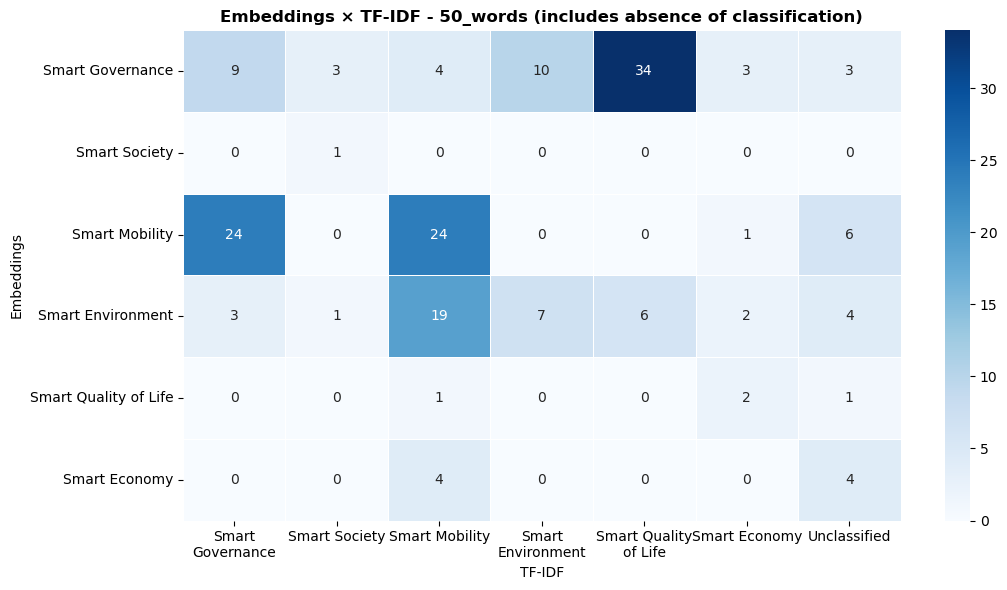

100_words: total n=176; TF-IDF valid=161; zero=15


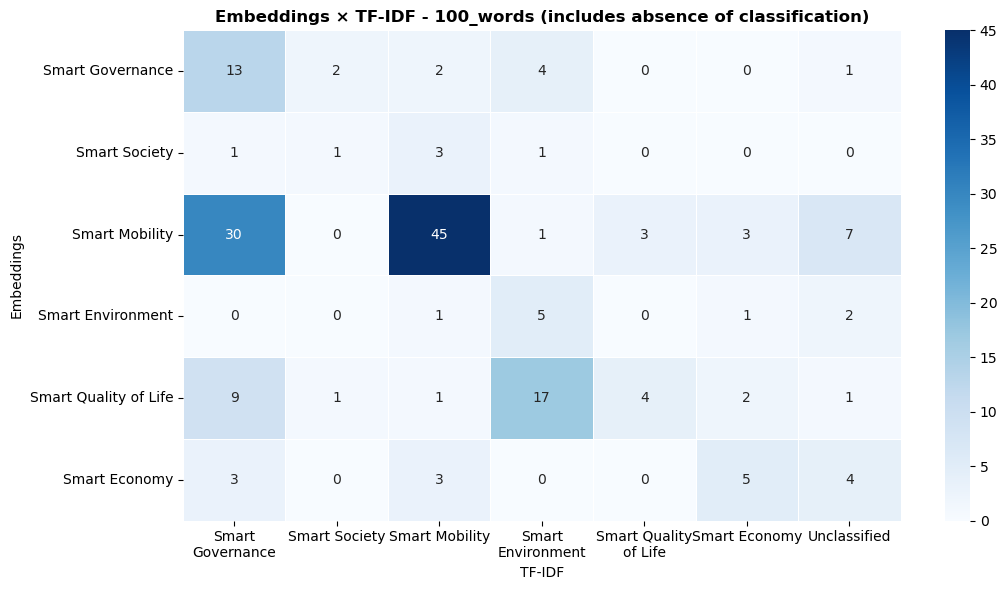

150_words: total n=176; TF-IDF valid=162; zero=14


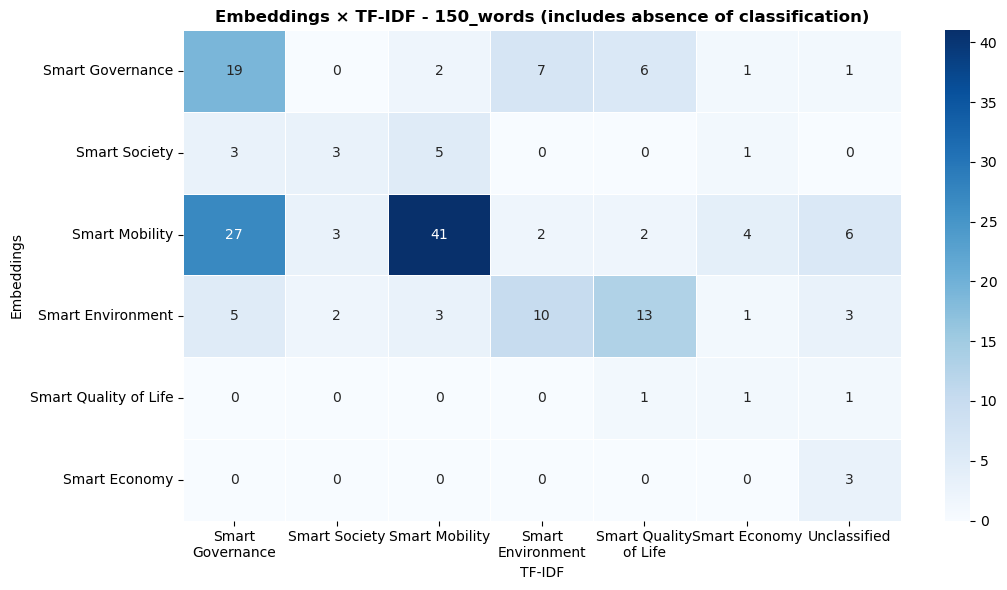

In [38]:
# ── Full and valid contingency matrices ──────────────────────────────────────
for version_name, obj in results_by_version.items():
    res = obj["results"].copy()
    dims = list(obj["scores_embeddings"].columns)
    res["dimension_tfidf_display"] = res["dimension_tfidf"].fillna("Unclassified")
    column_order = dims + ["Unclassified"]
    mat_total = pd.crosstab(res["dimension_embeddings"], res["dimension_tfidf_display"]).reindex(
        index=dims, columns=column_order, fill_value=0)
    n_valid = res["dimension_tfidf"].notna().sum()
    print(f"{version_name}: total n={len(res)}; TF-IDF valid={n_valid}; zero={len(res)-n_valid}")
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.heatmap(mat_total, annot=True, fmt="d", cmap=CMAP_EMB, ax=ax, linewidths=.5)
    ax.set_title(f"Embeddings × TF-IDF - {version_name} (includes absence of classification)")
    ax.set_xlabel("TF-IDF"); ax.set_ylabel("Embeddings")
    format_x_labels(ax); horizontal_y_labels(ax)
    plt.tight_layout(); plt.show()

#### Figure 4.4 (dissertation) — Contingency table between embeddings and TF-IDF, original version

Section 4.3 (RQ2). Print version of the heatmap of the original version above (includes the column of the records without a TF-IDF classification). To fit the width, the dimensions appear without the qualifier “Smart” and the colour bar was removed, because the values are written in each cell. Panel a) Águeda, b) Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_4_a_contingency_original.png


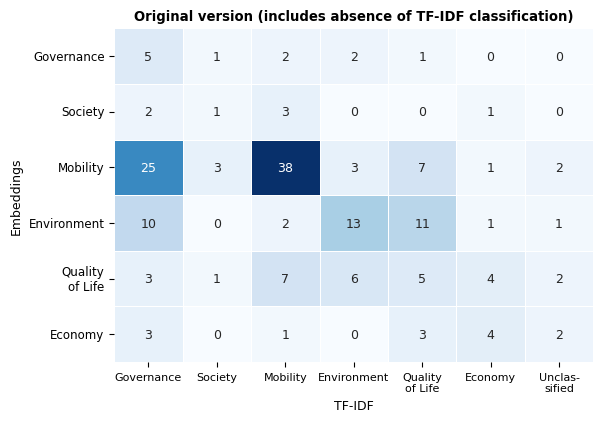

In [39]:
# ── Figure 4.4 (dissertation): embeddings × TF-IDF contingency, original version ─
res = results_by_version["original"]["results"].copy()
dims = list(results_by_version["original"]["scores_embeddings"].columns)
res["dimension_tfidf_display"] = res["dimension_tfidf"].fillna("Unclassified")
mat_total = pd.crosstab(res["dimension_embeddings"], res["dimension_tfidf_display"]).reindex(
    index=dims, columns=dims + ["Unclassified"], fill_value=0)
with plt.rc_context(DISS_FONT):
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4.3))
    sns.heatmap(mat_total, annot=True, fmt="d", cmap=CMAP_EMB, ax=ax, linewidths=.5,
                cbar=False, annot_kws={"fontsize": 9})   # no colour bar: the values are in each cell
    ax.set_title("Original version (includes absence of TF-IDF classification)")
    ax.set_xlabel("TF-IDF"); ax.set_ylabel("Embeddings")
    shorten = lambda t: t.replace("Smart ", "")
    ax.set_xticklabels([shorten(t.get_text()).replace("Quality of Life", "Quality\nof Life")
                        .replace("Unclassified", "Unclas-\nsified") for t in ax.get_xticklabels()], rotation=0)
    ax.set_yticklabels([shorten(t.get_text()).replace("Quality of Life", "Quality\nof Life")
                        for t in ax.get_yticklabels()], rotation=0)
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    export_diss_figure(fig, "4.4", "contingency_original")


**Analysis of the results (7.6 — Contingency matrices between methods).**

The matrices show that the disagreement between methods follows stable patterns. In all versions there is a block of datasets with Mobility as the predominant dimension in the Embeddings and Governance in TF-IDF (25 in the original version, 24 in the 50-word version, 30 in the 100-word version and 27 in the 150-word version), which is the largest off-diagonal block in three of them. Other blocks depend on the version: in the original and 150-word versions, part of the datasets in Environment in the Embeddings appear in Quality of Life in TF-IDF (11 and 13); in the 50-word version, 34 datasets with Governance in the Embeddings appear in Quality of Life in TF-IDF; and in the 100-word version, 17 move from Quality of Life to Environment.

The diagonal is dominated by Mobility in all versions (between 24 and 45 datasets), which confirms that it is the dimension on which the two methods converge most easily.

**Rigorous interpretation of the contingency matrices.**

The diagonal represents categorical agreement and the remaining values represent different combinations, without indicating which method is correct. The `Unclassified` column makes the limited coverage of TF-IDF visible. The matrices should be analysed together with the Kappa and the denominators. Recurring disagreements are priority candidates for human review, not proof of the superiority of a method.

### 7.7 Similarity profile with all dimensions

The classification assigns each dataset to the dimension with the highest score, but this does not, by itself,
reveal how differentiated that choice is from the other five dimensions. Two datasets may
both be classified as "Smart Mobility" with the same top-1 score, but one of them
may have that score clearly above all the other dimensions (unequivocal classification)
while the other has five practically tied scores (ambiguous classification, in which the
"victory" of the chosen dimension is minimal). The final classification alone does not distinguish
these two cases - both appear as "Smart Mobility, score X".

This section directly addresses that limitation by showing the **full score profile**, the cosine similarity coefficients with **all 6 dimensions simultaneously**, per dataset,
through four complementary elements:

**A) Heatmap per dataset (sample)**: a grid in which each row is a dataset and each column
a Smart City dimension; the colour represents the value of the score. It allows a quick visual reading:
a row with a single cell much darker than the others indicates clear separation;
a row with similar colours in all cells indicates ambiguity. The heatmap is produced for each of the four anchor versions. The sample of ~25
datasets is selected to include a mixture of clear and ambiguous cases (not just the
"best" examples), so that the heatmap is representative of the real variability of the
corpus, and not only of the cases most favourable to the method.

**B) Table with the 6 scores per dataset** (one per version and method): the same information as the heatmap in tabular form,
sortable and with the exact numerical values, for the datasets for which visual inspection of the
heatmap suggests a need for precise confirmation of the numbers.

**C) Aggregate separation margin**: as a complement to the visualisations per dataset, the
mean margin between the top-1 score and the mean of the other 5 scores is computed, aggregated by
anchor version and by method. This metric answers the question "on average, how clear is the
separation in this corpus?", serving as quantitative context for interpreting the
individual cases shown in the heatmap and in the table.



**D) Boxplot of the distribution of the scores and of the separation margin**: the three previous
visualisations show individual cases (heatmap, table) or only the aggregate mean/median
(part C). The boxplot complements them by showing the **full distribution** of the top-1 score,
the top-2 score and the separation margin, for **all the datasets** of each version (not
just the sample of 25 used in the heatmap) — including the dispersion (quartiles), the median and the
outliers. This makes it possible to answer questions that the mean alone does not reveal: is the separation
between dimensions consistent across the whole corpus, or is there great variability (some
very clear datasets and others very ambiguous)? The boxplot is built side by side for
Embeddings and TF-IDF and repeated for each anchor version, facilitating direct comparison between
methods and between versions.

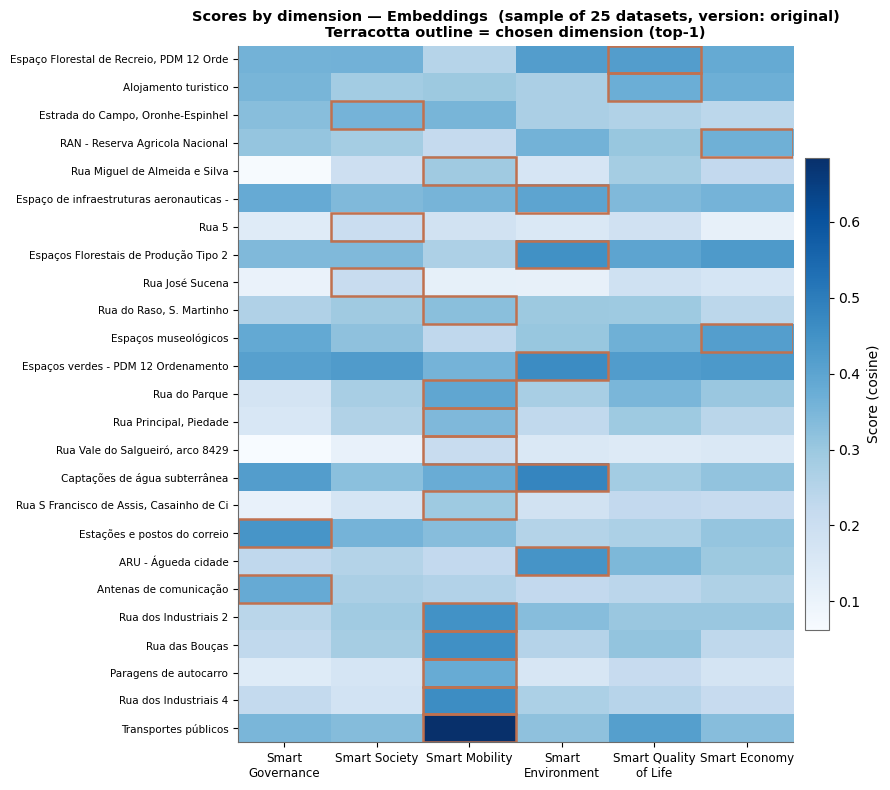


Embeddings — table of scores per dataset (version: original)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,b07f2412-9b0f-429f-98fe-063e3ea6a38a,"Espaço Florestal de Recreio, PDM 12 Ordenamento",0.3599,0.3623,0.2484,0.4171,0.4173,0.3853,Smart Quality of Life,0.0002
1,06f7e8b9-d84d-4efe-8c08-7f1087a01599,Alojamento turistico,0.3517,0.2841,0.2961,0.2710,0.3730,0.3702,Smart Quality of Life,0.0028
2,5c4519fe-72a4-4b9b-ab3c-8126bedc60fe,"Estrada do Campo, Oronhe-Espinhel",0.3294,0.3576,0.3527,0.2710,0.2587,0.2371,Smart Society,0.0049
3,30bee636-ba99-4f82-ac79-1fe4d4a081cb,RAN - Reserva Agricola Nacional,0.3096,0.2820,0.2200,0.3591,0.3046,0.3660,Smart Economy,0.0069
4,67175929-2163-4352-9111-774a2f3f8cb2,Rua Miguel de Almeida e Silva,0.0664,0.1952,0.2930,0.1647,0.2816,0.2239,Smart Mobility,0.0113
5,f98ae12a-93e9-4959-8941-20b7aea6e5ad,Espaço de infraestruturas aeronauticas - PDM 12 Ordenamento,0.3818,0.3403,0.3546,0.3978,0.3401,0.3585,Smart Environment,0.0160
6,71703940-421c-418d-86a7-6fe82b961cb7,Rua 5,0.1363,0.2033,0.1817,0.1504,0.1843,0.1119,Smart Society,0.0190
7,5423754b-fe20-4017-a5d9-142fa7e3b347,Espaços Florestais de Produção Tipo 2,0.3394,0.3408,0.2660,0.4513,0.3987,0.4289,Smart Environment,0.0224
8,afbf1eb0-0453-4b85-8174-18f57b889675,Rua José Sucena,0.1015,0.2115,0.1154,0.1113,0.1867,0.1672,Smart Society,0.0248
9,69657374-e8ee-40d4-bebf-57efe6ed0fd6,"Rua do Raso, S. Martinho",0.2606,0.2910,0.3248,0.2975,0.2946,0.2360,Smart Mobility,0.0273


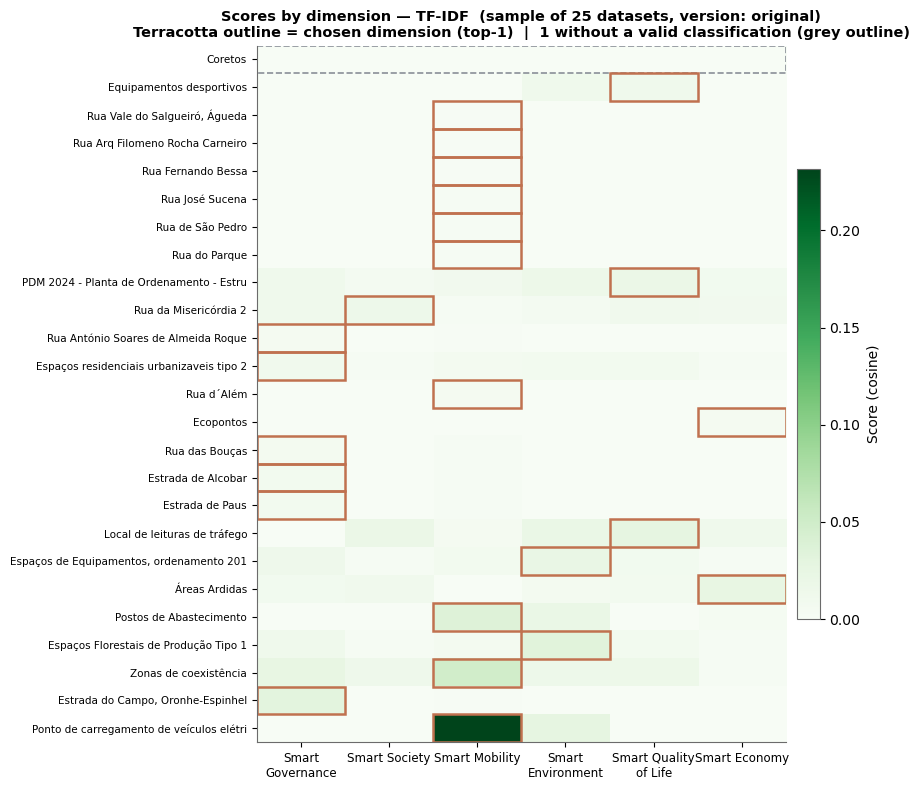


TF-IDF — table of scores per dataset (version: original)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,0dde552a-675e-457d-abd2-0102221852ba,Coretos,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
1,a14de81f-0dc4-4939-ae9f-85f9635f243a,Equipamentos desportivos,0.0000,0.0000,0.0000,0.0119,0.0122,0.0000,Smart Quality of Life,0.0003
2,67e819f2-1db0-4998-ae98-2894d718438d,"Rua Vale do Salgueiró, Águeda",0.0000,0.0000,0.0015,0.0000,0.0000,0.0000,Smart Mobility,0.0015
3,5bb5531b-aa40-4c27-a787-ebc8b10d46d6,Rua Arq Filomeno Rocha Carneiro,0.0000,0.0000,0.0017,0.0000,0.0000,0.0000,Smart Mobility,0.0017
4,0f8df561-e035-4262-9baf-01e344eb3c05,Rua Fernando Bessa,0.0000,0.0000,0.0018,0.0000,0.0000,0.0000,Smart Mobility,0.0018
5,afbf1eb0-0453-4b85-8174-18f57b889675,Rua José Sucena,0.0000,0.0000,0.0021,0.0000,0.0000,0.0000,Smart Mobility,0.0021
6,819fc021-f332-4521-944b-39533e1b6f2a,Rua de São Pedro,0.0000,0.0000,0.0024,0.0000,0.0000,0.0000,Smart Mobility,0.0024
7,fb55bda7-f6be-43a3-a36b-c9938d368d0b,Rua do Parque,0.0000,0.0000,0.0028,0.0000,0.0000,0.0000,Smart Mobility,0.0028
8,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,0.0123,0.0059,0.0095,0.0163,0.0194,0.0082,Smart Quality of Life,0.0031
9,389d2e66-6e7d-40dd-a04d-2d3a6c1dd5bd,Rua da Misericórdia 2,0.0120,0.0153,0.0022,0.0060,0.0112,0.0095,Smart Society,0.0034


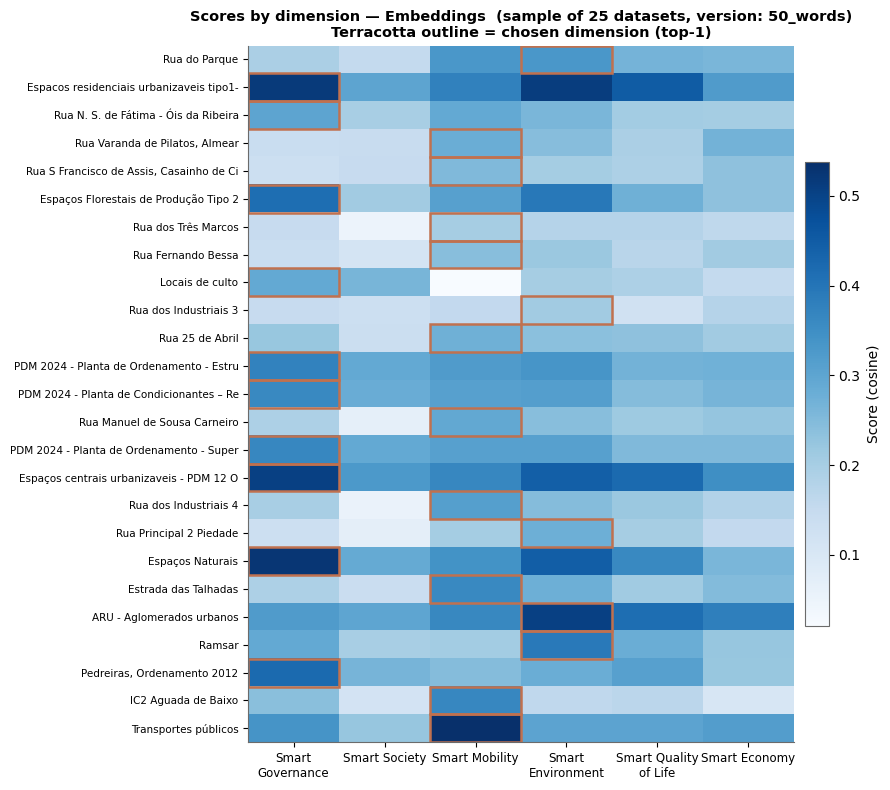


Embeddings — table of scores per dataset (version: 50_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,fb55bda7-f6be-43a3-a36b-c9938d368d0b,Rua do Parque,0.1925,0.1527,0.3306,0.3313,0.2656,0.2602,Smart Environment,0.0007
1,eb242794-2a7c-4edb-bb39-cb274c53ef78,Espacos residenciais urbanizaveis tipo1- PDM 12 Ordenamento,0.5163,0.3009,0.3744,0.5110,0.4501,0.3206,Smart Governance,0.0053
2,6f4ae185-79f4-4a90-b4ad-08e36643a75b,Rua N. S. de Fátima - Óis da Ribeira,0.3000,0.1972,0.2908,0.2606,0.2052,0.2027,Smart Governance,0.0092
3,0d2ad0a6-88e6-4552-8942-dd0d818abe59,"Rua Varanda de Pilatos, Almear",0.1417,0.1438,0.2798,0.2433,0.1938,0.2680,Smart Mobility,0.0118
4,f9de4d9e-25ab-48b9-a077-d3e6288097c1,"Rua S Francisco de Assis, Casainho de Cima, Águeda",0.1329,0.1461,0.2519,0.2041,0.1889,0.2336,Smart Mobility,0.0183
5,5423754b-fe20-4017-a5d9-142fa7e3b347,Espaços Florestais de Produção Tipo 2,0.4137,0.2082,0.3099,0.3935,0.2752,0.2331,Smart Governance,0.0203
6,18d1711d-1266-41f4-9466-2447e49ddebc,Rua dos Três Marcos,0.1472,0.0498,0.2013,0.1780,0.1775,0.1610,Smart Mobility,0.0233
7,0f8df561-e035-4262-9baf-01e344eb3c05,Rua Fernando Bessa,0.1407,0.1116,0.2426,0.2181,0.1712,0.2076,Smart Mobility,0.0245
8,eb161ebf-a7ef-449e-a401-a41017f79b18,Locais de culto,0.2902,0.2619,0.0205,0.2019,0.1884,0.1539,Smart Governance,0.0283
9,0df3119b-6ebd-40f6-8b39-cc23caa4dfc7,Rua dos Industriais 3,0.1469,0.1324,0.1546,0.2081,0.1221,0.1767,Smart Environment,0.0314


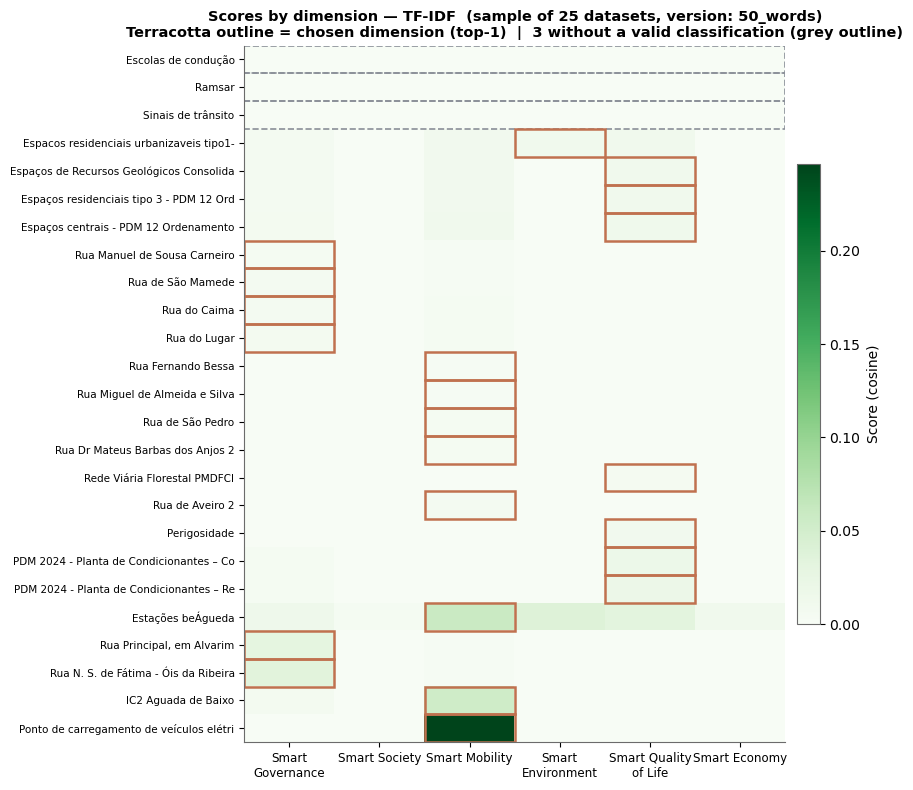


TF-IDF — table of scores per dataset (version: 50_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,3213f991-5d35-4bef-9e2a-b7794f3598e8,Escolas de condução,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
1,dd7b4835-9b20-49c4-bc1b-b2155aabc073,Ramsar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
2,404ac1e9-4f13-492a-833a-81fbcf9bcf2d,Sinais de trânsito,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
3,eb242794-2a7c-4edb-bb39-cb274c53ef78,Espacos residenciais urbanizaveis tipo1- PDM 12 Ordenamento,0.0063,0.0000,0.0100,0.0112,0.0111,0.0000,Smart Environment,0.0001
4,811e9c61-c070-47fd-a923-c8a8e8c04714,Espaços de Recursos Geológicos Consolidados - Ordenamento 2012,0.0061,0.0000,0.0097,0.0000,0.0108,0.0000,Smart Quality of Life,0.0011
5,43e7822a-57e0-414f-a406-f2516e9148fd,Espaços residenciais tipo 3 - PDM 12 Ordenamento,0.0066,0.0000,0.0105,0.0000,0.0117,0.0000,Smart Quality of Life,0.0012
6,fc538347-05df-4a00-ac61-2ba4f1d761b4,Espaços centrais - PDM 12 Ordenamento,0.0071,0.0000,0.0113,0.0000,0.0126,0.0000,Smart Quality of Life,0.0012
7,894cd12d-3b14-4212-9c84-784cc9e8ef0f,Rua Manuel de Sousa Carneiro,0.0048,0.0000,0.0028,0.0000,0.0000,0.0000,Smart Governance,0.0019
8,0e163866-6126-46a3-967b-aec434747d86,Rua de São Mamede,0.0059,0.0000,0.0035,0.0000,0.0000,0.0000,Smart Governance,0.0024
9,b6b69f49-2ddb-4004-b113-56068c375cb1,Rua do Caima,0.0066,0.0000,0.0039,0.0000,0.0000,0.0000,Smart Governance,0.0027


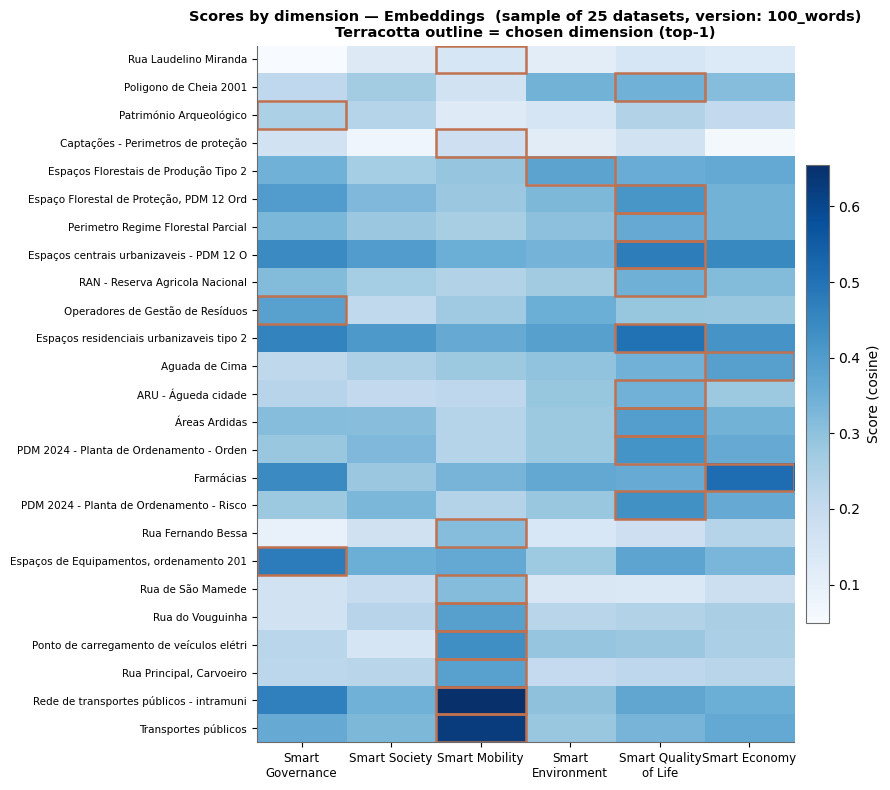


Embeddings — table of scores per dataset (version: 100_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,c3f09179-094c-4e65-b507-58c36e06da67,Rua Laudelino Miranda,0.0496,0.1254,0.1460,0.1116,0.1454,0.1301,Smart Mobility,0.0006
1,7797a52a-a6c3-4bbe-8412-dc13cfb6882c,Poligono de Cheia 2001,0.2110,0.2663,0.1641,0.3398,0.3437,0.3097,Smart Quality of Life,0.0039
2,96cd7dce-ca42-41ca-88ba-7687f5abcec0,Património Arqueológico,0.2483,0.2307,0.1238,0.1521,0.2404,0.2070,Smart Governance,0.0079
3,07246638-8248-4e26-b7b7-d40c67106d8a,Captações - Perimetros de proteção,0.1670,0.0756,0.1788,0.1179,0.1658,0.0626,Smart Mobility,0.0119
4,5423754b-fe20-4017-a5d9-142fa7e3b347,Espaços Florestais de Produção Tipo 2,0.3433,0.2644,0.2895,0.3782,0.3553,0.3645,Smart Environment,0.0137
5,def83cb9-e427-47d1-bf2f-ba8bf346056a,"Espaço Florestal de Proteção, PDM 12 Ordenamento",0.3970,0.3228,0.2804,0.3259,0.4139,0.3381,Smart Quality of Life,0.0169
6,c463fa0c-9353-4eff-a973-7e10ad872dfd,Perimetro Regime Florestal Parcial,0.3262,0.2795,0.2565,0.3023,0.3610,0.3390,Smart Quality of Life,0.0220
7,b202d392-49b4-4b72-8a28-76f47ee822c3,Espaços centrais urbanizaveis - PDM 12 Ordenamento,0.4440,0.3983,0.3504,0.3374,0.4735,0.4479,Smart Quality of Life,0.0256
8,30bee636-ba99-4f82-ac79-1fe4d4a081cb,RAN - Reserva Agricola Nacional,0.3151,0.2642,0.2399,0.2675,0.3457,0.3159,Smart Quality of Life,0.0297
9,b2d1563d-683f-4dff-a472-a68789c9df74,Operadores de Gestão de Resíduos,0.3853,0.2098,0.2736,0.3509,0.2867,0.2851,Smart Governance,0.0343


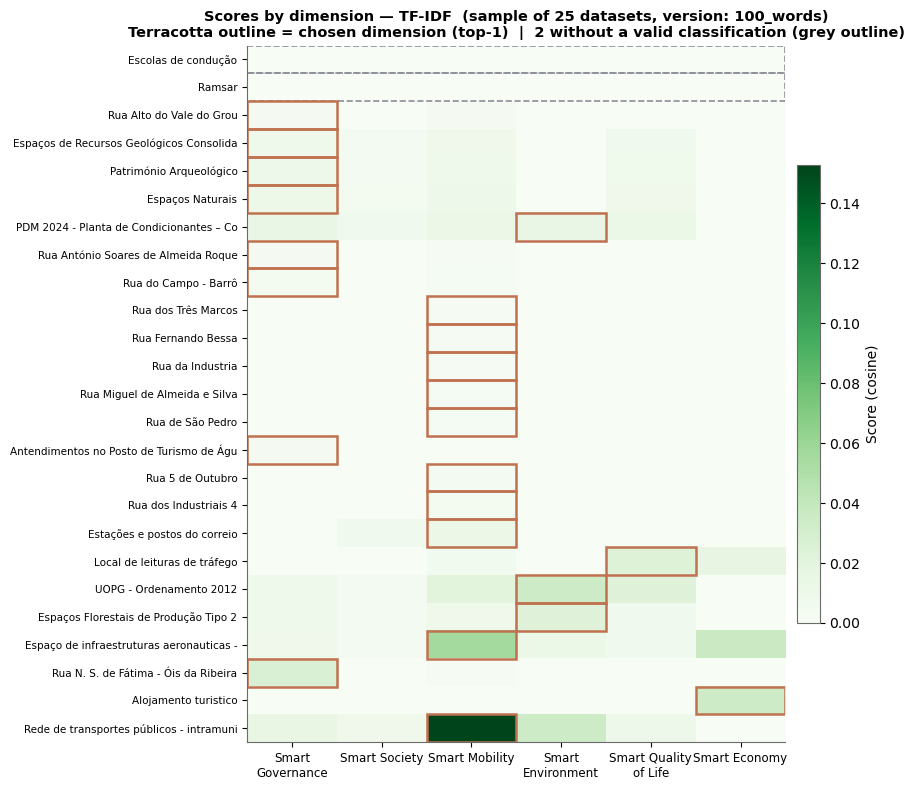


TF-IDF — table of scores per dataset (version: 100_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,3213f991-5d35-4bef-9e2a-b7794f3598e8,Escolas de condução,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
1,dd7b4835-9b20-49c4-bc1b-b2155aabc073,Ramsar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
2,aad8b087-3cb9-446b-9670-406acc165b1f,Rua Alto do Vale do Grou,0.0031,0.0000,0.0030,0.0000,0.0000,0.0000,Smart Governance,0.0001
3,811e9c61-c070-47fd-a923-c8a8e8c04714,Espaços de Recursos Geológicos Consolidados - Ordenamento 2012,0.0090,0.0038,0.0084,0.0000,0.0074,0.0000,Smart Governance,0.0005
4,96cd7dce-ca42-41ca-88ba-7687f5abcec0,Património Arqueológico,0.0097,0.0041,0.0091,0.0000,0.0080,0.0000,Smart Governance,0.0006
5,48a7b039-a1b3-4761-a674-012e6a2cbd34,Espaços Naturais,0.0103,0.0044,0.0097,0.0000,0.0085,0.0000,Smart Governance,0.0006
6,04636627-733c-487a-bbb0-4314d6f0a923,PDM 2024 - Planta de Condicionantes – Condicionantes Gerais,0.0141,0.0073,0.0116,0.0148,0.0124,0.0000,Smart Environment,0.0007
7,7d6361c1-1540-41c2-8231-4bb8596593fe,Rua António Soares de Almeida Roque,0.0035,0.0000,0.0020,0.0000,0.0000,0.0000,Smart Governance,0.0015
8,bd2dba54-c2e8-4d30-94f9-45aa50780a19,Rua do Campo - Barrô,0.0044,0.0000,0.0025,0.0000,0.0000,0.0000,Smart Governance,0.0019
9,18d1711d-1266-41f4-9466-2447e49ddebc,Rua dos Três Marcos,0.0000,0.0000,0.0021,0.0000,0.0000,0.0000,Smart Mobility,0.0021


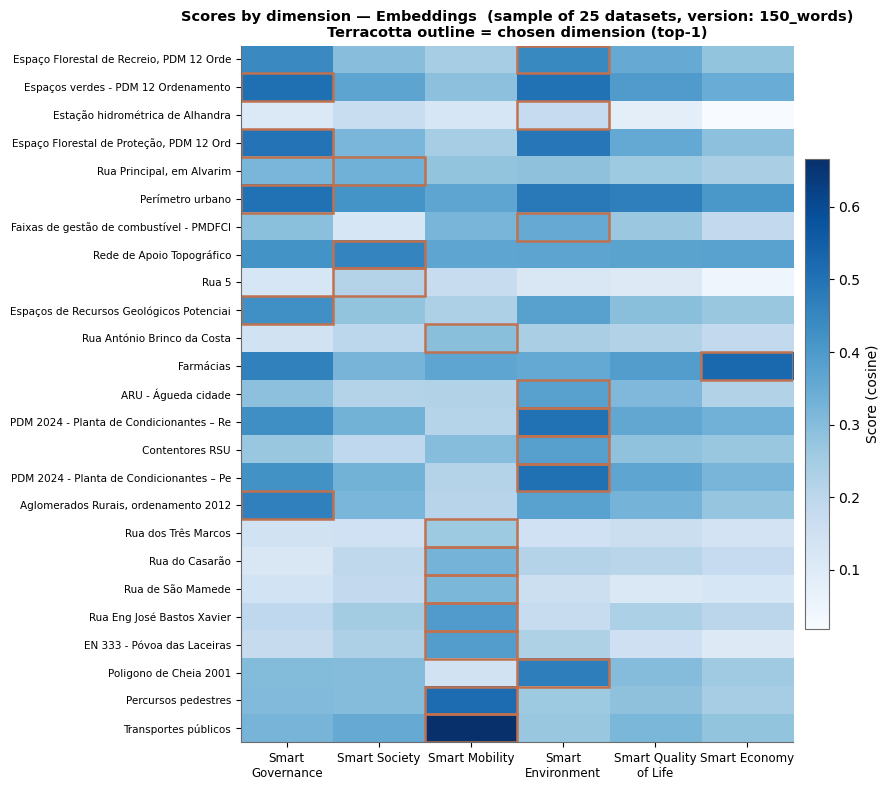


Embeddings — table of scores per dataset (version: 150_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,b07f2412-9b0f-429f-98fe-063e3ea6a38a,"Espaço Florestal de Recreio, PDM 12 Ordenamento",0.4434,0.2966,0.2459,0.4436,0.3507,0.2782,Smart Environment,0.0002
1,ccba1ddf-81a4-4899-b15f-ebc7a5dbbde1,Espaços verdes - PDM 12 Ordenamento,0.5091,0.3696,0.2883,0.5035,0.3947,0.3452,Smart Governance,0.0056
2,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,0.1086,0.1698,0.1237,0.1794,0.0819,0.0185,Smart Environment,0.0095
3,def83cb9-e427-47d1-bf2f-ba8bf346056a,"Espaço Florestal de Proteção, PDM 12 Ordenamento",0.4987,0.3183,0.2451,0.4876,0.3560,0.2872,Smart Governance,0.0111
4,5bc7be00-6d46-401a-bc70-4561bb110630,"Rua Principal, em Alvarim",0.3183,0.3337,0.2786,0.2850,0.2607,0.2379,Smart Society,0.0154
5,ffd80680-c076-4ff5-bf8c-8f4d92bacb03,Perímetro urbano,0.5037,0.4167,0.3668,0.4823,0.4683,0.4061,Smart Governance,0.0214
6,1aba1d01-0b3b-4dc9-a50c-d231a4f48d67,Faixas de gestão de combustível - PMDFCI,0.2906,0.1215,0.3210,0.3500,0.2642,0.1878,Smart Environment,0.0290
7,903a04b7-8ea0-4234-bb10-5c44042b75bd,Rede de Apoio Topográfico,0.4184,0.4537,0.3675,0.3693,0.3745,0.3754,Smart Society,0.0354
8,71703940-421c-418d-86a7-6fe82b961cb7,Rua 5,0.1233,0.2159,0.1715,0.1170,0.1010,0.0453,Smart Society,0.0444
9,e7bd45b2-3a1a-4acb-bd7f-04a07de6aee3,Espaços de Recursos Geológicos Potenciais - Ordenamento 2012,0.4281,0.2770,0.2285,0.3781,0.2923,0.2676,Smart Governance,0.0501


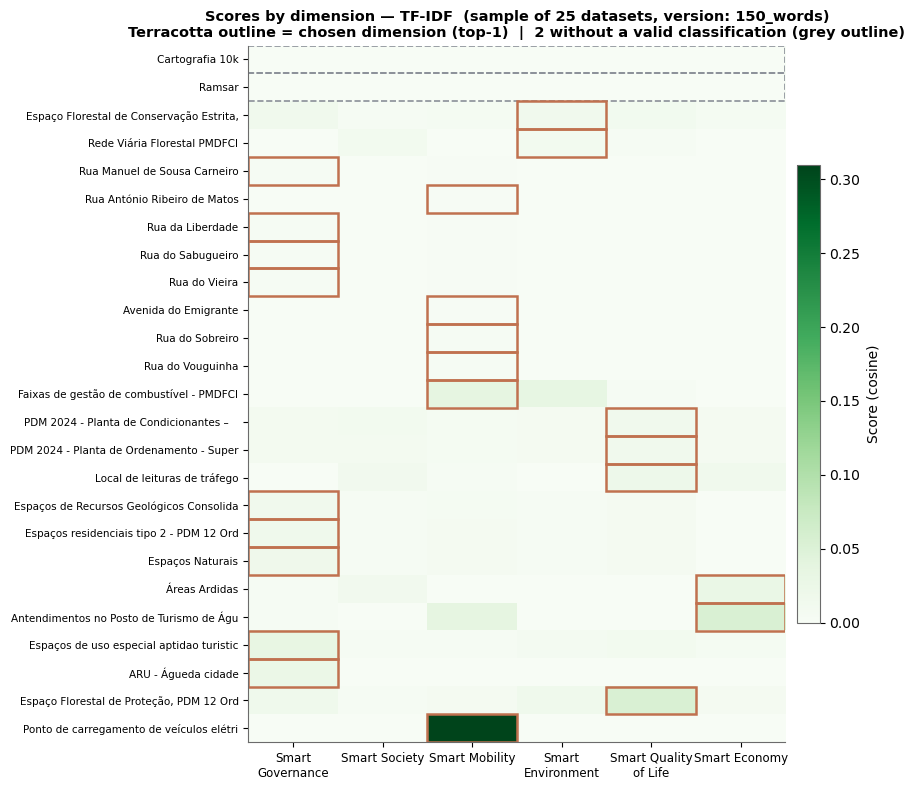


TF-IDF — table of scores per dataset (version: 150_words)


,dataset_id,dataset_title,Smart Governance,Smart Society,Smart Mobility,Smart Environment,Smart Quality of Life,Smart Economy,chosen_dimension,delta
0,b5827eff-2288-4392-bdd2-d1e73c8251ad,Cartografia 10k,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
1,dd7b4835-9b20-49c4-bc1b-b2155aabc073,Ramsar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,None,0.0000
2,dc19fcae-4bb6-433c-a1cc-9fe4c538e039,"Espaço Florestal de Conservação Estrita, PDM 12 Ordenamento",0.0143,0.0029,0.0053,0.0144,0.0117,0.0058,Smart Environment,0.0001
3,2ee0676b-0f28-4d34-aa54-76992f4ab15a,Rede Viária Florestal PMDFCI,0.0000,0.0102,0.0000,0.0107,0.0030,0.0000,Smart Environment,0.0006
4,894cd12d-3b14-4212-9c84-784cc9e8ef0f,Rua Manuel de Sousa Carneiro,0.0031,0.0000,0.0017,0.0000,0.0000,0.0000,Smart Governance,0.0013
5,172eb6d9-11e8-4dd4-9270-301cc7b7a48b,Rua António Ribeiro de Matos,0.0000,0.0000,0.0016,0.0000,0.0000,0.0000,Smart Mobility,0.0016
6,121f4830-1583-40d3-b6b1-bf384f63a856,Rua da Liberdade,0.0040,0.0000,0.0023,0.0000,0.0000,0.0000,Smart Governance,0.0018
7,928c1400-25ec-40b5-871b-a0847e3bebbc,Rua do Sabugueiro,0.0041,0.0000,0.0023,0.0000,0.0000,0.0000,Smart Governance,0.0018
8,aef9bcc2-9e3a-44c5-8a4a-3584be42c352,Rua do Vieira,0.0043,0.0000,0.0024,0.0000,0.0000,0.0000,Smart Governance,0.0019
9,d9eaeeb5-e618-4e8a-9dd1-8c64f6a4a7ca,Avenida do Emigrante,0.0000,0.0000,0.0022,0.0000,0.0000,0.0000,Smart Mobility,0.0022



Aggregate separation margin (score_top1 − mean of the other 5 scores):

  original:
    Embeddings — mean margin: 0.1242  |  median: 0.1133  |  std: 0.0569
    TF-IDF     — mean margin: 0.0146  |  median: 0.0072  |  std: 0.0238

  50_words:
    Embeddings — mean margin: 0.1163  |  median: 0.1115  |  std: 0.0418
    TF-IDF     — mean margin: 0.0147  |  median: 0.0062  |  std: 0.0236

  100_words:
    Embeddings — mean margin: 0.1179  |  median: 0.1113  |  std: 0.0546
    TF-IDF     — mean margin: 0.0125  |  median: 0.0050  |  std: 0.0195

  150_words:
    Embeddings — mean margin: 0.1374  |  median: 0.1326  |  std: 0.0605
    TF-IDF     — mean margin: 0.0146  |  median: 0.0069  |  std: 0.0272

Interpretation: a margin close to 0 indicates that several scores are similar
— the classification may be ambiguous. A high margin indicates clear separation.


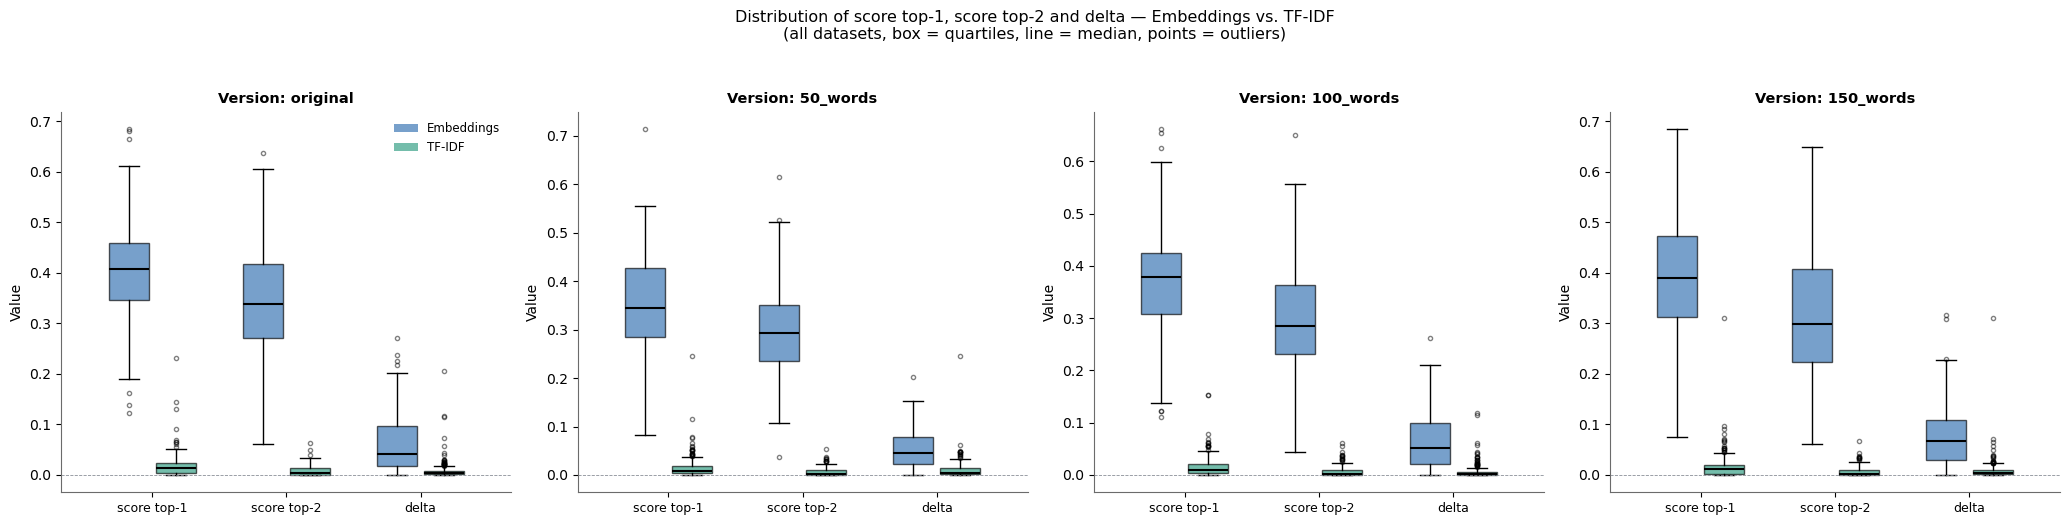


How to read this boxplot:
  - Narrow box high or low on the axis → consistently high/low scores across the whole corpus.
  - Wide box (much dispersion)        → large variability between datasets — some very
    clear, others very ambiguous.
  - 'delta' close to 0 with a narrow box → systematic ambiguity (not just a
    problem of a few isolated datasets, but a general pattern of the method/version).
  - Isolated points above/below the 'whiskers' → outliers: datasets with confidence much
    above or below the usual (see also Section 7.8, delta outliers on a log scale).


In [40]:
import matplotlib.colors as mcolors

VERSIONS   = list(results_by_version.keys())
N_VERSIONS = len(VERSIONS)
N_SAMPLE = 25  # no. of datasets to show in the heatmap/table per version



def select_representative_sample(res: pd.DataFrame, col_delta: str, n: int) -> pd.DataFrame:
    """
    Selects a sample of n datasets covering the spectrum of observed deltas
    (not only the most favourable cases), dividing the distribution into n groups
    by percentile and choosing one representative dataset from each group.
    Ensures that the sample includes both cases of clear separation and
    ambiguous cases, reflecting the real variability of the corpus.
    """
    res_valid = res.dropna(subset=[col_delta]).sort_values(col_delta).reset_index(drop=True)
    if len(res_valid) <= n:
        return res_valid
    indices = np.linspace(0, len(res_valid) - 1, n).round().astype(int)
    return res_valid.iloc[indices].reset_index(drop=True)


# ── A) and B) for each anchor version ─────────────────────────────────────────
for sample_version in VERSIONS:
    for method, col_delta, score_prefix in [
        ("Embeddings", "delta_embeddings", "score_emb_"),
        ("TF-IDF",     "delta_tfidf",      "score_tfidf_"),
    ]:
        res = results_by_version[sample_version]["results"]
        score_cols = [c for c in res.columns if c.startswith(score_prefix)]
        dims_ord   = [c.replace(score_prefix, "") for c in score_cols]

        sample = select_representative_sample(res, col_delta, N_SAMPLE)

        # ── A) Heatmap datasets × dimensions ─────────────────────────────────────
        matrix = sample[score_cols].values
        labels_y = sample["dataset_title"].astype(str).str.slice(0, 40).values

        # The outline follows the actual classification column (see get_classification),
        # not an argmax over the scores: rows with score=0 everywhere (no lexical overlap
        # in TF-IDF) have dimension_tfidf = None and therefore receive no outline.
        chosen_dim_col = f"dimension_{'embeddings' if method == 'Embeddings' else 'tfidf'}"
        sample_dimensions = sample[chosen_dim_col].values

        fig, ax = plt.subplots(figsize=(9, max(6, 0.32 * len(sample))))
        im = ax.imshow(matrix, cmap=CMAP_EMB if method == "Embeddings" else CMAP_TFIDF, aspect="auto")

        ax.set_xticks(range(len(dims_ord)))
        ax.set_xticklabels(dims_ord, fontsize=8.5)
        format_x_labels(ax)
        ax.set_yticks(range(len(sample)))
        ax.set_yticklabels(labels_y, fontsize=7.5)

        n_unclassified = 0
        for row_idx, chosen_dim in enumerate(sample_dimensions):
            if pd.isna(chosen_dim):
                # No valid classification: mark the whole row with a
                # dashed grey hatching instead of pretending there was a choice —
                # it visually communicates "no dimension was assigned here".
                ax.add_patch(plt.Rectangle(
                    (-0.5, row_idx - 0.5), len(dims_ord), 1,
                    fill=False, edgecolor=NEUTRAL_COLOUR, linewidth=1.2, linestyle="--",
                ))
                n_unclassified += 1
            else:
                top1_col_idx = dims_ord.index(chosen_dim)
                ax.add_patch(plt.Rectangle(
                    (top1_col_idx - 0.5, row_idx - 0.5), 1, 1,
                    fill=False, edgecolor=HIGHLIGHT_COLOUR, linewidth=1.8,
                ))

        fig.colorbar(im, ax=ax, label="Score (cosine)", fraction=0.04, pad=0.02)
        extra_legend = (f"  |  {n_unclassified} without a valid classification (grey outline)"
                         if n_unclassified > 0 else "")
        ax.set_title(f"Scores by dimension — {method}  (sample of {len(sample)} datasets, version: {sample_version})\n"
                    f"Terracotta outline = chosen dimension (top-1){extra_legend}", fontsize=10.5, fontweight="bold")
        plt.tight_layout()
        plt.show()

        # ── B) Table with the 6 scores per dataset ────────────────────────────────
        table = sample[["dataset_id", "dataset_title"] + score_cols].copy()
        table.columns = ["dataset_id", "dataset_title"] + dims_ord
        for d in dims_ord:
            table[d] = table[d].round(4)
        table["chosen_dimension"] = sample[f"dimension_{'embeddings' if method == 'Embeddings' else 'tfidf'}"].values
        table["delta"] = sample[col_delta].round(4).values

        print(f"\n{method} — table of scores per dataset (version: {sample_version})")
        display(table.reset_index(drop=True))


# ── C) Aggregate separation margin (score_top1 − mean of the others) ─────────
print("\nAggregate separation margin (score_top1 − mean of the other 5 scores):")
print("=" * 70)
for version in VERSIONS:
    res = results_by_version[version]["results"]
    score_cols_emb   = [c for c in res.columns if c.startswith("score_emb_")]
    score_cols_tfidf = [c for c in res.columns if c.startswith("score_tfidf_")]

    def margin(row, top1_col, score_cols):
        top1 = row[top1_col]
        others = [row[c] for c in score_cols if row[c] != top1]
        return top1 - (sum(others) / len(others)) if others else 0

    if score_cols_emb:
        m_emb = res.apply(lambda r: margin(r, "score_top1_embeddings", score_cols_emb), axis=1)
        m_tfidf = res.apply(lambda r: margin(r, "score_top1_tfidf", score_cols_tfidf), axis=1) if score_cols_tfidf else None

        print(f"\n  {version}:")
        print(f"    Embeddings — mean margin: {m_emb.mean():.4f}  |  median: {m_emb.median():.4f}  |  std: {m_emb.std():.4f}")
        if m_tfidf is not None:
            print(f"    TF-IDF     — mean margin: {m_tfidf.mean():.4f}  |  median: {m_tfidf.median():.4f}  |  std: {m_tfidf.std():.4f}")

print("\nInterpretation: a margin close to 0 indicates that several scores are similar")
print("— the classification may be ambiguous. A high margin indicates clear separation.")


# ── D) Boxplot of the distribution of the scores and of the separation margin ─
#
# Complements part C (which only shows mean/median/standard deviation as
# text) with a visualisation of the FULL distribution — quartiles, median and
# outliers — for ALL the datasets of each version, not just the sample of
# 25 used in the heatmap. Built side by side for Embeddings and TF-IDF, and
# repeated for each anchor version.
#
# Three quantities are compared in each boxplot:
#   - score_top1 : the score of the assigned dimension — the higher it is, the more
#                  "confident" the similarity found;
#   - score_top2 : the score of the second closest dimension — used as a
#                  reference to see whether score_top1 stands out from it;
#   - delta      : score_top1 − score_top2 — the separation margin itself,
#                  the central confidence measure used in the rest of the notebook.

fig, axes = plt.subplots(1, N_VERSIONS, figsize=(5.2 * N_VERSIONS, 5), sharey=False)
if N_VERSIONS == 1:
    axes = [axes]

for ax, version in zip(axes, VERSIONS):
    res = results_by_version[version]["results"]

    # Build a "long" DataFrame (one row per value) for the boxplot,
    # crossing method (Embeddings/TF-IDF) with quantity (top1/top2/delta).
    records = []
    for method, suf in [("Embeddings", "embeddings"), ("TF-IDF", "tfidf")]:
        for quantity, col in [
            ("score_top1", f"score_top1_{suf}"),
            ("score_top2", f"score_top2_{suf}"),
            ("delta",      f"delta_{suf}"),
        ]:
            for value_ in res[col].dropna().values:
                records.append({"method": method, "quantity": quantity, "value": value_})

    df_box = pd.DataFrame(records)

    # Grouped boxplot: positions side by side by quantity, colour by method
    quantities = ["score_top1", "score_top2", "delta"]
    methods   = ["Embeddings", "TF-IDF"]
    box_colours = {"Embeddings": EMB_COLOUR, "TF-IDF": TFIDF_COLOUR}

    width_chars = 0.35
    base_positions = np.arange(len(quantities))

    for j, method in enumerate(methods):
        method_data = [
            df_box.loc[(df_box["method"] == method) & (df_box["quantity"] == g), "value"].values
            for g in quantities
        ]
        offset = (-width_chars / 2) if j == 0 else (width_chars / 2)
        bp = ax.boxplot(
            method_data,
            positions=base_positions + offset,
            widths=width_chars * 0.85,
            patch_artist=True,
            showfliers=True,
            flierprops=dict(marker="o", markersize=3, alpha=0.5),
            medianprops=dict(color="black", linewidth=1.5),
        )
        for box in bp["boxes"]:
            box.set_facecolor(box_colours[method])
            box.set_alpha(0.65)

    ax.set_xticks(base_positions)
    ax.set_xticklabels(["score top-1", "score top-2", "delta"], fontsize=9)
    format_x_labels(ax)
    ax.set_ylabel("Value")
    ax.set_title(f"Version: {version}", fontsize=10.5)
    ax.axhline(0, color=NEUTRAL_COLOUR, linewidth=0.6, linestyle="--")

    # Manual legend (only once, in the first subplot)
    if version == VERSIONS[0]:
        handles = [plt.Rectangle((0, 0), 1, 1, facecolor=box_colours[m], alpha=0.65) for m in methods]
        ax.legend(handles, methods, fontsize=8.5, loc="upper right")

fig.suptitle(
    "Distribution of score top-1, score top-2 and delta — Embeddings vs. TF-IDF\n"
    "(all datasets, box = quartiles, line = median, points = outliers)",
    fontsize=11.5, y=1.04,
)
plt.tight_layout()
plt.show()

print("\nHow to read this boxplot:")
print("  - Narrow box high or low on the axis → consistently high/low scores across the whole corpus.")
print("  - Wide box (much dispersion)        → large variability between datasets — some very")
print("    clear, others very ambiguous.")
print("  - 'delta' close to 0 with a narrow box → systematic ambiguity (not just a")
print("    problem of a few isolated datasets, but a general pattern of the method/version).")
print("  - Isolated points above/below the 'whiskers' → outliers: datasets with confidence much")
print("    above or below the usual (see also Section 7.8, delta outliers on a log scale).")


**Analysis of the results (7.7 — Similarity profile with all dimensions).**

The following examples refer to the sample of the 50-word version; the samples of the other versions show the same contrast between methods.

The Embeddings heatmap (part A) makes the continuous nature of this method visible. In each row, the cells have colours close to one another, without great contrast between the chosen dimension (outlined) and the others. Even in PDM records such as «Espacos residenciais urbanizaveis tipo1» or «Espaços centrais urbanizaveis», with scores close to 0.5 in Smart Governance, the other dimensions keep intermediate values and never drop to zero: the embeddings do not discard a dimension, they only place it further away in the vector space.

The TF-IDF heatmap shows the opposite. Most cells have a score close to zero, with «islands» of higher values in the chosen dimension. Three datasets, «Escolas de condução», «Ramsar» and «Sinais de trânsito», appear with the whole row marked as «no valid classification» (zero score in all six dimensions), instead of suggesting a choice that does not, in fact, exist. The number of rows without a valid classification in the sample of 25 datasets varies with the version (1 in the original, 3 in the 50-word version and 2 in the 100-word and 150-word versions).

Part D (boxplots of the top-1 score, the top-2 score and the delta in the four versions) quantifies the difference in scale between the methods: the median top-1 score of the Embeddings (between 0.35 and 0.41, depending on the version) is an order of magnitude higher than that of TF-IDF (between 0.008 and 0.013, including null profiles). This is why the confidence thresholds (Section 2.3) are computed separately for each method.

### 7.7.1 Shannon entropy — relative concentration of the scores

This section summarises the concentration of the score profile across the six dimensions. As the
embedding similarities may be negative and the scores are not probabilities, each
profile is shifted by its own minimum and normalised to sum to one. The Shannon
entropy of these **relative weights** is then divided by `ln(6)`, producing an index between
0 and 1: higher values correspond to relatively more uniform profiles and lower values
to greater concentration in one or a few dimensions.

The index is purely descriptive: it does not represent a probability of being correct, calibrated
uncertainty or validity of the assigned dimension. Interpretation should rely on the comparison
between versions and methods and on the observed distribution, not on universal thresholds.

In TF-IDF, a row with all scores equal to zero means an absence of lexical overlap,
not maximum ambiguity. These cases are therefore excluded from the calculation of the
entropy and counted separately as `n_no_lexical_evidence`. This separation prevents
versions with lower lexical coverage from showing artificially high entropy.


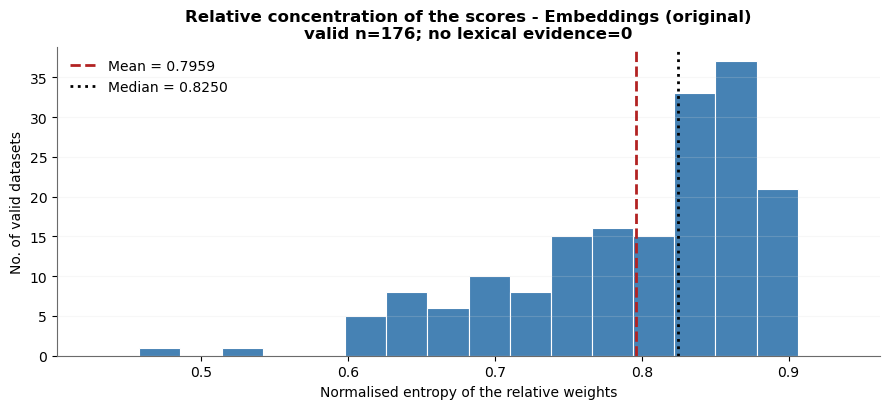

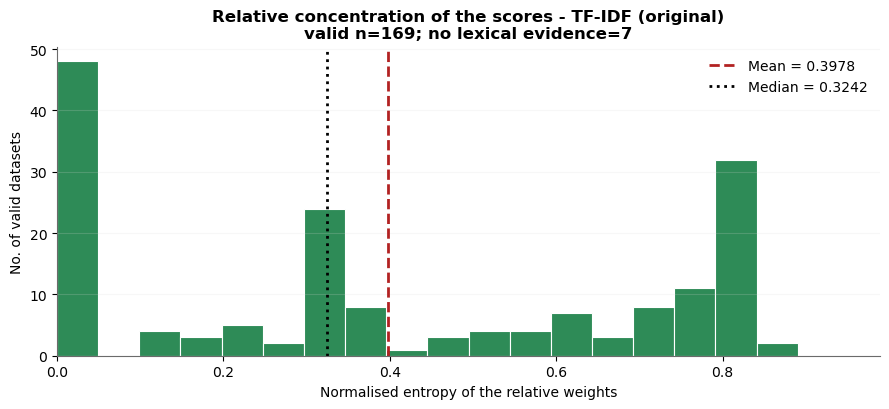

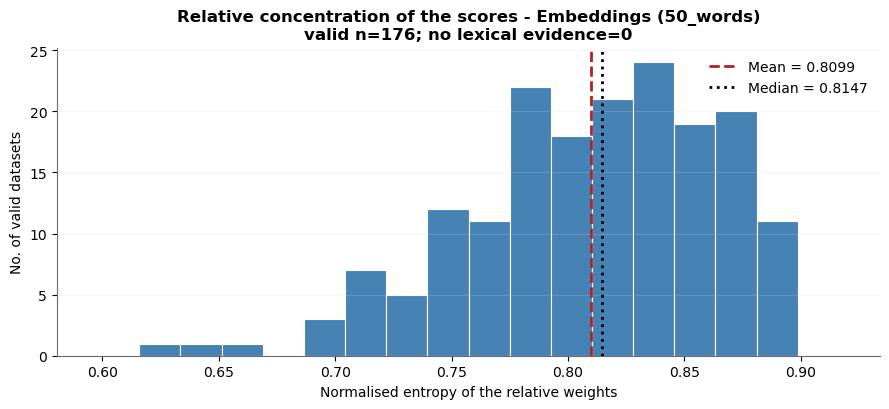

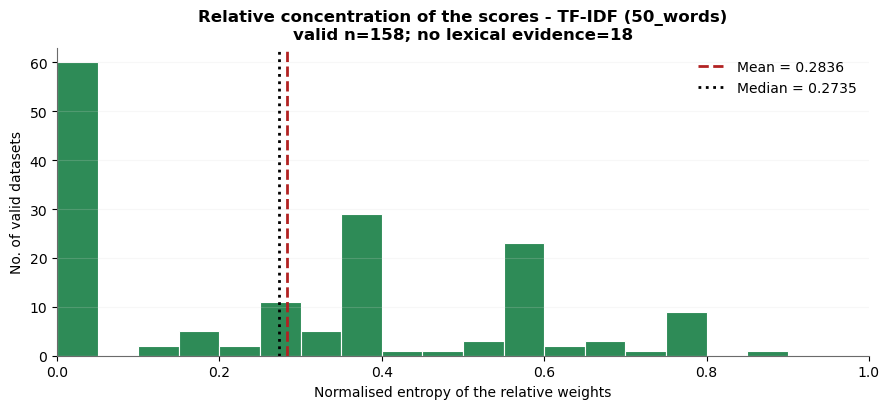

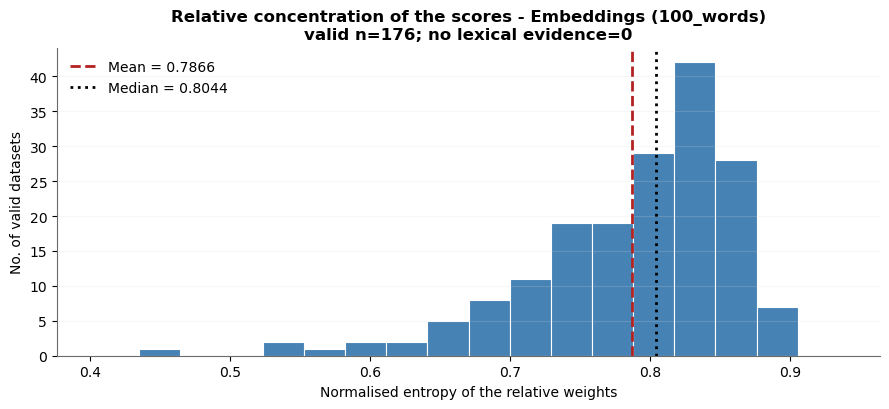

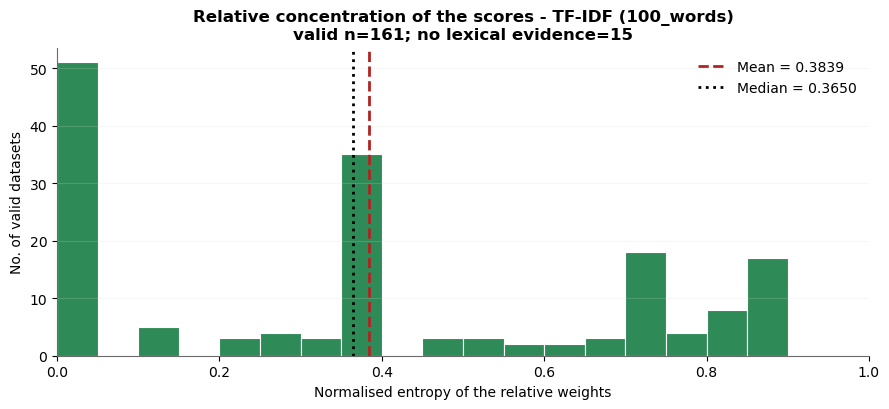

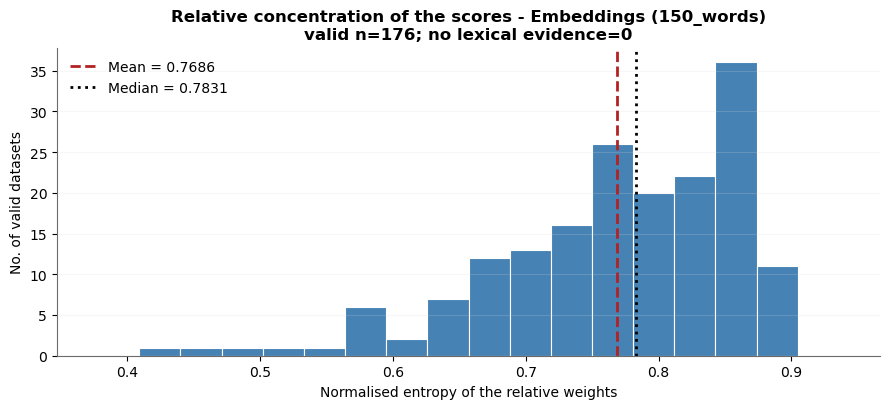

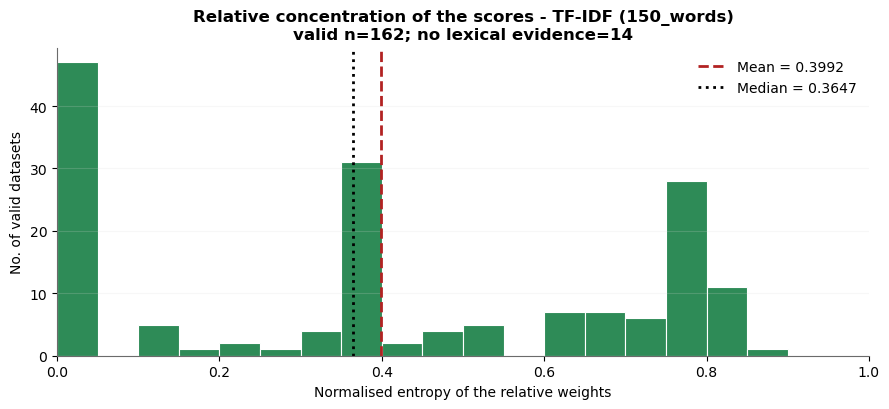

n_total  n_valid_entropy  n_no_lexical_evidence  \
version   method                                                        
original  Embeddings      176              176                      0   
          TF-IDF          176              169                      7   
50_words  Embeddings      176              176                      0   
          TF-IDF          176              158                     18   
100_words Embeddings      176              176                      0   
          TF-IDF          176              161                     15   
150_words Embeddings      176              176                      0   
          TF-IDF          176              162                     14   

                      n_non_finite  mean_normalised_entropy    median  \
version   method                                                        
original  Embeddings             0                 0.795937  0.824976   
          TF-IDF                 0                 0.397759  0.324178   
50_words  Embeddings             0                 0.809883  0.814672   
          TF-IDF                 0                 0.283567  0.273543   
100_words Embeddings             0                 0.786625  0.804387   
          TF-IDF                 0                 0.383919  0.365042   
150_words Embeddings             0                 0.768591  0.783088   
          TF-IDF                 0                 0.399221  0.364677   

                           p25       p75   minimum   maximum  
version   method                                              
original  Embeddings  0.749001  0.862034  0.466559  0.897581  
          TF-IDF      0.000000  0.751639  0.000000  0.860260  
50_words  Embeddings  0.777600  0.851022  0.621307  0.893247  
          TF-IDF      0.000000  0.523453  0.000000  0.873088  
100_words Embeddings  0.748648  0.837242  0.444323  0.896173  
          TF-IDF      0.000000  0.749363  0.000000  0.893307  
150_words Embeddings  0.717251  0.844980  0.418558  0.895263  
          TF-IDF      0.000000  0.743351  0.000000  0.869639

Note: fully zero TF-IDF profiles are reported separately and are not included in the entropy.
The relative weights are not calibrated classification probabilities.


In [41]:
entropy_summary = []

def relative_weights_rows(x):
    """Converts finite scores into relative weights by shifting to the minimum."""
    x = np.asarray(x, dtype=float)
    shifted = x - np.min(x, axis=1, keepdims=True)
    denominator = shifted.sum(axis=1, keepdims=True)
    rel_weights = np.divide(shifted, denominator, out=np.zeros_like(shifted), where=denominator > 0)
    constant_profiles = denominator.ravel() == 0
    rel_weights[constant_profiles] = 1.0 / x.shape[1]
    return rel_weights

def histogram_limits(values_, min_margin=0.01):
    values_ = np.asarray(values_, dtype=float)
    minimum, maximum = float(np.min(values_)), float(np.max(values_))
    score_span = maximum - minimum
    margin = max(min_margin, score_span * 0.15)
    lower_bound, upper_bound = max(0.0, minimum - margin), min(1.0, maximum + margin)
    if upper_bound - lower_bound < 0.02:
        centre = (lower_bound + upper_bound) / 2
        lower_bound, upper_bound = max(0.0, centre - 0.01), min(1.0, centre + 0.01)
    if upper_bound <= lower_bound:
        lower_bound, upper_bound = 0.98, 1.0
    return lower_bound, upper_bound

for version_name, obj in results_by_version.items():
    for method_name, scores_df in [("Embeddings", obj["scores_embeddings"]), ("TF-IDF", obj["scores_tfidf"])]:
        values_ = scores_df.to_numpy(dtype=float)
        n_total = len(values_)
        mask_finite = np.isfinite(values_).all(axis=1)
        n_non_finite = int((~mask_finite).sum())

        if method_name == "TF-IDF":
            # All scores equal to zero = absence of lexical evidence,
            # not an ambiguous distribution across dimensions.
            mask_no_evidence = mask_finite & np.isclose(values_, 0.0).all(axis=1)
        else:
            mask_no_evidence = np.zeros(n_total, dtype=bool)

        mask_valid = mask_finite & ~mask_no_evidence
        valid_values = values_[mask_valid]
        n_no_evidence = int(mask_no_evidence.sum())
        if len(valid_values) == 0:
            print(f"No valid profiles for entropy: {method_name} — {version_name}")
            continue

        rel_weights = relative_weights_rows(valid_values)
        h_raw = np.apply_along_axis(scipy_entropy, 1, rel_weights) / np.log(scores_df.shape[1])
        h = np.clip(h_raw.astype(float), 0.0, 1.0)
        h = h[np.isfinite(h)]
        if len(h) == 0:
            print(f"No finite entropy values: {method_name} — {version_name}")
            continue

        mean_value, median_value = float(np.mean(h)), float(np.median(h))
        p25, p75 = np.quantile(h, [0.25, 0.75])
        entropy_summary.append({
            "version": version_name,
            "method": method_name,
            "n_total": n_total,
            "n_valid_entropy": len(h),
            "n_no_lexical_evidence": n_no_evidence,
            "n_non_finite": n_non_finite,
            "mean_normalised_entropy": mean_value,
            "median": median_value,
            "p25": float(p25),
            "p75": float(p75),
            "minimum": float(np.min(h)),
            "maximum": float(np.max(h)),
        })

        lower_bound, upper_bound = histogram_limits(h)
        bins = np.linspace(lower_bound, upper_bound, 21)
        fig, ax = plt.subplots(figsize=(9, 4.2))
        ax.hist(h, bins=bins, color="steelblue" if method_name == "Embeddings" else "seagreen",
                edgecolor="white", linewidth=0.8)
        ax.axvline(mean_value, color="firebrick", linestyle="--", linewidth=2, label=f"Mean = {mean_value:.4f}")
        ax.axvline(median_value, color="black", linestyle=":", linewidth=2, label=f"Median = {median_value:.4f}")
        ax.set_xlim(lower_bound, upper_bound)
        ax.set_xlabel("Normalised entropy of the relative weights")
        ax.set_ylabel("No. of valid datasets")
        ax.set_title(f"Relative concentration of the scores - {method_name} ({version_name})\n"
                     f"valid n={len(h)}; no lexical evidence={n_no_evidence}")
        ax.legend(); ax.grid(axis="y", alpha=0.2)
        if np.ptp(h) < 1e-6:
            ax.text(0.5, 0.88, "Practically constant distribution", transform=ax.transAxes,
                    ha="center", bbox={"facecolor": "white", "edgecolor": "gray", "alpha": 0.9})
        plt.tight_layout(); plt.show()

entropy_summary_df = pd.DataFrame(entropy_summary)
display(entropy_summary_df.set_index(["version", "method"]))
print("Note: fully zero TF-IDF profiles are reported separately and are not included in the entropy.")
print("The relative weights are not calibrated classification probabilities.")


#### Figure 4.6 (dissertation) — Normalised entropy of the embeddings, original version

Section 4.5 (RQ4). Print version of the entropy histogram of the embeddings in the original version (one of the charts in the cell above), with the mean and the median marked. Panel a) Águeda, c) Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_6_a_entropy_original.png


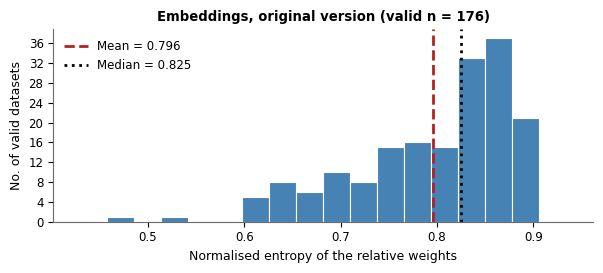

In [42]:
# ── Figure 4.6 (dissertation): normalised entropy, embeddings, original version ─
scores_df = results_by_version["original"]["scores_embeddings"]
rel_weights = relative_weights_rows(scores_df.to_numpy(dtype=float))
h = np.clip(np.apply_along_axis(scipy_entropy, 1, rel_weights) / np.log(scores_df.shape[1]), 0.0, 1.0)
mean_value, median_value = float(np.mean(h)), float(np.median(h))
lower_bound, upper_bound = histogram_limits(h)
with plt.rc_context(DISS_FONT):
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 2.8))
    ax.hist(h, bins=np.linspace(lower_bound, upper_bound, 21), color="steelblue", edgecolor="white", linewidth=0.8)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))   # counts: whole numbers only
    ax.axvline(mean_value, color="firebrick", linestyle="--", linewidth=2, label=num(f"Mean = {mean_value:.3f}"))
    ax.axvline(median_value, color="black", linestyle=":", linewidth=2, label=num(f"Median = {median_value:.3f}"))
    ax.set_xlim(lower_bound, upper_bound)
    ax.set_xlabel("Normalised entropy of the relative weights")
    ax.set_ylabel("No. of valid datasets")
    ax.set_title(f"Embeddings, original version (valid n = {len(h)})")
    ax.legend(loc="upper left")
    plt.tight_layout()
    export_diss_figure(fig, "4.6e", "entropy_original")


**Analysis of the results (7.7 — Normalised entropy).**

The entropy of the Embeddings is high in all versions, with means between 0.769 (150 words) and 0.810 (50 words) and medians between 0.783 and 0.825. The six weights are therefore spread across several dimensions, instead of being concentrated in the winner. The 150-word version is the one that produces slightly more concentrated profiles, in line with its higher mean margin.

In TF-IDF, the mean entropy is much lower (between 0.284 and 0.399), but, as explained in the next note, this results above all from the sparsity of the lexical vectors and not from greater semantic sharpness.

**Rigorous interpretation of the entropy.**

The normalised entropy summarises the relative concentration of the scores after shifting each profile by its own minimum and normalising the sum to 1. This transformation accepts negative similarities and is invariant to positive linear transformations, but the resulting weights are not calibrated probabilities. Values close to 1 indicate a relatively uniform profile; lower values indicate greater relative concentration. The histograms automatically zoom in on the observed range, so the limits of the horizontal axis may vary between method and version. Entropy remains an internal diagnostic, not a measure of accuracy or probabilistic uncertainty.

### 7.8 Cases with an extreme upper delta — 95th percentile

This section identifies the 5% of cases with the highest delta within each method and version. These are cases with a high relative separation between top-1 and top-2, not necessarily correct classifications. The logarithmic transformation is used only for visualisation.

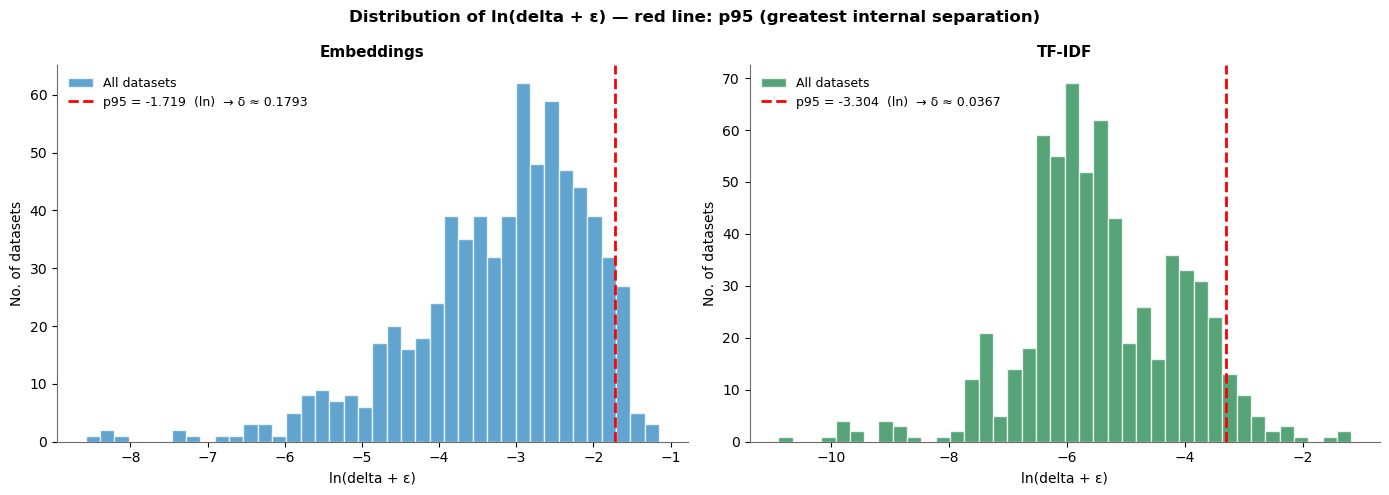


  Embeddings - datasets above the p95 of ln(delta)  (n=36)

  Distribution by dimension:
    Smart Mobility                       34 datasets (94.4%)
    Smart Environment                     2 datasets (5.6%)

  Distribution by anchor version:
    original              13 datasets
    150_words             13 datasets
    100_words              9 datasets
    50_words               1 datasets

  Top 10 with the largest delta (greatest internal top-1/top-2 separation):


,dataset_id,dataset_title,anchor_version,dimension_embeddings,delta_embeddings
0,646c9b52-5af7-4249-adb1-869912b4177b,Transportes públicos,150_words,Smart Mobility,0.316001
1,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,150_words,Smart Mobility,0.308954
2,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,original,Smart Environment,0.236682
3,d7799c71-3dcd-4cbe-92e2-8ef47aeb7914,Infografia trânsito na Piedade,150_words,Smart Mobility,0.230170
4,51cea5e4-cc79-4031-abbd-5e8b502bb8ef,IC2 Aguada de Baixo,150_words,Smart Mobility,0.226483
5,404ac1e9-4f13-492a-833a-81fbcf9bcf2d,Sinais de trânsito,150_words,Smart Mobility,0.217460
6,2c8c47d6-4534-4141-b65a-e8d6da39e064,Rede de transportes públicos - intramunicipal,150_words,Smart Mobility,0.217328
7,451d48bf-ee6b-49c3-bb83-7b222f1ab2c6,IC2 Serém,150_words,Smart Mobility,0.216205
8,00c4b7f5-7e94-4a44-8b90-fcee54d911cd,Percursos pedestres,150_words,Smart Mobility,0.209201
9,8a614816-b768-4376-b721-ca96aaef0d30,Travessa 3,150_words,Smart Mobility,0.207574



  TF-IDF - datasets above the p95 of ln(delta)  (n=33)

  Distribution by dimension:
    Smart Environment                    13 datasets (39.4%)
    Smart Mobility                       12 datasets (36.4%)
    Smart Quality of Life                 3 datasets (9.1%)
    Smart Society                         2 datasets (6.1%)
    Smart Economy                         2 datasets (6.1%)
    Smart Governance                      1 datasets (3.0%)

  Distribution by anchor version:
    50_words              12 datasets
    original               7 datasets
    100_words              7 datasets
    150_words              7 datasets

  Top 10 with the largest delta (greatest internal top-1/top-2 separation):


,dataset_id,dataset_title,anchor_version,dimension_tfidf,delta_tfidf
0,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,150_words,Smart Mobility,0.309464
1,2c8c47d6-4534-4141-b65a-e8d6da39e064,Rede de transportes públicos - intramunicipal,100_words,Smart Mobility,0.119425
2,646c9b52-5af7-4249-adb1-869912b4177b,Transportes públicos,original,Smart Mobility,0.116826
3,b2d1563d-683f-4dff-a472-a68789c9df74,Operadores de Gestão de Resíduos,original,Smart Environment,0.073497
4,3f79f5fd-81cb-4111-aadf-48f1c94db36a,Captações de água subterrânea,150_words,Smart Environment,0.056968
5,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,original,Smart Environment,0.056452
6,06f7e8b9-d84d-4efe-8c08-7f1087a01599,Alojamento turistico,50_words,Smart Economy,0.050175
7,99719160-8d9e-4142-a9b8-960c35ecff39,Rua do Vale Verde,150_words,Smart Environment,0.050131
8,fb481ec2-c270-44eb-a561-ad4cc6eef74c,Rua do Parque Empresarial,50_words,Smart Economy,0.047261
9,51cea5e4-cc79-4031-abbd-5e8b502bb8ef,IC2 Aguada de Baixo,50_words,Smart Mobility,0.046446



Interpretation: these cases show high internal separation between the first
and the second score. This does not prove the substantive accuracy of the assigned dimension
nor its stability across versions; it only identifies internally more separated cases.


In [43]:
EPS = 1e-6  # avoids ln(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Distribution of ln(delta + ε) — red line: p95 (greatest internal separation)",
             fontsize=12, fontweight="bold")

outliers_by_version = {}

for ax, col_delta, col_dim, method, colour in [
    (axes[0], "delta_embeddings", "dimension_embeddings", "Embeddings", "#2E86C1"),
    (axes[1], "delta_tfidf",      "dimension_tfidf",      "TF-IDF",     "#1E8449"),
]:
    # Gather all valid and strictly positive deltas from all versions
    all_items = results_all_versions.dropna(subset=[col_delta, col_dim]).copy()
    all_items = all_items[all_items[col_delta] > 0]   # exclude exact ties (delta=0)

    ln_delta = np.log(all_items[col_delta].values + EPS)
    p95      = np.percentile(ln_delta, 95)

    ax.hist(ln_delta, bins=40, color=colour, alpha=0.75, edgecolor="white", label="All datasets")
    ax.axvline(p95, color="red", linewidth=2, linestyle="--",
               label=f"p95 = {p95:.3f}  (ln)  → δ ≈ {np.exp(p95):.4f}")
    ax.set_xlabel("ln(delta + ε)", fontsize=10)
    ax.set_ylabel("No. of datasets", fontsize=10)
    ax.set_title(f"{method}", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)
    ax.spines[["top","right"]].set_visible(False)

    # Store the outliers
    mask_out = ln_delta >= p95
    outliers_by_version[method] = all_items[mask_out].copy()
    outliers_by_version[method]["ln_delta"] = ln_delta[mask_out]

plt.tight_layout()
plt.show()

# ── Which datasets are outliers and what are their dimensions? ────────────────
for method, col_dim in [("Embeddings", "dimension_embeddings"), ("TF-IDF", "dimension_tfidf")]:
    out = outliers_by_version[method]
    if out.empty:
        print(f"\n{method}: no outliers found.")
        continue

    print(f"\n{'='*70}")
    print(f"  {method} - datasets above the p95 of ln(delta)  (n={len(out)})")
    print(f"{'='*70}")

    # Distribution by dimension
    by_dim = out[col_dim].value_counts()
    print(f"\n  Distribution by dimension:")
    for dim, n in by_dim.items():
        print(f"    {dim:<35} {n:3d} datasets ({n/len(out)*100:.1f}%)")

    # Distribution by version
    print(f"\n  Distribution by anchor version:")
    by_version = out["anchor_version"].value_counts()
    for v, n in by_version.items():
        print(f"    {v:<20} {n:3d} datasets")

    # Top 10 with the largest delta
    print(f"\n  Top 10 with the largest delta (greatest internal top-1/top-2 separation):")
    col_d = "delta_embeddings" if method == "Embeddings" else "delta_tfidf"
    top10 = (out[["dataset_id","dataset_title","anchor_version", col_dim, col_d]]
             .sort_values(col_d, ascending=False)
             .drop_duplicates(subset=["dataset_id"])
             .head(10))
    display(top10.reset_index(drop=True))

print("\nInterpretation: these cases show high internal separation between the first")
print("and the second score. This does not prove the substantive accuracy of the assigned dimension")
print("nor its stability across versions; it only identifies internally more separated cases.")


#### Figure 4.6 (dissertation) — Distribution of ln(delta + ε)

Section 4.5 (RQ4). Print version of the chart above: valid and positive margins of the four versions, on a logarithmic scale, with the 95th percentile marked. Panel b) Águeda, d) Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_6_b_margins_log.png


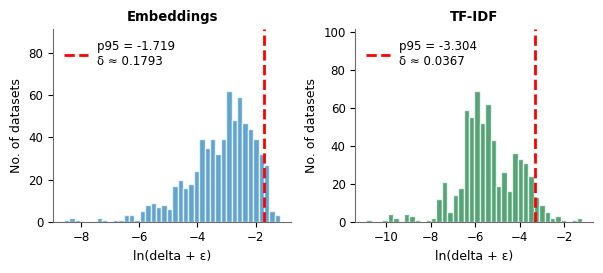

In [44]:
# ── Figure 4.6 (dissertation): ln(delta + ε) with p95 ─────────────────────────
with plt.rc_context(DISS_FONT):
    fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, 2.8))
    for ax, col_delta, col_dim, method, colour in [
        (axes[0], "delta_embeddings", "dimension_embeddings", "Embeddings", "#2E86C1"),
        (axes[1], "delta_tfidf",      "dimension_tfidf",      "TF-IDF",     "#1E8449"),
    ]:
        all_items = results_all_versions.dropna(subset=[col_delta, col_dim]).copy()
        all_items = all_items[all_items[col_delta] > 0]
        ln_delta = np.log(all_items[col_delta].values + EPS)
        p95 = np.percentile(ln_delta, 95)
        ax.hist(ln_delta, bins=40, color=colour, alpha=0.75, edgecolor="white")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.4)        # free space above the bars for the legend
        ax.axvline(p95, color="red", linewidth=2, linestyle="--",
                   label=num(f"p95 = {p95:.3f}\nδ ≈ {np.exp(p95):.4f}"))
        ax.set_xlabel("ln(delta + ε)"); ax.set_ylabel("No. of datasets")
        ax.set_title(method, fontweight="bold")
        ax.legend(loc="upper left")
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    export_diss_figure(fig, "4.6m", "margins_log")


**Analysis of the results (7.8 — Cases with a delta above the 95th percentile).**

In the Embeddings, the 36 dataset-version pairs above the 95th percentile correspond to only 20 different datasets, and 94.4% of them have Mobility as the predominant dimension. The most prominent cases, such as «Transportes públicos» and «Ponto de carregamento de veículos elétricos», are records with vocabulary unmistakably linked to mobility. Almost all these cases come from the original and 150-word versions (13 each), and only one from the 50-word version.

In TF-IDF, the 33 pairs correspond to 14 datasets, split mainly between Environment (39.4%) and Mobility (36.4%), and the 50-word version is the one that contributes most (12 pairs). Extreme separation thus appears almost only in dimensions with very specific technical vocabulary.

**Rigorous interpretation of the cases above p95.**

An extreme delta indicates that the first dimension is more separated from the second on the internal scale of the method. It does not represent a probability of being correct and may occur in a systematically wrong classification. These cases are useful for auditing: a sample should be reviewed manually together with low-delta cases, making it possible to assess both apparently clear classifications and ambiguous cases.

### 7.9 Analysis of the datasets not classified by TF-IDF (score = 0)

TF-IDF assigns a score of 0 to a dataset when there is no lexical overlap between the tokens of the dataset (after pre-processing) and the tokens of any anchor. These datasets are left without a valid classification by the lexical method and are marked with `confidence = "null"`.

Understanding **why** these datasets have a score of 0 is important for two reasons:

1. **Methodological diagnostic**: it makes it possible to assess whether the problem lies in the pre-processing (overly aggressive stopwords that remove relevant tokens), in the anchors (the vocabulary of the anchors is too specific and does not cover the vocabulary of the datasets), or in the datasets themselves (descriptions that are too short or generic);

2. **Identification of datasets for enrichment**: datasets with a TF-IDF score of 0 but with a valid classification in the Embeddings indicate cases in which the semantic method works where the lexical one fails, typically datasets with technical vocabulary, acronyms or unconventional wording.

### The four possible causes

| Cause | What is observed in the text | Solution |
|-------|--------------------------|---------|
| **Empty original text** | `doc_text_embeddings` is also empty | Enrich the dataset in the portal |
| **All tokens are stopwords** | `doc_text_tfidf` empty, but `doc_text_embeddings` has content | Review the stopword list |
| **Insufficient vocabulary** | 1-2 tokens survive, but do not match | Extend the anchors with more vocabulary |
| **Vocabulary without overlap** | Several tokens survive, but they are very specific terms | Extend the anchors or the dataset |

This section shows **5 examples per version** of the real text of these datasets, both in the embeddings version (light cleaning) and in the TF-IDF version (rich cleaning), and produces an automatic diagnostic of the probable cause for each case.



In [45]:
N_EXAMPLES = 5

print("DATASETS WITH TF-IDF SCORE = 0 — CONCRETE EXAMPLES")
print("=" * 80)
print("(score=0 means a complete absence of lexical overlap with the anchors)\n")

for version, obj in results_by_version.items():
    res = obj["results"]
    nc  = res[res["score_top1_tfidf"] == 0].copy()

    print(f"{'─'*80}")
    print(f"  Version: {version}  |  Total unclassified: {len(nc)} / {len(res)} ({len(nc)/len(res)*100:.1f}%)")
    print(f"{'─'*80}")

    if nc.empty:
        print("  ✓ No unclassified dataset in this version.\n")
        continue

    # Join the original text of the datasets for analysis
    examples = nc.merge(
        datasets[["dataset_id", "title", "description",
                  "doc_text_embeddings", "doc_text_tfidf",
                  "n_words_embeddings", "n_words_tfidf"]],
        on="dataset_id", how="left", suffixes=("", "_ds")
    ).head(N_EXAMPLES)

    for _, row in examples.iterrows():
        name_ = str(row.get("dataset_title", row.get("title", "—")))
        desc_emb   = str(row.get("doc_text_embeddings", ""))
        desc_tfidf = str(row.get("doc_text_tfidf", ""))
        n_emb      = int(row.get("n_words_embeddings", 0))
        n_tfidf    = int(row.get("n_words_tfidf", 0))
        dim_emb    = str(row.get("dimension_embeddings", "—"))
        score_emb  = float(row.get("score_top1_embeddings", 0))

        print(f"\n  📄 Dataset: {name_}")
        print(f"     Dimension assigned by Embeddings: {dim_emb}  (score={score_emb:.4f})")
        print(f"     No. of words after light cleaning (emb) : {n_emb}")
        print(f"     No. of words after rich cleaning (tfidf): {n_tfidf}")
        print(f"     ── Embeddings text (first 300 chars):")
        print(f"        {desc_emb[:300]!r}")
        print(f"     ── TF-IDF text after pre-processing:")
        print(f"        {desc_tfidf[:300]!r}")

        # Automatic diagnostic
        if n_tfidf == 0:
            diag = "⚠️  Empty text after TF-IDF pre-processing — all the words were stopwords or short tokens."
        elif n_tfidf <= 3:
            diag = f"⚠️  Only {n_tfidf} token(s) left after pre-processing — very scarce vocabulary."
        else:
            diag = f"ℹ️  {n_tfidf} tokens left but no overlap with the terms of the anchors."
        print(f"     Diagnostic: {diag}")

    print()

# ── Aggregate summary: TF-IDF words in unclassified vs classified ─────────────
print("\n" + "="*80)
print("COMPARISON: No. of TF-IDF words — unclassified vs classified")
print("="*80)

for version, obj in results_by_version.items():
    res = obj["results"]
    # res already has its own n_words_tfidf — no need for a merge
    nc_npal = res.loc[res["score_top1_tfidf"] == 0, "n_words_tfidf"]
    cl_npal = res.loc[res["score_top1_tfidf"]  > 0, "n_words_tfidf"]

    med_nc = nc_npal.median() if len(nc_npal) > 0 else float("nan")
    med_cl = cl_npal.median() if len(cl_npal) > 0 else float("nan")
    print(f"  {version:<20}  unclassified: median={med_nc:.0f} words  |  classified: median={med_cl:.0f} words")

print("\nInterpretation: if the median of the unclassified is much lower,")
print("the main cause is the scarcity of vocabulary after pre-processing.")


DATASETS WITH TF-IDF SCORE = 0 — CONCRETE EXAMPLES
(score=0 means a complete absence of lexical overlap with the anchors)

────────────────────────────────────────────────────────────────────────────────
  Version: original  |  Total unclassified: 7 / 176 (4.0%)
────────────────────────────────────────────────────────────────────────────────

  📄 Dataset: Coretos
     Dimension assigned by Embeddings: Smart Quality of Life  (score=0.2327)
     No. of words after light cleaning (emb) : 9
     No. of words after rich cleaning (tfidf): 3
     ── Embeddings text (first 300 chars):
        'Coretos Localização de coretos clássicos no Município de Águeda.'
     ── TF-IDF text after pre-processing:
        'coretos coreto classico'
     Diagnostic: ⚠️  Only 3 token(s) left after pre-processing — very scarce vocabulary.

  📄 Dataset: Caminho de Santiago
     Dimension assigned by Embeddings: Smart Economy  (score=0.1219)
     No. of words after light cleaning (emb) : 37
     No. of words after

**Analysis of the results (7.9 — Concrete examples of datasets without a TF-IDF classification).**

The qualitative examples illustrate two distinct causes for a TF-IDF score of 0, which should be
kept separate:

1. **Vocabulary too scarce**: datasets such as "Coretos" or "Cidade de Águeda" have only 1 to 3
   valid tokens after cleaning (stopword removal, normalisation) — there is simply not enough lexical
   mass for any match with the anchors, regardless of the theme.
2. **Sufficient vocabulary but no thematic overlap**: cases such as "Caminho de Santiago" have a
   reasonable number of tokens (in the order of 10-15), but none matches the vocabulary of the anchors
   of any of the 6 dimensions - the theme (pilgrimage route) simply has no vocabulary
   shared with the Smart City taxonomy used.

This distinction is methodologically relevant: the first case is a limitation of the source dataset
(description too poor), whereas the second is a limitation of the thematic coverage of the anchors
(the 6-dimension taxonomy may not cover all the themes present in the open data portal).

#### 7.9.1 Length of the texts without a TF-IDF classification and breakdown by series

Comparison of the number of terms after pre-processing between the records without a TF-IDF classification and the others, and breakdown of the records without a classification by document series (Section 4.3 of the dissertation).

In [46]:
# ── 7.9.1 Terms in the zero cases vs. the others; zero cases by series ─────────
_row_med, _row_ser = [], []
_nterms = datasets.set_index("dataset_id")["n_words_tfidf"]
for _v, _obj in results_by_version.items():
    _r = _obj["results"].set_index("dataset_id")
    _zero = _r["score_top1_tfidf"] == 0
    _row_med.append({"version": _v, "n_zero": int(_zero.sum()),
                     "median_terms_zero": float(_nterms.reindex(_r.index)[_zero.to_numpy()].median()),
                     "median_terms_others": float(_nterms.reindex(_r.index)[(~_zero).to_numpy()].median()),
                     "min_terms_zero": int(_nterms.reindex(_r.index)[_zero.to_numpy()].min()) if _zero.any() else None,
                     "max_terms_zero": int(_nterms.reindex(_r.index)[_zero.to_numpy()].max()) if _zero.any() else None})
    _cnt = SERIES_BY_ID.reindex(_r.index)[_zero.to_numpy()].value_counts()
    _row_ser.append({"version": _v, "n_zero": int(_zero.sum()), **_cnt.to_dict()})
zeros_terms = pd.DataFrame(_row_med)
zeros_series = pd.DataFrame(_row_ser).fillna(0)
zeros_series[zeros_series.columns[1:]] = zeros_series[zeros_series.columns[1:]].astype(int)
DISSERTATION_COUNTS["TF-IDF zeros - terms"] = zeros_terms
DISSERTATION_COUNTS["TF-IDF zeros - series"] = zeros_series
print("Number of terms (after pre-processing) in the records without a TF-IDF classification and in the others:")
display(zeros_terms)
print("Records without a TF-IDF classification, by document series:")
display(zeros_series)

Number of terms (after pre-processing) in the records without a TF-IDF classification and in the others:


,version,n_zero,median_terms_zero,median_terms_others,min_terms_zero,max_terms_zero
0,original,7,5.0,14.0,1,14
1,50_words,18,5.0,14.0,1,14
2,100_words,15,5.0,14.0,1,14
3,150_words,14,5.0,14.0,1,14


Records without a TF-IDF classification, by document series:


,version,n_zero,Outside the series
0,original,7,7
1,50_words,18,18
2,100_words,15,15
3,150_words,14,14


### 7.10 Post-argmax classification: single-label, multi-label, transversal and indeterminate

Up to this point, each dataset has been classified by the **argmax** rule — the dimension with the highest similarity score is always assigned. This rule is simple, but **it always assigns a single label, even when the scores of the six dimensions are very close to one another**.

Two datasets with very different score profiles may receive exactly the same treatment:

```
Dataset A:  Mobility=0.84  Environment=0.79  Economy=0.43  ...  → "Smart Mobility"
Dataset B:  Mobility=0.55  Environment=0.54  Economy=0.53  ...  → "Smart Mobility"
```

(Illustrative values, not taken from the corpus.) In Dataset A, Mobility and Environment stand out from the others. In Dataset B, the first three dimensions are practically tied — the choice of the first depends on minimal differences and should not be taken as definitive.

This section adds a **post-argmax decision layer** (Section 3.5.1 of the dissertation) that distinguishes four situations:

| State | When it occurs | What it means |
|---|---|---|
| `single_label` | None of the following conditions | Top-1 kept without an automatic flag (does not imply that it is correct) |
| `multi_label_candidate` | At least one close alternative and a reduced margin | Top-1 and top-2 to be reviewed as a possible dual assignment |
| `transversal_candidate` | 3+ close dimensions or a profile with little dispersion | Sign of low discrimination; the candidates follow `n_close` |
| `indeterminate` | Metadata with fewer than 8 words or a weak maximum score | Insufficient textual evidence; review |

The rule is applied **to the four anchor versions and to the two methods**, like the other analyses in the chapter. Each combination of version and method has its own thresholds, because the distribution of the scores changes with the wording of the anchors and with the textual representation.

#### Metrics used in the decision

From the six similarity scores of each dataset, five auxiliary metrics are computed:

| Metric | Formula | Interpretation |
|---|---|---|
| `s1` | `max(scores)` | Strength of the best association |
| `margin_12` | `s1 − s2` | Margin between the 1st and the 2nd dimension (the delta) |
| `score_range` | `max − min` of the 6 scores | Range of the profile |
| `score_sd` | Standard deviation of the 6 scores | Alternative dispersion |
| `n_close` | No. of dimensions with score ≥ s1 − `delta_close`, **including the winner itself** | `n_close = 1`: no close alternative; `n_close ≥ 2`: at least one close alternative |

#### Empirical percentile thresholds

The thresholds **are not fixed values**: they are computed for each version and each method from the distribution observed in this corpus, excluding non-positive top-1 scores. They are empirical thresholds that depend on the corpus, the version and the method, not universal values:

| Threshold | Calculation | Meaning |
|---|---|---|
| `theta_low` | 5th percentile of `s1` (`PERCENTILE_WEAK_SCORE`) | At or below this value, the best score is considered weak → indeterminate |
| `delta_close` | 25th percentile of `margin_12` (`PERCENTILE_CLOSE_MARGIN`) | At or below this value, the 1st and the 2nd dimension are considered "close" |
| `range_low` | 25th percentile of `score_range` (`PERCENTILE_DIFFUSE_RANGE`) | Below this value, the six scores are considered "diffuse" → transversal |

The 5th percentile for `theta_low` flags, by construction, about 5% of the cases with the weakest maximum score. The 25th percentile for `delta_close` and `range_low` corresponds to the first quartile — the quarter of the datasets with the least separation between dimensions.

#### Decision logic (order of priority)

```
1. If the metadata have fewer than 8 words (MIN_WORDS) → indeterminate
2. If s1 = 0 OR s1 ≤ theta_low → indeterminate
3. If n_close ≥ 3 OR score_range < range_low → transversal_candidate
4. If n_close ≥ 2 AND margin_12 ≤ delta_close → multi_label_candidate
5. Otherwise → single_label
```

The order matters: the check for poor metadata and a weak score takes priority over transversality, which takes priority over multi-label. All states other than `single_label` receive `review_flag=True`. The rule is an exploratory triage mechanism for human review, not a validated classification.

#### Organisation of the section

| Subsection | Content |
|---|---|
| 7.10.1 | Score profiles and thresholds, by version and method |
| 7.10.2 | Distributions of the metrics with the thresholds marked |
| 7.10.3 | Application of the rule and distribution of the states by version and method |
| 7.10.4 | Visualisation of the states and agreement of state between methods |
| 7.10.5 | State of each dataset in the four versions |
| 7.10.6 | Cases for human review |
| 7.10.7 | Sensitivity of the rule to the parameters |
| 7.10.8 | Global review and candidate dimensions |
| 7.10.9 | Pairs of candidate dimensions and transversality by range |

#### 7.10.1 Score profiles and thresholds, by version and method

For each anchor version, the profile table is built (scores of the six dimensions and auxiliary metrics, for both methods) and the three percentile thresholds are computed, separately for Embeddings and TF-IDF.

In [47]:
# ── 7.10.1 Score profiles and empirical thresholds, by version and method ─────
VERSIONS_710 = list(results_by_version.keys())
METHODS_710 = [("emb", "Embeddings"), ("tfidf", "TF-IDF")]
STATE_ORDER = ["single_label", "multi_label_candidate", "transversal_candidate", "indeterminate"]


def compute_profile_metrics(df_res, score_cols, dims, suffix):
    """
    For each dataset, extracts the full profile of the similarity scores and
    computes the auxiliary metrics described in the introduction to this section.
    """
    matrix = df_res[score_cols].values   # shape: (n_datasets, n_dims)
    n      = len(df_res)

    # Sort the scores by row (descending) to extract top-1, top-2, top-3
    sorted_idx    = np.argsort(-matrix, axis=1)
    sorted_scores = np.take_along_axis(matrix, sorted_idx, axis=1)

    s1 = sorted_scores[:, 0]
    s2 = sorted_scores[:, 1]
    s3 = sorted_scores[:, 2] if matrix.shape[1] > 2 else s2

    top1_label = [dims[sorted_idx[i, 0]] for i in range(n)]
    top2_label = [dims[sorted_idx[i, 1]] for i in range(n)]
    top3_label = [dims[sorted_idx[i, 2]] for i in range(n)] if len(dims) > 2 else top2_label

    return pd.DataFrame({
        f"top1_label_{suffix}": top1_label,
        f"top1_score_{suffix}": s1,
        f"top2_label_{suffix}": top2_label,
        f"top2_score_{suffix}": s2,
        f"top3_label_{suffix}": top3_label,
        f"top3_score_{suffix}": s3,
        f"margin_12_{suffix}":  s1 - s2,
        f"margin_23_{suffix}":  s2 - s3,
        f"score_range_{suffix}": matrix.max(axis=1) - matrix.min(axis=1),
        f"score_sd_{suffix}":    matrix.std(axis=1),
    }, index=df_res.index)


def build_profile_table(res):
    """Working table of the post-argmax rule for one anchor version."""
    score_cols_emb   = sorted([c for c in res.columns if c.startswith("score_emb_")], key=dim_col_key)
    score_cols_tfidf = sorted([c for c in res.columns if c.startswith("score_tfidf_")], key=dim_col_key)
    dims = [c.replace("score_emb_", "") for c in score_cols_emb]
    table = pd.concat([
        res[["dataset_id", "dataset_title", "dataset_description",
             "n_words_embeddings", "n_words_tfidf"]],
        compute_profile_metrics(res, score_cols_emb,   dims, "emb"),
        compute_profile_metrics(res, score_cols_tfidf, dims, "tfidf"),
    ], axis=1)
    # The six scores of each method are kept in the table (needed for n_close)
    for col in score_cols_emb + score_cols_tfidf:
        table[col] = res[col].to_numpy()
    return table


def compute_thresholds(table, suffix):
    """Percentile thresholds, excluding non-positive top-1 scores (no signal)."""
    valid_mask = table[f"top1_score_{suffix}"] > 0
    return {
        "theta_low":   float(table.loc[valid_mask, f"top1_score_{suffix}"].quantile(PERCENTILE_WEAK_SCORE / 100)),
        "delta_close": float(table.loc[valid_mask, f"margin_12_{suffix}"].quantile(PERCENTILE_CLOSE_MARGIN / 100)),
        "range_low":   float(table.loc[valid_mask, f"score_range_{suffix}"].quantile(PERCENTILE_DIFFUSE_RANGE / 100)),
        "n_valid":   int(valid_mask.sum()),
    }


tables_710, thresholds_710 = {}, {}
for version in VERSIONS_710:
    tables_710[version] = build_profile_table(results_by_version[version]["results"])
    thresholds_710[version] = {suf: compute_thresholds(tables_710[version], suf) for suf, _ in METHODS_710}

post_argmax_thresholds_df = pd.DataFrame([
    {"version": version, "method": name_, **thresholds_710[version][suf],
     "percentile_theta_low": PERCENTILE_WEAK_SCORE,
     "percentile_delta_close": PERCENTILE_CLOSE_MARGIN,
     "percentile_range_low": PERCENTILE_DIFFUSE_RANGE}
    for version in VERSIONS_710 for suf, name_ in METHODS_710
])

print(f"Profile tables: {len(VERSIONS_710)} versions × {len(tables_710[VERSIONS_710[0]])} datasets")
print("\nEmpirical thresholds by version and method (n_valid = datasets with s1 > 0):")
display(post_argmax_thresholds_df.round(4))
print("The TF-IDF thresholds are lower than those of the Embeddings because the TF-IDF scores")
print("have a smaller magnitude; fixed thresholds are therefore not transferred between methods or versions.")

Profile tables: 4 versions × 176 datasets

Empirical thresholds by version and method (n_valid = datasets with s1 > 0):


,version,method,theta_low,delta_close,range_low,n_valid,percentile_theta_low,percentile_delta_close,percentile_range_low
0,original,Embeddings,0.2253,0.0188,0.1574,176,5,25,25
1,original,TF-IDF,0.0018,0.0026,0.0050,169,5,25,25
2,50_words,Embeddings,0.1889,0.0231,0.1521,176,5,25,25
3,50_words,TF-IDF,0.0029,0.0024,0.0050,158,5,25,25
4,100_words,Embeddings,0.1796,0.0219,0.1276,176,5,25,25
5,100_words,TF-IDF,0.0021,0.0018,0.0038,161,5,25,25
6,150_words,Embeddings,0.2029,0.0289,0.1449,176,5,25,25
7,150_words,TF-IDF,0.0018,0.0018,0.0034,162,5,25,25


The TF-IDF thresholds are lower than those of the Embeddings because the TF-IDF scores
have a smaller magnitude; fixed thresholds are therefore not transferred between methods or versions.


#### 7.10.2 Distributions of the metrics with the thresholds marked

For each version, the histograms show the distribution of the top-1 score, of the margin between the 1st and the 2nd dimension and of the range of the profile, with the corresponding threshold as a red dashed line. The shaded area corresponds to the values that fall below the threshold.

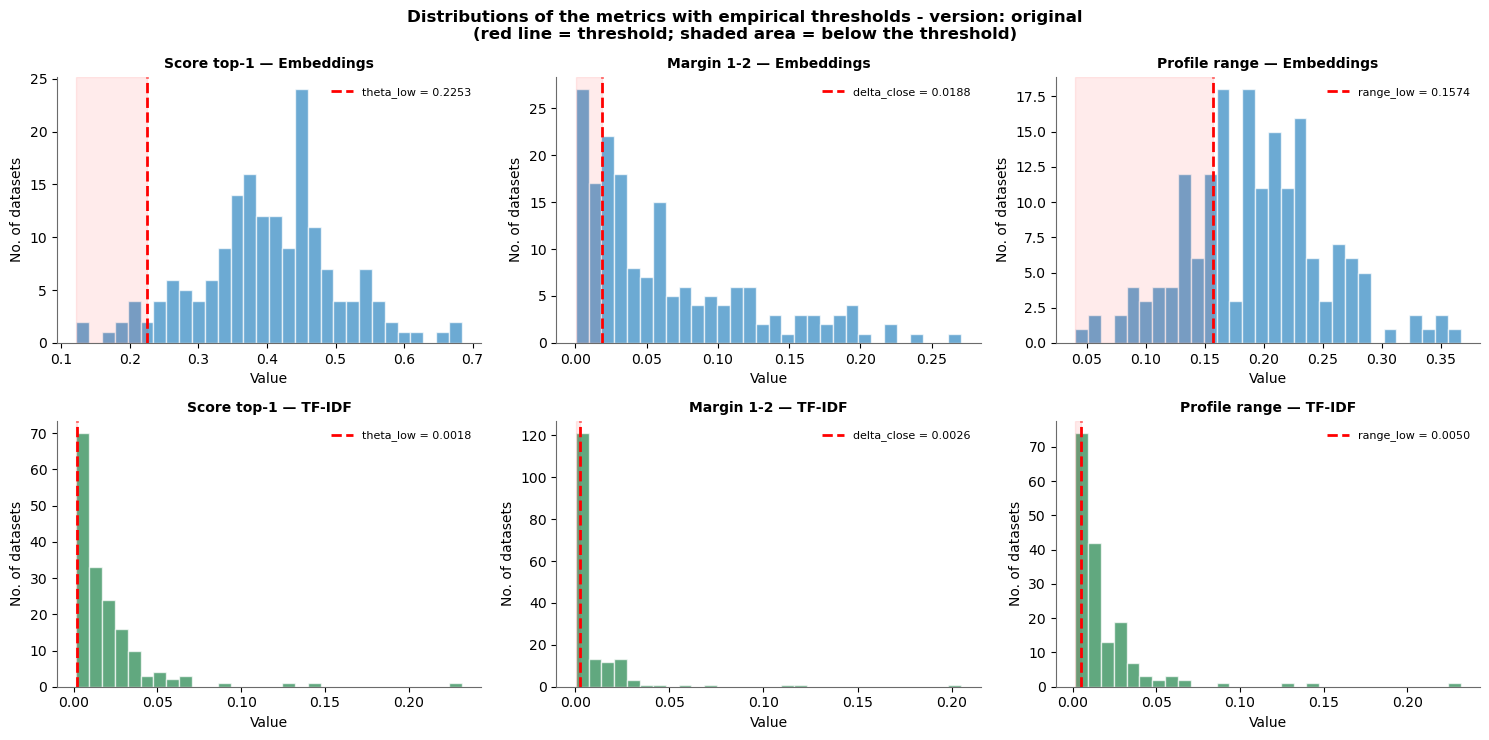

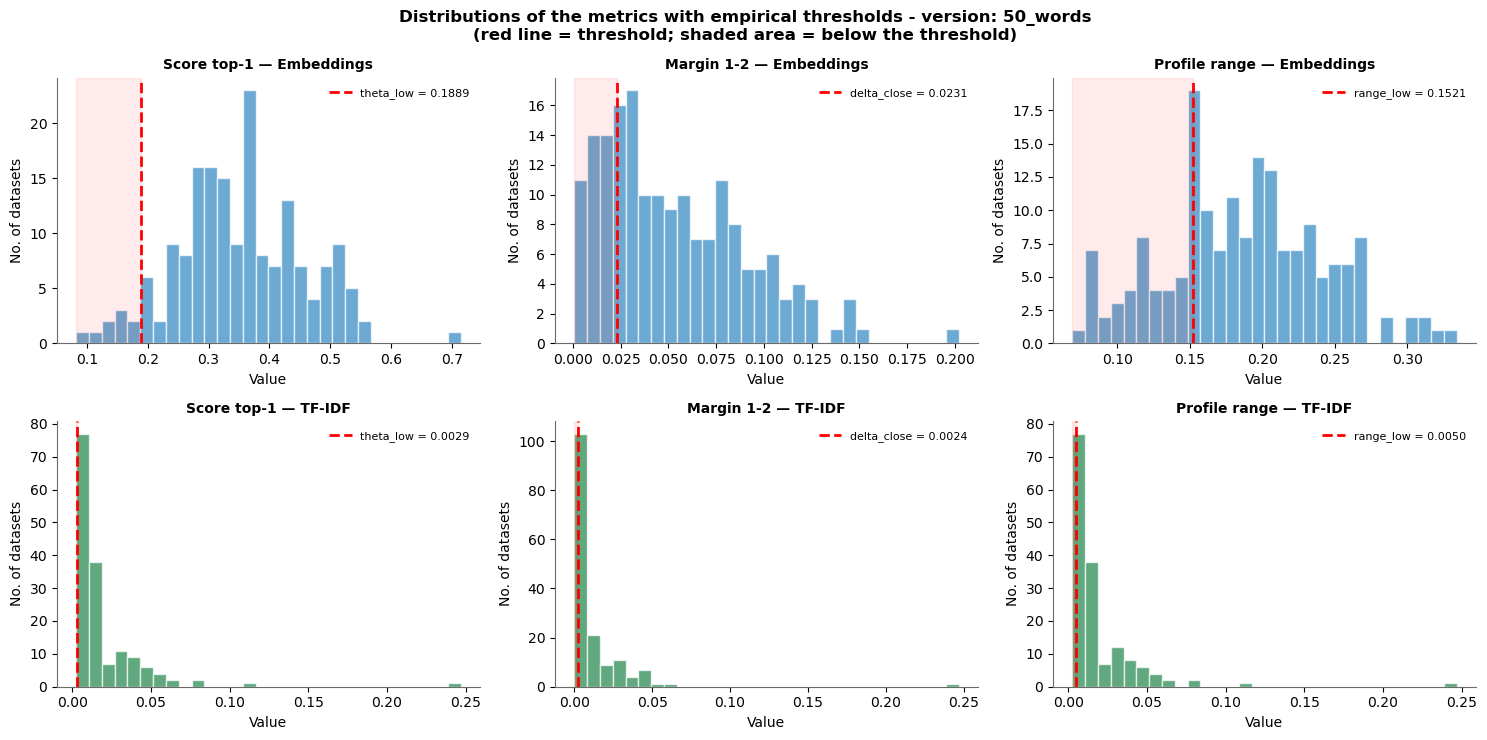

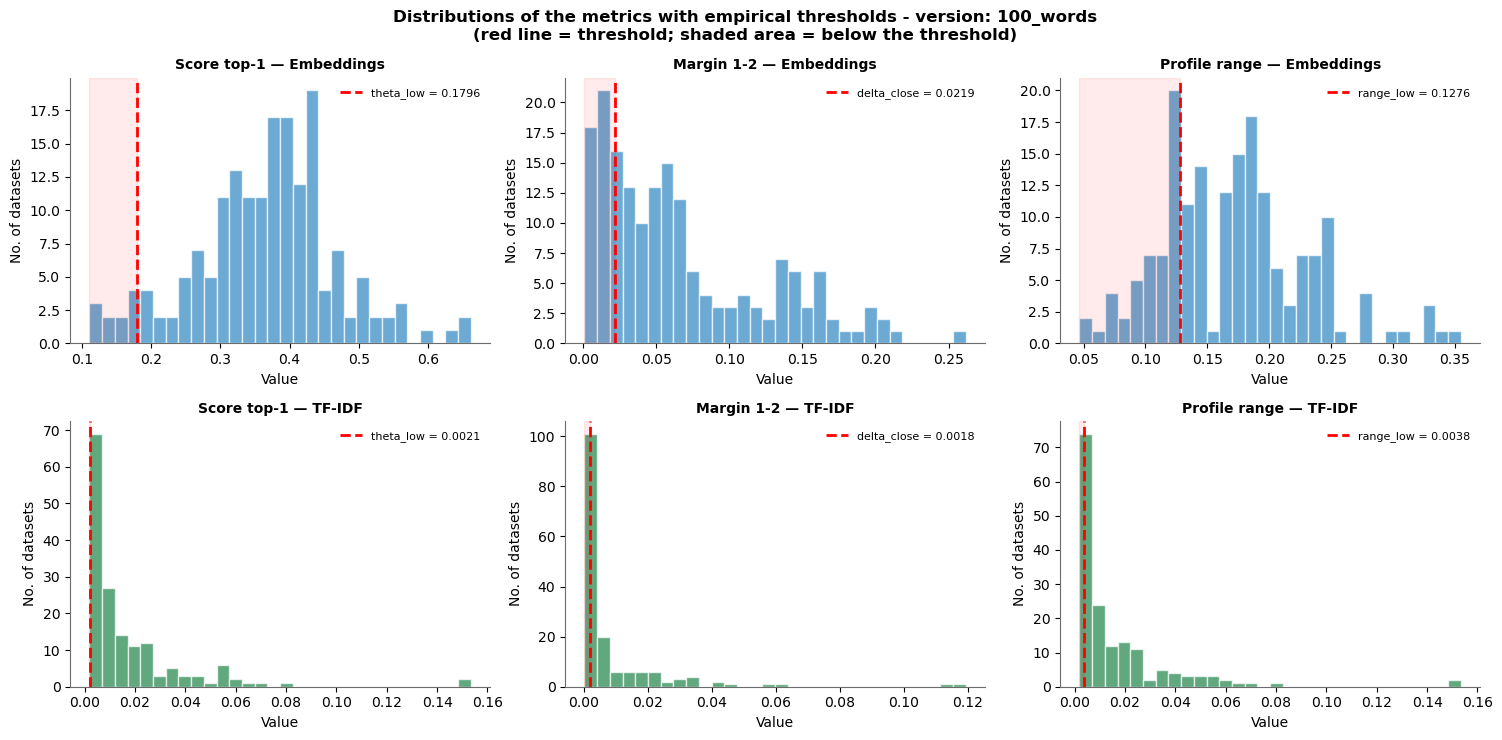

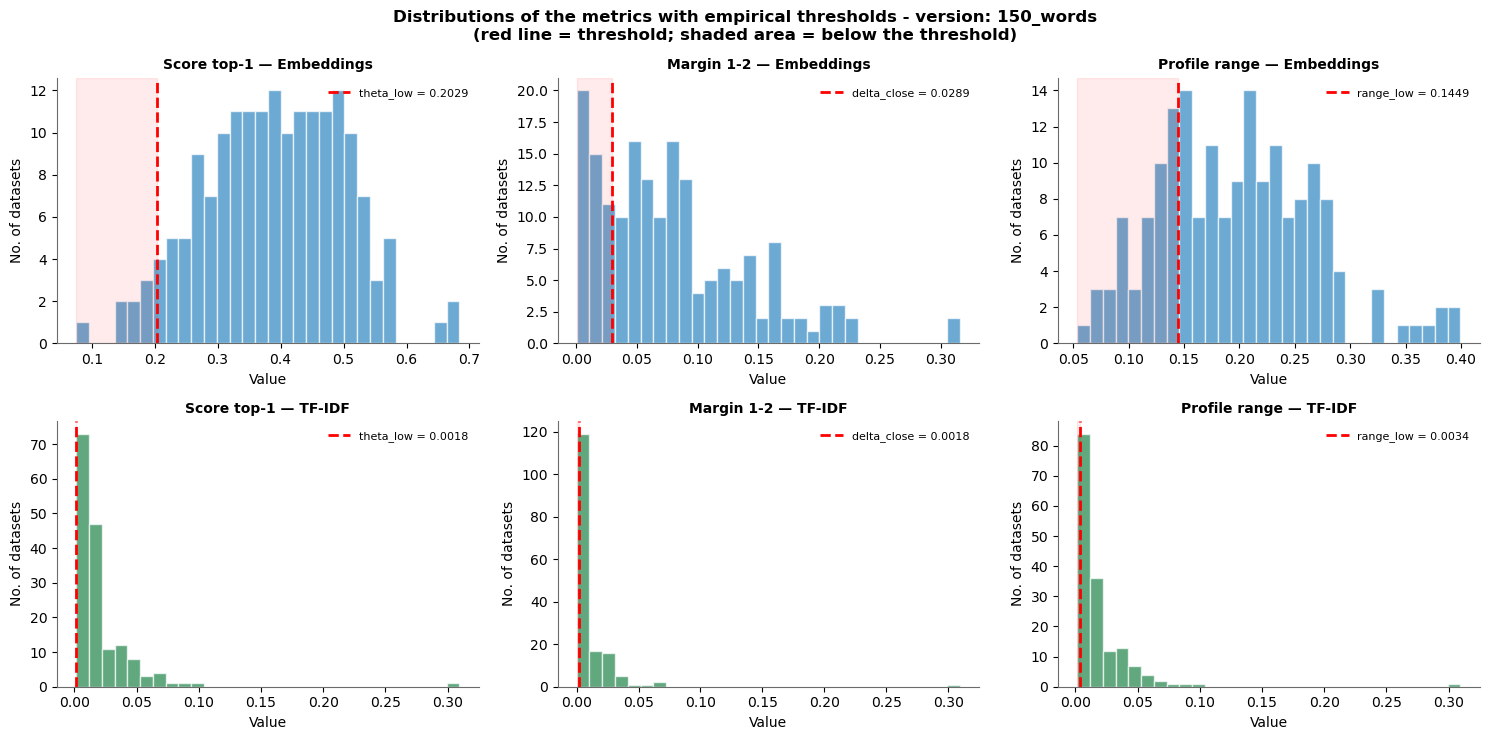

In [48]:
# ── 7.10.2 Distributions of the metrics with the thresholds marked (by version) ─
method_colours = {"emb": "#2E86C1", "tfidf": "#1E8449"}
plot_metrics = [("top1_score", "theta_low", "Score top-1"),
                 ("margin_12", "delta_close", "Margin 1-2"),
                 ("score_range", "range_low", "Profile range")]

for version in VERSIONS_710:
    tab = tables_710[version]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
    fig.suptitle(f"Distributions of the metrics with empirical thresholds - version: {version}\n"
                 "(red line = threshold; shaded area = below the threshold)",
                 fontsize=12, fontweight="bold")
    for row_data, (suf, name_) in enumerate(METHODS_710):
        valid_mask = tab[f"top1_score_{suf}"] > 0
        for column_name, (met, lim, title_text) in enumerate(plot_metrics):
            ax = axes[row_data][column_name]
            data_rows = tab.loc[valid_mask, f"{met}_{suf}"]
            threshold = thresholds_710[version][suf][lim]
            ax.hist(data_rows, bins=30, color=method_colours[suf], alpha=0.7, edgecolor="white")
            ax.axvline(threshold, color="red", linewidth=2, linestyle="--", label=f"{lim} = {threshold:.4f}")
            ax.axvspan(data_rows.min(), threshold, alpha=0.08, color="red")
            ax.set_title(f"{title_text} — {name_}", fontsize=10, fontweight="bold")
            ax.set_xlabel("Value"); ax.set_ylabel("No. of datasets")
            ax.legend(fontsize=8)
            ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

**Analysis of the results (7.10.1–7.10.2 — Empirical thresholds and distribution of the metrics).**

The thresholds change with the version and, above all, with the method. In the Embeddings, the minimum score not considered weak (theta_low) ranges from 0.180 to 0.225, the margin that defines two close dimensions (delta_close) from 0.019 to 0.029 and the range that defines a diffuse profile (range_low) from 0.128 to 0.157. In TF-IDF, the same thresholds are about a hundred times smaller, as can be seen in the distribution charts. By construction, each threshold isolates the lower tail of the respective distribution: 5% of the cases for the maximum score and about 25% for the margin and the range.

#### 7.10.3 Application of the rule and distribution of the states

The rule is applied separately to each version and each method, with the thresholds of Section 7.10.1. The summary presents, for each combination, the number and percentage of datasets in each state and the proportion flagged for review. The second table brings the two methods together: at this stage, a dataset counts as flagged when at least one method assigns it a state other than `single_label`. Disagreement between two `single_label` states is added in the global review (7.10.8).

In [49]:
# ── 7.10.3 Application of the decision rule to the four versions ─────────────
#
# decision_rule applies the 5 rules in cascade (the order matters):
#   1. Poor metadata   → indeterminate
#   2. Weak score      → indeterminate
#   3. Diffuse profile → transversal_candidate
#   4. Two close dimensions → multi_label_candidate
#   5. Otherwise       → single_label
# It is applied separately for Embeddings and TF-IDF: the same dataset may have
# different states in the two methods.

def decision_rule(row, suffix, theta_low, delta_close, range_low):
    """
    Applies the post-argmax decision logic to one row of the table.
    Returns a dictionary with:
      - primary_label          : main dimension (or None)
      - secondary_labels       : list of secondary dimensions (or [])
      - candidate_labels       : all candidate dimensions considered
      - classification_status  : single_label / multi_label_candidate /
                                 transversal_candidate / indeterminate
      - review_flag            : True if the case requires human review
    """
    s1         = row[f"top1_score_{suffix}"]
    l1         = row[f"top1_label_{suffix}"]
    l2         = row[f"top2_label_{suffix}"]
    l3         = row[f"top3_label_{suffix}"]
    margin_12  = row[f"margin_12_{suffix}"]
    score_range= row[f"score_range_{suffix}"]
    n_words = row["n_words_embeddings"]   # same for both methods
    n_close    = row[f"n_close_{suffix}"]

    # Rule 1: insufficient metadata
    if n_words < MIN_WORDS:
        return {"primary_label": None, "secondary_labels": [],
                "candidate_labels": [], "review_flag": True,
                f"classification_status_{suffix}": "indeterminate",
                f"reason_{suffix}": "insufficient metadata"}

    # Rule 2: maximum score too low
    if s1 <= theta_low or s1 == 0:
        return {"primary_label": None, "secondary_labels": [],
                "candidate_labels": [l1] if s1 > 0 else [],
                "review_flag": True,
                f"classification_status_{suffix}": "indeterminate",
                f"reason_{suffix}": f"weak score (s1={s1:.4f} ≤ θ={theta_low:.4f})"}

    # Rule 3: diffuse profile — 3+ close dimensions OR low range
    if n_close >= 3 or score_range < range_low:
        return {"primary_label": None, "secondary_labels": [],
                "candidate_labels": [l1, l2, l3],
                "review_flag": True,
                f"classification_status_{suffix}": "transversal_candidate",
                f"reason_{suffix}": f"diffuse profile: n_close={n_close}; range={score_range:.4f}; threshold={range_low:.4f}"}

    # Rule 4: two close dimensions
    if n_close >= 2 and margin_12 <= delta_close:
        return {"primary_label": l1, "secondary_labels": [l2],
                "candidate_labels": [l1, l2],
                "review_flag": True,
                f"classification_status_{suffix}": "multi_label_candidate",
                f"reason_{suffix}": f"margin_12={margin_12:.4f} ≤ δ={delta_close:.4f}"}

    # Rule 5: single-label
    return {"primary_label": l1, "secondary_labels": [],
            "candidate_labels": [l1],
            "review_flag": False,
            f"classification_status_{suffix}": "single_label",
            f"reason_{suffix}": f"margin_12={margin_12:.4f} ≥ δ={delta_close:.4f}"}


def apply_rule(table, thresholds):
    """Computes n_close and applies decision_rule to the two methods of one version."""
    for suffix, _ in METHODS_710:
        score_cols_s = sorted([c for c in table.columns if c.startswith(f"score_{suffix}_")], key=dim_col_key)
        matrix = table[score_cols_s].to_numpy(dtype=float)
        s1_vec = matrix.max(axis=1)
        table[f"n_close_{suffix}"] = (
            matrix >= (s1_vec - thresholds[suffix]["delta_close"]).reshape(-1, 1)
        ).sum(axis=1)

    for suffix, _ in METHODS_710:
        lim = thresholds[suffix]
        decisions = table.apply(
            lambda row: decision_rule(row, suffix, lim["theta_low"], lim["delta_close"], lim["range_low"]),
            axis=1)
        decisions_df = pd.DataFrame(list(decisions))
        table[f"status_{suffix}"]     = decisions_df[f"classification_status_{suffix}"].values
        table[f"reason_{suffix}"]     = decisions_df[f"reason_{suffix}"].values
        table[f"primary_{suffix}"]    = decisions_df["primary_label"].values
        table[f"secondary_{suffix}"]  = decisions_df["secondary_labels"].apply(str).values
        table[f"candidates_{suffix}"] = decisions_df["candidate_labels"].apply(str).values
        table[f"review_{suffix}"]     = decisions_df["review_flag"].values
    return table


for version in VERSIONS_710:
    tables_710[version] = apply_rule(tables_710[version], thresholds_710[version])

# ── Summary by version and method ─────────────────────────────────────────────
rows_summary = []
for version in VERSIONS_710:
    tab, n = tables_710[version], len(tables_710[version])
    for suf, name_ in METHODS_710:
        cont = tab[f"status_{suf}"].value_counts().reindex(STATE_ORDER, fill_value=0)
        row_data = {"version": version, "method": name_, "n_datasets": n}
        for state in STATE_ORDER:
            row_data[f"n_{state}"] = int(cont[state])
            row_data[f"pct_{state}"] = round(cont[state] / n * 100, 1)
        row_data["n_review"] = int(tab[f"review_{suf}"].sum())
        row_data["pct_review"] = round(tab[f"review_{suf}"].mean() * 100, 1)
        rows_summary.append(row_data)
post_argmax_summary_df = pd.DataFrame(rows_summary)

post_argmax_version_summary_df = pd.DataFrame([{
    "version": version,
    "n_datasets": len(tab),
    "n_review_any_method": int((tab["review_emb"] | tab["review_tfidf"]).sum()),
    "pct_review_any_method": round((tab["review_emb"] | tab["review_tfidf"]).mean() * 100, 1),
    "n_review_both_methods": int((tab["review_emb"] & tab["review_tfidf"]).sum()),
    "pct_review_both_methods": round((tab["review_emb"] & tab["review_tfidf"]).mean() * 100, 1),
    "pct_same_state_methods": round((tab["status_emb"] == tab["status_tfidf"]).mean() * 100, 1),
} for version, tab in tables_710.items()])

print("Post-argmax states by version and method (n and %):")
display(post_argmax_summary_df.set_index(["version", "method"]))
print("Flagging for review combining the two methods:")
display(post_argmax_version_summary_df.set_index("version"))

Post-argmax states by version and method (n and %):


n_datasets  n_single_label  pct_single_label  \
version   method                                                     
original  Embeddings         176             109              61.9   
          TF-IDF             176             108              61.4   
50_words  Embeddings         176             104              59.1   
          TF-IDF             176              84              47.7   
100_words Embeddings         176             114              64.8   
          TF-IDF             176              86              48.9   
150_words Embeddings         176             110              62.5   
          TF-IDF             176             100              56.8   

                      n_multi_label_candidate  pct_multi_label_candidate  \
version   method                                                           
original  Embeddings                       19                       10.8   
          TF-IDF                           18                       10.2   
50_words  Embeddings                       24                       13.6   
          TF-IDF                           28                       15.9   
100_words Embeddings                       14                        8.0   
          TF-IDF                           15                        8.5   
150_words Embeddings                       17                        9.7   
          TF-IDF                           18                       10.2   

                      n_transversal_candidate  pct_transversal_candidate  \
version   method                                                           
original  Embeddings                       38                       21.6   
          TF-IDF                           33                       18.8   
50_words  Embeddings                       38                       21.6   
          TF-IDF                           38                       21.6   
100_words Embeddings                       38                       21.6   
          TF-IDF                           51                       29.0   
150_words Embeddings                       39                       22.2   
          TF-IDF                           35                       19.9   

                      n_indeterminate  pct_indeterminate  n_review  pct_review  
version   method                                                                
original  Embeddings               10                5.7        67        38.1  
          TF-IDF                   17                9.7        68        38.6  
50_words  Embeddings               10                5.7        72        40.9  
          TF-IDF                   26               14.8        92        52.3  
100_words Embeddings               10                5.7        62        35.2  
          TF-IDF                   24               13.6        90        51.1  
150_words Embeddings               10                5.7        66        37.5  
          TF-IDF                   23               13.1        76        43.2

Flagging for review combining the two methods:


,n_datasets,n_review_any_method,pct_review_any_method,n_review_both_methods,pct_review_both_methods,pct_same_state_methods
version,,,,,,
original,176,104,59.1,31,17.6,49.4
50_words,176,125,71.0,39,22.2,40.9
100_words,176,118,67.0,34,19.3,45.5
150_words,176,109,61.9,33,18.8,50.6


**Analysis of the results (7.10.3 — Post-argmax states by version and method).**

In the Embeddings, the distribution of the states is very stable: between 59.1% and 64.8% of the datasets are `single_label`, about 22% are `transversal_candidate`, between 8.0% and 13.6% are `multi_label_candidate` and 5.7% are `indeterminate` in all versions. In TF-IDF, the proportion of `single_label` falls from 61.4% in the original version to 47.7% and 48.9% in the 50-word and 100-word versions, mainly at the expense of indeterminate (up to 14.8%) and transversal (up to 29.0%) cases.

#### 7.10.4 Visualisation of the states and agreement of state between methods

The bar chart compares the distribution of the states across the four versions, separately for each method.

Next, the agreement between methods is presented in two ways:

1. **Summary table**: for each version and state, the number of datasets with that state in the Embeddings, in TF-IDF and in both methods at the same time. The Embeddings and TF-IDF columns correspond to the bars of the chart. In the `TOTAL` row, the «In both methods» column indicates how many datasets have the same state in both methods.
2. **Cross-tabulations (one per version)**: the rows are the state in the Embeddings and the columns the state in TF-IDF. The diagonal, outlined in black, brings together the datasets with the same state in both methods. The totals of each row and each column, in bold, are the values of the bar chart.

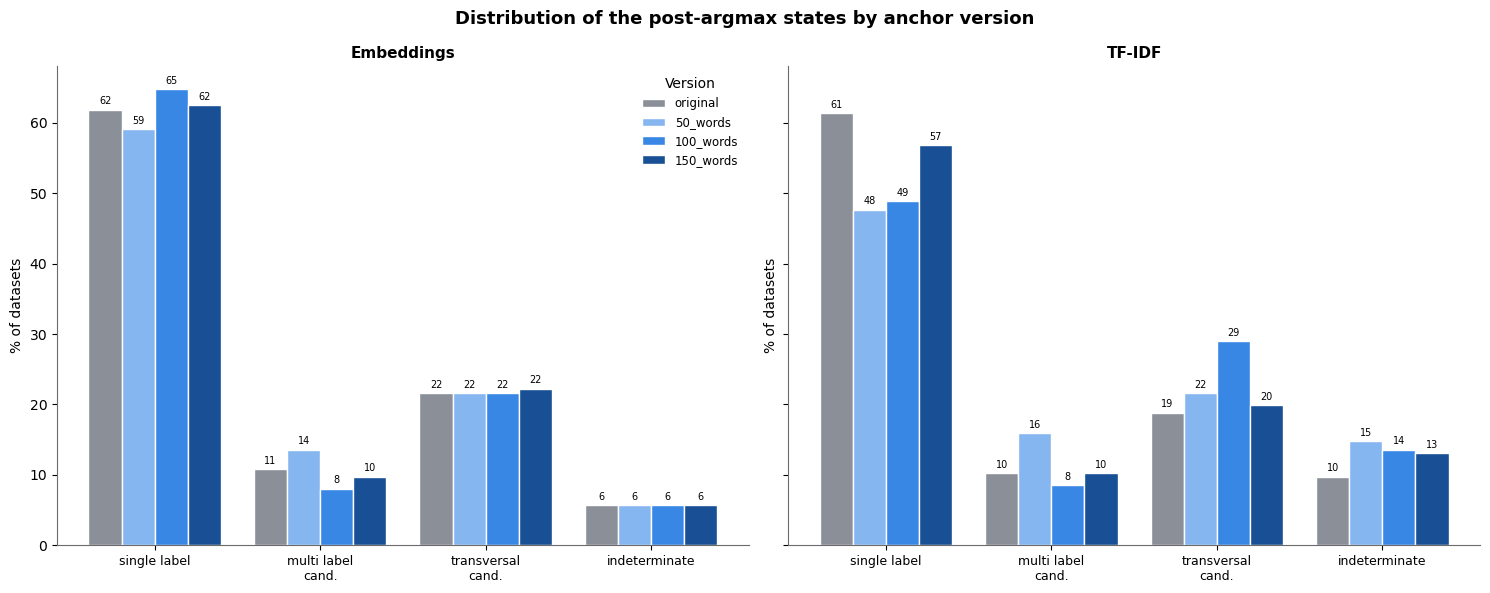

States by method and coincidence between methods (n = no. of datasets; % of the whole corpus).
In the TOTAL row, 'In both methods' = datasets with the SAME state in both methods.



Embeddings (n)  Embeddings (%)  TF-IDF (n)  \
version   state                                                       
original  single_label              109            61.9         108   
          multi_label                19            10.8          18   
          transversal                38            21.6          33   
          indeterminate              10             5.7          17   
          TOTAL                     176           100.0         176   
50_words  single_label              104            59.1          84   
          multi_label                24            13.6          28   
          transversal                38            21.6          38   
          indeterminate              10             5.7          26   
          TOTAL                     176           100.0         176   
100_words single_label              114            64.8          86   
          multi_label                14             8.0          15   
          transversal                38            21.6          51   
          indeterminate              10             5.7          24   
          TOTAL                     176           100.0         176   
150_words single_label              110            62.5         100   
          multi_label                17             9.7          18   
          transversal                39            22.2          35   
          indeterminate              10             5.7          23   
          TOTAL                     176           100.0         176   

                         TF-IDF (%)  In both methods (n)  In both methods (%)  
version   state                                                                
original  single_label         61.4                   72                 40.9  
          multi_label          10.2                    4                  2.3  
          transversal          18.8                    6                  3.4  
          indeterminate         9.7                    5                  2.8  
          TOTAL               100.0                   87                 49.4  
50_words  single_label         47.7                   51                 29.0  
          multi_label          15.9                    6                  3.4  
          transversal          21.6                   11                  6.2  
          indeterminate        14.8                    4                  2.3  
          TOTAL               100.0                   72                 40.9  
100_words single_label         48.9                   58                 33.0  
          multi_label           8.5                    2                  1.1  
          transversal          29.0                   15                  8.5  
          indeterminate        13.6                    5                  2.8  
          TOTAL               100.0                   80                 45.5  
150_words single_label         56.8                   67                 38.1  
          multi_label          10.2                    3                  1.7  
          transversal          19.9                   13                  7.4  
          indeterminate        13.1                    6                  3.4  
          TOTAL               100.0                   89                 50.6

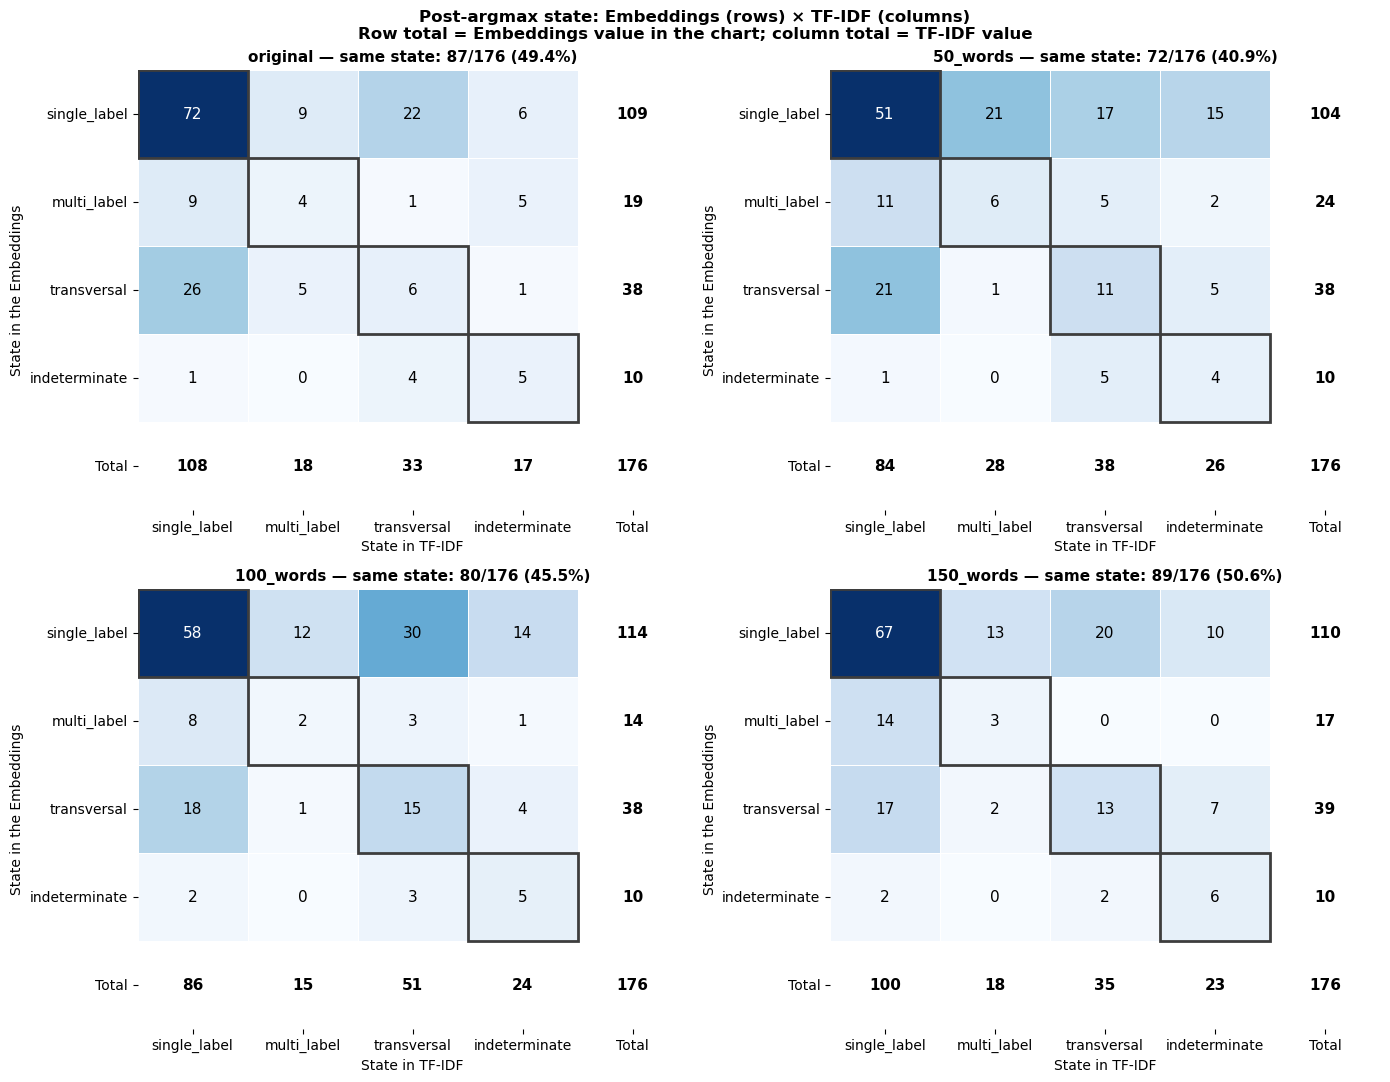

In [50]:
# ── 7.10.4 Visualisation of the states by version and agreement between methods ─
VERSION_COLOURS_710 = {v: VERSION_COLOURS.get(v, c) for v, c in zip(VERSIONS_710, CATEGORICAL_PALETTE)}

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
fig.suptitle("Distribution of the post-argmax states by anchor version",
             fontsize=13, fontweight="bold")
width_chars = 0.8 / len(VERSIONS_710)
x = np.arange(len(STATE_ORDER))
for ax, (suf, name_) in zip(axes, METHODS_710):
    sub = post_argmax_summary_df[post_argmax_summary_df["method"] == name_].set_index("version")
    for j, version in enumerate(VERSIONS_710):
        pct = [sub.loc[version, f"pct_{e}"] for e in STATE_ORDER]
        bar_items = ax.bar(x + (j - (len(VERSIONS_710) - 1) / 2) * width_chars, pct, width=width_chars,
                        color=VERSION_COLOURS_710[version], edgecolor="white", label=version)
        for b, p in zip(bar_items, pct):
            ax.text(b.get_x() + b.get_width() / 2, p + 0.5, f"{p:.0f}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels([e.replace("_", " ").replace("candidate", "cand.") for e in STATE_ORDER],
                       fontsize=9)
    format_x_labels(ax)
    ax.set_title(name_, fontsize=11, fontweight="bold")
    ax.set_ylabel("% of datasets")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(title="Version", fontsize=8.5)
plt.tight_layout()
plt.show()

# ── Agreement of STATE between Embeddings and TF-IDF, by version ─────────────
SHORT_NAMES = {"single_label": "single_label", "multi_label_candidate": "multi_label",
                "transversal_candidate": "transversal", "indeterminate": "indeterminate"}

# 1) Summary table: for each version and state, how many datasets have that state
#    in the Embeddings, in TF-IDF and in BOTH methods at the same time.
#    The "Embeddings" and "TF-IDF" columns are the values of the chart above.
rows_agr = []
for version, tab in tables_710.items():
    n = len(tab)
    for state in STATE_ORDER:
        n_emb = int((tab["status_emb"] == state).sum())
        n_tf = int((tab["status_tfidf"] == state).sum())
        n_both = int(((tab["status_emb"] == state) & (tab["status_tfidf"] == state)).sum())
        rows_agr.append({"version": version, "state": SHORT_NAMES[state],
                            "Embeddings (n)": n_emb, "Embeddings (%)": round(n_emb / n * 100, 1),
                            "TF-IDF (n)": n_tf, "TF-IDF (%)": round(n_tf / n * 100, 1),
                            "In both methods (n)": n_both})
    n_same = int((tab["status_emb"] == tab["status_tfidf"]).sum())
    rows_agr.append({"version": version, "state": "TOTAL",
                        "Embeddings (n)": n, "Embeddings (%)": 100.0,
                        "TF-IDF (n)": n, "TF-IDF (%)": 100.0,
                        "In both methods (n)": n_same})
state_agreement_df = pd.DataFrame(rows_agr)
state_agreement_df["In both methods (%)"] = (
    state_agreement_df["In both methods (n)"] / state_agreement_df["version"].map(
        {v: len(t) for v, t in tables_710.items()}) * 100).round(1)

print("States by method and coincidence between methods (n = no. of datasets; % of the whole corpus).")
print("In the TOTAL row, 'In both methods' = datasets with the SAME state in both methods.\n")
display(state_agreement_df.set_index(["version", "state"]))

# 2) Cross tables as heatmaps, one per version, with totals.
#    Rows = state in the Embeddings; columns = state in TF-IDF.
#    Diagonal (black outline) = same state in both methods.
tick_labels = [SHORT_NAMES[e] for e in STATE_ORDER]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (version, tab) in zip(axes.ravel(), tables_710.items()):
    cross = pd.crosstab(tab["status_emb"], tab["status_tfidf"]).reindex(
        index=STATE_ORDER, columns=STATE_ORDER, fill_value=0)
    cross.index, cross.columns = tick_labels, tick_labels
    cross["Total"] = cross.sum(axis=1)
    cross.loc["Total"] = cross.sum(axis=0)
    colour = cross.astype(float).copy()
    colour.loc["Total", :] = np.nan; colour.loc[:, "Total"] = np.nan   # totals without colour
    sns.heatmap(colour, annot=False, cmap=CMAP_EMB, cbar=False, ax=ax,
                linewidths=0.5, linecolor="white")
    vmax = colour.max().max()
    for r in range(cross.shape[0]):
        for c in range(cross.shape[1]):
            v = int(cross.iat[r, c])
            total = r == cross.shape[0] - 1 or c == cross.shape[1] - 1
            text_colour = "white" if (not total and v > 0.6 * vmax) else "black"
            ax.text(c + 0.5, r + 0.5, v, ha="center", va="center", color=text_colour,
                    fontsize=11, fontweight="bold" if total else "normal")
    for k in range(len(STATE_ORDER)):
        ax.add_patch(plt.Rectangle((k, k), 1, 1, fill=False, edgecolor=REF_COLOUR, linewidth=2))
    n_same = int(np.trace(cross.iloc[:-1, :-1].to_numpy()))
    ax.set_title(f"{version} — same state: {n_same}/{len(tab)} ({n_same / len(tab) * 100:.1f}%)",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("State in TF-IDF"); ax.set_ylabel("State in the Embeddings")
    format_x_labels(ax); horizontal_y_labels(ax)
fig.suptitle("Post-argmax state: Embeddings (rows) × TF-IDF (columns)\n"
             "Row total = Embeddings value in the chart; column total = TF-IDF value",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


#### Figure 4.7 (dissertation) — Post-argmax states by anchor version and by method

Section 4.5 (RQ4). Print version of the bar chart above. The two panels are now placed one below the other, so that the bars and the values remain legible, and the legend of the versions sits on top, in one line. Panel a) Águeda, b) Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_7_a_post_argmax_states.png


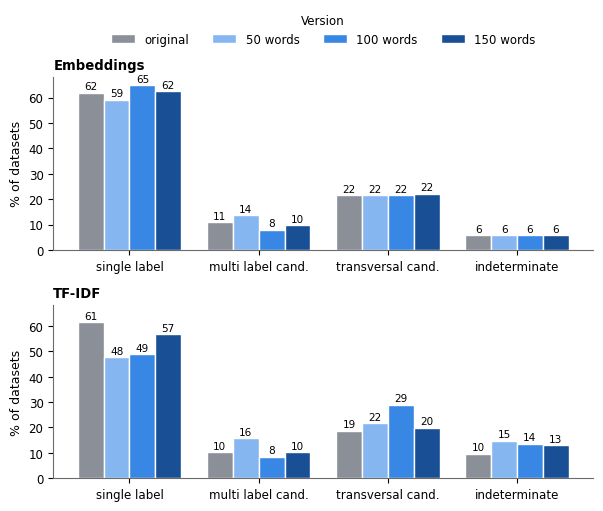

In [51]:
# ── Figure 4.7 (dissertation): post-argmax states ─────────────────────────────
width_chars = 0.8 / len(VERSIONS_710)
x = np.arange(len(STATE_ORDER))
with plt.rc_context(DISS_FONT):
    fig, axes = plt.subplots(2, 1, figsize=(FIG_WIDTH, 5.2), sharey=True)
    for ax, (suf, name_) in zip(axes, METHODS_710):
        sub = post_argmax_summary_df[post_argmax_summary_df["method"] == name_].set_index("version")
        for j, version in enumerate(VERSIONS_710):
            pct = [sub.loc[version, f"pct_{e}"] for e in STATE_ORDER]
            bar_items = ax.bar(x + (j - (len(VERSIONS_710) - 1) / 2) * width_chars, pct, width=width_chars,
                            color=VERSION_COLOURS_710[version], edgecolor="white", label=version.replace("_", " "))
            for b, p in zip(bar_items, pct):
                ax.text(b.get_x() + b.get_width() / 2, p + 0.5, f"{p:.0f}", ha="center", va="bottom", fontsize=7.5)
        ax.set_xticks(x)
        ax.set_xticklabels([e.replace("_", " ").replace("candidate", "cand.") for e in STATE_ORDER])
        ax.set_title(name_, fontweight="bold", loc="left")
        ax.set_ylabel("% of datasets")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(title="Version", ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.12))
    plt.tight_layout()
    export_diss_figure(fig, "4.7", "post_argmax_states")


**Analysis of the results (7.10.4 — States by version and agreement of state between methods).**

The bar chart confirms that flagging varies more across versions in TF-IDF than in the Embeddings. The cross-tabulations show, in turn, that the two methods coincide in the state of 49.4% of the datasets in the original version, 40.9% in the 50-word version, 45.5% in the 100-word version and 50.6% in the 150-word version. This coincidence is due almost entirely to `single_label` cases in both methods (between 29.0% and 40.9% of the corpus); cases in which both methods flag multi-label or transversality are rare, never exceeding 8.5% for the same state. It should be remembered that coinciding in the state is not the same as coinciding in the dimension: many of these shared `single_label` cases have different dimensions in each method (Section 7.10.8).

#### 7.10.5 State of each dataset in the four versions

The percentages by version do not show whether it is always the same datasets that are flagged. This table records, for each dataset, the state assigned by each method in each version and the number of versions in which it was flagged for review (by at least one method). A dataset flagged in all four versions keeps that flag across the wordings tested; flagging in only one version indicates sensitivity to the wording. None of the cases confirms, on its own, substantive multidimensionality.

In [52]:
# ── 7.10.5 State of each dataset in each version ─────────────────────────────
ref_ids = tables_710[VERSIONS_710[0]][["dataset_id", "dataset_title"]].reset_index(drop=True)
post_argmax_states_ds = ref_ids.copy()
version_flag = {}
for version, tab in tables_710.items():
    t = tab.set_index("dataset_id").loc[ref_ids["dataset_id"]]   # alignment by dataset_id
    for suf, _ in METHODS_710:
        post_argmax_states_ds[f"status_{suf}_{version}"] = t[f"status_{suf}"].to_numpy()
    version_flag[version] = (t["review_emb"] | t["review_tfidf"]).to_numpy()

for suf, _ in METHODS_710:
    cols = [f"status_{suf}_{v}" for v in VERSIONS_710]
    post_argmax_states_ds[f"n_versions_review_{suf}"] = (post_argmax_states_ds[cols] != "single_label").sum(axis=1)
post_argmax_states_ds["n_versions_review_any_method"] = np.vstack(list(version_flag.values())).sum(axis=0)

n_v = len(VERSIONS_710)
dist_n_versions = (post_argmax_states_ds[["n_versions_review_emb", "n_versions_review_tfidf",
                                         "n_versions_review_any_method"]]
                  .apply(lambda s: s.value_counts().reindex(range(n_v + 1), fill_value=0)))
dist_n_versions.index.name = "n_versions_flagged"
print("Number of datasets by number of versions in which they were flagged for review:")
display(dist_n_versions)
total = len(post_argmax_states_ds)
n_all = int((post_argmax_states_ds["n_versions_review_any_method"] == n_v).sum())
n_none = int((post_argmax_states_ds["n_versions_review_any_method"] == 0).sum())
print(f"Flagged (≥1 method) in all {n_v} versions: {n_all}/{total} ({n_all / total * 100:.1f}%)")
print(f"Never flagged: {n_none}/{total} ({n_none / total * 100:.1f}%)")
display(post_argmax_states_ds.head(10))

Number of datasets by number of versions in which they were flagged for review:


,n_versions_review_emb,n_versions_review_tfidf,n_versions_review_any_method
n_versions_flagged,,,
0,53,46,16
1,41,38,25
2,38,29,31
3,26,22,47
4,18,41,57


Flagged (≥1 method) in all 4 versions: 57/176 (32.4%)
Never flagged: 16/176 (9.1%)


,dataset_id,dataset_title,status_emb_original,status_tfidf_original,status_emb_50_words,status_tfidf_50_words,status_emb_100_words,status_tfidf_100_words,status_emb_150_words,status_tfidf_150_words,n_versions_review_emb,n_versions_review_tfidf,n_versions_review_any_method
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,multi_label_candidate,single_label,single_label,single_label,single_label,single_label,single_label,multi_label_candidate,1,1,2
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,single_label,single_label,single_label,single_label,single_label,single_label,single_label,single_label,0,0,0
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,single_label,transversal_candidate,multi_label_candidate,transversal_candidate,single_label,transversal_candidate,single_label,transversal_candidate,1,4,4
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,single_label,single_label,single_label,single_label,single_label,single_label,single_label,single_label,0,0,0
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,single_label,single_label,indeterminate,single_label,indeterminate,single_label,indeterminate,single_label,3,0,3
5,f5350303-a076-4726-acc8-014af2d44f0d,CAOP - Troço 7539,transversal_candidate,multi_label_candidate,single_label,single_label,transversal_candidate,single_label,single_label,single_label,2,1,2
6,0769801f-9d0f-462d-97e1-e6d8a7e8f87c,Antendimentos no Posto de Turismo de Águeda,transversal_candidate,single_label,transversal_candidate,transversal_candidate,transversal_candidate,transversal_candidate,transversal_candidate,single_label,4,2,4
7,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,single_label,single_label,transversal_candidate,single_label,single_label,single_label,single_label,single_label,1,0,1
8,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,multi_label_candidate,single_label,transversal_candidate,single_label,single_label,multi_label_candidate,single_label,single_label,2,1,3
9,35ef0ccc-ffcf-4bec-86ea-f390b52d69bc,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,single_label,single_label,transversal_candidate,single_label,single_label,transversal_candidate,single_label,single_label,1,1,2


**Analysis of the results (7.10.5 — State of each dataset in the four versions).**

Considering both methods, 57 datasets are flagged in all versions and only 16 never are. The breakdown by method is revealing: in the Embeddings, only 18 datasets are flagged in all four versions and 53 never are, whereas in TF-IDF the figures are 41 and 46, respectively. The core of persistently weak cases is therefore due above all to the lexical method, in particular to short texts and to cases without overlap with the anchors.

#### 7.10.6 Cases for human review

All states other than `single_label` have `review_flag=True`. Within each version, the review priority follows the order described in Section 3.5.1 of the dissertation:

1. discordant state between Embeddings and TF-IDF;
2. `indeterminate` in both methods;
3. `transversal_candidate` in both methods;
4. `multi_label_candidate` in both methods.

The final list brings the four versions together: each dataset appears once, sorted by the number of versions in which it was flagged and then by the highest priority it received. It is an automatic list for possible future review, not a measure of error. Human review of the datasets is not part of this study.

In [53]:
# ── 7.10.6 Cases for human review (four versions) ─────────────────────────────
def review_priority(row):
    if row["status_emb"] != row["status_tfidf"]: return 1
    if row["status_emb"] == "indeterminate"        : return 2
    if row["status_emb"] == "transversal_candidate": return 3
    return 4

reviews = []
for version, tab in tables_710.items():
    rv = tab[tab["review_emb"] | tab["review_tfidf"]].copy()
    rv["discordant_states"] = rv["status_emb"] != rv["status_tfidf"]
    rv["review_priority"] = rv.apply(review_priority, axis=1)
    rv.insert(0, "version", version)
    reviews.append(rv)
review_710_df = pd.concat(reviews, ignore_index=True)

print("Cases for review by version and priority (1 = discordant states between methods):")
display(pd.crosstab(review_710_df["version"], review_710_df["review_priority"], margins=True,
                    margins_name="Total").reindex(VERSIONS_710 + ["Total"]))

# Single list per dataset
review_list_df = (review_710_df.groupby(["dataset_id", "dataset_title"])
                    .agg(n_versions_flagged=("version", "nunique"),
                         highest_priority=("review_priority", "min"),
                         versions_flagged=("version", lambda s: ", ".join(v for v in VERSIONS_710 if v in set(s))))
                    .reset_index())
for suf, _ in METHODS_710:
    cols = [f"status_{suf}_{v}" for v in VERSIONS_710]
    review_list_df = review_list_df.merge(
        post_argmax_states_ds[["dataset_id"] + cols], on="dataset_id", how="left", validate="one_to_one")
review_list_df = review_list_df.sort_values(
    ["n_versions_flagged", "highest_priority", "dataset_title"],
    ascending=[False, True, True]).reset_index(drop=True)

print(f"\nDatasets flagged in at least one version: {len(review_list_df)} of {len(post_argmax_states_ds)}")
print("Fields to fill in during the manual review: human_primary_label, human_secondary_labels, human_status, human_notes")
display(review_list_df.head(20))

Cases for review by version and priority (1 = discordant states between methods):


review_priority,1,2,3,4,Total
version,,,,,
original,89,5,6,4,104
50_words,104,4,11,6,125
100_words,96,5,15,2,118
150_words,87,6,13,3,109
Total,376,20,45,15,456



Datasets flagged in at least one version: 160 of 176
Fields to fill in during the manual review: human_primary_label, human_secondary_labels, human_status, human_notes


,dataset_id,dataset_title,n_versions_flagged,highest_priority,versions_flagged,status_emb_original,status_emb_50_words,status_emb_100_words,status_emb_150_words,status_tfidf_original,status_tfidf_50_words,status_tfidf_100_words,status_tfidf_150_words
0,aed8af37-0127-4715-b137-d278c7d9d08d,Aguada de Cima,4,1,"original, 50_words, 100_words, 150_words",multi_label_candidate,transversal_candidate,single_label,transversal_candidate,multi_label_candidate,single_label,multi_label_candidate,transversal_candidate
1,0769801f-9d0f-462d-97e1-e6d8a7e8f87c,Antendimentos no Posto de Turismo de Águeda,4,1,"original, 50_words, 100_words, 150_words",transversal_candidate,transversal_candidate,transversal_candidate,transversal_candidate,single_label,transversal_candidate,transversal_candidate,single_label
2,d9eaeeb5-e618-4e8a-9dd1-8c64f6a4a7ca,Avenida do Emigrante,4,1,"original, 50_words, 100_words, 150_words",transversal_candidate,transversal_candidate,single_label,transversal_candidate,transversal_candidate,transversal_candidate,transversal_candidate,transversal_candidate
3,b5827eff-2288-4392-bdd2-d1e73c8251ad,Cartografia 10k,4,1,"original, 50_words, 100_words, 150_words",indeterminate,indeterminate,indeterminate,indeterminate,transversal_candidate,indeterminate,indeterminate,indeterminate
4,2be93726-75ce-42cc-92bb-32aadf7ed082,Cidade de Águeda,4,1,"original, 50_words, 100_words, 150_words",multi_label_candidate,single_label,single_label,transversal_candidate,indeterminate,indeterminate,indeterminate,indeterminate
5,0dde552a-675e-457d-abd2-0102221852ba,Coretos,4,1,"original, 50_words, 100_words, 150_words",multi_label_candidate,indeterminate,single_label,indeterminate,indeterminate,indeterminate,indeterminate,indeterminate
6,67ca0ced-4158-46bd-b38e-cedee2afb703,EN 333,4,1,"original, 50_words, 100_words, 150_words",single_label,single_label,single_label,single_label,transversal_candidate,transversal_candidate,transversal_candidate,transversal_candidate
7,e5738237-3a7c-4a81-97dc-9c2dc604f7cd,Ecopontos,4,1,"original, 50_words, 100_words, 150_words",single_label,single_label,single_label,single_label,transversal_candidate,indeterminate,indeterminate,indeterminate
8,eb242794-2a7c-4edb-bb39-cb274c53ef78,Espacos residenciais urbanizaveis tipo1- PDM 12 Ordenamento,4,1,"original, 50_words, 100_words, 150_words",multi_label_candidate,multi_label_candidate,transversal_candidate,transversal_candidate,multi_label_candidate,transversal_candidate,transversal_candidate,single_label
9,dc19fcae-4bb6-433c-a1cc-9fe4c538e039,"Espaço Florestal de Conservação Estrita, PDM 12 Ordenamento",4,1,"original, 50_words, 100_words, 150_words",single_label,single_label,transversal_candidate,multi_label_candidate,multi_label_candidate,transversal_candidate,single_label,multi_label_candidate


**Analysis of the results (7.10.6 — Cases for human review).**

Across the four versions together there are 456 flags of dataset-version pairs, of which 376 (82.5%) have priority 1, that is, different states in the two methods. Cases in which both methods agree on a weakness (priorities 2 to 4) are much less frequent. Before the global review, 160 of the 176 datasets appear in at least one version; the final list, which adds the single-single disagreement (Section 7.10.8), rises to 168.

#### 7.10.7 Sensitivity of the rule to the parameters

The parameters of the rule (minimum number of words and percentiles) were fixed before the analysis and were not tuned to the results. To assess how much the results depend on them, **one parameter at a time** is varied, keeping the others at their baseline values, and the rule is repeated in each version:

| Parameter | Baseline value | Values tested |
|---|---|---|
| `MIN_WORDS` | 8 | 5, 10 |
| `PERCENTILE_WEAK_SCORE` | 5 | 10 |
| `PERCENTILE_CLOSE_MARGIN` | 25 | 20, 30 |
| `PERCENTILE_DIFFUSE_RANGE` | 25 | 20, 30 |

The cell uses a vectorised version of the rule. Before computing the sensitivity, it confirms that this version exactly reproduces the states obtained with `decision_rule` in all versions and methods; if it does not, execution stops.

In [54]:
# ── 7.10.7 Sensitivity of the post-argmax rule (one parameter at a time) ─────
def post_argmax_states(df, method, min_words, p_weak, p_margin, p_range):
    """Vectorised version of the rule in 7.10.3 (n_close includes the winning dimension)."""
    S = df[sorted((c for c in df.columns if c.startswith(f"score_{method}_")), key=dim_col_key)].to_numpy(dtype=float)
    ordered = -np.sort(-S, axis=1)
    s1, m12, amp = ordered[:, 0], ordered[:, 0] - ordered[:, 1], ordered[:, 0] - ordered[:, -1]
    ok = s1 > 0
    theta = np.percentile(s1[ok], p_weak)          # same method as pandas .quantile (linear)
    dclose = np.percentile(m12[ok], p_margin)
    rlow = np.percentile(amp[ok], p_range)
    n_close = (S >= (s1 - dclose)[:, None]).sum(axis=1)
    word_list = df["n_words_embeddings"].to_numpy()
    return np.select(
        [word_list < min_words, (s1 == 0) | (s1 <= theta), (n_close >= 3) | (amp < rlow), (n_close >= 2) & (m12 <= dclose)],
        ["indeterminate", "indeterminate", "transversal_candidate", "multi_label_candidate"],
        default="single_label")

BASE_710 = dict(min_words=MIN_WORDS, p_weak=PERCENTILE_WEAK_SCORE,
                p_margin=PERCENTILE_CLOSE_MARGIN, p_range=PERCENTILE_DIFFUSE_RANGE)

# 1) Does the vectorised version reproduce the states of 7.10.3?
for version, tab in tables_710.items():
    for suf, _ in METHODS_710:
        same = (post_argmax_states(tab, suf, **BASE_710) == tab[f"status_{suf}"].to_numpy()).mean()
        assert same == 1.0, f"The vectorised version does not reproduce 7.10.3 ({version}, {suf}) — do not use."
print("The vectorised version reproduces 100% of the states of 7.10.3 in all versions and methods.")

def sensitivity_summary(df, **kw):
    e, t = post_argmax_states(df, "emb", **kw), post_argmax_states(df, "tfidf", **kw)
    row_data = {}
    for name_, s in (("Emb", e), ("TF-IDF", t)):
        for k in STATE_ORDER:
            row_data[f"{name_} {k} (%)"] = round((s == k).mean() * 100, 1)
        row_data[f"{name_} review (%)"] = round((s != "single_label").mean() * 100, 1)
    row_data["Review by ≥1 method (%)"] = round(((e != "single_label") | (t != "single_label")).mean() * 100, 1)
    row_data["Same state in both methods (%)"] = round((e == t).mean() * 100, 1)
    return row_data

tests_710 = [("base configuration", {})]
tests_710 += [(f"MIN_WORDS={v}", {"min_words": v}) for v in (5, 10)]
tests_710 += [(f"PERCENTILE_WEAK_SCORE={v}", {"p_weak": v}) for v in (10,)]
tests_710 += [(f"PERCENTILE_CLOSE_MARGIN={v}", {"p_margin": v}) for v in (20, 30)]
tests_710 += [(f"PERCENTILE_DIFFUSE_RANGE={v}", {"p_range": v}) for v in (20, 30)]

post_argmax_sensitivity_df = pd.DataFrame([
    {"version": version, "test": name_, **sensitivity_summary(tab, **{**BASE_710, **alt})}
    for version, tab in tables_710.items() for name_, alt in tests_710
])

col = "Review by ≥1 method (%)"
print(f"\n{col} — test × version:")
display(post_argmax_sensitivity_df.pivot(index="test", columns="version", values=col)
        .reindex(index=[n for n, _ in tests_710], columns=VERSIONS_710))
for version in VERSIONS_710:
    s = post_argmax_sensitivity_df.loc[post_argmax_sensitivity_df["version"] == version, col]
    print(f"  {version:<14} range: {s.min():.1f}%–{s.max():.1f}% (base: {s.iloc[0]:.1f}%)")

The vectorised version reproduces 100% of the states of 7.10.3 in all versions and methods.



Review by ≥1 method (%) — test × version:


version,original,50_words,100_words,150_words
test,,,,
base configuration,59.1,71.0,67.0,61.9
MIN_WORDS=5,59.1,71.0,67.0,61.9
MIN_WORDS=10,60.2,71.0,67.0,61.9
PERCENTILE_WEAK_SCORE=10,59.1,71.0,67.0,62.5
PERCENTILE_CLOSE_MARGIN=20,56.2,67.6,64.2,58.0
PERCENTILE_CLOSE_MARGIN=30,62.5,76.7,69.9,68.8
PERCENTILE_DIFFUSE_RANGE=20,55.1,68.8,64.2,59.7
PERCENTILE_DIFFUSE_RANGE=30,65.9,74.4,70.5,65.9


  original       range: 55.1%–65.9% (base: 59.1%)
  50_words       range: 67.6%–76.7% (base: 71.0%)
  100_words      range: 64.2%–70.5% (base: 67.0%)
  150_words      range: 58.0%–68.8% (base: 61.9%)


**Analysis of the results (7.10.7 — Sensitivity of the rule to the parameters).**

The vectorised version exactly reproduces the rule of 7.10.3, which validates the sensitivity results. Changing one parameter at a time, the proportion of datasets flagged by at least one method varies between 55.1% and 65.9% in the original version, between 67.6% and 76.7% in the 50-word version, between 64.2% and 70.5% in the 100-word version and between 58.0% and 68.8% in the 150-word version. The percentiles of the margin and of the range are the parameters that weigh most, whereas the minimum number of words has almost no effect. The ordering between versions remains practically intact, which shows that the rule is sensitive in absolute values, but stable in its qualitative conclusions.

#### 7.10.8 Global review and candidate dimensions

The six ENTI dimensions are not treated as mutually exclusive categories: a dataset may have semantic relevance to more than one. This subsection adds three elements, **without changing the rule of 7.10.3 or its thresholds**:

1. **`candidate_labels_<method>`** — the candidate dimensions of each dataset, that is, the dimensions with score ≥ `s1 − delta_close`. This is exactly the logic of `n_close` (the number of candidates equals `n_close`, checked automatically). In the `indeterminate` cases, the list is empty. When the transversal state results only from a low range of the profile, `n_close` may be below three; the state signals low discrimination, it does not prove three thematic associations.
2. **`discordant_single`** — datasets with `single_label` in both methods, but with different predominant dimensions. The `review_flag` of each method does not capture these cases, because neither method has internal uncertainty; the divergence lies **between** the methods.
3. **`review_global = review_emb | review_tfidf | discordant_single`**, reporting separately:
   - `within_method_uncertainty` — uncertainty within at least one method (state other than `single_label`);
   - `cross_method_disagreement` — disagreement between methods with apparently low internal uncertainty (`discordant_single`).

The two groups are disjoint by construction. In the review list, the `discordant_single` cases enter with **priority 5**, after priorities 1–4 of 7.10.6. The sensitivity analysis (MET-001) is repeated for the global review with the same grid as 7.10.7. These states and lists are triage mechanisms for human review, not validated classes.


In [55]:
# ── 7.10.8 Global review and candidate dimensions ─────────────────────────────
# Adds, without changing the rule in 7.10.3 or its thresholds:
#   (a) candidate_labels_<method>: dimensions with score ≥ s1 − delta_close
#       (exactly the n_close logic); [] in the indeterminate cases;
#   (b) discordant_single: single_label in both methods, but with different
#       predominant dimensions (disagreement between methods that the review_flag
#       of each method does not capture);
#   (c) review_global = review_emb | review_tfidf | discordant_single,
#       separating within_method_uncertainty from cross_method_disagreement.

def candidate_dimensions(tab, suffix, delta_close):
    """List of dimensions within delta_close of the maximum score (n_close logic)."""
    cols = sorted((c for c in tab.columns if c.startswith(f"score_{suffix}_")), key=dim_col_key)
    dims = [c.replace(f"score_{suffix}_", "") for c in cols]
    S = tab[cols].to_numpy(dtype=float)
    s1 = S.max(axis=1)
    close_set = S >= (s1 - delta_close)[:, None]
    order = np.argsort(-S, axis=1)                       # candidates in order of score
    cand = [[dims[j] for j in order[i] if close_set[i, j]] for i in range(len(tab))]
    state = tab[f"status_{suffix}"].to_numpy()
    return [c if e != "indeterminate" else [] for c, e in zip(cand, state)]

rows_rg = []
for version, tab in tables_710.items():
    for suf, _ in METHODS_710:
        cand = candidate_dimensions(tab, suf, thresholds_710[version][suf]["delta_close"])
        tab[f"candidate_labels_{suf}"] = [str(c) for c in cand]
        tab[f"n_candidate_labels_{suf}"] = [len(c) for c in cand]
    # Consistency with n_close (check): in the non-indeterminate cases, no. of candidates = n_close
    for suf, _ in METHODS_710:
        ok = tab[f"status_{suf}"] != "indeterminate"
        assert (tab.loc[ok, f"n_candidate_labels_{suf}"] == tab.loc[ok, f"n_close_{suf}"]).all(), \
            f"candidate_labels inconsistent with n_close ({version}, {suf})"

    tab["discordant_single"] = ((tab["status_tfidf"] == "single_label") & (tab["status_emb"] == "single_label")
                                & (tab["top1_label_tfidf"] != tab["top1_label_emb"]))
    tab["within_method_uncertainty"] = tab["review_emb"] | tab["review_tfidf"]
    tab["cross_method_disagreement"] = tab["discordant_single"]
    tab["review_global"] = tab["review_tfidf"] | tab["review_emb"] | tab["discordant_single"]

    n = len(tab)
    single_both = (tab["status_emb"] == "single_label") & (tab["status_tfidf"] == "single_label")
    rows_rg.append({
        "version": version, "n_datasets": n,
        "n_single_in_both": int(single_both.sum()),
        "n_single_in_both_same_dimension": int((single_both & ~tab["discordant_single"]).sum()),
        "n_within_method_uncertainty": int(tab["within_method_uncertainty"].sum()),
        "pct_within_method_uncertainty": round(tab["within_method_uncertainty"].mean() * 100, 1),
        "n_cross_method_disagreement": int(tab["cross_method_disagreement"].sum()),
        "pct_cross_method_disagreement": round(tab["cross_method_disagreement"].mean() * 100, 1),
        "n_review_global": int(tab["review_global"].sum()),
        "pct_review_global": round(tab["review_global"].mean() * 100, 1),
        "n_no_review": int((~tab["review_global"]).sum()),
        "pct_no_review": round((~tab["review_global"]).mean() * 100, 1),
    })
global_review_df = pd.DataFrame(rows_rg)
print("Global review by version (within = uncertainty within each method;")
print("cross = single_label in both methods with different predominant dimensions):")
display(global_review_df.set_index("version"))

# ── Updated review list: includes the discordant_single cases ────────────────
# The cases of 7.10.6 keep priority 1–4; the discordant_single cases enter with
# priority 5 (disagreement between methods with apparently low internal uncertainty).
reviews_dis = []
for version, tab in tables_710.items():
    rv = tab[tab["discordant_single"]].copy()
    rv["discordant_states"] = False
    rv["review_priority"] = 5
    rv.insert(0, "version", version)
    reviews_dis.append(rv)
review_710_df = pd.concat([review_710_df] + reviews_dis, ignore_index=True)
review_list_df = (review_710_df.groupby(["dataset_id", "dataset_title"])
                    .agg(n_versions_flagged=("version", "nunique"),
                         highest_priority=("review_priority", "min"),
                         versions_flagged=("version", lambda s: ", ".join(v for v in VERSIONS_710 if v in set(s))))
                    .reset_index())
for suf, _ in METHODS_710:
    cols = [f"status_{suf}_{v}" for v in VERSIONS_710]
    review_list_df = review_list_df.merge(
        post_argmax_states_ds[["dataset_id"] + cols], on="dataset_id", how="left", validate="one_to_one")
review_list_df = review_list_df.sort_values(
    ["n_versions_flagged", "highest_priority", "dataset_title"],
    ascending=[False, True, True]).reset_index(drop=True)
for version, tab in tables_710.items():
    t = tab.set_index("dataset_id").loc[post_argmax_states_ds["dataset_id"]]
    post_argmax_states_ds[f"review_global_{version}"] = t["review_global"].to_numpy()
post_argmax_states_ds["n_versions_review_global"] = post_argmax_states_ds[
    [f"review_global_{v}" for v in VERSIONS_710]].sum(axis=1)
print(f"Datasets flagged (global review) in at least one version: {len(review_list_df)} "
      f"of {len(post_argmax_states_ds)}")

# ── MET-001 with the global review (same grid as 7.10.7) ─────────────────────
def top1_labels(df, method):
    cols = sorted((c for c in df.columns if c.startswith(f"score_{method}_")), key=dim_col_key)
    return np.array([c.replace(f"score_{method}_", "") for c in cols])[df[cols].to_numpy(dtype=float).argmax(axis=1)]

rg_sens = []
for version, tab in tables_710.items():
    l_e, l_t = top1_labels(tab, "emb"), top1_labels(tab, "tfidf")
    for name_, alt in tests_710:
        kw = {**BASE_710, **alt}
        e, t = post_argmax_states(tab, "emb", **kw), post_argmax_states(tab, "tfidf", **kw)
        dis = (e == "single_label") & (t == "single_label") & (l_e != l_t)
        rg_sens.append({"version": version, "test": name_,
                        "Single-single disagreement (%)": round(dis.mean() * 100, 1),
                        "Global review (%)": round(((e != "single_label") | (t != "single_label") | dis).mean() * 100, 1)})
post_argmax_sensitivity_df = post_argmax_sensitivity_df.merge(
    pd.DataFrame(rg_sens), on=["version", "test"], how="left", validate="one_to_one")
# Check: the base configuration reproduces the global review computed above
base = post_argmax_sensitivity_df[post_argmax_sensitivity_df["test"] == "base configuration"].set_index("version")
assert (base.loc[VERSIONS_710, "Global review (%)"].to_numpy()
        == global_review_df.set_index("version").loc[VERSIONS_710, "pct_review_global"].to_numpy()).all()

col_rg = "Global review (%)"
print(f"\n{col_rg} — test × version (MET-001, same grid):")
display(post_argmax_sensitivity_df.pivot(index="test", columns="version", values=col_rg)
        .reindex(index=[n for n, _ in tests_710], columns=VERSIONS_710))
for version in VERSIONS_710:
    s = post_argmax_sensitivity_df.loc[post_argmax_sensitivity_df["version"] == version, col_rg]
    print(f"  {version:<14} range: {s.min():.1f}%–{s.max():.1f}% (base: {s.iloc[0]:.1f}%)")


Global review by version (within = uncertainty within each method;
cross = single_label in both methods with different predominant dimensions):


,n_datasets,n_single_in_both,n_single_in_both_same_dimension,n_within_method_uncertainty,pct_within_method_uncertainty,n_cross_method_disagreement,pct_cross_method_disagreement,n_review_global,pct_review_global,n_no_review,pct_no_review
version,,,,,,,,,,,
original,176,72,22,104,59.1,50,28.4,154,87.5,22,12.5
50_words,176,51,18,125,71.0,33,18.8,158,89.8,18,10.2
100_words,176,58,19,118,67.0,39,22.2,157,89.2,19,10.8
150_words,176,67,33,109,61.9,34,19.3,143,81.2,33,18.8


Datasets flagged (global review) in at least one version: 168 of 176



Global review (%) — test × version (MET-001, same grid):


version,original,50_words,100_words,150_words
test,,,,
base configuration,87.5,89.8,89.2,81.2
MIN_WORDS=5,87.5,89.8,89.2,81.2
MIN_WORDS=10,87.5,89.8,89.2,81.2
PERCENTILE_WEAK_SCORE=10,87.5,89.8,89.2,81.2
PERCENTILE_CLOSE_MARGIN=20,87.5,89.2,88.6,80.7
PERCENTILE_CLOSE_MARGIN=30,89.2,89.8,89.2,82.4
PERCENTILE_DIFFUSE_RANGE=20,85.2,89.2,86.9,79.5
PERCENTILE_DIFFUSE_RANGE=30,88.1,90.9,91.5,84.7


  original       range: 85.2%–89.2% (base: 87.5%)
  50_words       range: 89.2%–90.9% (base: 89.8%)
  100_words      range: 86.9%–91.5% (base: 89.2%)
  150_words      range: 79.5%–84.7% (base: 81.2%)


**Analysis of the results (7.10 — Post-argmax classification in the four versions).**

In the Embeddings, the proportion of flagged datasets varies little across versions (from 35.2% to 40.9%), and the number of `indeterminate` cases is the same in all four (10 datasets, 5.7%). In TF-IDF, the variation is much greater, ranging from 38.6% in the original version to 52.3% in the 50-word version, with 51.1% in the 100-word version and 43.2% in the 150-word version. Flagging therefore depends more on the anchor version in the lexical method than in the semantic one.

Combining the two methods, the proportion of datasets flagged by at least one of them is 59.1% (original), 71.0% (50 words), 67.0% (100 words) and 61.9% (150 words). The original version is the one that flags the fewest cases, and the 150-word version the one with the greatest coincidence of state between methods (50.6%, against 40.9%–49.4% in the others).

The table by dataset (7.10.5) shows that 57 of the 176 datasets are flagged in all four versions and 16 never are; the remaining 103 are flagged in one to three versions. The former form a core of cases whose weakness does not depend on the wording of the anchors, whereas, in the others, flagging depends on the version used.

The global review (7.10.8) adds the cases in which both methods produce `single_label`, but with different dimensions. There are many: in the original version, of the 72 datasets with `single_label` in both methods, 50 receive different dimensions. With them, the global review covers 87.5%, 89.8%, 89.2% and 81.2% of the datasets in the four versions, and 127 datasets are flagged in all versions. The candidate dimensions show that multidimensionality is concentrated above all around Quality of Life, which frequently appears alongside Environment, Mobility or Economy.

In the sensitivity analysis (7.10.7), the proportion flagged by at least one method varies, within each version, by between 6.3 and 10.8 percentage points, with the percentiles of the margin and of the range being the parameters with the greatest effect. The global review is more stable (ranges of 1.7 to 5.2 points). The 50-word version is the one that flags the most cases in all variations, and the original the one that flags the fewest by at least one method in 7 of the 8.

**Rigorous interpretation of the post-argmax classification.**

The rule avoids automatically turning every `argmax` into a single classification. The states are operational flags, dependent on the empirical thresholds computed in each version and each method; they are neither validated classes nor estimates of error. Differences between versions indicate that the flagging depends on the wording of the anchors, but do not make it possible to conclude which of the versions is more correct. The cases flagged in all versions are the clearest candidates for manual review; confirming the states requires a sample annotated by experts.

#### 7.10.9 Pairs of candidate dimensions and transversality by range

In the original version of the embeddings: the most frequent pairs of dimensions among the profiles with exactly two candidates, the presence of Quality of Life among the candidates and the `transversal_candidate` cases assigned only because of the reduced range, with no alternative within `delta_close` (Section 4.5 of the dissertation).

In [56]:
# ── 7.10.9 Candidate dimensions (embeddings, original version) ───────────────
import ast
_t = tables_710["original"]
_state = _t["status_emb"]
_multi_transv = _state.isin(["multi_label_candidate", "transversal_candidate"])
_cand = _t["candidate_labels_emb"].apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else list(s))
_short = lambda d: d.replace("Smart ", "")
_pairs = (_cand[_multi_transv & (_cand.apply(len) == 2)]
          .apply(lambda c: " + ".join(sorted(_short(x) for x in c))).value_counts().rename("n").to_frame())
_qv = int(_cand[_multi_transv].apply(lambda c: "Smart Quality of Life" in c).sum())
_range_only = int(((_state == "transversal_candidate") & (_t["n_close_emb"] == 1)).sum())
cand_summary = pd.DataFrame([
    {"indicator": "multi_label or transversal (embeddings, original)", "n": int(_multi_transv.sum())},
    {"indicator": "… with exactly two candidates", "n": int((_multi_transv & (_cand.apply(len) == 2)).sum())},
    {"indicator": "… with Quality of Life among the candidates", "n": _qv},
    {"indicator": "transversal only because of the range (n_close = 1)", "n": _range_only},
])
DISSERTATION_COUNTS["Candidates - summary"] = cand_summary
DISSERTATION_COUNTS["Candidates - pairs"] = _pairs.reset_index().rename(columns={"index": "pair"})
display(cand_summary)
print("Pairs of candidate dimensions (profiles with exactly two candidates):")
display(_pairs)

,indicator,n
0,"multi_label or transversal (embeddings, original)",57
1,… with exactly two candidates,32
2,… with Quality of Life among the candidates,37
3,transversal only because of the range (n_close = 1),15


Pairs of candidate dimensions (profiles with exactly two candidates):


,n
candidate_labels_emb,
Environment + Quality of Life,10
Economy + Quality of Life,8
Mobility + Quality of Life,8
Economy + Mobility,2
Economy + Environment,2
Environment + Governance,1
Mobility + Society,1


## 8. Datasets unstable across versions

A dataset is considered **unstable in the top-1** if the dimension with the highest score changes across anchor versions (original, 50, 100 and 150 words).

### Why analyse instability?

The stability of the predominant dimension under variations in the anchors describes the robustness of this summary. A change of top-1 does not, on its own, reveal error or substantive multidimensionality. It may have several explanations:

1. **Potential thematic overlap**: the dataset may address themes relevant to more than one dimension (for example, data on solar energy installed in public buildings may fit both "Environment" and "Governance"). In these cases, instability may reflect transversality, a hypothesis that these scores do not confirm on their own.

2. **Insufficient description**: the text of the dataset is too short or generic to support a stable predominant dimension. Different wordings of the anchors may change the relative scores. A more informative description could change the profile obtained.

3. **Semantic overlap between anchors**: the alternative wording of the anchors may introduce vocabulary that inadvertently brings two dimensions closer together, making the boundary between them less clear.

### How is instability measured?

For each dataset, the number of distinct dimensions assigned to it across the 4 versions is counted. A dataset with `n_distinct_dims = 1` is perfectly stable (always the same dimension); one with `n_distinct_dims = 4` changed dimension in every version, which shows strong sensitivity of the top-1 to the anchors tested.

The process is repeated separately for Embeddings and TF-IDF, which makes it possible to compare how the predominant dimension varies in each representation. The versions differ in wording, lexicon and detail, so this comparison does not isolate the effect of the number of words.

### Practical implications

The unstable datasets may be included in a triage list for possible future review. The information on *which* dimensions alternated (present in the columns `emb_original`, `emb_50_words`, etc.) shows between which dimensions the top-1 of each dataset oscillates in the versions tested.


In [57]:
# ── Dimensional stability and coverage stability, kept separate ──────────────
base = datasets[["dataset_id", "title"]].rename(columns={"title": "dataset_title"}).copy()
instability_df = base
for version, obj in results_by_version.items():
    tmp = obj["results"][["dataset_id", "dimension_embeddings", "dimension_tfidf"]].rename(columns={
        "dimension_embeddings": f"emb_{version}", "dimension_tfidf": f"tfidf_{version}"})
    instability_df = instability_df.merge(tmp, on="dataset_id", validate="one_to_one")

emb_cols = [f"emb_{v}" for v in results_by_version]
tf_cols = [f"tfidf_{v}" for v in results_by_version]

instability_df["n_distinct_dims_emb"] = instability_df[emb_cols].nunique(axis=1, dropna=True)
instability_df["unstable_emb"] = instability_df["n_distinct_dims_emb"] > 1
instability_df["n_versions_tfidf_valid"] = instability_df[tf_cols].notna().sum(axis=1)
instability_df["tfidf_coverage_stable"] = instability_df[tf_cols].notna().nunique(axis=1) == 1
instability_df["n_distinct_dims_tfidf_valid"] = instability_df[tf_cols].nunique(axis=1, dropna=True)
instability_df["unstable_tfidf_among_valid"] = instability_df["n_distinct_dims_tfidf_valid"] > 1
instability_df["tfidf_valid_all_versions"] = instability_df["n_versions_tfidf_valid"] == len(tf_cols)
instability_df["tfidf_zero_all_versions"] = instability_df["n_versions_tfidf_valid"] == 0

st_emb = (~instability_df["unstable_emb"]).mean() * 100
mask_tf_comparable = instability_df["tfidf_valid_all_versions"]
st_tf_valid = ((~instability_df.loc[mask_tf_comparable, "unstable_tfidf_among_valid"]).mean() * 100
                   if mask_tf_comparable.any() else np.nan)

print(f"Embeddings — same dimension in the four versions: {st_emb:.1f}% of the total")
print(f"TF-IDF — same dimension among datasets valid in the four versions: {st_tf_valid:.1f}% "
      f"(n={mask_tf_comparable.sum()})")
print(f"TF-IDF — stable classified/zero coverage: {instability_df['tfidf_coverage_stable'].mean()*100:.1f}%")
print(f"TF-IDF — zero in the four versions: {instability_df['tfidf_zero_all_versions'].sum()}")
display(instability_df.sort_values(["unstable_emb", "unstable_tfidf_among_valid"], ascending=False))

Embeddings — same dimension in the four versions: 37.5% of the total
TF-IDF — same dimension among datasets valid in the four versions: 59.5% (n=158)
TF-IDF — stable classified/zero coverage: 93.8%
TF-IDF — zero in the four versions: 7


,dataset_id,dataset_title,emb_original,tfidf_original,emb_50_words,tfidf_50_words,emb_100_words,tfidf_100_words,emb_150_words,tfidf_150_words,n_distinct_dims_emb,unstable_emb,n_versions_tfidf_valid,tfidf_coverage_stable,n_distinct_dims_tfidf_valid,unstable_tfidf_among_valid,tfidf_valid_all_versions,tfidf_zero_all_versions
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,Smart Quality of Life,Smart Quality of Life,Smart Environment,Smart Society,Smart Quality of Life,Smart Economy,Smart Environment,Smart Society,2,True,4,True,3,True,True,False
5,f5350303-a076-4726-acc8-014af2d44f0d,CAOP - Troço 7539,Smart Society,Smart Economy,Smart Governance,Smart Economy,Smart Quality of Life,Smart Governance,Smart Governance,Smart Economy,3,True,4,True,2,True,True,False
6,0769801f-9d0f-462d-97e1-e6d8a7e8f87c,Antendimentos no Posto de Turismo de Águeda,Smart Quality of Life,Smart Economy,Smart Governance,Smart Governance,Smart Economy,Smart Governance,Smart Society,Smart Economy,4,True,4,True,2,True,True,False
7,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,Smart Environment,Smart Quality of Life,Smart Governance,Smart Quality of Life,Smart Quality of Life,Smart Environment,Smart Environment,Smart Quality of Life,3,True,4,True,2,True,True,False
8,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,Smart Environment,Smart Quality of Life,Smart Governance,Smart Quality of Life,Smart Quality of Life,Smart Environment,Smart Environment,Smart Quality of Life,3,True,4,True,2,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
169,9d06f625-c88b-4501-bd36-279d6099eee0,Antenas de comunicação,Smart Governance,Smart Mobility,Smart Governance,None,Smart Governance,None,Smart Governance,Smart Mobility,1,False,2,False,1,False,False,False
170,908d2ad6-c91e-4f8a-bf83-ab282010c4c1,Pistas Cicláveis,Smart Mobility,Smart Mobility,Smart Mobility,None,Smart Mobility,Smart Mobility,Smart Mobility,None,1,False,2,False,1,False,False,False
171,0d2ad0a6-88e6-4552-8942-dd0d818abe59,"Rua Varanda de Pilatos, Almear",Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,Smart Mobility,1,False,4,True,1,False,True,False
173,00c4b7f5-7e94-4a44-8b90-fcee54d911cd,Percursos pedestres,Smart Mobility,Smart Quality of Life,Smart Mobility,None,Smart Mobility,None,Smart Mobility,None,1,False,1,False,1,False,False,False


**Analysis of the results (8 — Dimensional and coverage stability).**

Only 37.5% of the datasets keep the same predominant dimension in the Embeddings across the four versions. In TF-IDF, among the 158 datasets valid in all versions, the proportion rises to 59.5%, and the classified/null state is stable in 93.8% of the cases, with 7 datasets null in all four versions. Contrary to what might be expected, it is the semantic method, not the lexical one, that is more sensitive to the wording of the anchors. The instability table shows that this sensitivity affects both records with broad descriptions, such as the Urban Regeneration Areas, and the PDM instruments.

**Rigorous interpretation of the overall stability.**

In the embeddings, stability means keeping the same dimension in the four versions. In TF-IDF, the following are reported separately: dimensional stability among datasets classified in all four versions, stability of coverage and persistence of the absence of classification. This separation avoids treating `None → None` as evidence of thematic stability. None of these metrics measures accuracy.

## 9. Exploratory semantic clustering

Clustering looks for recurring structures in the embedding space of the datasets without using the anchor texts. It is independent of the anchors, but it is not independent of the embedding model or of the texts used in the semantic classification. It is therefore a complementary exploratory analysis, not an external validation of the taxonomy.

In [58]:
# The clustering embeddings are the same as those of the classification: computed once
# with the full-text function (encode_full_texts, Section 5.2), without truncation.
print("Embeddings for clustering: those of the classification (full text, Section 5.2).")
dataset_embeddings_cluster = X_data_emb_global.copy()
print(f"Embeddings: {dataset_embeddings_cluster.shape[0]} datasets × {dataset_embeddings_cluster.shape[1]} dims")


Embeddings for clustering: those of the classification (full text, Section 5.2).
Embeddings: 176 datasets × 384 dims


### 9.1 Most similar pairs of datasets

Before clustering, the cosine similarity matrix between the normalised embeddings of all datasets (n × n) is computed. Excluding the diagonal, the pairs are sorted by similarity, which makes it possible to identify related series, documentary variants or possible semantic duplicates in the catalogue.

In [59]:
# Similarity matrix between all datasets
sim_matrix = cosine_similarity(dataset_embeddings_cluster)
sim_df = pd.DataFrame(sim_matrix, index=datasets["title"], columns=datasets["title"])

print("Similarity matrix between datasets (sample):")
display(sim_df.head())

# Most similar pairs (excluding the diagonal)
pairs = []
for i, j in combinations(range(len(datasets)), 2):
    pairs.append({
        "dataset_id_1": str(datasets.loc[i, "dataset_id"]),
        "dataset_1"   : datasets.loc[i, "title"],
        "dataset_id_2": str(datasets.loc[j, "dataset_id"]),
        "dataset_2"   : datasets.loc[j, "title"],
        "similarity": float(sim_matrix[i, j]),
    })

pairs_df = pd.DataFrame(pairs).sort_values("similarity", ascending=False).reset_index(drop=True)
print("\nMost similar pairs of datasets:")
display(pairs_df.head(20))

Similarity matrix between datasets (sample):


title,Áreas de Reabilitação Urbana - ARU 2023,Contentores RSU,Rua dos Industriais 2,Ponto de carregamento de veículos elétricos,Estação hidrométrica de Alhandra,CAOP - Troço 7539,Antendimentos no Posto de Turismo de Águeda,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,Zonas Sensíveis e Mistas,Perímetro urbano,Perímetro Urbano da Cidade - PDM 12 Ordenamento,Espaços de atividades económicas - PDM 12 Ordenamento,Espaços centrais - PDM 12 Ordenamento,Espaços centrais urbanizaveis - PDM 12 Ordenamento,Espaços histórico-culturais - PDM 12 Ordenamento,Espaço de infraestruturas aeronauticas - PDM 12 Ordenamento,Espaços residenciais tipo 1 - PDM 12 Ordenamento,Espaços residenciais tipo 2 - PDM 12 Ordenamento,Espaços residenciais tipo 3 - PDM 12 Ordenamento,Espacos residenciais urbanizaveis tipo1- PDM 12 Ordenamento,Espaços residenciais urbanizaveis tipo 2 - PDM 12 Ordenamento,Espaços urbanizaveis de atividades económicas - PDM 12 Ordenamento,Espaços de uso especial aptidao turistica - PDM 12 Ordenamento,Espaços verdes - PDM 12 Ordenamento,RAN - Reserva Agricola Nacional,Espaços Florestais de Produção Tipo 1,Espaços Florestais de Produção Tipo 2,Espaços Florestais de Produção Tipo 3,"Espaço Florestal de Recreio, PDM 12 Ordenamento",Espaços Naturais,"Espaço Florestal de Proteção, PDM 12 Ordenamento","Espaço Florestal de Conservação Estrita, PDM 12 Ordenamento","Espaços de Equipamentos, ordenamento 2012","Espaços Agricolas, Ordenamento 2012","Aglomerados Rurais, ordenamento 2012",Espaços de Recursos Geológicos Consolidados - Ordenamento 2012,Espaços de Recursos Geológicos Potenciais - Ordenamento 2012,UOPG - Ordenamento 2012,"Pedreiras, Ordenamento 2012","Espaços de Recursos Hidrominerais, Ordenamento 2012",Estrutura Ecológica Municipal,Património Arqueológico,Perimetro Regime Florestal Parcial,Perigosidade,Estações beÁgueda,PDM 2024 - Planta de Ordenamento - Ordenamento,PDM 2024 - Planta de Ordenamento - Património,PDM 2024 - Planta de Ordenamento - Superfícies de Desobstrução,ARU - Águeda cidade,ARU - Aglomerados urbanos,PDM 2024 - Planta de Ordenamento - Risco de Cheias e Inundações,PDM 2024 - Planta de Condicionantes – Condicionantes Gerais,PDM 2024 - Planta de Condicionantes – Reserva Agrícola Nacional,Rua Miguel de Almeida e Silva,PDM 2024 - Planta de Condicionantes – Perigosidade de Incêndio Florestal,Rua Dr Mateus Barbas dos Anjos 2,Rua dos Industriais 4,Cartografia 10k,Rede Viária Florestal PMDFCI,Escolas de condução,Coretos,Ecopontos,Postos de Abastecimento,Captações - Perimetros de proteção,Captações de água subterrânea,Áreas Ardidas,Zonas de coexistência,Espaços museológicos,Operadores de Gestão de Resíduos,Postos de Vigia,Lugares e Bairros da freguesia de Aguada de Cima,Aguada de Cima,Alojamento turistico,"Rua Principal, Piedade","Rua S Francisco de Assis, Casainho de Cima, Águeda",Rua da Industria,Estrada das Talhadas,Travessa 3,Rua d´Além,Pontos de Água,Caminho de Santiago,Rede de Apoio Topográfico,"Rua da Cerciag, Águeda",Rua do Vale Verde,Rua da Misericórdia 2,"Rua Vale do Salgueiró, Águeda",Áreas Hotspot,Poligono de Cheia 2001,Cidade de Águeda,Ramsar,Rua do Parque,Rua das Caves,Arvores Notáveis,Rua do Sobreiro,Papeleiras,Paragens de autocarro,Rua Dr Adolfo Portela,Local de leituras de tráfego,Estrada do Campo,Estruturas Públicas de Saúde,Rua António Brinco da Costa,Rua António Ribeiro de Matos,Rua Fernando Bessa,Equipamentos Desportivos,Rua das Flores,Rua do Casarão,"Rua Principal, em Alvarim",Rua Arq Filomeno Rocha Carneiro,"Estrada do Campo, Oronhe-Espinhel","Rua do Raso, S. Martinho",Rua N. S. de Fátima - Óis da Ribeira,"Rua Prof Dinis Pires, Óis da Ribeira",Rua de São Pedro,Rua José Sucena,Rua 5,Rua Ramiro Soares de Miranda,Rua Dr Mateus Barbas dos Anjos,Rua dos Industriais 3,Rua do Campo - Barrô,Rua do Murtório,EN 333 - Póvoa das Laceiras,Estrada de Alcobar,


Most similar pairs of datasets:


,dataset_id_1,dataset_1,dataset_id_2,dataset_2,similarity
0,f9c7002c-77c3-40a3-97f9-90dc18b15a8f,PDM 2024 - Planta de Ordenamento - Ordenamento,406f9c1d-4f59-42a9-af1c-dcd585483e74,PDM 2024 - Planta de Ordenamento - Património,0.999844
1,406f9c1d-4f59-42a9-af1c-dcd585483e74,PDM 2024 - Planta de Ordenamento - Património,04636627-733c-487a-bbb0-4314d6f0a923,PDM 2024 - Planta de Condicionantes – Condicionantes Gerais,0.999297
2,f9c7002c-77c3-40a3-97f9-90dc18b15a8f,PDM 2024 - Planta de Ordenamento - Ordenamento,04636627-733c-487a-bbb0-4314d6f0a923,PDM 2024 - Planta de Condicionantes – Condicionantes Gerais,0.999004
3,406f9c1d-4f59-42a9-af1c-dcd585483e74,PDM 2024 - Planta de Ordenamento - Património,0ba62001-e58a-4f4a-b529-c4dac6a82243,PDM 2024 - Planta de Ordenamento - Superfícies de Desobstrução,0.998865
4,f9c7002c-77c3-40a3-97f9-90dc18b15a8f,PDM 2024 - Planta de Ordenamento - Ordenamento,0ba62001-e58a-4f4a-b529-c4dac6a82243,PDM 2024 - Planta de Ordenamento - Superfícies de Desobstrução,0.998779
5,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,406f9c1d-4f59-42a9-af1c-dcd585483e74,PDM 2024 - Planta de Ordenamento - Património,0.998534
6,0ba62001-e58a-4f4a-b529-c4dac6a82243,PDM 2024 - Planta de Ordenamento - Superfícies de Desobstrução,04636627-733c-487a-bbb0-4314d6f0a923,PDM 2024 - Planta de Condicionantes – Condicionantes Gerais,0.998491
7,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,406f9c1d-4f59-42a9-af1c-dcd585483e74,PDM 2024 - Planta de Ordenamento - Património,0.998470
8,35ef0ccc-ffcf-4bec-86ea-f390b52d69bc,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,ef84ae09-3dac-4289-8f8c-e1ca41ae89ee,PDM 2024 - Planta de Condicionantes – Perigosidade de Incêndio Florestal,0.998448
9,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,f9c7002c-77c3-40a3-97f9-90dc18b15a8f,PDM 2024 - Planta de Ordenamento - Ordenamento,0.998368


**Analysis of the results (9.1 — Most similar pairs of datasets / similarity matrix).**

Instead of visualising the full similarity matrix (176×176 = 30,976 pairs, too dense to
be visually interpretable), only the pairs with the highest semantic similarity are listed,
a more informative presentation choice. These pairs of highest similarity tend to correspond
to thematically almost identical datasets (in Águeda, almost all are plans and layers of the same PDM),
which is a descriptive indication, at a very
granular level, that the embedding space brings together records from similar document series.
This proximity may reflect both the theme and the repetition of descriptive formulas.

### 9.2 Exploratory choice of the number of clusters

The KMeans algorithm requires the number of clusters `k` to be specified in advance. To choose `k` on a sound basis, three metrics are computed for values of `k` between 2 and `MAX_K_CLUSTERS` (defined in the configuration):

| Metric | What it measures | How to interpret it |
|---------|-----------|-----------------|
| **Silhouette** | How well separated the clusters are — compares the intra-cluster distance with the distance to the nearest cluster | Value between -1 and 1; the higher the better; look for the maximum |
| **Davies-Bouldin** | Ratio between intra-cluster dispersion and inter-cluster separation | The lower the better; look for the minimum |
| **Calinski-Harabasz** | Inter-cluster variance divided by intra-cluster variance | The higher the better; look for the maximum |

### Why multiple metrics?

Each metric captures a different aspect of clustering quality and may point to different values of `k`. Using several metrics together reduces the risk of choosing `k` on the basis of a metric that systematically favours high or low values. The final value is chosen by **maximum silhouette** (by default), but it can be adjusted manually in the configuration (`K_CLUSTERS`) if the substantive interpretation justifies another value.

### Relationship with the 6 Smart City dimensions

It is interesting to check whether the "optimal" `k` according to the metrics coincides with 6 (the number of dimensions). Whether or not `k` coincides with six neither validates nor refutes the taxonomy: the clusters describe the structure of the metadata in the space of the model, whereas the ENTI dimensions are external references.


,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.318760,1.938887,41.936329
1,3,0.296922,2.566384,30.182390
2,4,0.224606,2.503611,24.567815
3,5,0.177756,2.331311,21.031895
4,6,0.181285,2.251083,18.597667
5,7,0.162469,2.220405,17.115531
6,8,0.196912,2.184723,15.631123
7,9,0.182387,2.230311,14.195414
8,10,0.189733,2.167962,13.285921


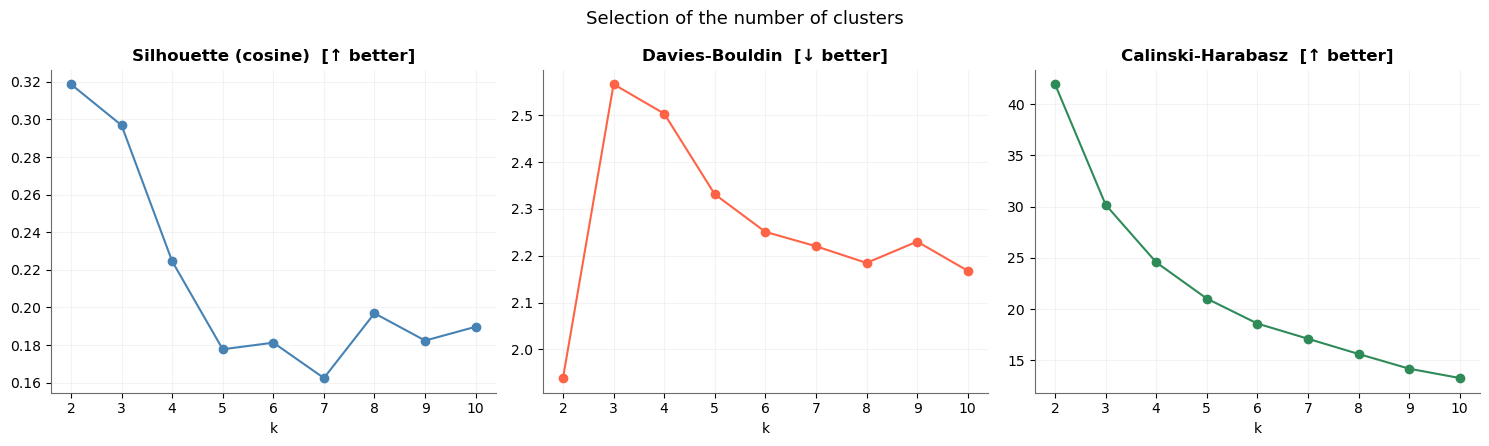

In [60]:
n     = len(datasets)
max_k = min(MAX_K_CLUSTERS, n - 1)

k_metrics = []

if max_k < 2:
    print("Dataset too small for clustering (n < 3).")
else:
    for k in range(2, max_k + 1):
        km     = KMeans(n_clusters=k, random_state=SEED, n_init=20)
        labels = km.fit_predict(dataset_embeddings_cluster)
        k_metrics.append({
            "k"                : k,
            "silhouette"       : silhouette_score(dataset_embeddings_cluster, labels, metric="cosine"),
            "davies_bouldin"   : davies_bouldin_score(dataset_embeddings_cluster, labels),
            "calinski_harabasz": calinski_harabasz_score(dataset_embeddings_cluster, labels),
        })

k_metrics_df = pd.DataFrame(k_metrics)
display(k_metrics_df)

if len(k_metrics_df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    plot_metrics = [
        ("silhouette",        "Silhouette (cosine)", "steelblue",  "↑ better"),
        ("davies_bouldin",    "Davies-Bouldin",        "tomato",     "↓ better"),
        ("calinski_harabasz", "Calinski-Harabasz",     "seagreen",   "↑ better"),
    ]
    for ax, (col, title_text, colour, note) in zip(axes.flat, plot_metrics):
        ax.plot(k_metrics_df["k"], k_metrics_df[col], marker="o", color=colour)
        ax.set_title(f"{title_text}  [{note}]"); ax.set_xlabel("k"); ax.grid(True, alpha=0.3)
    plt.suptitle("Selection of the number of clusters", fontsize=13)
    plt.tight_layout(); plt.show()

#### Figure 4.8 (dissertation) — Metrics for selecting the number of clusters

Section 4.6 (RQ5). Print version of the three charts above (silhouette with cosine distance, Davies–Bouldin and Calinski–Harabasz, for k between 2 and 10). As in the original charts, no k is marked: the selection criterion and the divergence between metrics are discussed in the text and in Table 4.11. Panel a) Águeda, c) Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_8_a_k_metrics.png


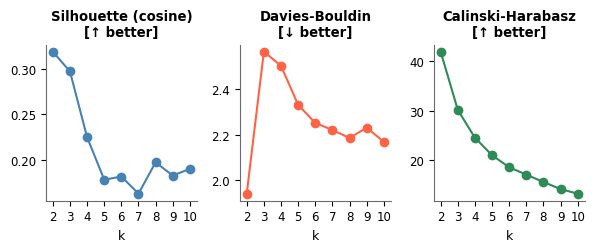

In [61]:
# ── Figure 4.8 (dissertation): metrics for selecting k ────────────────────────
plot_metrics = [
    ("silhouette",        "Silhouette (cosine)", "↑ better"),
    ("davies_bouldin",    "Davies-Bouldin",        "↓ better"),
    ("calinski_harabasz", "Calinski-Harabasz",     "↑ better"),
]
with plt.rc_context(DISS_FONT):
    fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, 2.6))
    for ax, (col, title_text, note), colour in zip(axes.flat, plot_metrics, ("steelblue", "tomato", "seagreen")):
        ax.plot(k_metrics_df["k"], k_metrics_df[col], marker="o", color=colour)
        ax.set_title(f"{title_text}\n[{note}]"); ax.set_xlabel("k")
        ax.set_xticks(k_metrics_df["k"])
    plt.tight_layout()
    export_diss_figure(fig, "4.8k", "k_metrics")


**Analysis of the results (9.2 — Choice of the number of clusters).**

The three internal metrics favour k = 2: the silhouette is at its maximum at that value (0.319), the Davies-Bouldin index at its minimum (1.939) and the Calinski-Harabasz index at its maximum (41.9). The silhouette for k = 3 is still close (0.297), but falls rapidly from there, dropping below 0.20 for k ≥ 5. Even in the best case, the silhouette is low, which indicates weakly separated groups.

**Rigorous interpretation of the selection of (k).**

The internal metrics help to choose an exploratory partition, but they do not determine the «true» number of themes. Selection by the highest *silhouette score* favours geometric separations in the space of the model and may prefer very aggregated solutions. The result should be weighed against substantive interpretability, the stability of the clustering and the purpose of the analysis. A (k=2) solution neither directly validates nor invalidates an external taxonomy of six dimensions.

In [62]:
# Automatic choice: k with the highest silhouette.
# You can change K_CLUSTERS manually in section 1 if the substantive interpretation justifies another value.

if K_CLUSTERS is not None:
    K_FINAL = K_CLUSTERS
    print(f"K_FINAL set manually in the configuration: {K_FINAL}")
elif len(k_metrics_df) > 0:
    K_FINAL = int(k_metrics_df.sort_values("silhouette", ascending=False).iloc[0]["k"])
    print(f"K_FINAL chosen automatically by maximum silhouette: {K_FINAL}")
else:
    K_FINAL = 1
    print("K_FINAL = 1 (insufficient datasets for clustering)")

print(f"\n  K final: {K_FINAL}")

K_FINAL chosen automatically by maximum silhouette: 2

  K final: 2


### 9.3 Application of the final clustering
With the chosen value of `k`, the KMeans algorithm is applied to the embeddings of the datasets. KMeans groups the datasets so as to minimise the sum of the squared distances of each dataset to the centroid of its cluster.

`n_init=50` random restarts are used (instead of the default of 10) to reduce the probability of the algorithm converging to a local optimum. `random_state=SEED` ensures reproducibility.

For each dataset, the **cosine similarity to the centroid of its cluster** is computed - the higher it is, the more representative the dataset is of the central theme of its cluster. The datasets with the highest similarity to the centroid are the most "typical" of the cluster and are presented in a table of representatives.

**Why KMeans and not another algorithm (e.g. DBSCAN, hierarchical clustering)?** KMeans was
chosen for three practical reasons: (1) it scales well to the size of this corpus and is
computationally inexpensive, making it possible to test multiple values of k quickly in Section
9.2; (2) it produces approximately spherical clusters in the space of normalised embeddings,
which is compatible with the cosine similarity metric used consistently in the rest of the
notebook; (3) it is widely documented and interpretable - each cluster has an explicit centroid,
which makes possible the analysis of the "most representative datasets" (highest similarity to the centroid)
carried out in this section. `n_init=50` (instead of the default value) increases the robustness of the initialisation,
reducing the probability of the algorithm converging to a suboptimal local minimum.

In [63]:
datasets_clusters = datasets.copy()

if K_FINAL <= 1:
    datasets_clusters["semantic_cluster"]    = 0
    datasets_clusters["centroid_similarity"] = np.nan
else:
    kmeans_final = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=50)
    clusters     = kmeans_final.fit_predict(dataset_embeddings_cluster)
    datasets_clusters["semantic_cluster"] = clusters

    centroids    = kmeans_final.cluster_centers_
    sim_centroids = cosine_similarity(dataset_embeddings_cluster, centroids)
    datasets_clusters["centroid_similarity"] = [
        sim_centroids[i, clusters[i]] for i in range(len(clusters))
    ]

print(f"Clustering with K={K_FINAL} completed.")
print("\nDistribution of the datasets by cluster:")
display(datasets_clusters["semantic_cluster"].value_counts().sort_index().rename("n_datasets"))

# Most representative datasets of each cluster
representative = (
    datasets_clusters
    .sort_values(["semantic_cluster","centroid_similarity"], ascending=[True, False])
    .groupby("semantic_cluster")
    .head(5)
    [["semantic_cluster","dataset_id","title","description","centroid_similarity"]]
)
print("\nMost representative datasets by cluster:")
display(representative)

Clustering with K=2 completed.

Distribution of the datasets by cluster:


semantic_cluster
0    105
1     71
Name: n_datasets, dtype: int64


Most representative datasets by cluster:


,semantic_cluster,dataset_id,title,description,centroid_similarity
107,0,41bba248-9793-44cc-8147-9f7985d59ccb,Rua do Casarão,Contagem do tráfego sobre a Rua do Casarão.,0.867205
130,0,1c532021-c3f4-4ed8-aa4a-97f191596628,Rua das Bouças,"Contagem de tráfego sobre a Rua das Bouças, em Aguada de Cima [13 de outubro a 3 de novembro de 2016]. No ficheiro ods, os dados referem-se apenas a um sent...",0.865472
140,0,e012444f-157a-4253-867a-51d4b40f2943,Rua Joaquim Valente de Almeida,"Contagem de tráfego sobre a Rua Joaquim Valente de Almeida, sita no centro da cidade, do Bairro do Joinal às Barreiras [19 de abril a 6 de maio de 2016]. No...",0.861340
136,0,928c1400-25ec-40b5-871b-a0847e3bebbc,Rua do Sabugueiro,"Contagem de tráfego sobre a Rua do Sabugueiro, em Aguada de Cima [3 a 15 de novembro de 2016]. No ficheiro ods, os dados referem-se apenas a um sentido de t...",0.858739
142,0,894cd12d-3b14-4212-9c84-784cc9e8ef0f,Rua Manuel de Sousa Carneiro,"Contagem de tráfego sobre a Rua Manuel Sousa Carneiro, no bairro da Bicha Moura, centro da cidade [18 a 30 de janeiro de 2017]. No ficheiro ods, os dados re...",0.853363
32,1,def83cb9-e427-47d1-bf2f-ba8bf346056a,"Espaço Florestal de Proteção, PDM 12 Ordenamento","Os Espaços Florestais de Proteção fazem parte da Planta de Ordenamento do Plano Diretor Municipal - PDM em vigor ( Diário da República, 2.ª série — N.º 44 —...",0.926145
33,1,dc19fcae-4bb6-433c-a1cc-9fe4c538e039,"Espaço Florestal de Conservação Estrita, PDM 12 Ordenamento","Os Espaços Florestais de Conservação Estrita fazem parte da Planta de Ordenamento do Plano Diretor Municipal - PDM em vigor ( Diário da República, 2.ª série...",0.923498
15,1,b202d392-49b4-4b72-8a28-76f47ee822c3,Espaços centrais urbanizaveis - PDM 12 Ordenamento,"Os Espaços centrais urbanizaveis fazem parte da Planta de Ordenamento do Plano Diretor Municipal - PDM em vigor ( Diário da República, 2.ª série — N.º 44 — ...",0.911572
10,1,a8368b1d-5f2b-4686-ba51-daa457c2dbf7,Zonas Sensíveis e Mistas,"As Zonas Sensíveis e Mistas fazem parte da Planta de Ordenamento do Plano Diretor Municipal - PDM em vigor ( Diário da República, 2.ª série — N.º 44 — 1 de ...",0.901206
41,1,cb4d0971-2aee-49ce-9a96-50ad2d7273e0,"Espaços de Recursos Hidrominerais, Ordenamento 2012","Os Espaços de Recursos Hidrominerais fazem parte da Planta de Ordenamento do Plano Diretor Municipal - PDM em vigor ( Diário da República, 2.ª série — N.º 4...",0.898969


#### 9.3.1 Check: PDM records by cluster

Some of the longest datasets are PDM records with standardised descriptions. This check shows in which cluster each PDM record falls and the proportion of PDM records in each cluster. It serves only to document a possible influence of the standardised descriptions: the records are not removed and `k` is not changed.


In [64]:
# ── 9.3.1 PDM records by cluster ─────────────────────────────────────────────
is_pdm = datasets_clusters["title"].astype(str).str.contains(r"\bPDM\b|Plano Diretor Municipal", case=False, regex=True)
tab_pdm = pd.crosstab(datasets_clusters["semantic_cluster"], is_pdm.map({True: "PDM", False: "others"}))
for col in ["PDM", "others"]:
    if col not in tab_pdm.columns: tab_pdm[col] = 0
tab_pdm = tab_pdm[["PDM", "others"]]
tab_pdm["n_total"] = tab_pdm.sum(axis=1)
tab_pdm["% PDM in the cluster"] = (tab_pdm["PDM"] / tab_pdm["n_total"] * 100).round(1)
tab_pdm["% of the PDM records in this cluster"] = (tab_pdm["PDM"] / max(int(is_pdm.sum()), 1) * 100).round(1)
print(f"PDM records: {int(is_pdm.sum())} of {len(datasets_clusters)}")
display(tab_pdm)
if is_pdm.any():
    display(datasets_clusters.loc[is_pdm, ["dataset_id", "title", "semantic_cluster"]].sort_values("semantic_cluster"))


PDM records: 27 of 176


title,PDM,others,n_total,% PDM in the cluster,% of the PDM records in this cluster
semantic_cluster,,,,,
0,0,105,105,0.0,0.0
1,27,44,71,38.0,100.0


,dataset_id,title,semantic_cluster
7,331652d0-1e12-423f-9874-6f39eb9dcd98,PDM 2024 - Planta de Ordenamento - Estrutura Ecológica Municipal,1
8,13bb60d8-9c1b-4f13-8324-e9327bff043e,PDM 2024 - Planta de Ordenamento – Zonas Sensíveis e Mistas,1
9,35ef0ccc-ffcf-4bec-86ea-f390b52d69bc,PDM 2024 - Planta de Condicionantes – Rede de Defesa da Floresta Contra Incêndios,1
12,4510f01d-b8b6-42a0-b0f0-35407332366b,Perímetro Urbano da Cidade - PDM 12 Ordenamento,1
13,0f3d5ee3-c02f-46a5-a1c7-30de5c208b88,Espaços de atividades económicas - PDM 12 Ordenamento,1
14,fc538347-05df-4a00-ac61-2ba4f1d761b4,Espaços centrais - PDM 12 Ordenamento,1
15,b202d392-49b4-4b72-8a28-76f47ee822c3,Espaços centrais urbanizaveis - PDM 12 Ordenamento,1
16,2a430224-b947-49e5-9bd6-3360d20d0de7,Espaços histórico-culturais - PDM 12 Ordenamento,1
17,f98ae12a-93e9-4959-8941-20b7aea6e5ad,Espaço de infraestruturas aeronauticas - PDM 12 Ordenamento,1
18,80b569a1-1b0c-479a-9302-fe3c7da60945,Espaços residenciais tipo 1 - PDM 12 Ordenamento,1


**Analysis of the results (9.3 — Application of the final clustering).**

With k = 2, KMeans produces a partition that is unbalanced in size: **Cluster 0 has 105 datasets (59.7%)** and **Cluster 1 has 71 (40.3%)**. The imbalance is consistent with the composition of the catalogue. Cluster 0 corresponds above all to the road network and includes the 79 traffic counts, whereas Cluster 1 brings together spatial planning, with the 46 PDM records. The most distinctive terms (next cell) confirm this reading: «rua» (street), «tráfego» (traffic) and «contagem» (count) in Cluster 0, «pdm», «ordenamento» (planning) and «plano» (plan) in Cluster 1. The separation between the two groups is, even so, weak (silhouette = 0.319).

#### 9.3.2 Composition of the clusters by document series

Cross-tabulation of the final clusters with the series identified in 4.1.1 (Section 4.6 of the dissertation).

In [65]:
# ── 9.3.2 Cluster × document series ──────────────────────────────────────────
_ct = pd.crosstab(datasets_clusters["semantic_cluster"],
                  SERIES_BY_ID.reindex(datasets_clusters["dataset_id"]).to_numpy(),
                  rownames=["cluster"], colnames=["series"], margins=True, margins_name="Total")
DISSERTATION_COUNTS["Cluster×series"] = _ct.reset_index()
display(_ct)

series,Outside the series,PDM,Traffic counts,Total
cluster,,,,
0,26,0,79,105
1,25,46,0,71
Total,51,46,79,176


### 9.4 Representative terms by cluster

To interpret the clusters found lexically, TF-IDF is fitted to the texts of the datasets and, for each term, the mean weight **inside and outside each cluster** is compared. The terms with the greatest positive difference are the ones that best characterise, relatively, the vocabulary of the datasets in that group.

#### Important: TF-IDF is interpretative here, not classificatory

This is a completely different use from the TF-IDF used in Section 6. Here, datasets are not being compared with anchors; the most characteristic terms of each group discovered by the clustering are being extracted. The aim is only to help the human analyst understand what the datasets of each cluster have in common, giving it an interpretable name or label.

For example, if Cluster 0 has "via", "estrada", "percurso", "sinalização", "transporte" (road, route, signage, transport) as representative terms, it may be interpreted, as a hypothesis to be confirmed with the representative records, as close to the "Mobility" dimension, even though the clustering algorithm discovered it without any information about dimensions.


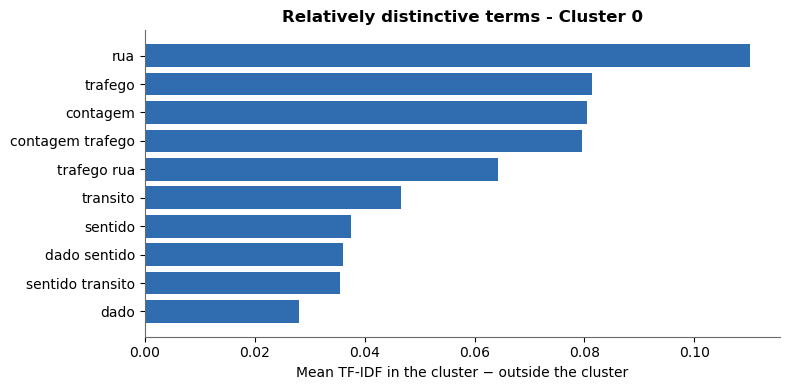

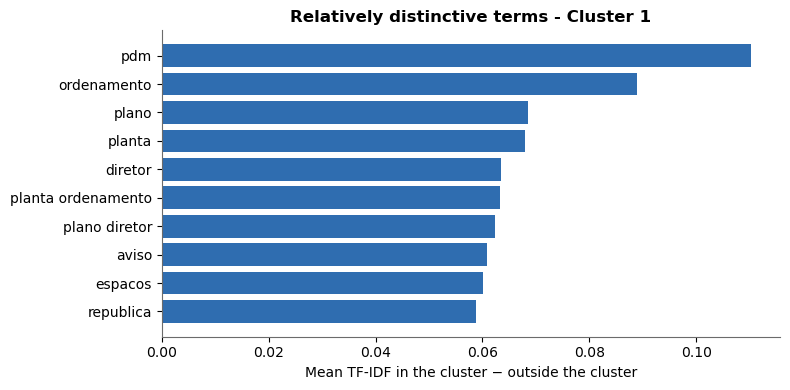

In [66]:
tfidf_cl = TfidfVectorizer(**TFIDF_CLUSTER_PARAMS, stop_words=list(STOPWORDS_TFIDF))
X_tfidf_cl = tfidf_cl.fit_transform(datasets_clusters["doc_text_tfidf"])
vocab_terms = np.array(tfidf_cl.get_feature_names_out())

terms_by_cluster = []
for cid in sorted(datasets_clusters["semantic_cluster"].unique()):
    idx = (datasets_clusters["semantic_cluster"] == cid).to_numpy()
    mean_in = np.asarray(X_tfidf_cl[idx].mean(axis=0)).ravel()
    mean_out = np.asarray(X_tfidf_cl[~idx].mean(axis=0)).ravel() if (~idx).any() else np.zeros_like(mean_in)
    distinctiveness = mean_in - mean_out
    top = distinctiveness.argsort()[::-1][:20]
    for term, m_in, m_out, dif in zip(vocab_terms[top], mean_in[top], mean_out[top], distinctiveness[top]):
        if dif > 0:
            terms_by_cluster.append({
                "semantic_cluster": cid, "term": term,
                "mean_tfidf_in_cluster": float(m_in), "mean_tfidf_outside": float(m_out),
                "mean_distinctiveness": float(dif),
            })
terms_by_cluster_df = pd.DataFrame(terms_by_cluster)

for cid in sorted(datasets_clusters["semantic_cluster"].unique()):
    subset = terms_by_cluster_df.query("semantic_cluster == @cid").head(10)
    if subset.empty: continue
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(subset["term"][::-1], subset["mean_distinctiveness"][::-1], color=EMB_COLOUR)
    ax.set_xlabel("Mean TF-IDF in the cluster − outside the cluster")
    ax.set_title(f"Relatively distinctive terms - Cluster {cid}")
    plt.tight_layout(); plt.show()

**Analysis of the results (9.4 — Distinctive terms of the clusters).**

The most distinctive terms confirm the documentary reading of the two groups. In Cluster 0, «rua», «tráfego», «contagem», «contagem tráfego» and «trânsito» dominate, typical of the traffic counts; in Cluster 1, «pdm», «ordenamento», «plano», «planta» and «diretor», typical of the planning instruments. Many of these terms describe the type of document, not an ENTI theme, which reinforces the idea that the grouping follows the series of the catalogue.

**Rigorous interpretation of the cluster terms.**

The terms are sorted by the difference between the mean TF-IDF weight inside and outside each cluster. This measure is more informative than the internal frequency alone, but it remains descriptive and may contain redundant unigrams and bigrams. The thematic interpretation should be confirmed through the datasets closest to the centroid and through qualitative inspection.

### 9.5 Visualisation of the clusters with PCA

The embeddings have 384 dimensions and cannot be visualised directly. **Principal Component Analysis (PCA)** projects the embeddings onto 2 dimensions, preserving as much of the original variance as possible.

The variance explained by the first two principal components is indicated in the axis labels. If the explained variance is low (e.g. PC1 + PC2 < 30%), the projection loses a lot of information and the chart should be interpreted with caution: clusters that appear to overlap in 2D may be well separated in the original space.

#### The clustering was built in the original space

It is essential to stress that the clustering was built and evaluated in the original 384-dimensional space (with the cosine silhouette metric), not in the 2D projection. PCA is used only for visualisation, never to determine the clusters. The projection may distort distances and make clusters that are well defined in the original space appear to overlap.


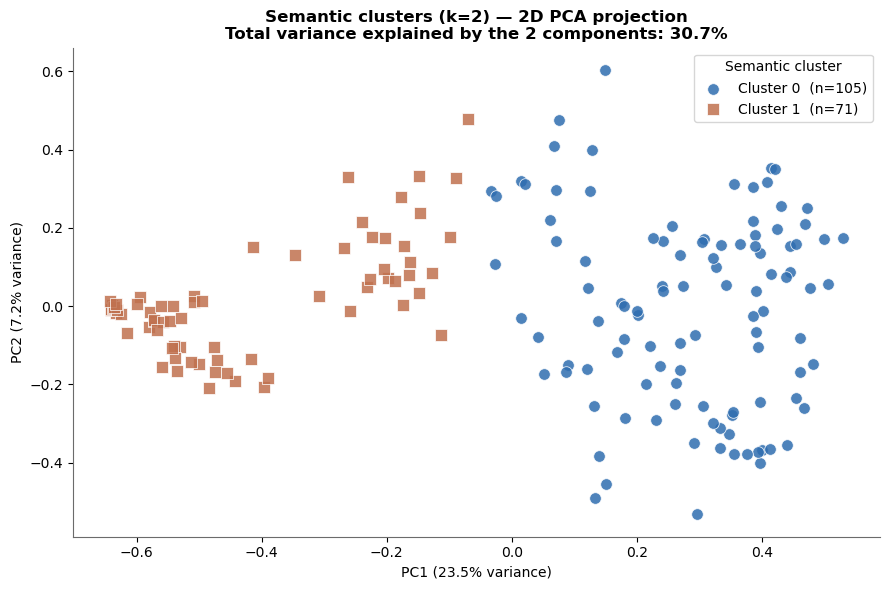

Note: the clustering was built in the original embedding space (384 dimensions), not in this 2D projection. PCA is only an auxiliary visualisation.
Caution: the 2 components shown explain only 30.7% of the total variance — the visual separation here is illustrative and may hide/distort part of the real 384-dimensional structure.


In [67]:
if len(datasets_clusters) >= 2:
    pca   = PCA(n_components=2, random_state=SEED)
    coords = pca.fit_transform(dataset_embeddings_cluster)
    datasets_clusters["pca_1"] = coords[:, 0]
    datasets_clusters["pca_2"] = coords[:, 1]

    var_exp = pca.explained_variance_ratio_ * 100
    var_total = var_exp[:2].sum()

    # Discrete legend — one entry per cluster, with explicit colour and count of
    # datasets (a continuous colour bar would not correspond to discrete clusters).
    cluster_ids = sorted(datasets_clusters["semantic_cluster"].unique())
    # Fixed colours and markers per cluster (sober palette + shape as secondary encoding)

    fig, ax = plt.subplots(figsize=(9, 6))
    for idx, cid in enumerate(cluster_ids):
        mask = datasets_clusters["semantic_cluster"] == cid
        n_points = mask.sum()
        ax.scatter(
            datasets_clusters.loc[mask, "pca_1"],
            datasets_clusters.loc[mask, "pca_2"],
            color=CATEGORICAL_PALETTE[idx % len(CATEGORICAL_PALETTE)], marker=MARKERS[idx % len(MARKERS)],
            alpha=0.85, s=70, edgecolors="white", linewidths=0.6,
            label=f"Cluster {cid}  (n={n_points})",
        )
    ax.legend(title="Semantic cluster", loc="best", frameon=True)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% variance)")
    ax.set_title(
        f"Semantic clusters (k={K_FINAL}) — 2D PCA projection\n"
        f"Total variance explained by the 2 components: {var_total:.1f}%"
    )
    plt.tight_layout(); plt.show()

    # Note: the variance explained by the first 2 components is
    # typically low (~30%) because the embedding space has 384
    # dimensions — the visual separation in 2D is only illustrative, NOT a
    # faithful representation of the full structure used by KMeans (which
    # operated on the original 384 dimensions, not on this projection).
    print(f"Note: the clustering was built in the original embedding space "
          f"(384 dimensions), not in this 2D projection. PCA is only an "
          f"auxiliary visualisation.")
    print(f"Caution: the 2 components shown explain only {var_total:.1f}% "
          f"of the total variance — the visual separation here is illustrative and "
          f"may hide/distort part of the real 384-dimensional structure.")


#### Figure 4.8 (dissertation) — Projection of the clusters onto the first two principal components

Section 4.6 (RQ5). Print version of the scatter plot above, with the same colours and markers per cluster. The projection serves only for visualisation: the clusters were computed in the original 384-dimensional space. Panel b) Águeda, d) Porto.

Exported: outputs\agueda\03_chunksAllText\dissertation_figures\figure_4_8_b_pca_projection.png


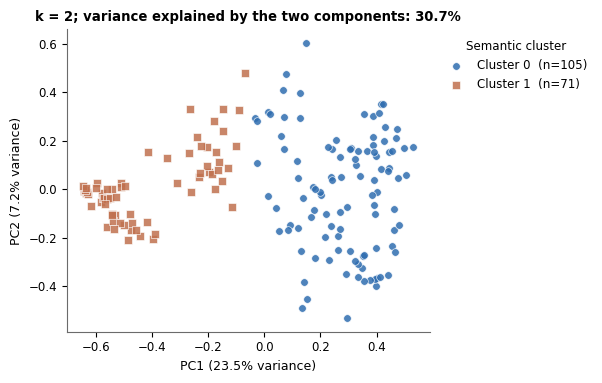

In [68]:
# ── Figure 4.8 (dissertation): PCA projection of the clusters ────────────────
with plt.rc_context(DISS_FONT):
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.9))
    for idx, cid in enumerate(cluster_ids):
        mask = datasets_clusters["semantic_cluster"] == cid
        ax.scatter(datasets_clusters.loc[mask, "pca_1"], datasets_clusters.loc[mask, "pca_2"],
                   color=CATEGORICAL_PALETTE[idx % len(CATEGORICAL_PALETTE)], marker=MARKERS[idx % len(MARKERS)],
                   alpha=0.85, s=30, edgecolors="white", linewidths=0.5,
                   label=f"Cluster {cid}  (n={int(mask.sum())})")
    ax.legend(title="Semantic cluster", loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set_xlabel(num(f"PC1 ({var_exp[0]:.1f}% variance)"))
    ax.set_ylabel(num(f"PC2 ({var_exp[1]:.1f}% variance)"))
    ax.set_title(num(f"k = {K_FINAL}; variance explained by the two components: {var_total:.1f}%"))
    plt.tight_layout()
    export_diss_figure(fig, "4.8p", "pca_projection")


**Analysis of the results (9.5 — Visualisation of the clusters with PCA).**

The projection onto the first two principal components explains only **30.7% of the total variance** (23.5% + 7.2%), which is not surprising in an original space of 384 dimensions. The visual separation therefore has only illustrative value: KMeans was applied in the full space, not in this projection, so neither the separation nor the proximity between the two groups in this chart makes it possible, on its own, to assess the quality of the clustering. The internal metrics (Section 9.2) indicate weak separation (silhouette = 0.319). Even so, a clear tendency can be seen: Cluster 1 is concentrated on the left side of the chart (negative PC1), whereas Cluster 0 occupies the right half and extends to more extreme values of PC2.

## 10. Relationship between clusters and assigned dimensions

This section cross-references the results of the two approaches:
- The **semantic clusters** of Section 9 (discovered in an unsupervised way, without information about dimensions);
- The **assigned dimensions** of Sections 6 and 7 (based on similarity with the anchor texts).

The analysis is carried out for **all 4 anchor versions** (original, 50 words, 100 words,
150 words), making it possible to assess whether the correspondence between clusters and dimensions is robust
regardless of the wording of the anchors, or whether it varies with the length and vocabulary of the reference
texts. The clusters (Section 9) are fixed — built only once from the embeddings
of the datasets — and what changes between versions is only the Smart City dimension assigned to each dataset.

### Cluster × dimension matrices

For each cluster, the percentage of datasets in each Smart City dimension is computed (row normalisation). A row with 90% in a single column indicates that almost all the datasets in that cluster were classified in the same dimension — the cluster "corresponds" to that dimension. A row spread across several columns indicates a thematically mixed cluster.

If the clusters coincide with the dimensions, this constitutes descriptive evidence of a structural correspondence
between two organisations of the corpus — not a validation of the classification system or of the
taxonomy, because both depend on the same embedding model and may respond to the same
repeated vocabulary. Divergences may reveal groupings (for example, by document type
or description template) that the taxonomy does not capture.

**How to read the cross-tabulation (crosstab) that follows:** each cell shows the percentage of
datasets of a given cluster (row) that were classified in a given Smart City
dimension (column), by the method indicated. Normalisation is done by row (`normalize="index"`), that is, each row sums to 100%. This answers the question "within this cluster, how are the
assigned dimensions distributed?", instead of "within this dimension, how are
the clusters distributed?" (which would be the inverse question, normalised by column). The first formulation is
more natural in this context because the aim is to characterise each cluster found by its
composition in terms of the existing taxonomy.


  Anchor version: original


,dataset_id,title,semantic_cluster,dimension_embeddings,dimension_tfidf
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,1,Smart Quality of Life,Smart Quality of Life
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,1,Smart Environment,Smart Environment
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,0,Smart Mobility,Smart Mobility
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,0,Smart Mobility,Smart Mobility
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,0,Smart Environment,Smart Governance


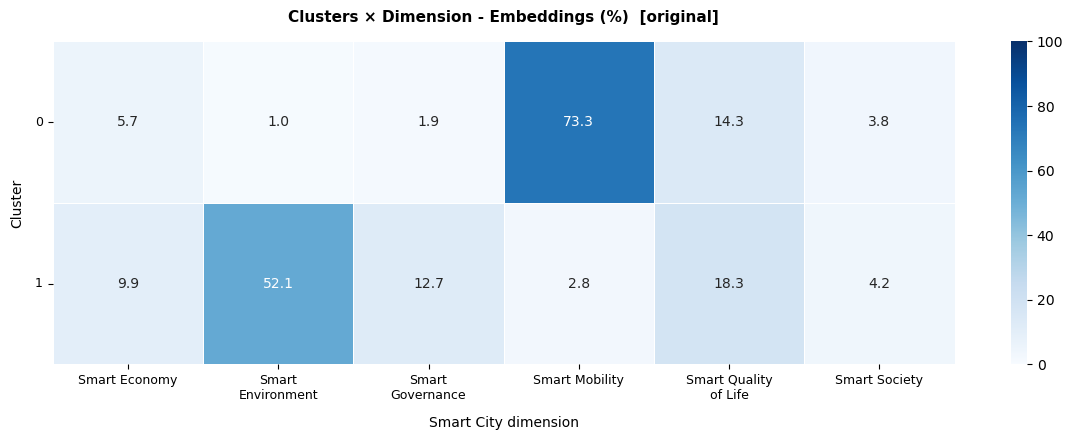

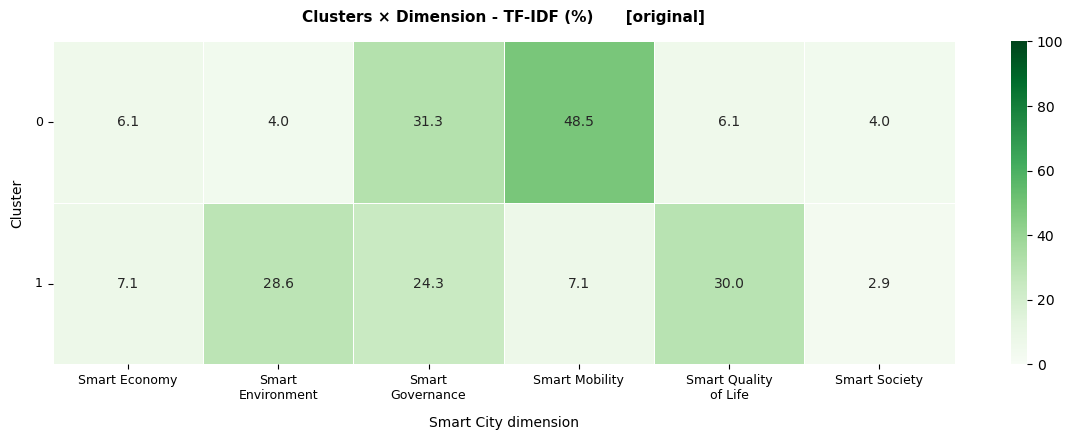


  Anchor version: 50_words


,dataset_id,title,semantic_cluster,dimension_embeddings,dimension_tfidf
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,1,Smart Environment,Smart Society
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,1,Smart Environment,Smart Environment
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,0,Smart Environment,Smart Mobility
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,0,Smart Mobility,Smart Mobility
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,0,Smart Environment,Smart Governance


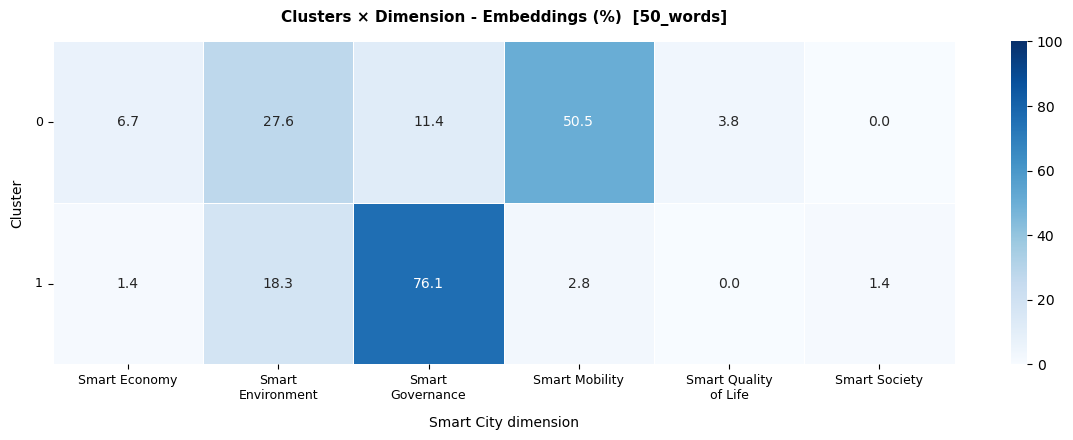

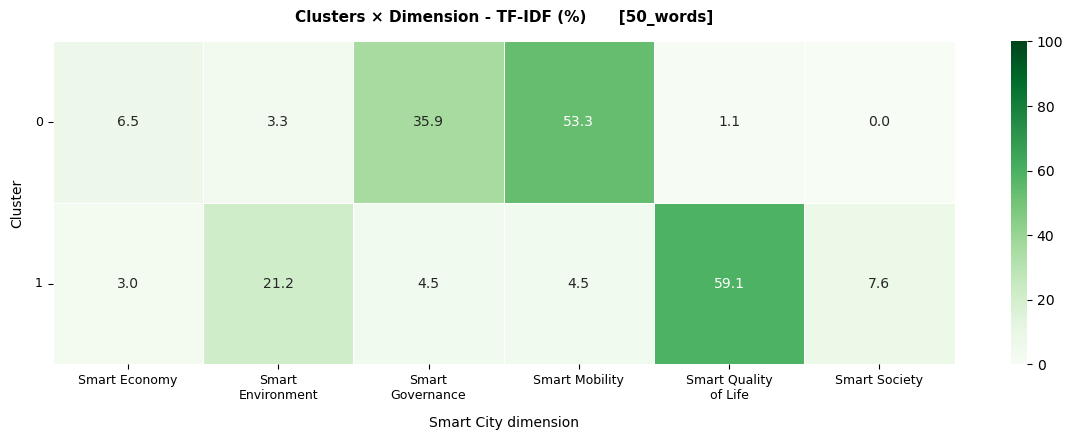


  Anchor version: 100_words


,dataset_id,title,semantic_cluster,dimension_embeddings,dimension_tfidf
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,1,Smart Quality of Life,Smart Economy
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,1,Smart Environment,Smart Environment
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,0,Smart Mobility,Smart Mobility
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,0,Smart Mobility,Smart Mobility
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,0,Smart Society,Smart Governance


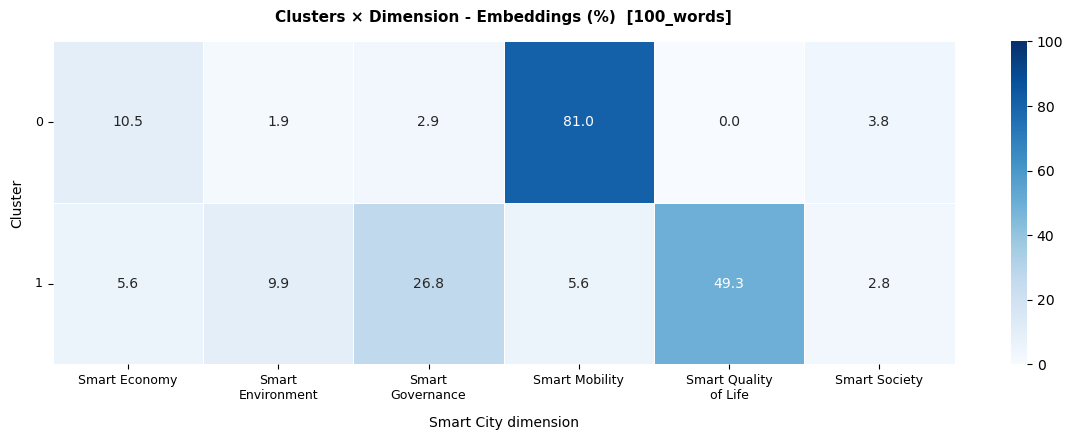

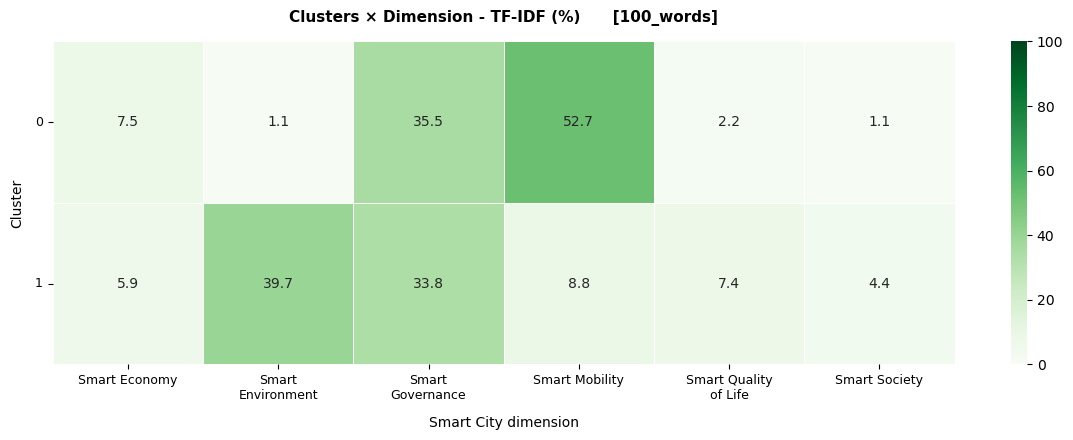


  Anchor version: 150_words


,dataset_id,title,semantic_cluster,dimension_embeddings,dimension_tfidf
0,5df5aa64-cd56-4aa1-bad8-d0b2fe6e5122,Áreas de Reabilitação Urbana - ARU 2023,1,Smart Environment,Smart Society
1,8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,1,Smart Environment,Smart Environment
2,0400393f-5c83-4cd3-84ee-85bf6be15b1c,Rua dos Industriais 2,0,Smart Mobility,Smart Mobility
3,b6da0b12-5e33-4b9f-b486-bb61a97eaf7f,Ponto de carregamento de veículos elétricos,0,Smart Mobility,Smart Mobility
4,2e473998-048d-45a1-ac35-8904b264dfd9,Estação hidrométrica de Alhandra,0,Smart Environment,Smart Governance


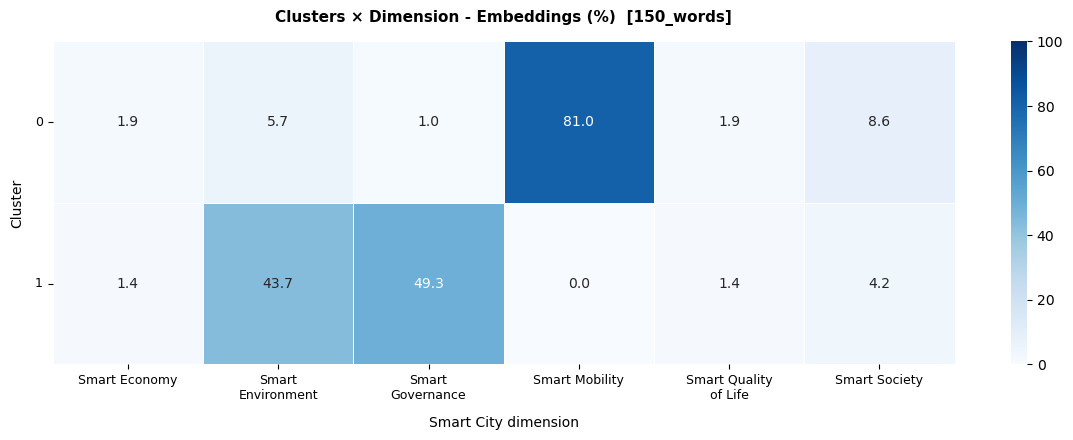

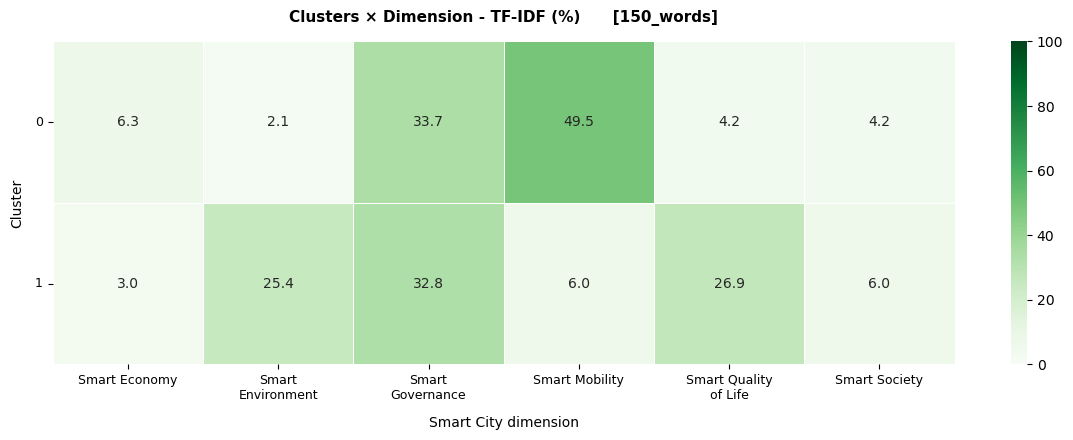


datasets_clusters: added the dimensions of the 4 anchor versions.


In [69]:
# ── Cluster × dimension matrices for ALL anchor versions ─────────────────────
# For each anchor version, we join the dimensions assigned by Embeddings
# and TF-IDF to the clusters DataFrame and produce two heatmaps (one per method).
# This makes it possible to see whether the correspondence between clusters and dimensions is robust
# regardless of the anchor version used, or whether it varies between versions.

for version, obj in results_by_version.items():
    class_v = obj["results"][["dataset_id", "dimension_embeddings", "dimension_tfidf"]]

    # Join to the clusters — suffixes to avoid conflicts if we iterate several times
    dc_v = datasets_clusters[["dataset_id", "title", "semantic_cluster"]].merge(
        class_v, on="dataset_id", how="left", validate="one_to_one"
    )

    print(f"\n{'='*70}")
    print(f"  Anchor version: {version}")
    print(f"{'='*70}")
    display(dc_v[["dataset_id", "title", "semantic_cluster",
                   "dimension_embeddings", "dimension_tfidf"]].head())

    for col, title_text, cmap in [
        ("dimension_embeddings",
         f"Clusters × Dimension - Embeddings (%)  [{version}]", CMAP_EMB),
        ("dimension_tfidf",
         f"Clusters × Dimension - TF-IDF (%)      [{version}]", CMAP_TFIDF),
    ]:
        valid = dc_v.dropna(subset=[col])
        if valid.empty:
            print(f"  No valid data for {col} in version {version}")
            continue
        mat = pd.crosstab(valid["semantic_cluster"], valid[col],
                          normalize="index") * 100
        n_rows = len(mat)
        fig, ax = plt.subplots(figsize=(12, max(4.5, 1.5 * n_rows)))
        sns.heatmap(mat, annot=True, fmt=".1f", cmap=cmap,
                    vmin=0, vmax=100, ax=ax, linewidths=0.5,
                    annot_kws={"size": 10})
        ax.set_title(title_text, fontsize=11, fontweight="bold", pad=14)
        ax.set_xlabel("Smart City dimension", labelpad=10)
        ax.set_ylabel("Cluster", labelpad=8)
        # Dimension labels slanted (45°) for legibility
        ax.tick_params(axis="x", labelsize=9); format_x_labels(ax)
        ax.tick_params(axis="y", labelsize=9); horizontal_y_labels(ax)
        plt.tight_layout()
        plt.show()

# Add to datasets_clusters the dimensions assigned in EACH version
# (columns dimension_embeddings_<version> and dimension_tfidf_<version>), for export.
for version, obj in results_by_version.items():
    dims_v = obj["results"][["dataset_id", "dimension_embeddings", "dimension_tfidf"]].rename(columns={
        "dimension_embeddings": f"dimension_embeddings_{version}",
        "dimension_tfidf": f"dimension_tfidf_{version}",
    })
    # Removes columns of the same version if they already exist (avoids duplication on re-execution)
    datasets_clusters = datasets_clusters.drop(
        columns=[c for c in dims_v.columns if c != "dataset_id" and c in datasets_clusters.columns])
    datasets_clusters = datasets_clusters.merge(dims_v, on="dataset_id", how="left", validate="one_to_one")
print(f"\ndatasets_clusters: added the dimensions of the {len(results_by_version)} anchor versions.")


**Analysis of the results (10 — Clusters × dimensions in the four versions).**

In Cluster 0, the modal dimension is always Mobility, in both methods and in all four versions, covering between 50.5% and 81.0% of the datasets in the Embeddings and about half of the valid ones in TF-IDF. In Cluster 1, on the contrary, the modal dimension changes from version to version: in the Embeddings it goes through Environment (original), Governance (50 and 150 words) and Quality of Life (100 words), and in TF-IDF through Quality of Life, Environment and Governance. The spatial planning instruments therefore lie in a boundary zone between dimensions, consistent with their transversal character.

### 10.1 Executive summary

In [70]:
# ── Automatic descriptive summary ─────────────────────────────────────────────
print("=" * 72); print("DESCRIPTIVE SUMMARY — DOES NOT CONSTITUTE A VALIDATION OF ACCURACY"); print("=" * 72)
print(f"Datasets: {len(datasets)} | versions: {len(results_by_version)} | dimensions: "
      f"{len(next(iter(results_by_version.values()))['scores_embeddings'].columns)}")

st_emb = (~instability_df["unstable_emb"]).mean() * 100
mask_tf = instability_df["tfidf_valid_all_versions"]
st_tf = ((~instability_df.loc[mask_tf, "unstable_tfidf_among_valid"]).mean() * 100
          if mask_tf.any() else np.nan)
print(f"\nEmbeddings — same dimension in the four versions: {st_emb:.1f}% (n={len(instability_df)})")
print(f"TF-IDF — same dimension among valid cases in the four versions: {st_tf:.1f}% (n={mask_tf.sum()})")
print(f"TF-IDF — stable coverage: {instability_df['tfidf_coverage_stable'].mean()*100:.1f}%")

for method, agreement_col in [("Embeddings", "agreement_emb_%"), ("TF-IDF — valid", "agreement_tfidf_valid_%")]:
    best_row = pairwise_comparison_df.loc[pairwise_comparison_df[agreement_col].idxmax()]
    worst_row = pairwise_comparison_df.loc[pairwise_comparison_df[agreement_col].idxmin()]
    print(f"\n{method}: highest agreement {best_row['version_1']} × {best_row['version_2']} = {best_row[agreement_col]:.1f}%")
    print(f"{method}: lowest agreement {worst_row['version_1']} × {worst_row['version_2']} = {worst_row[agreement_col]:.1f}%")

print(f"\nExploratory clustering: k={K_FINAL}")
for cid, n_ds in datasets_clusters["semantic_cluster"].value_counts().sort_index().items():
    terms = terms_by_cluster_df.query("semantic_cluster == @cid")["term"].head(6).tolist()
    print(f"Cluster {cid}: n={n_ds}; relatively distinctive terms: {', '.join(terms) or '—'}")
print("\nNote: stability, agreement and clustering describe internal consistency; they do not measure correctness.")

DESCRIPTIVE SUMMARY — DOES NOT CONSTITUTE A VALIDATION OF ACCURACY
Datasets: 176 | versions: 4 | dimensions: 6

Embeddings — same dimension in the four versions: 37.5% (n=176)
TF-IDF — same dimension among valid cases in the four versions: 59.5% (n=158)
TF-IDF — stable coverage: 93.8%

Embeddings: highest agreement original × 100_words = 67.0%
Embeddings: lowest agreement original × 50_words = 44.9%

TF-IDF — valid: highest agreement original × 150_words = 85.2%
TF-IDF — valid: lowest agreement 50_words × 100_words = 67.7%

Exploratory clustering: k=2
Cluster 0: n=105; relatively distinctive terms: rua, trafego, contagem, contagem trafego, trafego rua, transito
Cluster 1: n=71; relatively distinctive terms: pdm, ordenamento, plano, planta, diretor, planta ordenamento

Note: stability, agreement and clustering describe internal consistency; they do not measure correctness.


**Analysis of the results (10 — Descriptive summary).**

The summary brings together the indicators already discussed: 37.5% stability of the predominant dimension in the Embeddings, 59.5% in TF-IDF among the cases valid in the four versions, and a partition into two clusters with weak separation. Read together, it shows a catalogue with a relatively stable group of mobility records; in other records, the predominant dimension varies with the anchor version or with the method.

**Reading the summary.**

The summary presents separately the dimensional stability of the embeddings, the TF-IDF stability in the classifiable subset and the stability of lexical coverage. A difference between methods does not demonstrate superiority without external validation. The best and worst pairs describe only the versions tested. The clusters are exploratory and the terms presented are relatively distinctive, not validated labels.

### 10.2 Agreement between clusters and dimensions: Embeddings vs. TF-IDF

The two previous heatmaps show, separately, which dimension each cluster is
most associated with according to each method. The next cell cross-references this information
explicitly: it identifies the dominant dimension of each cluster in each method and
flags the cases in which **the two methods assign the same cluster to different
dimensions** - a structural disagreement, not just dataset-by-dataset (the cluster may be
internally coherent, but the two methods associate it with different Smart City dimensions).

In [71]:
# ── Dominant distributions by cluster with explicit denominators ─────────────
cluster_summaries = []
for version, obj in results_by_version.items():
    class_v = obj["results"][["dataset_id", "dimension_embeddings", "dimension_tfidf"]]
    dc_v = datasets_clusters[["dataset_id", "semantic_cluster"]].merge(
        class_v, on="dataset_id", validate="one_to_one")
    for cid, sub in dc_v.groupby("semantic_cluster", sort=True):
        emb_counts = sub["dimension_embeddings"].value_counts()
        tf_counts = sub["dimension_tfidf"].value_counts()
        de = emb_counts.index[0] if len(emb_counts) else None
        dt = tf_counts.index[0] if len(tf_counts) else None
        n_tf = int(sub["dimension_tfidf"].notna().sum())
        tie_emb = len(emb_counts) > 1 and emb_counts.iloc[0] == emb_counts.iloc[1]
        tie_tf = len(tf_counts) > 1 and tf_counts.iloc[0] == tf_counts.iloc[1]
        cluster_summaries.append({
            "version": version, "cluster": cid, "n_total": len(sub),
            "n_tfidf_valid": n_tf, "n_tfidf_zero": len(sub) - n_tf,
            "dominant_emb": de, "pct_emb_total": emb_counts.iloc[0] / len(sub) * 100 if len(emb_counts) else np.nan,
            "tie_emb": tie_emb,
            "dominant_tfidf": dt,
            "pct_tfidf_valid": tf_counts.iloc[0] / n_tf * 100 if n_tf and len(tf_counts) else np.nan,
            "pct_tfidf_total": tf_counts.iloc[0] / len(sub) * 100 if len(tf_counts) else np.nan,
            "tie_tfidf": tie_tf,
            "dominants_match": de == dt and not tie_emb and not tie_tf,
        })

cluster_dim_summary_df = pd.DataFrame(cluster_summaries)
display(cluster_dim_summary_df)
print("The coincidence of the modal categories is an aggregate synthesis and is not equivalent")
print("to dataset-by-dataset agreement or to a substantive validation of the label.")

,version,cluster,n_total,n_tfidf_valid,n_tfidf_zero,dominant_emb,pct_emb_total,tie_emb,dominant_tfidf,pct_tfidf_valid,pct_tfidf_total,tie_tfidf,dominants_match
0,original,0,105,99,6,Smart Mobility,73.333333,False,Smart Mobility,48.484848,45.714286,False,True
1,original,1,71,70,1,Smart Environment,52.112676,False,Smart Quality of Life,30.000000,29.577465,False,False
2,50_words,0,105,92,13,Smart Mobility,50.476190,False,Smart Mobility,53.260870,46.666667,False,True
3,50_words,1,71,66,5,Smart Governance,76.056338,False,Smart Quality of Life,59.090909,54.929577,False,False
4,100_words,0,105,93,12,Smart Mobility,80.952381,False,Smart Mobility,52.688172,46.666667,False,True
5,100_words,1,71,68,3,Smart Quality of Life,49.295775,False,Smart Environment,39.705882,38.028169,False,False
6,150_words,0,105,95,10,Smart Mobility,80.952381,False,Smart Mobility,49.473684,44.761905,False,True
7,150_words,1,71,67,4,Smart Governance,49.295775,False,Smart Governance,32.835821,30.985915,False,True


The coincidence of the modal categories is an aggregate synthesis and is not equivalent
to dataset-by-dataset agreement or to a substantive validation of the label.


**Analysis of the results (10 — Dominant dimension by cluster).**

The dominant dimensions of the two methods coincide in all four versions in Cluster 0 (Mobility), but in only one version in Cluster 1 (Governance, with 150 words). The correspondence between the emergent structure and the dimensions is thus clear only in the group with explicit thematic vocabulary.

**Rigorous interpretation of the cluster–dimension relationship.**

The repetition of a modal category in all four versions constitutes evidence of a recurring aggregate pattern under the conditions tested. It does not mean that all the datasets in the cluster have that dimension, nor that the four versions are independent runs. TF-IDF percentages are presented over valid cases and over the total. The variation of the modal dimension in some clusters is compatible with conceptual overlap between dimensions, but it may also reflect the model, the anchors, the choice of (k) and the quality of the metadata. Confirmation requires manual review.

## 11. Export of the results

The results are exported to an Excel file with multiple sheets, one per component of the analysis (Section 3.6 of the dissertation). The technical checks (execution environment and token limit) are saved separately, in `outputs/agueda/03_chunksAllText/checks/`.

### Exported sheets

| Sheet | Content | Section |
|-------|---------|---|
| `Summary by version` | Agreement metrics and delta bands by anchor version | 6 |
| `Relative thresholds` | Thresholds of the relative delta bands (p33/p66) by version and method | 6 |
| `Pairwise comparison` | Agreement and kappa between each pair of versions | 7.3 |
| `Res_<version>` (4 sheets) | Scores, top-1, top-2, delta and band of each dataset, by version | 6 |
| `Instability` | Dimension assigned in each version and instability indicators | 8 |
| `Clusters` | Cluster, similarity to the centroid, PCA coordinates and dimension assigned in each version | 9, 10 |
| `Terms by cluster` | Relatively distinctive terms of each cluster | 9.4 |
| `Cluster-dimension` | Modal dimension by cluster, version and method, with denominators | 10.2 |
| `Post-argmax summary` | States by version and method; flagging combining the two methods | 7.10.3 |
| `Post-argmax thresholds` | theta_low, delta_close and range_low by version and method | 7.10.1 |
| `Post-argmax_<version>` (4 sheets) | Metrics, state and reason for each dataset, by version | 7.10.3 |
| `Post-argmax by dataset` | State of each dataset in each version and method; no. of versions flagged | 7.10.5 |
| `Post-argmax review` | Single list of datasets for human review, in order of priority | 7.10.6 |
| `Post-argmax sensitivity` | Results with each parameter of the rule changed, by version | 7.10.7 |

In [72]:
# ── Export — auditable Excel file with multiple sheets ───────────────────────
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils.dataframe import dataframe_to_rows

def style_header(ws, row=1, bg="1F4E79", fg="FFFFFF"):
    for cell in ws[row]:
        cell.font = Font(bold=True, color=fg, name="Arial", size=10)
        cell.fill = PatternFill("solid", start_color=bg)
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

def write_df(ws, df, header_bg="1F4E79"):
    safe_df = df.copy()
    for col in safe_df.select_dtypes(include="object"):
        # Prevents metadata text starting with =,+,-,@ from being interpreted as a formula.
        safe_df[col] = safe_df[col].map(lambda x: "'" + x if isinstance(x, str) and x.startswith(("=", "+", "-", "@")) else x)
    for row in dataframe_to_rows(safe_df, index=False, header=True):
        ws.append(row)
    style_header(ws, bg=header_bg)
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for col_cells in ws.columns:
        max_len = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells)
        ws.column_dimensions[col_cells[0].column_letter].width = min(max_len + 3, 50)

wb = openpyxl.Workbook()
ws = wb.active; ws.title = "Summary by version"; write_df(ws, version_summary)

thresholds_df = pd.DataFrame([{
    "anchor_version": version, **obj["thresholds"],
    "percentile_high": DELTA_PERCENTILE_HIGH, "percentile_medium": DELTA_PERCENTILE_MEDIUM,
    "note": "Relative delta bands; they are not probabilities of being correct",
} for version, obj in results_by_version.items()])
write_df(wb.create_sheet("Relative thresholds"), thresholds_df, "375623")
write_df(wb.create_sheet("Pairwise comparison"), pairwise_comparison_df)

for version, obj in results_by_version.items():
    write_df(wb.create_sheet(f"Res_{version}"[:31]), obj["results"])

write_df(wb.create_sheet("Instability"), instability_df, "7B2C2C")

write_df(wb.create_sheet("Clusters"), datasets_clusters, "4A235A")
write_df(wb.create_sheet("Terms by cluster"), terms_by_cluster_df, "4A235A")
write_df(wb.create_sheet("Cluster-dimension"), cluster_dim_summary_df, "4A235A")
# Post-argmax rule (Section 7.10) — four versions
write_df(wb.create_sheet("Post-argmax summary"), post_argmax_summary_df.merge(
    post_argmax_version_summary_df, on=["version", "n_datasets"], how="left"), "7D6608")
write_df(wb.create_sheet("Post-argmax thresholds"), post_argmax_thresholds_df, "7D6608")
for version, tab in tables_710.items():
    write_df(wb.create_sheet(f"Post-argmax_{version}"[:31]), tab, "7D6608")
write_df(wb.create_sheet("Post-argmax by dataset"), post_argmax_states_ds, "7D6608")
write_df(wb.create_sheet("Post-argmax review"), review_list_df, "7D6608")
write_df(wb.create_sheet("Post-argmax sensitivity"), post_argmax_sensitivity_df, "7D6608")
write_df(wb.create_sheet("Post-argmax global review"), global_review_df, "7D6608")

wb.save(OUT_EXCEL)

# Structural check of the saved file.
check = openpyxl.load_workbook(OUT_EXCEL, read_only=True, data_only=False)
try:
    if "Summary by version" not in check.sheetnames:
        raise RuntimeError("The sheet 'Summary by version' was not created.")
    if check["Summary by version"].max_row != len(version_summary) + 1:
        raise RuntimeError("Unexpected number of rows in the sheet 'Summary by version'.")
finally:
    check.close()
print(f"Excel file exported and validated: {OUT_EXCEL}")
print(f"Sheets: {wb.sheetnames}")
# Traceability of the run and protection against comparisons with old files.
MANIFEST = save_manifest(
    OUT_EXCEL, {"agueda_tabela_mae_datasets.csv": DATASETS_CSV,
                **{p.name: p for p in ANCHOR_FILES.values()}},
    MODEL_NAME, MODEL_REVISION, "128_segmented_main",
    PROJECT_DIR / "notebooks" / "agueda" / "smart_cities_agueda_03_chunksAllText.ipynb", int(model.max_seq_length), SEED,
)
print(f"Run manifest: {MANIFEST}")

Excel file exported and validated: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\results_smart_cities_agueda.xlsx
Sheets: ['Summary by version', 'Relative thresholds', 'Pairwise comparison', 'Res_original', 'Res_50_words', 'Res_100_words', 'Res_150_words', 'Instability', 'Clusters', 'Terms by cluster', 'Cluster-dimension', 'Post-argmax summary', 'Post-argmax thresholds', 'Post-argmax_original', 'Post-argmax_50_words', 'Post-argmax_100_words', 'Post-argmax_150_words', 'Post-argmax by dataset', 'Post-argmax review', 'Post-argmax sensitivity', 'Post-argmax global review']
Run manifest: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\run_manifest.json


### 11.1 Impact of the truncation correction (before vs after)

Compares the final results (full-text encoding) with the previous results, obtained with direct encoding and truncation, preserved in `outputs/agueda/01_pre_chunking/`. The table is for **QA and traceability**: the previous results are **not** final results. It compares, by version and dataset by dataset (aligning on `dataset_id`):

- the dimension assigned by the Embeddings, the distribution across the dimensions and the stability across versions;
- TF-IDF, which does not use embeddings and should remain 100% identical;
- the agreement between Embeddings and TF-IDF and the kappa;
- the post-argmax flagging and the sensitivity analysis (MET-001), repeated with the same grid;
- the clustering (`k`, size of the clusters and adjusted Rand index between the two partitions).

A difference indicates how much the result depended on the incomplete representation of the long texts. Saved in `outputs/agueda/03_chunksAllText/checks/truncation_correction_impact_<municipality>.xlsx`.


In [73]:
# ── 11.1 Impact of the truncation correction ──────────────────────────────────
from sklearn.metrics import adjusted_rand_score

validate_comparison(EXCEL_BASELINE, OUT_EXCEL, "128_direct_historical", "128_segmented_main")
prev = pd.read_excel(EXCEL_BASELINE, sheet_name=None, dtype={"dataset_id": str})
nov = pd.read_excel(OUT_EXCEL, sheet_name=None, dtype={"dataset_id": str})
versions = list(results_by_version.keys())
rot = lambda x: x.fillna("unclassified").astype(str)

rows_data, changes, dist = [], [], []
dims_prev, dims_new = {}, {}
for v in versions:
    a = prev[f"Res_{v}"].set_index("dataset_id"); b = nov[f"Res_{v}"].set_index("dataset_id")
    assert a.index.is_unique and b.index.is_unique and set(a.index) == set(b.index), "Different IDs in the comparison"
    b = b.loc[a.index]
    ea, eb = rot(a["dimension_embeddings"]), rot(b["dimension_embeddings"])
    ta, tb = rot(a["dimension_tfidf"]), rot(b["dimension_tfidf"])
    dims_prev[v], dims_new[v] = ea, eb
    val = a["dimension_tfidf"].notna()
    rows_data.append({
        "version": v,
        "emb_same_dimension_before_after_%": round((ea == eb).mean() * 100, 1),
        "emb_n_changes": int((ea != eb).sum()),
        "emb_kappa_before_vs_after": round(cohen_kappa_score(ea, eb), 3),
        "tfidf_same_%": round((ta == tb).mean() * 100, 1),
        "agreement_emb_tfidf_before_%": round((ea[val] == ta[val]).mean() * 100, 1),
        "agreement_emb_tfidf_after_%": round((eb[val] == tb[val]).mean() * 100, 1),
        "median_delta_emb_before": round(float(a["delta_embeddings"].median()), 4),
        "median_delta_emb_after": round(float(b["delta_embeddings"].median()), 4),
    })
    for i in a.index[ea != eb]:
        changes.append({"version": v, "dataset_id": i, "dataset_title": a.loc[i, "dataset_title"],
                         "dimension_before": ea[i], "dimension_after": eb[i]})
    ca, cb = ea.value_counts(), eb.value_counts()
    for d in sorted(set(ca.index) | set(cb.index)):
        dist.append({"version": v, "dimension": d, "n_before": int(ca.get(d, 0)),
                     "n_after": int(cb.get(d, 0)), "difference": int(cb.get(d, 0) - ca.get(d, 0))})
comp_classif = pd.DataFrame(rows_data)
rk = lambda df: df.drop_duplicates(["anchor_version"]).set_index("anchor_version")["cohen_kappa_valid"]
comp_classif["kappa_emb_tfidf_before"] = comp_classif["version"].map(rk(prev["Summary by version"])).round(3)
comp_classif["kappa_emb_tfidf_after"] = comp_classif["version"].map(rk(nov["Summary by version"])).round(3)
pa = lambda df: df.drop_duplicates("version").set_index("version")["pct_review_any_method"]
comp_classif["review_any_method_before_%"] = comp_classif["version"].map(pa(prev["Post-argmax summary"]))
comp_classif["review_any_method_after_%"] = comp_classif["version"].map(pa(nov["Post-argmax summary"]))

Ma, Mn = pd.concat(dims_prev, axis=1), pd.concat(dims_new, axis=1)
st_a, st_n = Ma.nunique(axis=1).eq(1).mean() * 100, Mn.nunique(axis=1).eq(1).mean() * 100

ca_ = prev["Clusters"].set_index("dataset_id"); cn_ = nov["Clusters"].set_index("dataset_id")
assert ca_.index.is_unique and cn_.index.is_unique and set(ca_.index) == set(cn_.index), "Different cluster IDs"
cn_ = cn_.loc[ca_.index]
k_a, k_n = ca_["semantic_cluster"].nunique(), cn_["semantic_cluster"].nunique()
ari = adjusted_rand_score(ca_["semantic_cluster"], cn_["semantic_cluster"])

# MET-001 repeated with the same grid: sensitivity before vs after
sens_a = prev["Post-argmax sensitivity"].set_index(["version", "test"])
sens_n = nov["Post-argmax sensitivity"].set_index(["version", "test"])
col = "Review by ≥1 method (%)"
met001 = pd.DataFrame({"before": sens_a[col], "after": sens_n[col]})
met001["difference_pp"] = (met001["after"] - met001["before"]).round(1)

# Impact table (format of the guide)
imp = [("Stability across 4 versions — Embeddings (%)", st_a, st_n)]
for _, r in comp_classif.iterrows():
    imp += [(f"Emb–TF-IDF agreement, {r['version']} (%)", r["agreement_emb_tfidf_before_%"], r["agreement_emb_tfidf_after_%"]),
            (f"Kappa Emb–TF-IDF, {r['version']}", r["kappa_emb_tfidf_before"], r["kappa_emb_tfidf_after"]),
            (f"Review by ≥1 method, {r['version']} (%)", r["review_any_method_before_%"], r["review_any_method_after_%"])]
imp += [("Clustering k", k_a, k_n)]
impact = pd.DataFrame(imp, columns=["Metric", "Before: truncated", "After: segmented"])
impact["Difference"] = (impact["After: segmented"] - impact["Before: truncated"]).round(3)
impact[["Before: truncated", "After: segmented"]] = impact[["Before: truncated", "After: segmented"]].round(3)

comp_cluster = pd.DataFrame([{"k_before": k_a, "k_after": k_n, "ARI_before_vs_after": round(ari, 3),
                              "clusters_before": str(ca_["semantic_cluster"].value_counts().sort_index().tolist()),
                              "clusters_after": str(cn_["semantic_cluster"].value_counts().sort_index().tolist())}])
comp_changes, comp_dist = pd.DataFrame(changes), pd.DataFrame(dist)

assert (comp_classif["tfidf_same_%"] == 100).all(), "TF-IDF changed between conditions that only alter the embeddings"
print("TF-IDF identical in all versions: True")
print("Impact table of the correction:"); display(impact)
print("Classification by version — before vs after:"); display(comp_classif.set_index("version"))
print("Datasets by dimension (Embeddings):")
display(comp_dist.pivot(index="dimension", columns="version", values=["n_before", "n_after"]).reindex(columns=versions, level=1))
print("MET-001 — review by ≥1 method (%), before vs after:"); display(met001)
print("Clustering — before vs after:"); display(comp_cluster)

destination = VERIF_DIR / f"truncation_correction_impact_{SUFFIX}.xlsx"
with pd.ExcelWriter(destination) as w:
    impact.to_excel(w, sheet_name="Impact", index=False)
    comp_classif.to_excel(w, sheet_name="Classification", index=False)
    comp_dist.to_excel(w, sheet_name="Distribution", index=False)
    comp_changes.to_excel(w, sheet_name="Changes", index=False)
    met001.reset_index().to_excel(w, sheet_name="MET-001", index=False)
    comp_cluster.to_excel(w, sheet_name="Clustering", index=False)
print(f"\nSaved: {destination}")


TF-IDF identical in all versions: True
Impact table of the correction:


,Metric,Before: truncated,After: segmented,Difference
0,Stability across 4 versions — Embeddings (%),50.568,37.500,-13.068
1,"Emb–TF-IDF agreement, original (%)",46.700,39.100,-7.600
2,"Kappa Emb–TF-IDF, original",0.289,0.216,-0.073
3,"Review by ≥1 method, original (%)",52.800,59.100,6.300
4,"Emb–TF-IDF agreement, 50_words (%)",25.900,25.900,0.000
5,"Kappa Emb–TF-IDF, 50_words",0.046,0.044,-0.002
6,"Review by ≥1 method, 50_words (%)",71.600,71.000,-0.600
7,"Emb–TF-IDF agreement, 100_words (%)",42.900,45.300,2.400
8,"Kappa Emb–TF-IDF, 100_words",0.223,0.279,0.056
9,"Review by ≥1 method, 100_words (%)",67.600,67.000,-0.600


Classification by version — before vs after:


,emb_same_dimension_before_after_%,emb_n_changes,emb_kappa_before_vs_after,tfidf_same_%,agreement_emb_tfidf_before_%,agreement_emb_tfidf_after_%,median_delta_emb_before,median_delta_emb_after,kappa_emb_tfidf_before,kappa_emb_tfidf_after,review_any_method_before_%,review_any_method_after_%
version,,,,,,,,,,,,
original,58.0,74,0.446,100.0,46.7,39.1,0.0389,0.0414,0.289,0.216,52.8,59.1
50_words,98.9,2,0.984,100.0,25.9,25.9,0.0432,0.0461,0.046,0.044,71.6,71.0
100_words,63.1,65,0.500,100.0,42.9,45.3,0.0312,0.0523,0.223,0.279,67.6,67.0
150_words,76.1,42,0.662,100.0,43.2,45.7,0.0322,0.0679,0.254,0.270,66.5,61.9


Datasets by dimension (Embeddings):


n_before                               n_after           \
version               original 50_words 100_words 150_words original 50_words   
dimension                                                                       
Smart Economy               12        8         9        11       13        8   
Smart Environment           18       44        28        42       38       42   
Smart Governance            53       64        49        32       11       66   
Smart Mobility              69       55        66        74       79       55   
Smart Quality of Life       21        4        21        12       28        4   
Smart Society                3        1         3         5        7        1   

                                           
version               100_words 150_words  
dimension                                  
Smart Economy                15         3  
Smart Environment             9        37  
Smart Governance             22        36  
Smart Mobility               89        85  
Smart Quality of Life        35         3  
Smart Society                 6        12

MET-001 — review by ≥1 method (%), before vs after:


before  after  difference_pp
version   test                                                     
original  base configuration             52.8   59.1            6.3
          MIN_WORDS=5                    52.8   59.1            6.3
          MIN_WORDS=10                   53.4   60.2            6.8
          PERCENTILE_WEAK_SCORE=10       52.8   59.1            6.3
          PERCENTILE_CLOSE_MARGIN=20     50.6   56.2            5.6
          PERCENTILE_CLOSE_MARGIN=30     54.5   62.5            8.0
          PERCENTILE_DIFFUSE_RANGE=20    50.0   55.1            5.1
          PERCENTILE_DIFFUSE_RANGE=30    58.5   65.9            7.4
50_words  base configuration             71.6   71.0           -0.6
          MIN_WORDS=5                    71.6   71.0           -0.6
          MIN_WORDS=10                   71.6   71.0           -0.6
          PERCENTILE_WEAK_SCORE=10       71.6   71.0           -0.6
          PERCENTILE_CLOSE_MARGIN=20     67.6   67.6            0.0
          PERCENTILE_CLOSE_MARGIN=30     76.1   76.7            0.6
          PERCENTILE_DIFFUSE_RANGE=20    68.8   68.8            0.0
          PERCENTILE_DIFFUSE_RANGE=30    75.0   74.4           -0.6
100_words base configuration             67.6   67.0           -0.6
          MIN_WORDS=5                    67.6   67.0           -0.6
          MIN_WORDS=10                   67.6   67.0           -0.6
          PERCENTILE_WEAK_SCORE=10       67.6   67.0           -0.6
          PERCENTILE_CLOSE_MARGIN=20     64.8   64.2           -0.6
          PERCENTILE_CLOSE_MARGIN=30     71.6   69.9           -1.7
          PERCENTILE_DIFFUSE_RANGE=20    64.2   64.2            0.0
          PERCENTILE_DIFFUSE_RANGE=30    71.0   70.5           -0.5
150_words base configuration             66.5   61.9           -4.6
          MIN_WORDS=5                    66.5   61.9           -4.6
          MIN_WORDS=10                   66.5   61.9           -4.6
          PERCENTILE_WEAK_SCORE=10       67.0   62.5           -4.5
          PERCENTILE_CLOSE_MARGIN=20     61.4   58.0           -3.4
          PERCENTILE_CLOSE_MARGIN=30     72.2   68.8           -3.4
          PERCENTILE_DIFFUSE_RANGE=20    63.1   59.7           -3.4
          PERCENTILE_DIFFUSE_RANGE=30    68.8   65.9           -2.9

Clustering — before vs after:


,k_before,k_after,ARI_before_vs_after,clusters_before,clusters_after
0,2,2,0.977,"[104, 72]","[105, 71]"



Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\checks\truncation_correction_impact_agueda.xlsx


**Analysis of the results (11.1 — Impact of the truncation correction).**

TF-IDF remained exactly the same, as expected, so all differences result from the Embeddings. The most important is the stability of the predominant dimension across the four versions, which falls from 50.6% with truncated encoding to 37.5% with the full text: truncation made the long versions appear more similar than they are. The 50-word version hardly changes (98.9% of the datasets keep their dimension), whereas in the others between 23.9% and 42.0% of the assignments change, mainly as an effect of the new representation of the anchors.

Agreement with TF-IDF and the post-argmax flagging vary little and without a consistent direction, and the clustering practically does not change (k = 2 in both runs, ARI = 0.977). The correction therefore affected the relationship between the datasets and the anchors much more than the internal structure of the datasets themselves.

### 11.2 Complementary analyses

This section brings together analyses made from the final results, without recomputing embeddings or clustering, and saves them in `outputs/agueda/03_chunksAllText/complementary_analyses_<municipality>.xlsx`:

- **Document series** identified by the criteria of Section 4.1 of the dissertation and Embeddings × TF-IDF **agreement** by series;
- **consensus profile**: modal dimension of each dataset across the eight conditions (2 methods × 4 versions), with and without the document series, to assess the effect of the granularity of the catalogue;
- **illustrative cases** with the assignments in the eight conditions;
- **95% confidence intervals for kappa** (percentile bootstrap, 2000 resamples, seed `SEED`);
- **TF-IDF terms shared** with the anchors in the cases discussed in the text (points of interest in Porto; «Postos de Vigia» in Águeda).

Ties in the modal dimension are recorded as «Tie»; TF-IDF conditions without a classification do not count towards the mode.

In [74]:
# ── 11.2 Complementary analyses (series, consensus profile, cases and kappa CI) ──
import numpy as np, pandas as pd, re
from sklearn.metrics import cohen_kappa_score

VERS = list(results_by_version.keys())                     # original, 50, 100, 150
RES = {v: results_by_version[v]["results"].set_index("dataset_id") for v in VERS}
ids = RES[VERS[0]].index
name_ = RES[VERS[0]]["dataset_title"].fillna("")
desc = RES[VERS[0]]["dataset_description"].fillna("").str.strip()

# (a) Document series (criteria of Section 4.1)
if SUFFIX == "agueda":
    SERIES = {
        "Traffic counts": name_.str.contains("contagem", case=False) | desc.str.contains("contagem", case=False),
        "PDM": name_.str.contains("PDM|plano diretor", case=False) | desc.str.contains("PDM|plano diretor", case=False),
    }
else:
    SERIES = {
        "Points of interest": desc.str.lower().str.startswith("pontos de interesse"),
        "«Layer de geometria tipo…» layers": desc.str.startswith("Layer de geometria tipo"),
        "Records with «PDM» in the name": name_.str.contains("PDM"),
    }
in_series = pd.concat(SERIES.values(), axis=1).any(axis=1)
series_df = pd.DataFrame([{"serie": k, "n": int(m.sum()), "pct_corpus": round(100 * m.mean(), 1)} for k, m in SERIES.items()]
                         + [{"serie": "Outside the series", "n": int((~in_series).sum()), "pct_corpus": round(100 * (~in_series).mean(), 1)}])

# (b) Embeddings × TF-IDF agreement by series (valid cases)
groups = dict(SERIES); groups["Outside the series"] = ~in_series
agr_series = []
for v in VERS:
    r = RES[v]
    for g, m in groups.items():
        sub = r[m.to_numpy()]; val = sub["dimension_tfidf"].notna()
        agr_series.append({"version": v, "group": g, "n": len(sub), "valid_tfidf": int(val.sum()),
                            "agreement_valid_%": round(100 * (sub.loc[val, "dimension_embeddings"] == sub.loc[val, "dimension_tfidf"]).mean(), 1) if val.any() else np.nan})
agr_series_df = pd.DataFrame(agr_series)

# (c) Consensus profile: modal dimension across the eight conditions (2 methods × 4 versions)
COND = pd.DataFrame({f"{met}_{v}": RES[v].loc[ids, f"dimension_{met}"] for v in VERS for met in ["embeddings", "tfidf"]})
def modal(row):
    c = row.dropna().value_counts()
    if c.empty: return pd.Series({"modal_dimension": "Unclassified", "modal_freq": 0, "n_valid_conditions": 0})
    unique_mode = len(c) == 1 or c.iloc[0] > c.iloc[1]
    return pd.Series({"modal_dimension": c.index[0] if unique_mode else "Tie", "modal_freq": int(c.iloc[0]), "n_valid_conditions": int(c.sum())})
profile = COND.apply(modal, axis=1)
profile.insert(0, "dataset_title", RES[VERS[0]].loc[ids, "dataset_title"].values)
profile["in_series"] = in_series.to_numpy()

DIMS = ["Smart Governance", "Smart Society", "Smart Mobility", "Smart Environment",
        "Smart Quality of Life", "Smart Economy"]
emb0 = RES[VERS[0]].loc[ids, "dimension_embeddings"]
rows_data = []
for dim in DIMS + ["Tie"]:
    rows_data.append({
        "dimension": dim,
        "emb_original_all_%": round(100 * (emb0 == dim).mean(), 1) if dim != "Tie" else np.nan,
        "emb_original_without_series_%": round(100 * (emb0[~in_series.to_numpy()] == dim).mean(), 1) if dim != "Tie" else np.nan,
        "modal_8_all_%": round(100 * (profile["modal_dimension"] == dim).mean(), 1),
        "modal_8_without_series_%": round(100 * (profile.loc[~profile["in_series"], "modal_dimension"] == dim).mean(), 1),
    })
consensus_df = pd.DataFrame(rows_data)
consensus_summary = pd.DataFrame([{
    "n_datasets": len(profile), "n_outside_series": int((~profile["in_series"]).sum()),
    "modal_in_>=6_of_8": int((profile["modal_freq"] >= 6).sum()),
    "modal_in_>=5_of_8": int((profile["modal_freq"] >= 5).sum()),
    "modal_in_<=3_of_8": int((profile["modal_freq"] <= 3).sum()),
    "ties": int((profile["modal_dimension"] == "Tie").sum()),
}])

# (d) Illustrative cases (assignments in the eight conditions)
CASES = {"agueda": ["Ponto de carregamento de veículos elétricos", "Contentores RSU", "Postos de Vigia",
                    "Espaços de atividades económicas - PDM 12 Ordenamento", "Ramsar"],
         "porto": ["Corredores BUS", "Atendimento Presencial", "Teatros",
                   "Registos de qualidade do ar (rede de sensores da Porto Digital)", "Fogos de Habitação Pública Municipal"]}[SUFFIX]
cases_df = COND.copy(); cases_df.insert(0, "dataset_title", RES[VERS[0]].loc[ids, "dataset_title"].values)
cases_df = cases_df[cases_df["dataset_title"].isin(CASES)].merge(profile[["modal_dimension", "modal_freq"]], left_index=True, right_index=True)

# (e) 95% confidence intervals of kappa (percentile bootstrap, 2000 resamples)
rng = np.random.default_rng(SEED)
ci = []
for v in VERS:
    r = RES[v]; val = r["dimension_tfidf"].notna()
    e = r.loc[val, "dimension_embeddings"].to_numpy(); t = r.loc[val, "dimension_tfidf"].to_numpy(); n = len(e)
    boot = [cohen_kappa_score(e[i], t[i]) for i in (rng.integers(0, n, n) for _ in range(2000))]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    ci.append({"version": v, "n_valid": n, "kappa": round(cohen_kappa_score(e, t), 3), "ci95_low": round(lo, 3), "ci95_high": round(hi, 3)})
kappa_ci_df = pd.DataFrame(ci)

# (f) TF-IDF terms shared with the anchors (check of the cases discussed in Sections 4.3 and 4.8)
target = desc.str.lower().str.startswith("pontos de interesse") if SUFFIX == "porto" else name_.str.contains("Postos de Vigia")
dt = datasets.set_index("dataset_id").loc[ids, "doc_text_tfidf"]
terms = []
for v in VERS:
    anc = anchors_by_version[v]
    vocab = {dd: set(tt.split()) for dd, tt in zip(anc["dimension"], anc["text_tfidf"])}
    for did, txt in dt[target.to_numpy()].items():
        for dd, s in vocab.items():
            common = sorted(set(txt.split()) & s)
            if common: terms.append({"version": v, "dataset_title": RES[v].loc[did, "dataset_title"], "dimension": dd, "shared_terms": ", ".join(common)})
terms_df = pd.DataFrame(terms)

OUT_COMP = OUTPUT_DIR / f"complementary_analyses_{SUFFIX}.xlsx"
with pd.ExcelWriter(OUT_COMP) as xw:
    series_df.to_excel(xw, sheet_name="Series", index=False)
    agr_series_df.to_excel(xw, sheet_name="Agreement by series", index=False)
    consensus_df.to_excel(xw, sheet_name="Consensus profile", index=False)
    consensus_summary.to_excel(xw, sheet_name="Consensus - summary", index=False)
    profile.to_excel(xw, sheet_name="Consensus by dataset")
    cases_df.to_excel(xw, sheet_name="Illustrative cases")
    kappa_ci_df.to_excel(xw, sheet_name="Kappa CI", index=False)
    terms_df.to_excel(xw, sheet_name="Shared terms", index=False)
print(f"Saved: {OUT_COMP}")
display(series_df); display(consensus_df); display(consensus_summary); display(kappa_ci_df)


Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\complementary_analyses_agueda.xlsx


,serie,n,pct_corpus
0,Traffic counts,79,44.9
1,PDM,46,26.1
2,Outside the series,51,29.0


,dimension,emb_original_all_%,emb_original_without_series_%,modal_8_all_%,modal_8_without_series_%
0,Smart Governance,6.2,9.8,18.8,11.8
1,Smart Society,4.0,3.9,1.1,3.9
2,Smart Mobility,44.9,31.4,35.2,31.4
3,Smart Environment,21.6,19.6,10.2,17.6
4,Smart Quality of Life,15.9,21.6,9.1,5.9
5,Smart Economy,7.4,13.7,5.1,15.7
6,Tie,NaN,NaN,20.5,13.7


,n_datasets,n_outside_series,modal_in_>=6_of_8,modal_in_>=5_of_8,modal_in_<=3_of_8,ties
0,176,51,66,92,22,36


,version,n_valid,kappa,ci95_low,ci95_high
0,original,169,0.216,0.134,0.298
1,50_words,158,0.044,-0.037,0.127
2,100_words,161,0.279,0.191,0.364
3,150_words,162,0.270,0.179,0.361


### 11.3 Complementary counts and export

Composition of the stable core (same dimension in the eight conditions: two methods × four versions) and cross-tabulation of the consensus profile with the document series (Section 4.8 of the dissertation). At the end, all the counts in this section and in sections 4.1.1, 7.4.1, 7.9.1, 7.10.9 and 9.3.2 are exported to `dissertation_counts_<municipality>.xlsx`.

In [75]:
# ── 11.3 Stable core, consensus × series and export ──────────────────────────
_core = profile[profile["modal_freq"] == 8]
core_tab = _core["modal_dimension"].str.replace("Smart ", "", regex=False).value_counts().rename("n").to_frame()
print(f"Stable core (same dimension in the 8 conditions): {len(_core)} datasets ({100*len(_core)/len(profile):.1f}%)")
display(core_tab)
display(_core[["dataset_title", "modal_dimension"]].sort_values("modal_dimension"))
_cons_series = pd.crosstab(profile["modal_dimension"].str.replace("Smart ", "", regex=False),
                          SERIES_BY_ID.reindex(profile.index).to_numpy(),
                          rownames=["modal dimension"], colnames=["series"], margins=True, margins_name="Total")
print("Consensus profile (modal dimension in the 8 conditions) × document series:")
display(_cons_series)
DISSERTATION_COUNTS["Stable core"] = core_tab.reset_index().rename(columns={"index": "dimension"})
DISSERTATION_COUNTS["Stable core - list"] = _core[["dataset_title", "modal_dimension"]].reset_index()
DISSERTATION_COUNTS["Consensus×series"] = _cons_series.reset_index()

_dest = OUTPUT_DIR / f"dissertation_counts_{SUFFIX}.xlsx"
with pd.ExcelWriter(_dest) as _w:
    for _sheet_name, _df in DISSERTATION_COUNTS.items():
        _df.to_excel(_w, sheet_name=_sheet_name[:31], index=False)
print(f"Exported: {_dest}")

Stable core (same dimension in the 8 conditions): 21 datasets (11.9%)


,n
modal_dimension,
Mobility,19
Environment,1
Governance,1


,dataset_title,modal_dimension
dataset_id,,
8b52ea71-024c-4691-9964-93e9067dec0a,Contentores RSU,Smart Environment
c0ed1500-1a8d-4cef-8fa1-b7f26e830b41,Postos de Vigia,Smart Governance
67ca0ced-4158-46bd-b38e-cedee2afb703,EN 333,Smart Mobility
2c8c47d6-4534-4141-b65a-e8d6da39e064,Rede de transportes públicos - intramunicipal,Smart Mobility
646c9b52-5af7-4249-adb1-869912b4177b,Transportes públicos,Smart Mobility
18d1711d-1266-41f4-9466-2447e49ddebc,Rua dos Três Marcos,Smart Mobility
51cea5e4-cc79-4031-abbd-5e8b502bb8ef,IC2 Aguada de Baixo,Smart Mobility
0f8df561-e035-4262-9baf-01e344eb3c05,Rua Fernando Bessa,Smart Mobility
d86192dd-1ccf-42f9-9dcc-8f5046e0fdb3,Estrada do Campo,Smart Mobility


Consensus profile (modal dimension in the 8 conditions) × document series:


series,Outside the series,PDM,Traffic counts,Total
modal dimension,,,,
Economy,8,0,1,9
Environment,9,9,0,18
Governance,6,21,6,33
Mobility,16,1,45,62
Quality of Life,3,12,1,16
Society,2,0,0,2
Tie,7,3,26,36
Total,51,46,79,176


Exported: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\dissertation_counts_agueda.xlsx


### 11.4 Appendix B indicators

Embedding indicators used in Tables B.1 and B.2 of the dissertation to compare the three strategies for representing long texts (truncated encoding, segmentation with a 128-token limit and a 512-token limit). Each notebook computes the indicators of its own configuration; the dataset-by-dataset comparison with the alternative configurations is given in sections 11.1 (truncated encoding) and 11.5 (512-token limit).

In [76]:
# ── 11.4 Appendix B indicators (configuration of this notebook) ───────────────
from sklearn.metrics import cohen_kappa_score
_dims = pd.concat({v: o["results"].set_index("dataset_id")["dimension_embeddings"]
                   for v, o in results_by_version.items()}, axis=1)
_stab = round(100 * (_dims.nunique(axis=1) == 1).mean(), 1)
_row = []
for _v, _tab in tables_710.items():
    _r = results_by_version[_v]["results"]; _val = _r["dimension_tfidf"].notna()
    _row.append({"version": _v,
                 "agreement_emb_tfidf_valid_%": round(100 * (_r.loc[_val, "dimension_embeddings"] == _r.loc[_val, "dimension_tfidf"]).mean(), 1),
                 "kappa_emb_tfidf": round(cohen_kappa_score(_r.loc[_val, "dimension_embeddings"], _r.loc[_val, "dimension_tfidf"]), 3),
                 "median_range_scores_emb": round(float(_tab["score_range_emb"].median()), 3),
                 "review_any_method_%": round(100 * (_tab["review_emb"] | _tab["review_tfidf"]).mean(), 1),
                 "global_review_%": round(100 * _tab["review_global"].mean(), 1)})
appB_indicators = pd.DataFrame(_row)
_overall = pd.DataFrame([{"indicator": "Same dimension in the 4 versions, embeddings (%)", "value": _stab},
                       {"indicator": "Number of clusters (k)", "value": K_FINAL}])
display(_overall); display(appB_indicators)
_dest = OUTPUT_DIR / f"appendixB_indicators_{SUFFIX}.xlsx"
with pd.ExcelWriter(_dest) as _w:
    _overall.to_excel(_w, sheet_name="General", index=False)
    appB_indicators.to_excel(_w, sheet_name="By version", index=False)
print(f"Exported: {_dest}")

,indicator,value
0,"Same dimension in the 4 versions, embeddings (%)",37.5
1,Number of clusters (k),2.0


,version,agreement_emb_tfidf_valid_%,kappa_emb_tfidf,median_range_scores_emb,review_any_method_%,global_review_%
0,original,39.1,0.216,0.192,59.1,87.5
1,50_words,25.9,0.044,0.187,71.0,89.8
2,100_words,45.3,0.279,0.171,67.0,89.2
3,150_words,45.7,0.270,0.194,61.9,81.2


Exported: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\appendixB_indicators_agueda.xlsx


### 11.5 Variation relative to the test with a 512-token limit (128 vs 512)

Compares the official results of this notebook (128-token limit, with segmentation) with those of the exploratory test with the 512-token limit (notebook 02; only texts above 512 tokens are segmented), read from `outputs/agueda/02_test_512/`. The official results of the dissertation remain those of this notebook.

It compares the dimension assigned by the Embeddings, the distribution across the dimensions, the stability across versions, the agreement and kappa with TF-IDF (which should remain 100% identical), the post-argmax rule and the sensitivity analysis (MET-001), and the clustering (`k` and adjusted Rand index). In the tables, the `*_before` columns correspond to 128 tokens and the `*_after` columns to 512. Saved in `outputs/agueda/03_chunksAllText/checks/variation_128_vs_512_<municipality>.xlsx`.


In [77]:
# ── 11.5 Variation: official (128, segmented) vs test (512) ───────────────────
from sklearn.metrics import adjusted_rand_score

EXCEL_TEST_512 = OUTPUT_DIR.parent / "02_test_512" / OUT_EXCEL.name  # produced by notebook 02
validate_comparison(OUT_EXCEL, EXCEL_TEST_512, "128_segmented_main", "512_segmented_exploratory")
prev = pd.read_excel(OUT_EXCEL, sheet_name=None, dtype={"dataset_id": str})
nov = pd.read_excel(EXCEL_TEST_512, sheet_name=None, dtype={"dataset_id": str})
versions = list(results_by_version.keys())
rot = lambda x: x.fillna("unclassified").astype(str)

rows_data, changes, dist = [], [], []
dims_prev, dims_new = {}, {}
for v in versions:
    a = prev[f"Res_{v}"].set_index("dataset_id"); b = nov[f"Res_{v}"].set_index("dataset_id")
    assert a.index.is_unique and b.index.is_unique and set(a.index) == set(b.index), "Different IDs in the comparison"
    b = b.loc[a.index]
    ea, eb = rot(a["dimension_embeddings"]), rot(b["dimension_embeddings"])
    ta, tb = rot(a["dimension_tfidf"]), rot(b["dimension_tfidf"])
    dims_prev[v], dims_new[v] = ea, eb
    val = a["dimension_tfidf"].notna()
    rows_data.append({
        "version": v,
        "emb_same_dimension_before_after_%": round((ea == eb).mean() * 100, 1),
        "emb_n_changes": int((ea != eb).sum()),
        "emb_kappa_before_vs_after": round(cohen_kappa_score(ea, eb), 3),
        "tfidf_same_%": round((ta == tb).mean() * 100, 1),
        "agreement_emb_tfidf_before_%": round((ea[val] == ta[val]).mean() * 100, 1),
        "agreement_emb_tfidf_after_%": round((eb[val] == tb[val]).mean() * 100, 1),
        "median_delta_emb_before": round(float(a["delta_embeddings"].median()), 4),
        "median_delta_emb_after": round(float(b["delta_embeddings"].median()), 4),
    })
    for i in a.index[ea != eb]:
        changes.append({"version": v, "dataset_id": i, "dataset_title": a.loc[i, "dataset_title"],
                         "dimension_before": ea[i], "dimension_after": eb[i]})
    ca, cb = ea.value_counts(), eb.value_counts()
    for d in sorted(set(ca.index) | set(cb.index)):
        dist.append({"version": v, "dimension": d, "n_before": int(ca.get(d, 0)),
                     "n_after": int(cb.get(d, 0)), "difference": int(cb.get(d, 0) - ca.get(d, 0))})
comp_classif = pd.DataFrame(rows_data)
rk = lambda df: df.drop_duplicates(["anchor_version"]).set_index("anchor_version")["cohen_kappa_valid"]
comp_classif["kappa_emb_tfidf_before"] = comp_classif["version"].map(rk(prev["Summary by version"])).round(3)
comp_classif["kappa_emb_tfidf_after"] = comp_classif["version"].map(rk(nov["Summary by version"])).round(3)
pa = lambda df: df.drop_duplicates("version").set_index("version")["pct_review_any_method"]
comp_classif["review_any_method_before_%"] = comp_classif["version"].map(pa(prev["Post-argmax summary"]))
comp_classif["review_any_method_after_%"] = comp_classif["version"].map(pa(nov["Post-argmax summary"]))

Ma, Mn = pd.concat(dims_prev, axis=1), pd.concat(dims_new, axis=1)
st_a, st_n = Ma.nunique(axis=1).eq(1).mean() * 100, Mn.nunique(axis=1).eq(1).mean() * 100

ca_ = prev["Clusters"].set_index("dataset_id"); cn_ = nov["Clusters"].set_index("dataset_id")
assert ca_.index.is_unique and cn_.index.is_unique and set(ca_.index) == set(cn_.index), "Different cluster IDs"
cn_ = cn_.loc[ca_.index]
k_a, k_n = ca_["semantic_cluster"].nunique(), cn_["semantic_cluster"].nunique()
ari = adjusted_rand_score(ca_["semantic_cluster"], cn_["semantic_cluster"])

# MET-001 repeated with the same grid: sensitivity before vs after
sens_a = prev["Post-argmax sensitivity"].set_index(["version", "test"])
sens_n = nov["Post-argmax sensitivity"].set_index(["version", "test"])
col = "Review by ≥1 method (%)"
met001 = pd.DataFrame({"before": sens_a[col], "after": sens_n[col]})
met001["difference_pp"] = (met001["after"] - met001["before"]).round(1)

# Impact table (format of the guide)
imp = [("Stability across 4 versions — Embeddings (%)", st_a, st_n)]
for _, r in comp_classif.iterrows():
    imp += [(f"Emb–TF-IDF agreement, {r['version']} (%)", r["agreement_emb_tfidf_before_%"], r["agreement_emb_tfidf_after_%"]),
            (f"Kappa Emb–TF-IDF, {r['version']}", r["kappa_emb_tfidf_before"], r["kappa_emb_tfidf_after"]),
            (f"Review by ≥1 method, {r['version']} (%)", r["review_any_method_before_%"], r["review_any_method_after_%"])]
imp += [("Clustering k", k_a, k_n)]
impact = pd.DataFrame(imp, columns=["Metric", "Official: 128 segmented", "Test: 512"])
impact["Difference"] = (impact["Test: 512"] - impact["Official: 128 segmented"]).round(3)
impact[["Official: 128 segmented", "Test: 512"]] = impact[["Official: 128 segmented", "Test: 512"]].round(3)

comp_cluster = pd.DataFrame([{"k_before": k_a, "k_after": k_n, "ARI_before_vs_after": round(ari, 3),
                              "clusters_before": str(ca_["semantic_cluster"].value_counts().sort_index().tolist()),
                              "clusters_after": str(cn_["semantic_cluster"].value_counts().sort_index().tolist())}])
comp_changes, comp_dist = pd.DataFrame(changes), pd.DataFrame(dist)

assert (comp_classif["tfidf_same_%"] == 100).all(), "TF-IDF changed between conditions that only alter the embeddings"
print("TF-IDF identical in all versions: True")
print("Variation 128 (official) → 512 (test); columns *_before = 128, *_after = 512:"); display(impact)
print("Classification by version — before vs after:"); display(comp_classif.set_index("version"))
print("Datasets by dimension (Embeddings):")
display(comp_dist.pivot(index="dimension", columns="version", values=["n_before", "n_after"]).reindex(columns=versions, level=1))
print("MET-001 — review by ≥1 method (%), before vs after:"); display(met001)
print("Clustering — before vs after:"); display(comp_cluster)

destination = VERIF_DIR / f"variation_128_vs_512_{SUFFIX}.xlsx"
with pd.ExcelWriter(destination) as w:
    impact.to_excel(w, sheet_name="Impact", index=False)
    comp_classif.to_excel(w, sheet_name="Classification", index=False)
    comp_dist.to_excel(w, sheet_name="Distribution", index=False)
    comp_changes.to_excel(w, sheet_name="Changes", index=False)
    met001.reset_index().to_excel(w, sheet_name="MET-001", index=False)
    comp_cluster.to_excel(w, sheet_name="Clustering", index=False)
print(f"\nSaved: {destination}")


TF-IDF identical in all versions: True
Variation 128 (official) → 512 (test); columns *_before = 128, *_after = 512:


,Metric,Official: 128 segmented,Test: 512,Difference
0,Stability across 4 versions — Embeddings (%),37.500,54.545,17.045
1,"Emb–TF-IDF agreement, original (%)",39.100,42.600,3.500
2,"Kappa Emb–TF-IDF, original",0.216,0.240,0.024
3,"Review by ≥1 method, original (%)",59.100,56.200,-2.900
4,"Emb–TF-IDF agreement, 50_words (%)",25.900,24.700,-1.200
5,"Kappa Emb–TF-IDF, 50_words",0.044,0.041,-0.003
6,"Review by ≥1 method, 50_words (%)",71.000,71.000,0.000
7,"Emb–TF-IDF agreement, 100_words (%)",45.300,52.800,7.500
8,"Kappa Emb–TF-IDF, 100_words",0.279,0.344,0.065
9,"Review by ≥1 method, 100_words (%)",67.000,70.500,3.500


Classification by version — before vs after:


,emb_same_dimension_before_after_%,emb_n_changes,emb_kappa_before_vs_after,tfidf_same_%,agreement_emb_tfidf_before_%,agreement_emb_tfidf_after_%,median_delta_emb_before,median_delta_emb_after,kappa_emb_tfidf_before,kappa_emb_tfidf_after,review_any_method_before_%,review_any_method_after_%
version,,,,,,,,,,,,
original,53.4,82,0.397,100.0,39.1,42.6,0.0414,0.0532,0.216,0.240,59.1,56.2
50_words,93.2,12,0.904,100.0,25.9,24.7,0.0461,0.0438,0.044,0.041,71.0,71.0
100_words,68.2,56,0.559,100.0,45.3,52.8,0.0523,0.0330,0.279,0.344,67.0,70.5
150_words,73.9,46,0.632,100.0,45.7,43.8,0.0679,0.0359,0.270,0.239,61.9,56.2


Datasets by dimension (Embeddings):


n_before                               n_after           \
version               original 50_words 100_words 150_words original 50_words   
dimension                                                                       
Smart Economy               13        8        15         3        7        8   
Smart Environment           38       42         9        37       10       54   
Smart Governance            11       66        22        36       55       56   
Smart Mobility              79       55        89        85       65       53   
Smart Quality of Life       28        4        35         3       27        4   
Smart Society                7        1         6        12       12        1   

                                           
version               100_words 150_words  
dimension                                  
Smart Economy                14        15  
Smart Environment            26        22  
Smart Governance             48        58  
Smart Mobility               76        70  
Smart Quality of Life        10         7  
Smart Society                 2         4

MET-001 — review by ≥1 method (%), before vs after:


before  after  difference_pp
version   test                                                     
original  base configuration             59.1   56.2           -2.9
          MIN_WORDS=5                    59.1   56.2           -2.9
          MIN_WORDS=10                   60.2   57.4           -2.8
          PERCENTILE_WEAK_SCORE=10       59.1   56.8           -2.3
          PERCENTILE_CLOSE_MARGIN=20     56.2   53.4           -2.8
          PERCENTILE_CLOSE_MARGIN=30     62.5   57.4           -5.1
          PERCENTILE_DIFFUSE_RANGE=20    55.1   50.6           -4.5
          PERCENTILE_DIFFUSE_RANGE=30    65.9   60.2           -5.7
50_words  base configuration             71.0   71.0            0.0
          MIN_WORDS=5                    71.0   71.0            0.0
          MIN_WORDS=10                   71.0   71.0            0.0
          PERCENTILE_WEAK_SCORE=10       71.0   71.0            0.0
          PERCENTILE_CLOSE_MARGIN=20     67.6   67.6            0.0
          PERCENTILE_CLOSE_MARGIN=30     76.7   76.7            0.0
          PERCENTILE_DIFFUSE_RANGE=20    68.8   68.8            0.0
          PERCENTILE_DIFFUSE_RANGE=30    74.4   74.4            0.0
100_words base configuration             67.0   70.5            3.5
          MIN_WORDS=5                    67.0   70.5            3.5
          MIN_WORDS=10                   67.0   70.5            3.5
          PERCENTILE_WEAK_SCORE=10       67.0   70.5            3.5
          PERCENTILE_CLOSE_MARGIN=20     64.2   68.8            4.6
          PERCENTILE_CLOSE_MARGIN=30     69.9   73.3            3.4
          PERCENTILE_DIFFUSE_RANGE=20    64.2   67.6            3.4
          PERCENTILE_DIFFUSE_RANGE=30    70.5   73.9            3.4
150_words base configuration             61.9   56.2           -5.7
          MIN_WORDS=5                    61.9   56.2           -5.7
          MIN_WORDS=10                   61.9   56.2           -5.7
          PERCENTILE_WEAK_SCORE=10       62.5   56.2           -6.3
          PERCENTILE_CLOSE_MARGIN=20     58.0   54.0           -4.0
          PERCENTILE_CLOSE_MARGIN=30     68.8   62.5           -6.3
          PERCENTILE_DIFFUSE_RANGE=20    59.7   54.0           -5.7
          PERCENTILE_DIFFUSE_RANGE=30    65.9   59.7           -6.2

Clustering — before vs after:


,k_before,k_after,ARI_before_vs_after,clusters_before,clusters_after
0,2,4,0.57,"[105, 71]","[37, 88, 39, 12]"



Saved: C:\Users\paulo\OneDrive\TRABALHO_ORIENTACAO\AL2526_MstCDCS_FatimaRhabi\review_repo_v20261029\outputs\agueda\03_chunksAllText\checks\variation_128_vs_512_agueda.xlsx


## 12. Methodological conclusion

This notebook compares two textual representation strategies applied to the alignment between municipal metadata and six Smart City dimensions defined *a priori*. The embeddings capture proximity in the semantic space of the model; TF-IDF measures weighted lexical overlap after a specific normalisation pipeline. The results describe coverage, internal separation of the scores, agreement between methods, sensitivity to the anchor versions and the exploratory structure of the corpus.

The two pipelines are kept separate because they correspond to different representational assumptions. This option is theoretically justified, but its effect could only be quantified through an ablation analysis. TF-IDF is treated as a lexical *baseline* and its zero-score cases are reported as an absence of classification, not as dimensional disagreement.

Long texts are represented in full: instead of being truncated at the model limit, they are split into segments whose representations are combined by a weighted average. The comparison with truncated encoding (Section 11.1) shows that stability across anchor versions was overestimated when part of the anchors was ignored.

The six dimensions are not treated as mutually exclusive categories. The `argmax` identifies the predominant dimension in each configuration, but the reading of the results rests on the full profile of the six scores, on the candidate dimensions, on stability across versions and on agreement between methods; the global review (Section 7.10.8) adds to the internal uncertainty of each method the cases in which the two methods indicate, without apparent hesitation, different dimensions.

The stability analysis distinguishes changes of dimension from changes in TF-IDF coverage. The clustering is independent of the anchors, but shares the texts and the embedding model with the semantic classification, so it constitutes complementary exploratory evidence and not external validation.

### Limitations

- There is no reference set annotated by human experts (gold standard); accuracy, precision, recall and F1 are not estimated.
- The delta bands and the post-argmax thresholds are empirical and relative to this corpus, to the anchor version and to the method; the sensitivity of the rule to the parameters is described in Section 7.10.7.
- The classification depends on the model, the pre-processing, the anchor texts and the quality of the metadata.
- Averaging the segments avoids truncation, but does not preserve context across segments; the results are sensitive to the way long texts are represented.
- Datasets may be multidimensional, whereas the `argmax` initially produces a single label; without a human reference, it is not possible to fully distinguish substantive multidimensionality, conceptual ambiguity and limitations of the representation.
- The analysis refers to the municipality and the anchor versions studied; generalisation requires application to other municipalities.
- The clustering solution depends on the geometry of the embeddings and on the choice of (k); it does not directly validate the external taxonomy.

Consequently, the results should be framed as evidence of internal consistency and exploratory patterns. Substantive validation requires a sample annotated by experts, ideally with an assessment of inter-rater agreement and a comparison of the automatic classifications with that reference standard.

## 13. Technical and conceptual references

- Calinski, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27.
- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement, 20*(1), 37–46. https://doi.org/10.1177/001316446002000104
- Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227. https://doi.org/10.1109/TPAMI.1979.4766909
- Giffinger, R., Fertner, C., Kramar, H., Kalasek, R., Pichler-Milanović, N., & Meijers, E. (2007). *Smart cities: Ranking of European medium-sized cities*. Vienna University of Technology.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. In *Proceedings of EMNLP-IJCNLP 2019* (pp. 3982–3992). https://doi.org/10.18653/v1/D19-1410
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management, 24*(5), 513–523. https://doi.org/10.1016/0306-4573(88)90021-0
- Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal, 27*, 379–423, 623–656.